In [1]:
import sys
import os

print("Python version:", sys.version)
print("Working directory:", os.getcwd())

try:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("Number of GPUs:", torch.cuda.device_count())
    else:
        print("GPU is not accessible through PyTorch yet.")

except ImportError:
    print("PyTorch is not installed in this kernel.")
    

Python version: 3.13.15 | packaged by conda-forge | (main, Sep  2 2026, 22:01:58) [GCC 15.3.0]
Working directory: /home/karthikbaskar2

PyTorch version: 2.14.0+cu132
CUDA available: True
GPU: NVIDIA A40
Number of GPUs: 1


In [2]:
from pathlib import Path

home = Path.home()

print("Home directory:", home)
print("\nPossible UWIQA folders and Excel files:")

for path in home.rglob("*"):
    if any(part.startswith(".") for part in path.parts):
        continue

    name = path.name.lower()

    if path.is_dir() and "uwiqa" in name:
        print("FOLDER:", path)

    elif path.is_file() and (
        name == "iqa value.xlsx"
        or ("uwiqa" in name and name.endswith((".xlsx", ".xls")))
    ):
        print("LABEL FILE:", path)

Home directory: /home/karthikbaskar2

Possible UWIQA folders and Excel files:
FOLDER: /home/karthikbaskar2/UWIQA_Research_Experiments
FOLDER: /home/karthikbaskar2/UWIQA Dataset
FOLDER: /home/karthikbaskar2/__MACOSX/UWIQA Dataset
FOLDER: /home/karthikbaskar2/UWIQA Dataset/UWIQA
LABEL FILE: /home/karthikbaskar2/UWIQA Dataset/IQA Value.xlsx
FOLDER: /home/karthikbaskar2/__MACOSX/UWIQA Dataset/UWIQA


In [3]:
from pathlib import Path
import pandas as pd
from collections import Counter

# Dataset paths
dataset_dir = Path("/home/karthikbaskar2/UWIQA Dataset/UWIQA")
excel_path = Path("/home/karthikbaskar2/UWIQA Dataset/IQA Value.xlsx")

# 1. Count image files
valid_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_files = sorted(
    p for p in dataset_dir.iterdir()
    if p.is_file() and p.suffix.lower() in valid_extensions
)

print("Dataset folder exists:", dataset_dir.exists())
print("Excel file exists:", excel_path.exists())
print("Number of images:", len(image_files))

print("\nFirst 10 image filenames:")
for p in image_files[:10]:
    print(p.name)

# 2. Read Excel labels
df = pd.read_excel(excel_path)

print("\nExcel shape:", df.shape)
print("Excel columns:", df.columns.tolist())
print("\nFirst 10 rows:")
display(df.head(10))

# 3. Check file extensions
print("\nImage extensions:", Counter(p.suffix.lower() for p in image_files))

Dataset folder exists: True
Excel file exists: True
Number of images: 890

First 10 image filenames:
0001.png
0002.png
0003.png
0004.png
0005.png
0006.png
0007.png
0008.png
0009.png
0010.png

Excel shape: (890, 2)
Excel columns: ['image', 'score']

First 10 rows:


,image,score
0,1,0.7
1,2,0.5
2,3,0.5
3,4,0.2
4,5,0.4
5,6,0.6
6,7,0.3
7,8,0.5
8,9,0.3
9,10,0.8



Image extensions: Counter({'.png': 890})


In [4]:
import pandas as pd
from pathlib import Path
import numpy as np

dataset_dir = Path("/home/karthikbaskar2/UWIQA Dataset/UWIQA")
excel_path = Path("/home/karthikbaskar2/UWIQA Dataset/IQA Value.xlsx")

df = pd.read_excel(excel_path)

# Check label validity
df["image"] = pd.to_numeric(df["image"], errors="coerce")
df["score"] = pd.to_numeric(df["score"], errors="coerce")

print("Duplicate image IDs:", df["image"].duplicated().sum())
print("Missing image IDs:", df["image"].isna().sum())
print("Missing scores:", df["score"].isna().sum())
print("Non-finite scores:", (~np.isfinite(df["score"].dropna())).sum())

# Check whether scores fall in the apparent 0-to-1 range
valid_scores = df["score"].dropna()
print("Score minimum:", valid_scores.min())
print("Score maximum:", valid_scores.max())
print("Scores outside [0, 1]:",
      ((valid_scores < 0) | (valid_scores > 1)).sum())

# Match Excel IDs to zero-padded filenames
image_paths = {
    p.name for p in dataset_dir.iterdir()
    if p.is_file() and p.suffix.lower() == ".png"
}

valid_ids = df["image"].dropna()
integer_ids = valid_ids[valid_ids % 1 == 0].astype(int)

expected_filenames = integer_ids.map(lambda x: f"{x:04d}.png")
missing_images = sorted(set(expected_filenames) - image_paths)

print("\nExcel rows:", len(df))
print("Unique valid integer IDs:", integer_ids.nunique())
print("Images missing for Excel IDs:", len(missing_images))
print("Examples of missing images:", missing_images[:10])

# Score distribution
print("\nScore distribution:")
print(df["score"].describe())

print("\nNumber of distinct score values:",
      df["score"].nunique())
print("\nCounts per score:")
print(df["score"].value_counts().sort_index())

Duplicate image IDs: 0
Missing image IDs: 0
Missing scores: 0
Non-finite scores: 0
Score minimum: 0.2
Score maximum: 1.0
Scores outside [0, 1]: 0

Excel rows: 890
Unique valid integer IDs: 890
Images missing for Excel IDs: 0
Examples of missing images: []

Score distribution:
count    890.000000
mean       0.509101
std        0.152432
min        0.200000
25%        0.400000
50%        0.500000
75%        0.600000
max        1.000000
Name: score, dtype: float64

Number of distinct score values: 9

Counts per score:
score
0.2      9
0.3    122
0.4    204
0.5    249
0.6    143
0.7    105
0.8     35
0.9     17
1.0      6
Name: count, dtype: int64


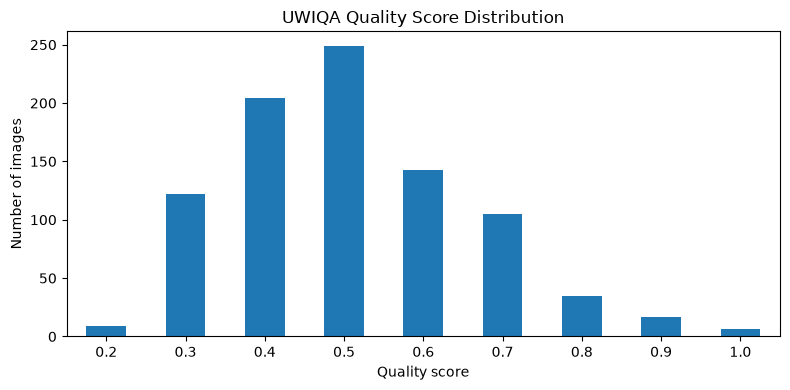

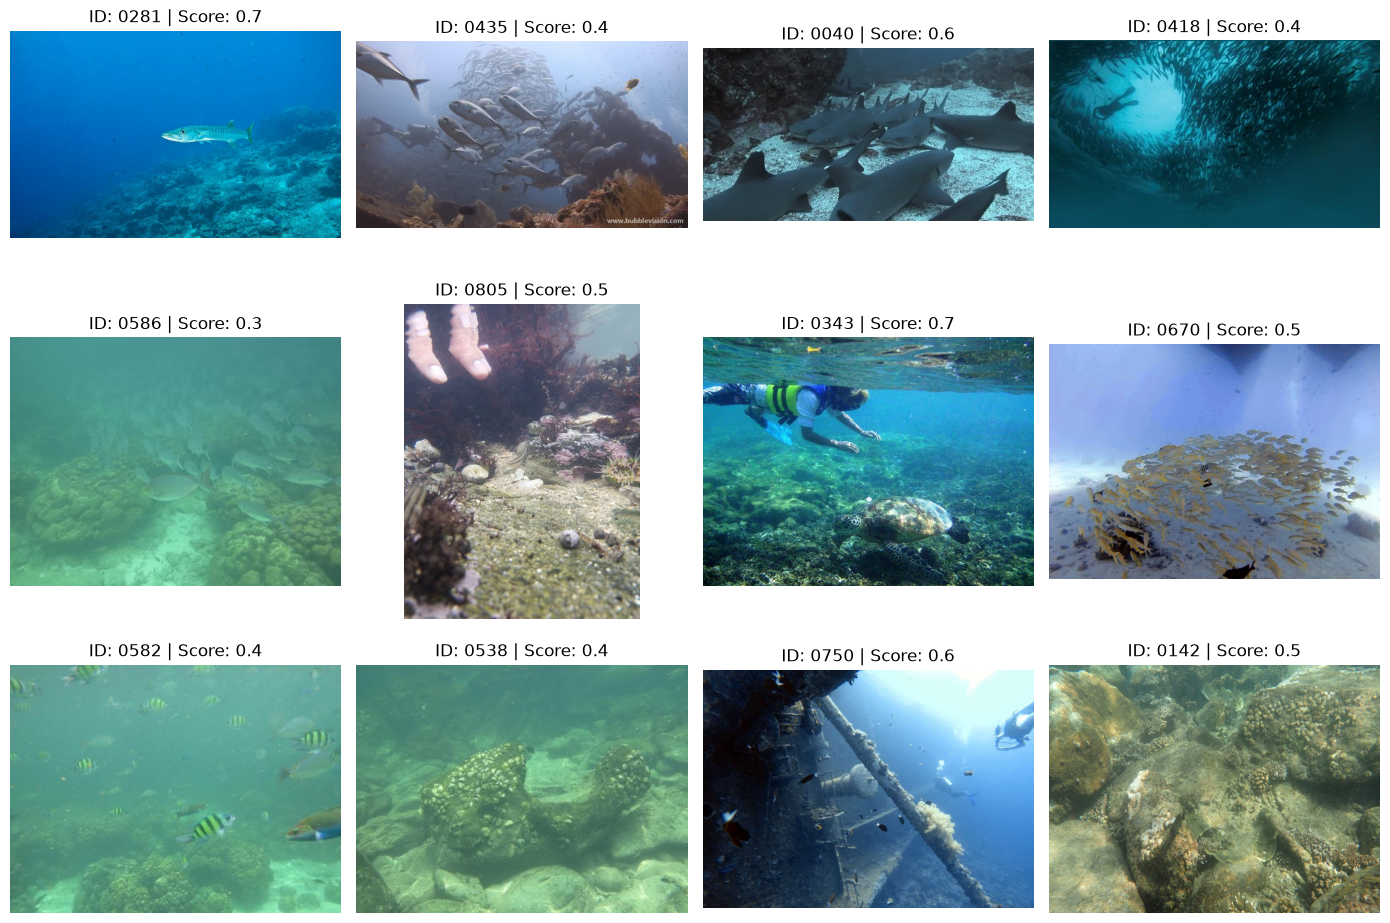

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

dataset_dir = Path("/home/karthikbaskar2/UWIQA Dataset/UWIQA")
excel_path = Path("/home/karthikbaskar2/UWIQA Dataset/IQA Value.xlsx")

df = pd.read_excel(excel_path)

# Plot score distribution
plt.figure(figsize=(8, 4))
df["score"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Quality score")
plt.ylabel("Number of images")
plt.title("UWIQA Quality Score Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Display a reproducible sample
sample = df.sample(n=12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image_id = int(row["image"])
    image_path = dataset_dir / f"{image_id:04d}.png"

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f"ID: {image_id:04d} | Score: {row['score']:.1f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import importlib.util
import torch
import pandas as pd
import sklearn
from PIL import Image

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("Pillow:", Image.__version__ if hasattr(Image, "__version__") else "Installed")

PyTorch: 2.14.0+cu132
GPU available: True
scikit-learn: 1.9.1
pandas: 3.0.6
Pillow: 12.3.0


In [7]:
from pathlib import Path

# Dedicated project directory on the shared server
PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"

# Create the project folders
for folder in [
    "splits",
    "results",
    "checkpoints",
    "logs",
]:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("\nCreated project structure:")

for path in sorted(PROJECT_DIR.rglob("*")):
    print(path.relative_to(PROJECT_DIR))

Project folder: /home/karthikbaskar2/UWIQA_Research_Experiments

Created project structure:
checkpoints
checkpoints/m0_rep01_best.pt
checkpoints/m1_rep01_best.pt
checkpoints/m2_rep01_best.pt
checkpoints/m3_rep01_best.pt
checkpoints/m4_rep01_best.pt
checkpoints/m5_rep01_best.pt
logs
results
results/comparison_rep01_M0_M5.csv
results/comparison_rep01_M0_M5_corrected.csv
results/m0_rep01_history.csv
results/m0_rep01_test_metrics.csv
results/m0_rep01_test_predictions.csv
results/m1_rep01_history.csv
results/m1_rep01_test_metrics.csv
results/m1_rep01_test_predictions.csv
results/m2_rep01_history.csv
results/m2_rep01_test_metrics.csv
results/m2_rep01_test_predictions.csv
results/m3_rep01_history.csv
results/m3_rep01_test_metrics.csv
results/m3_rep01_test_predictions.csv
results/m4_rep01_history.csv
results/m4_rep01_test_metrics.csv
results/m4_rep01_test_predictions.csv
results/m5_rep01_history.csv
results/m5_rep01_test_metrics.csv
results/m5_rep01_test_predictions.csv
results/plots
results/p

In [8]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# Paths
HOME = Path.home()
DATASET_DIR = HOME / "UWIQA Dataset" / "UWIQA"
LABELS_PATH = HOME / "UWIQA Dataset" / "IQA Value.xlsx"
PROJECT_DIR = HOME / "UWIQA_Research_Experiments"
SPLITS_DIR = PROJECT_DIR / "splits"

SPLITS_DIR.mkdir(parents=True, exist_ok=True)

# Load labels
df = pd.read_excel(LABELS_PATH)
df["image"] = df["image"].astype(int)
df["score"] = df["score"].astype(float)
df["filename"] = df["image"].map(lambda x: f"{x:04d}.png")

# Confirm image files exist
df["image_exists"] = df["filename"].map(
    lambda name: (DATASET_DIR / name).is_file()
)
assert df["image_exists"].all(), "Some image files are missing!"
assert not df["image"].duplicated().any(), "Duplicate image IDs found!"
assert df["score"].notna().all(), "Missing scores found!"

# Ten reproducible 80/20 repetitions
N_REPETITIONS = 10
BASE_SEED = 2026
all_splits = []

for repetition in range(1, N_REPETITIONS + 1):
    seed = BASE_SEED + repetition

    # Outer split: 80% development, 20% test
    development, test = train_test_split(
        df,
        test_size=0.20,
        random_state=seed,
        stratify=df["score"]
    )

    # Inner split: 90% training, 10% validation of development data
    train, validation = train_test_split(
        development,
        test_size=0.10,
        random_state=seed + 1000,
        stratify=development["score"]
    )

    train = train.copy()
    validation = validation.copy()
    test = test.copy()

    train["split"] = "train"
    validation["split"] = "validation"
    test["split"] = "test"

    run_df = pd.concat(
        [train, validation, test],
        ignore_index=True
    )

    run_df["repetition"] = repetition
    run_df["seed"] = seed
    run_df = run_df[
        ["image", "filename", "score", "split", "repetition", "seed"]
    ].sort_values("image")

    # Save each repetition separately
    run_df.to_csv(
        SPLITS_DIR / f"uwiqa_split_{repetition:02d}.csv",
        index=False
    )

    all_splits.append(run_df)

# Save combined file
combined = pd.concat(all_splits, ignore_index=True)
combined.to_csv(SPLITS_DIR / "uwiqa_all_splits.csv", index=False)

print("Saved split files to:", SPLITS_DIR)
print("\nCounts for each repetition:")

for repetition in range(1, N_REPETITIONS + 1):
    part = combined[combined["repetition"] == repetition]
    print(
        f"Run {repetition:02d}:",
        part["split"].value_counts().to_dict()
    )

print("\nCombined CSV rows:", len(combined))
print("Files created:", len(list(SPLITS_DIR.glob("*.csv"))))

Saved split files to: /home/karthikbaskar2/UWIQA_Research_Experiments/splits

Counts for each repetition:
Run 01: {'train': 640, 'test': 178, 'validation': 72}
Run 02: {'train': 640, 'test': 178, 'validation': 72}
Run 03: {'train': 640, 'test': 178, 'validation': 72}
Run 04: {'train': 640, 'test': 178, 'validation': 72}
Run 05: {'train': 640, 'test': 178, 'validation': 72}
Run 06: {'train': 640, 'test': 178, 'validation': 72}
Run 07: {'train': 640, 'test': 178, 'validation': 72}
Run 08: {'train': 640, 'test': 178, 'validation': 72}
Run 09: {'train': 640, 'test': 178, 'validation': 72}
Run 10: {'train': 640, 'test': 178, 'validation': 72}

Combined CSV rows: 8900
Files created: 11


In [9]:
import pandas as pd
from pathlib import Path

split_dir = (
    Path.home()
    / "UWIQA_Research_Experiments"
    / "splits"
)

all_splits = pd.read_csv(split_dir / "uwiqa_all_splits.csv")

for run in sorted(all_splits["repetition"].unique()):
    part = all_splits[all_splits["repetition"] == run]

    assert len(part) == 890, f"Run {run}: incorrect row count"
    assert part["image"].nunique() == 890, f"Run {run}: duplicate IDs"
    assert part["split"].notna().all(), f"Run {run}: missing split"

    # Every image must belong to exactly one split per repetition.
    assignments = part.groupby("image")["split"].nunique()
    assert (assignments == 1).all(), f"Run {run}: conflicting assignments"

    print(f"Run {run:02d}: PASS")

print("\nAll 10 repetitions passed the split-integrity checks.")

Run 01: PASS
Run 02: PASS
Run 03: PASS
Run 04: PASS
Run 05: PASS
Run 06: PASS
Run 07: PASS
Run 08: PASS
Run 09: PASS
Run 10: PASS

All 10 repetitions passed the split-integrity checks.


In [10]:
from pathlib import Path
from collections import Counter
from PIL import Image

DATASET_DIR = (
    Path.home() / "UWIQA Dataset" / "UWIQA"
)

image_files = sorted(DATASET_DIR.glob("*.png"))

dimensions = Counter()
modes = Counter()
corrupted = []

for path in image_files:
    try:
        with Image.open(path) as img:
            img.verify()

        # Reopen after verify to read metadata
        with Image.open(path) as img:
            dimensions[img.size] += 1
            modes[img.mode] += 1

    except Exception as exc:
        corrupted.append((path.name, str(exc)))

print("Total PNG files:", len(image_files))
print("\nImage dimensions (width, height):")
for size, count in dimensions.most_common():
    print(f"{size}: {count}")

print("\nImage color modes:")
print(modes)

print("\nUnreadable/corrupted images:", len(corrupted))
for item in corrupted[:10]:
    print(item)

Total PNG files: 890

Image dimensions (width, height):
(640, 480): 163
(1280, 720): 105
(500, 375): 62
(500, 333): 40
(1800, 1295): 23
(1800, 1350): 16
(275, 183): 13
(828, 415): 13
(640, 360): 12
(828, 621): 12
(259, 194): 11
(1024, 768): 11
(300, 168): 10
(1000, 700): 9
(690, 517): 8
(1200, 750): 7
(1024, 718): 7
(1800, 963): 7
(1200, 850): 6
(1280, 803): 5
(600, 450): 5
(1440, 1080): 5
(828, 571): 5
(1536, 814): 5
(1280, 910): 5
(1200, 747): 4
(1280, 670): 4
(850, 564): 4
(1280, 960): 4
(1600, 1200): 4
(1800, 1300): 4
(1280, 853): 3
(600, 400): 3
(1024, 682): 3
(318, 159): 3
(1280, 801): 3
(270, 187): 3
(736, 552): 3
(550, 366): 3
(690, 459): 3
(1632, 1169): 3
(720, 540): 3
(1000, 512): 3
(1000, 750): 2
(800, 1150): 2
(276, 183): 2
(287, 176): 2
(266, 190): 2
(267, 189): 2
(1200, 753): 2
(960, 720): 2
(640, 427): 2
(600, 366): 2
(500, 335): 2
(1920, 1080): 2
(690, 408): 2
(690, 467): 2
(852, 480): 2
(1080, 1440): 2
(1040, 966): 2
(1800, 1013): 2
(1037, 778): 2
(800, 450): 1
(550, 3

In [11]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0))

try:
    from torchvision.models import resnet50, ResNet50_Weights

    model = resnet50(weights=None)
    print("\nResNet-50 architecture loaded successfully.")

    weights_path = (
        torch.hub.get_dir()
        + "/checkpoints/"
    )

    from pathlib import Path
    cached_weights = list(Path(weights_path).glob("*resnet50*"))

    print("\nCached ResNet-50 weight files:")
    if cached_weights:
        for path in cached_weights:
            print(path.name)
    else:
        print("No matching cached weights found.")

except Exception as exc:
    print("\nResNet-50 check failed:", repr(exc))

PyTorch: 2.14.0+cu132
Torchvision: 0.29.0+cu132
GPU: NVIDIA A40

ResNet-50 architecture loaded successfully.

Cached ResNet-50 weight files:
resnet50-11ad3fa6.pth
resnet50-0676ba61.pth


In [12]:
from pathlib import Path
from torchvision.models import ResNet50_Weights

checkpoint_dir = Path(torch.hub.get_dir()) / "checkpoints"

for weights in ResNet50_Weights:
    filename = Path(weights.url).name
    checkpoint = checkpoint_dir / filename

    print(f"\nWeights: {weights.name}")
    print("Expected file:", filename)
    print("Cached:", checkpoint.exists())

    if checkpoint.exists():
        print("Size (MB):", round(checkpoint.stat().st_size / (1024**2), 2))


Weights: IMAGENET1K_V1
Expected file: resnet50-0676ba61.pth
Cached: True
Size (MB): 97.78

Weights: IMAGENET1K_V2
Expected file: resnet50-11ad3fa6.pth
Cached: True
Size (MB): 97.79


In [13]:
from PIL import Image
from torchvision import transforms

DATASET_DIR = Path.home() / "UWIQA Dataset" / "UWIQA"

preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

sample_path = DATASET_DIR / "0001.png"

with Image.open(sample_path) as img:
    tensor = preprocess(img.convert("RGB"))

print("Sample:", sample_path.name)
print("Tensor shape:", tuple(tensor.shape))
print("Tensor dtype:", tensor.dtype)
print("All values finite:", bool(torch.isfinite(tensor).all()))

Sample: 0001.png
Tensor shape: (3, 224, 224)
Tensor dtype: torch.float32
All values finite: True


In [14]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Paths
DATASET_DIR = Path.home() / "UWIQA Dataset" / "UWIQA"
PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
SPLIT_DIR = PROJECT_DIR / "splits"

# Fixed preprocessing for the initial baseline
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class UWIQADataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.image_dir / row["filename"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        score = torch.tensor(
            float(row["score"]),
            dtype=torch.float32
        )

        return image, score, row["filename"]

In [15]:
split_df = pd.read_csv(SPLIT_DIR / "uwiqa_split_01.csv")

train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "validation"].copy()
test_df  = split_df[split_df["split"] == "test"].copy()

train_dataset = UWIQADataset(
    train_df, DATASET_DIR, preprocess
)

val_dataset = UWIQADataset(
    val_df, DATASET_DIR, preprocess
)

test_dataset = UWIQADataset(
    test_df, DATASET_DIR, preprocess
)

train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=8, shuffle=False, num_workers=0
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

images, scores, filenames = next(iter(train_loader))

print("\nBatch image shape:", tuple(images.shape))
print("Batch score shape:", tuple(scores.shape))
print("First filenames:", list(filenames[:4]))
print("First scores:", scores[:4].tolist())
print("Image tensors finite:", bool(torch.isfinite(images).all()))
print("Score tensors finite:", bool(torch.isfinite(scores).all()))

Train images: 640
Validation images: 72
Test images: 178

Batch image shape: (8, 3, 224, 224)
Batch score shape: (8,)
First filenames: ['0172.png', '0490.png', '0563.png', '0631.png']
First scores: [0.6000000238418579, 0.4000000059604645, 0.699999988079071, 0.5]
Image tensors finite: True
Score tensors finite: True


In [16]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the official ImageNet V1 pretrained model
backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

# Replace the 1000-class ImageNet classifier with an IQA regressor
backbone.fc = nn.Sequential(
    nn.Linear(2048, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(512, 1)
)

model = backbone.to(DEVICE)

print("Model: M0 - Global ResNet-50")
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Output dimension:", model.fc[-1].out_features)
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

# Check output shape with a small synthetic batch
model.eval()
with torch.no_grad():
    dummy_input = torch.randn(2, 3, 224, 224, device=DEVICE)
    dummy_output = model(dummy_input)

print("Output shape:", tuple(dummy_output.shape))
assert dummy_output.shape == (2, 1)
print("Model construction check: PASS")

Model: M0 - Global ResNet-50
Device: cuda
GPU: NVIDIA A40
Output dimension: 1
Total parameters: 24557633
Trainable parameters: 24557633
Output shape: (2, 1)
Model construction check: PASS


In [17]:
import random
import numpy as np
import torch
from pathlib import Path

SEED = 2027  # Repetition 01: split seed 2027

PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
LOG_DIR = PROJECT_DIR / "logs"

for folder in [CHECKPOINT_DIR, RESULTS_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Seed:", SEED)
print("Checkpoint folder:", CHECKPOINT_DIR)
print("Results folder:", RESULTS_DIR)
print("Log folder:", LOG_DIR)
print("Reproducibility setup: PASS")

Seed: 2027
Checkpoint folder: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints
Results folder: /home/karthikbaskar2/UWIQA_Research_Experiments/results
Log folder: /home/karthikbaskar2/UWIQA_Research_Experiments/logs
Reproducibility setup: PASS


In [18]:
import pandas as pd

split_df = pd.read_csv(SPLIT_DIR / "uwiqa_split_01.csv")

print("Training score range:",
      train_df["score"].min(), "to", train_df["score"].max())

print("Training score mean:",
      round(train_df["score"].mean(), 4))

print("Training score standard deviation:",
      round(train_df["score"].std(), 4))

print("\nScore counts in the training split:")
print(train_df["score"].value_counts().sort_index())

Training score range: 0.2 to 1.0
Training score mean: 0.5094
Training score standard deviation: 0.1525

Score counts in the training split:
score
0.2      6
0.3     88
0.4    147
0.5    179
0.6    102
0.7     76
0.8     25
0.9     13
1.0      4
Name: count, dtype: int64


In [19]:
import time
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Reproducibility
torch.manual_seed(2027)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(2027)

# Training configuration
MAX_EPOCHS = 50
PATIENCE = 8
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

criterion = nn.MSELoss()

optimizer = Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

checkpoint_path = CHECKPOINT_DIR / "m0_rep01_best.pt"
history_path = RESULTS_DIR / "m0_rep01_history.csv"

best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    start_time = time.time()

    # -------------------------
    # Training
    # -------------------------
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:
        images = images.to(DEVICE)
        scores = scores.to(DEVICE).view(-1, 1)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(images)
        loss = criterion(predictions, scores)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_loss = train_loss_sum / train_count

    # -------------------------
    # Validation
    # -------------------------
    model.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for images, scores, _ in val_loader:
            images = images.to(DEVICE)
            scores = scores.to(DEVICE).view(-1, 1)

            predictions = model(images)
            loss = criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_loss = val_loss_sum / val_count

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "best_val_loss": best_val_loss,
            "seed": 2027,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "model_name": "M0_Global_ResNet50",
            "weights": "IMAGENET1K_V1"
        }, checkpoint_path)
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_mse": train_loss,
        "val_mse": val_loss,
        "learning_rate": current_lr,
        "best_checkpoint_updated": improved
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_loss:.5f} | "
        f"Val MSE: {val_loss:.5f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(history_path, index=False)

print("\nTraining finished.")
print("Best validation MSE:", round(best_val_loss, 6))
print("Checkpoint saved:", checkpoint_path)
print("History saved:", history_path)
print("Epochs completed:", len(history_df))

Epoch 01/50 | Train MSE: 0.03296 | Val MSE: 0.01390 | LR: 1.00e-04 | 32.5s | BEST
Epoch 02/50 | Train MSE: 0.01480 | Val MSE: 0.01144 | LR: 1.00e-04 | 31.4s | BEST
Epoch 03/50 | Train MSE: 0.01489 | Val MSE: 0.01061 | LR: 1.00e-04 | 31.1s | BEST
Epoch 04/50 | Train MSE: 0.01064 | Val MSE: 0.01151 | LR: 1.00e-04 | 31.5s
Epoch 05/50 | Train MSE: 0.01016 | Val MSE: 0.00887 | LR: 1.00e-04 | 32.0s | BEST
Epoch 06/50 | Train MSE: 0.00875 | Val MSE: 0.00934 | LR: 1.00e-04 | 31.0s
Epoch 07/50 | Train MSE: 0.01067 | Val MSE: 0.00824 | LR: 1.00e-04 | 30.8s | BEST
Epoch 08/50 | Train MSE: 0.00841 | Val MSE: 0.00795 | LR: 1.00e-04 | 32.2s | BEST
Epoch 09/50 | Train MSE: 0.00942 | Val MSE: 0.01124 | LR: 1.00e-04 | 31.0s
Epoch 10/50 | Train MSE: 0.00833 | Val MSE: 0.01190 | LR: 1.00e-04 | 31.2s
Epoch 11/50 | Train MSE: 0.00743 | Val MSE: 0.00927 | LR: 1.00e-04 | 31.3s
Epoch 12/50 | Train MSE: 0.00696 | Val MSE: 0.01185 | LR: 5.00e-05 | 31.3s
Epoch 13/50 | Train MSE: 0.00640 | Val MSE: 0.00862 | LR: 

In [20]:
import torch
from pathlib import Path

checkpoint_path = (
    Path.home()
    / "UWIQA_Research_Experiments"
    / "checkpoints"
    / "m0_rep01_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint loaded successfully.")
print("Saved best epoch:", checkpoint["epoch"])
print("Saved validation MSE:", checkpoint["best_val_loss"])
print("Model set to evaluation mode:", not model.training)

Checkpoint loaded successfully.
Saved best epoch: 23
Saved validation MSE: 0.006691144637039138
Model set to evaluation mode: True


In [21]:
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Output folders
PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Make sure the best checkpoint is in evaluation mode
model.eval()

all_true = []
all_pred = []
all_filenames = []

# Test evaluation: no gradients, no weight updates
with torch.no_grad():
    for images, scores, filenames in test_loader:
        images = images.to(DEVICE)
        predictions = model(images).reshape(-1).cpu().numpy()

        all_pred.extend(predictions.tolist())
        all_true.extend(scores.numpy().reshape(-1).tolist())
        all_filenames.extend(list(filenames))

y_true = np.asarray(all_true, dtype=np.float64)
y_pred = np.asarray(all_pred, dtype=np.float64)

assert len(y_true) == 178, f"Expected 178 test images, got {len(y_true)}"
assert len(y_true) == len(y_pred) == len(all_filenames)
assert np.isfinite(y_true).all() and np.isfinite(y_pred).all()

# Calculate metrics on RAW predictions
plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic
krcc = kendalltau(y_true, y_pred, variant="b").statistic
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)

metrics = {
    "dataset": "UWIQA",
    "model": "M0_Global_ResNet50",
    "repetition": 1,
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_images": len(y_true),
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MAE": mae,
    "MSE": mse,
}

print("=" * 48)
print("M0 — UWIQA TEST RESULTS (REPETITION 01)")
print("=" * 48)

for name in ["PLCC", "SRCC", "KRCC", "RMSE", "MAE", "MSE"]:
    print(f"{name:8s}: {metrics[name]:.6f}")

# Save individual predictions for later analysis
predictions_df = pd.DataFrame({
    "filename": all_filenames,
    "reference_score": y_true,
    "predicted_score": y_pred,
    "residual": y_pred - y_true,
})

predictions_path = RESULTS_DIR / "m0_rep01_test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

metrics_path = RESULTS_DIR / "m0_rep01_test_metrics.csv"
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)

print("\nPredictions saved:", predictions_path)
print("Metrics saved:", metrics_path)

M0 — UWIQA TEST RESULTS (REPETITION 01)
PLCC    : 0.826119
SRCC    : 0.809558
KRCC    : 0.665800
RMSE    : 0.085567
MAE     : 0.066652
MSE     : 0.007322

Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep01_test_predictions.csv
Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep01_test_metrics.csv


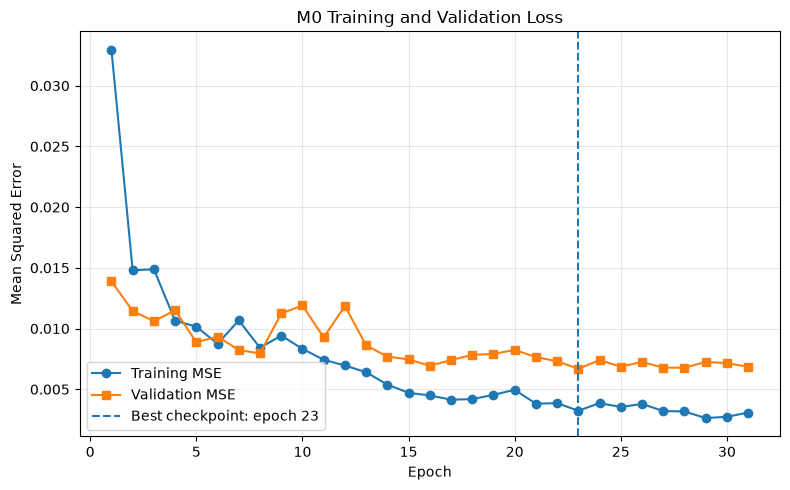

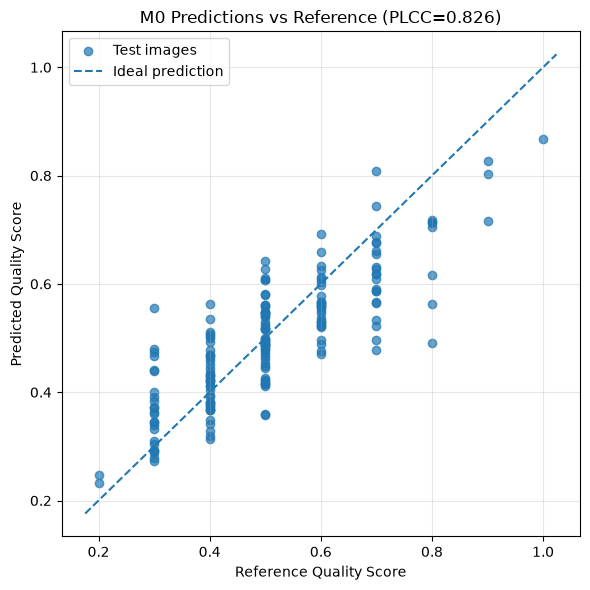

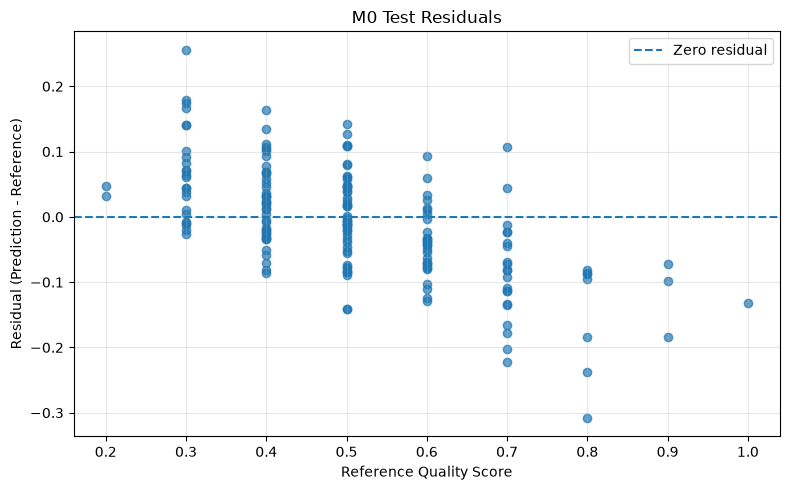

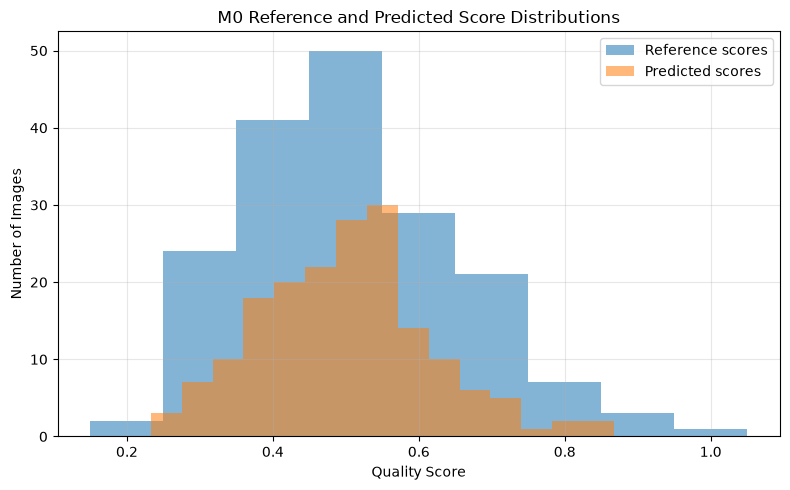

All plots saved in: /home/karthikbaskar2/UWIQA_Research_Experiments/results/plots


In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load the saved training history
history_path = RESULTS_DIR / "m0_rep01_history.csv"
history_df = pd.read_csv(history_path)

# --------------------------------------------------
# Plot 1: Training and validation loss
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_mse"],
    marker="o",
    label="Training MSE"
)
plt.plot(
    history_df["epoch"],
    history_df["val_mse"],
    marker="s",
    label="Validation MSE"
)

best_epoch = int(checkpoint["epoch"])
best_val = float(checkpoint["best_val_loss"])

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best checkpoint: epoch {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("M0 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "m0_rep01_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Plot 2: Predicted vs reference scores
# --------------------------------------------------
plt.figure(figsize=(6, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.7,
    label="Test images"
)

lower = min(y_true.min(), y_pred.min())
upper = max(y_true.max(), y_pred.max())
padding = 0.03 * (upper - lower) if upper > lower else 0.01

line_min = lower - padding
line_max = upper + padding

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--",
    label="Ideal prediction"
)

plt.xlabel("Reference Quality Score")
plt.ylabel("Predicted Quality Score")
plt.title(f"M0 Predictions vs Reference (PLCC={plcc:.3f})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "m0_rep01_prediction_scatter.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Plot 3: Residual plot
# Residual = prediction - reference
# --------------------------------------------------
residuals = y_pred - y_true

plt.figure(figsize=(8, 5))

plt.scatter(
    y_true,
    residuals,
    alpha=0.7
)

plt.axhline(0, linestyle="--", label="Zero residual")

plt.xlabel("Reference Quality Score")
plt.ylabel("Residual (Prediction - Reference)")
plt.title("M0 Test Residuals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "m0_rep01_residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Plot 4: Reference vs predicted score distributions
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.hist(
    y_true,
    bins=np.arange(0.15, 1.06, 0.1),
    alpha=0.55,
    label="Reference scores"
)

plt.hist(
    y_pred,
    bins=15,
    alpha=0.55,
    label="Predicted scores"
)

plt.xlabel("Quality Score")
plt.ylabel("Number of Images")
plt.title("M0 Reference and Predicted Score Distributions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "m0_rep01_score_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("All plots saved in:", PLOTS_DIR)

Number of test images: 178
Reference mean: 0.5079
Predicted mean: 0.4987
Reference std:  0.1504
Predicted std:  0.1172
Reference range: 0.200 to 1.000
Predicted range: 0.233 to 0.867


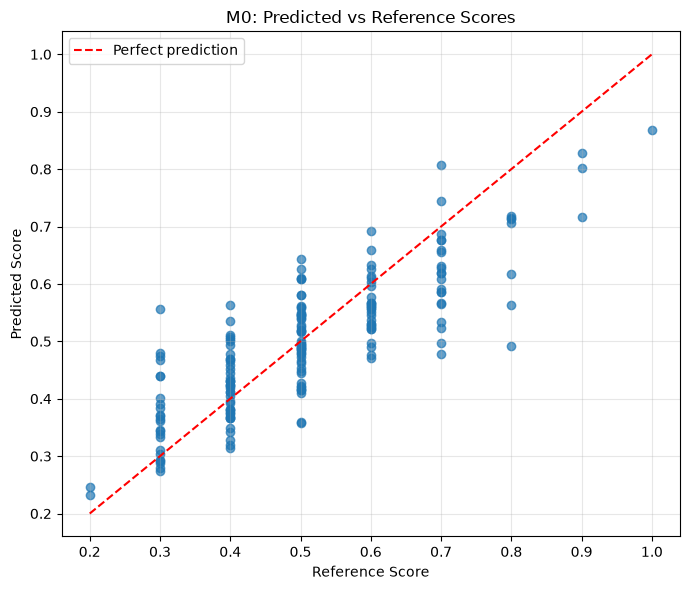

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pred_path = (
    "/home/karthikbaskar2/"
    "UWIQA_Research_Experiments/results/"
    "m0_rep01_test_predictions.csv"
)

df = pd.read_csv(pred_path)

y_true = df["reference_score"].to_numpy()
y_pred = df["predicted_score"].to_numpy()

print("Number of test images:", len(df))
print(f"Reference mean: {y_true.mean():.4f}")
print(f"Predicted mean: {y_pred.mean():.4f}")
print(f"Reference std:  {y_true.std():.4f}")
print(f"Predicted std:  {y_pred.std():.4f}")
print(f"Reference range: {y_true.min():.3f} to {y_true.max():.3f}")
print(f"Predicted range: {y_pred.min():.3f} to {y_pred.max():.3f}")

# Scatter plot
plt.figure(figsize=(7, 6))
plt.scatter(y_true, y_pred, alpha=0.7)

low = min(y_true.min(), y_pred.min())
high = max(y_true.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Reference Score")
plt.ylabel("Predicted Score")
plt.title("M0: Predicted vs Reference Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "/home/karthikbaskar2/"
    "UWIQA_Research_Experiments/results/"
    "m0_rep01_test_predictions.csv"
)

df["absolute_error"] = (
    df["predicted_score"] - df["reference_score"]
).abs()

df["residual"] = (
    df["predicted_score"] - df["reference_score"]
)

summary = (
    df.groupby("reference_score")
      .agg(
          image_count=("predicted_score", "size"),
          mean_prediction=("predicted_score", "mean"),
          mean_absolute_error=("absolute_error", "mean"),
          mean_residual=("residual", "mean")
      )
      .reset_index()
)

print(summary.round(4).to_string(index=False))

 reference_score  image_count  mean_prediction  mean_absolute_error  mean_residual
             0.2            2           0.2399               0.0399         0.0399
             0.3           24           0.3707               0.0770         0.0707
             0.4           41           0.4221               0.0511         0.0221
             0.5           50           0.5029               0.0522         0.0029
             0.6           29           0.5610               0.0553        -0.0390
             0.7           21           0.6162               0.0983        -0.0838
             0.8            7           0.6461               0.1539        -0.1539
             0.9            3           0.7821               0.1179        -0.1179
             1.0            1           0.8675               0.1325        -0.1325


In [25]:
import torch
import torch.nn as nn
import torchvision
from torchvision.models import resnet50, ResNet50_Weights

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))

PyTorch: 2.14.0+cu132
Torchvision: 0.29.0+cu132
GPU available: True
Device: NVIDIA A40
Training images: 640
Validation images: 72
Test images: 178


In [26]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights


class M1PatchAverageResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Shared ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        # Remove the original classification layer
        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # Predict one quality score from averaged patch features
        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, images):
        # images shape: (batch, 3, 224, 224)
        batch_size = images.size(0)

        # Divide each image into four 112 × 112 patches
        top_left = images[:, :, :112, :112]
        top_right = images[:, :, :112, 112:]
        bottom_left = images[:, :, 112:, :112]
        bottom_right = images[:, :, 112:, 112:]

        # Combine patches along the batch dimension
        patches = torch.cat(
            [top_left, top_right, bottom_left, bottom_right],
            dim=0
        )

        # Extract 2048-dimensional features for each patch
        patch_features = self.feature_extractor(patches)
        patch_features = patch_features.flatten(1)

        # Restore the original batch and patch dimensions
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Average the four patch feature vectors
        image_features = patch_features.mean(dim=1)

        # Predict one score per original image
        predictions = self.regressor(image_features)

        return predictions.squeeze(1)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

m1_model = M1PatchAverageResNet().to(DEVICE)

print("M1 model created successfully!")
print("Device:", DEVICE)
print(
    "Trainable parameters:",
    sum(p.numel() for p in m1_model.parameters()
        if p.requires_grad)
)

M1 model created successfully!
Device: cuda
Trainable parameters: 24557633


In [27]:
m1_model.eval()

with torch.no_grad():
    sample_images, sample_scores, sample_names = next(iter(train_loader))
    sample_images = sample_images.to(DEVICE)

    sample_predictions = m1_model(sample_images)

print("Input shape:", sample_images.shape)
print("Prediction shape:", sample_predictions.shape)
print("Sample predictions:", sample_predictions[:5].cpu())
print("All predictions finite:", torch.isfinite(sample_predictions).all().item())

Input shape: torch.Size([8, 3, 224, 224])
Prediction shape: torch.Size([8])
Sample predictions: tensor([-0.0419, -0.1434,  0.0200,  0.2238,  0.1705])
All predictions finite: True


In [28]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Reproducibility for M1, repetition 01
SEED = 2027

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Training configuration
MAX_EPOCHS = 50
PATIENCE = 8

BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

# Separate learning rates for the pretrained backbone and new head
optimizer = Adam(
    [
        {
            "params": m1_model.feature_extractor.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": m1_model.regressor.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

criterion = nn.MSELoss()

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# Save M1 separately from M0
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

M1_CHECKPOINT_PATH = CHECKPOINT_DIR / "m1_rep01_best.pt"
M1_HISTORY_PATH = RESULTS_DIR / "m1_rep01_history.csv"

print("M1 training configuration ready.")
print("Checkpoint:", M1_CHECKPOINT_PATH)
print("History:", M1_HISTORY_PATH)
print("Loss function: MSE")
print("Backbone learning rate:", BACKBONE_LR)
print("Head learning rate:", HEAD_LR)

M1 training configuration ready.
Checkpoint: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints/m1_rep01_best.pt
History: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep01_history.csv
Loss function: MSE
Backbone learning rate: 0.0001
Head learning rate: 0.0003


In [29]:
import time
import pandas as pd
import torch

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    start_time = time.time()

    # -------------------------
    # Training
    # -------------------------
    m1_model.train()
    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:
        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float()

        optimizer.zero_grad(set_to_none=True)

        predictions = m1_model(images)
        loss = criterion(predictions, scores)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_loss = train_loss_sum / train_count

    # -------------------------
    # Validation
    # -------------------------
    m1_model.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for images, scores, _ in val_loader:
            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float()

            predictions = m1_model(images)
            loss = criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_loss = val_loss_sum / val_count

    # Adjust learning rate based on validation loss
    scheduler.step(val_loss)

    current_lr_backbone = optimizer.param_groups[0]["lr"]
    current_lr_head = optimizer.param_groups[1]["lr"]

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": m1_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "seed": SEED,
            },
            M1_CHECKPOINT_PATH
        )
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_mse": train_loss,
        "val_mse": val_loss,
        "lr_backbone": current_lr_backbone,
        "lr_head": current_lr_head,
        "best_so_far": improved,
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_loss:.6f} | "
        f"Val MSE: {val_loss:.6f} | "
        f"Backbone LR: {current_lr_backbone:.2e} | "
        f"Head LR: {current_lr_head:.2e} | "
        f"{'BEST' if improved else ''} | "
        f"{elapsed:.1f}s"
    )

    # Save training history after every epoch
    pd.DataFrame(history).to_csv(M1_HISTORY_PATH, index=False)

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

print("\nM1 training finished.")
print("Best epoch:", best_epoch)
print(f"Best validation MSE: {best_val_loss:.6f}")
print("Checkpoint saved:", M1_CHECKPOINT_PATH)
print("History saved:", M1_HISTORY_PATH)

Epoch 01/50 | Train MSE: 0.050432 | Val MSE: 0.011633 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 32.4s
Epoch 02/50 | Train MSE: 0.015846 | Val MSE: 0.008943 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 31.6s
Epoch 03/50 | Train MSE: 0.015393 | Val MSE: 0.014995 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 31.4s
Epoch 04/50 | Train MSE: 0.011857 | Val MSE: 0.009610 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 31.5s
Epoch 05/50 | Train MSE: 0.012104 | Val MSE: 0.006866 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 32.2s
Epoch 06/50 | Train MSE: 0.010969 | Val MSE: 0.006939 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 32.1s
Epoch 07/50 | Train MSE: 0.012736 | Val MSE: 0.010539 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 31.8s
Epoch 08/50 | Train MSE: 0.010813 | Val MSE: 0.009971 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 32.1s
Epoch 09/50 | Train MSE: 0.011182 | Val MSE: 0.007285 | Backbone LR: 5.00e-05 | Head LR: 1.50e-04 |  | 31.0s
Epoch 1

In [30]:
import torch

checkpoint = torch.load(
    M1_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m1_model.load_state_dict(checkpoint["model_state_dict"])
m1_model.eval()

print("Best checkpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation MSE:", checkpoint["best_val_loss"])
print("Model in evaluation mode:", not m1_model.training)

Best checkpoint loaded successfully.
Best epoch: 5
Best validation MSE: 0.006866284956534703
Model in evaluation mode: True


In [31]:
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error, mean_absolute_error

m1_model.eval()

y_true = []
y_pred = []
filenames = []

with torch.no_grad():
    for images, scores, names in test_loader:
        images = images.to(DEVICE)
        predictions = m1_model(images)

        y_true.extend(scores.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        filenames.extend(names)

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

assert len(y_true) == 178
assert len(y_pred) == 178
assert np.isfinite(y_true).all()
assert np.isfinite(y_pred).all()

# Calculate evaluation metrics
plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic
krcc = kendalltau(y_true, y_pred, variant="b").statistic

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)

metrics = {
    "model": "M1",
    "repetition": 1,
    "test_images": len(y_true),
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MAE": mae,
    "MSE": mse,
}

print("=" * 44)
print("M1 — UWIQA TEST RESULTS (REPETITION 01)")
print("=" * 44)

for key in ["PLCC", "SRCC", "KRCC", "RMSE", "MAE", "MSE"]:
    print(f"{key:8s}: {metrics[key]:.6f}")

# Save predictions and metrics separately from M0
predictions_df = pd.DataFrame({
    "filename": filenames,
    "reference_score": y_true,
    "predicted_score": y_pred,
    "residual": y_pred - y_true,
})

pred_path = RESULTS_DIR / "m1_rep01_test_predictions.csv"
metrics_path = RESULTS_DIR / "m1_rep01_test_metrics.csv"

predictions_df.to_csv(pred_path, index=False)
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)

print("\nPredictions saved:", pred_path)
print("Metrics saved:", metrics_path)

M1 — UWIQA TEST RESULTS (REPETITION 01)
PLCC    : 0.775457
SRCC    : 0.748743
KRCC    : 0.601411
RMSE    : 0.099985
MAE     : 0.076008
MSE     : 0.009997

Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep01_test_predictions.csv
Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep01_test_metrics.csv


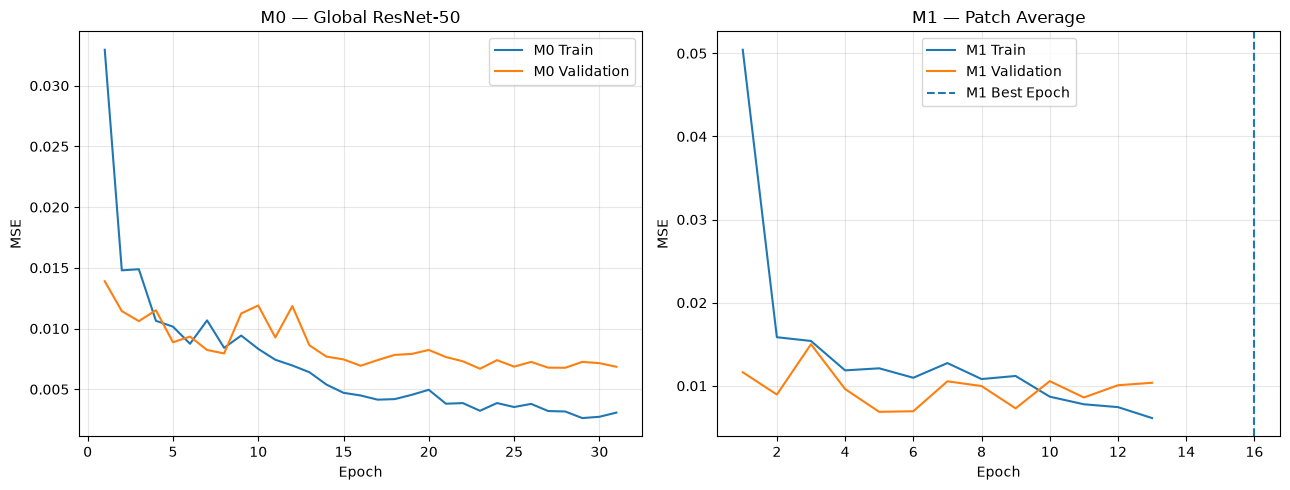

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

m0_history_path = RESULTS_DIR / "m0_rep01_history.csv"
m1_history_path = RESULTS_DIR / "m1_rep01_history.csv"

m0_history = pd.read_csv(m0_history_path)
m1_history = pd.read_csv(m1_history_path)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    m0_history["epoch"], m0_history["train_mse"],
    label="M0 Train"
)
axes[0].plot(
    m0_history["epoch"], m0_history["val_mse"],
    label="M0 Validation"
)
axes[0].set_title("M0 — Global ResNet-50")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    m1_history["epoch"], m1_history["train_mse"],
    label="M1 Train"
)
axes[1].plot(
    m1_history["epoch"], m1_history["val_mse"],
    label="M1 Validation"
)
axes[1].axvline(
    16, linestyle="--",
    label="M1 Best Epoch"
)
axes[1].set_title("M1 — Patch Average")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
import pandas as pd

m0_metrics = pd.read_csv(
    RESULTS_DIR / "m0_rep01_test_metrics.csv"
)

m1_metrics = pd.read_csv(
    RESULTS_DIR / "m1_rep01_test_metrics.csv"
)

print("M0 — Global ResNet-50")
display(m0_metrics)

print("M1 — Patch Average")
display(m1_metrics)

M0 — Global ResNet-50


,dataset,model,repetition,checkpoint_epoch,test_images,PLCC,SRCC,KRCC,RMSE,MAE,MSE
0,UWIQA,M0_Global_ResNet50,1,23,178,0.826119,0.809558,0.6658,0.085567,0.066652,0.007322


M1 — Patch Average


,model,repetition,test_images,PLCC,SRCC,KRCC,RMSE,MAE,MSE
0,M1,1,178,0.775457,0.748743,0.601411,0.099985,0.076008,0.009997


In [34]:
from pathlib import Path

PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
RESULTS_DIR = PROJECT_DIR / "results"

In [35]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights


class M2PatchAttentionResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # 1. Pretrained ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # 2. Learn an attention score for each patch
        self.attention = nn.Sequential(
            nn.Linear(2048, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )

        # 3. Predict overall image quality
        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, images):
        batch_size = images.size(0)

        # Divide each 224x224 image into four 112x112 patches
        top_left = images[:, :, :112, :112]
        top_right = images[:, :, :112, 112:]
        bottom_left = images[:, :, 112:, :112]
        bottom_right = images[:, :, 112:, 112:]

        # Combine patches into one batch
        patches = torch.cat(
            [top_left, top_right, bottom_left, bottom_right],
            dim=0
        )

        # Extract a 2048-dimensional feature vector per patch
        patch_features = self.feature_extractor(
            patches
        ).flatten(1)

        # Shape: (batch_size, 4, 2048)
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Calculate attention scores for the four patches
        attention_scores = self.attention(
            patch_features
        ).squeeze(-1)

        # Convert scores into weights that sum to 1
        attention_weights = torch.softmax(
            attention_scores, dim=1
        )

        # Weighted combination of patch features
        image_features = torch.sum(
            patch_features * attention_weights.unsqueeze(-1),
            dim=1
        )

        # Predict one quality score per image
        predictions = self.regressor(
            image_features
        ).squeeze(-1)

        return predictions

In [36]:
m2_model = M2PatchAttentionResNet().to(DEVICE)

m2_model.eval()

with torch.no_grad():
    sample_images, sample_scores, sample_names = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)

    sample_predictions = m2_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", sample_predictions.shape)
print("Predictions:", sample_predictions[:5].cpu())
print("All predictions finite:",
      torch.isfinite(sample_predictions).all().item())

print(
    "Total parameters:",
    sum(p.numel() for p in m2_model.parameters())
)

Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8])
Predictions: tensor([-0.0388,  0.0630, -0.0065,  0.3880,  0.0101])
All predictions finite: True
Total parameters: 25082434


In [37]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Reproducibility
SEED = 2027

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training configuration
MAX_EPOCHS = 50
PATIENCE = 8

BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

# Optimizer
m2_optimizer = Adam(
    [
        {
            "params": m2_model.feature_extractor.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": list(m2_model.attention.parameters())
                      + list(m2_model.regressor.parameters()),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# Regression loss
m2_criterion = nn.MSELoss()

# Reduce learning rate when validation loss stops improving
m2_scheduler = ReduceLROnPlateau(
    m2_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# Save locations
M2_CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints" / "m2_rep01_best.pt"
)

M2_HISTORY_PATH = (
    RESULTS_DIR / "m2_rep01_history.csv"
)

print("M2 training configuration ready.")
print("Device:", DEVICE)
print("Maximum epochs:", MAX_EPOCHS)
print("Backbone learning rate:", BACKBONE_LR)
print("Attention/head learning rate:", HEAD_LR)
print("Checkpoint:", M2_CHECKPOINT_PATH)
print("History:", M2_HISTORY_PATH)

M2 training configuration ready.
Device: cuda
Maximum epochs: 50
Backbone learning rate: 0.0001
Attention/head learning rate: 0.0003
Checkpoint: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints/m2_rep01_best.pt
History: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep01_history.csv


In [38]:
import time
import pandas as pd
import torch

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
m2_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    start_time = time.time()

    # -------- Training --------
    m2_model.train()
    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:
        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float()

        m2_optimizer.zero_grad()

        predictions = m2_model(images)
        loss = m2_criterion(predictions, scores)

        loss.backward()
        m2_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_mse = train_loss_sum / train_count

    # -------- Validation --------
    m2_model.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for images, scores, _ in val_loader:
            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float()

            predictions = m2_model(images)
            loss = m2_criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_mse = val_loss_sum / val_count

    # Reduce LR when validation performance plateaus
    m2_scheduler.step(val_mse)

    current_backbone_lr = m2_optimizer.param_groups[0]["lr"]
    current_head_lr = m2_optimizer.param_groups[1]["lr"]

    improved = val_mse < best_val_loss

    if improved:
        best_val_loss = val_mse
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": m2_model.state_dict(),
                "optimizer_state_dict": m2_optimizer.state_dict(),
                "best_val_mse": best_val_loss,
                "seed": SEED,
            },
            M2_CHECKPOINT_PATH
        )
    else:
        epochs_without_improvement += 1

    m2_history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "lr_backbone": current_backbone_lr,
        "lr_head": current_head_lr,
        "best_so_far": best_val_loss,
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Best Val: {best_val_loss:.6f} "
        f"(Epoch {best_epoch}) | "
        f"Time: {elapsed:.1f}s"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# Save training history
m2_history_df = pd.DataFrame(m2_history)
m2_history_df.to_csv(M2_HISTORY_PATH, index=False)

# Restore the best validation checkpoint
checkpoint = torch.load(
    M2_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)
m2_model.load_state_dict(checkpoint["model_state_dict"])
m2_model.eval()

print("\nM2 training complete.")
print("Best epoch:", best_epoch)
print(f"Best validation MSE: {best_val_loss:.6f}")
print("Checkpoint saved:", M2_CHECKPOINT_PATH)
print("History saved:", M2_HISTORY_PATH)

Epoch 01/50 | Train MSE: 0.064616 | Val MSE: 0.019604 | Best Val: 0.019604 (Epoch 1) | Time: 32.7s
Epoch 02/50 | Train MSE: 0.015692 | Val MSE: 0.011108 | Best Val: 0.011108 (Epoch 2) | Time: 33.0s
Epoch 03/50 | Train MSE: 0.016288 | Val MSE: 0.012268 | Best Val: 0.011108 (Epoch 2) | Time: 32.0s
Epoch 04/50 | Train MSE: 0.010622 | Val MSE: 0.009046 | Best Val: 0.009046 (Epoch 4) | Time: 32.6s
Epoch 05/50 | Train MSE: 0.014183 | Val MSE: 0.012159 | Best Val: 0.009046 (Epoch 4) | Time: 33.1s
Epoch 06/50 | Train MSE: 0.008594 | Val MSE: 0.010579 | Best Val: 0.009046 (Epoch 4) | Time: 33.0s
Epoch 07/50 | Train MSE: 0.009426 | Val MSE: 0.009624 | Best Val: 0.009046 (Epoch 4) | Time: 33.5s
Epoch 08/50 | Train MSE: 0.008695 | Val MSE: 0.009836 | Best Val: 0.009046 (Epoch 4) | Time: 31.7s
Epoch 09/50 | Train MSE: 0.006644 | Val MSE: 0.009542 | Best Val: 0.009046 (Epoch 4) | Time: 31.8s
Epoch 10/50 | Train MSE: 0.007317 | Val MSE: 0.010476 | Best Val: 0.009046 (Epoch 4) | Time: 31.8s
Epoch 11/5

In [39]:
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load the best M2 checkpoint
checkpoint = torch.load(
    M2_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m2_model.load_state_dict(checkpoint["model_state_dict"])
m2_model.eval()

# Predict on the untouched test set
y_true = []
y_pred = []
filenames = []

with torch.no_grad():
    for images, scores, names in test_loader:
        images = images.to(DEVICE)

        predictions = m2_model(images)

        y_true.extend(scores.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        filenames.extend(names)

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

# Calculate evaluation metrics
plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic
krcc = kendalltau(y_true, y_pred).statistic
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)

m2_metrics = pd.DataFrame([{
    "model": "M2",
    "repetition": 1,
    "best_epoch": checkpoint["epoch"],
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MAE": mae,
    "MSE": mse,
    "n_test": len(y_true)
}])

# Save predictions and metrics
m2_predictions = pd.DataFrame({
    "image": filenames,
    "reference_score": y_true,
    "predicted_score": y_pred
})

m2_predictions.to_csv(
    RESULTS_DIR / "m2_rep01_test_predictions.csv",
    index=False
)

m2_metrics.to_csv(
    RESULTS_DIR / "m2_rep01_test_metrics.csv",
    index=False
)

display(m2_metrics.round(6))

print("Saved M2 predictions and metrics.")

,model,repetition,best_epoch,PLCC,SRCC,KRCC,RMSE,MAE,MSE,n_test
0,M2,1,4,0.746514,0.736324,0.588026,0.100534,0.075833,0.010107,178


Saved M2 predictions and metrics.


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
RESULTS_DIR = PROJECT_DIR / "results"

m0_history = pd.read_csv(
    RESULTS_DIR / "m0_rep01_history.csv"
)

m1_history = pd.read_csv(
    RESULTS_DIR / "m1_rep01_history.csv"
)

m2_history = pd.read_csv(
    RESULTS_DIR / "m2_rep01_history.csv"
)

print("M0 columns:", m0_history.columns.tolist())
print("M1 columns:", m1_history.columns.tolist())
print("M2 columns:", m2_history.columns.tolist())

M0 columns: ['epoch', 'train_mse', 'val_mse', 'learning_rate', 'best_checkpoint_updated']
M1 columns: ['epoch', 'train_mse', 'val_mse', 'lr_backbone', 'lr_head', 'best_so_far']
M2 columns: ['epoch', 'train_mse', 'val_mse', 'lr_backbone', 'lr_head', 'best_so_far']


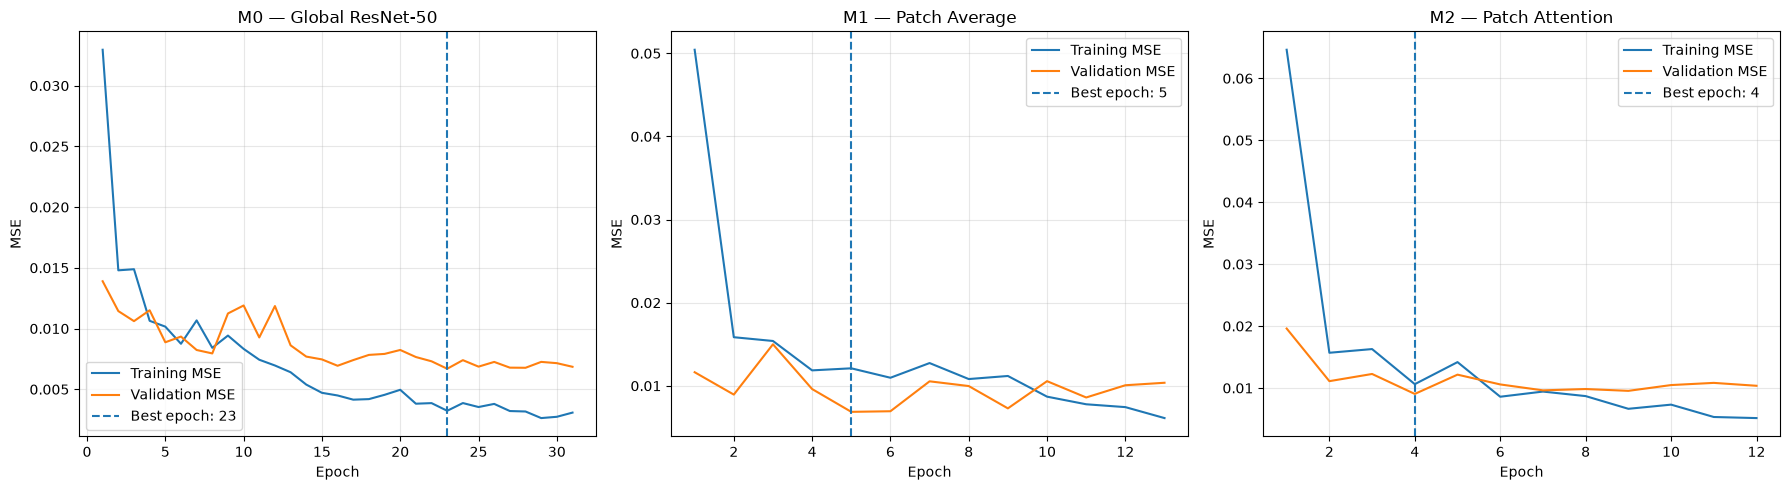

In [41]:
def find_loss_column(df, candidates):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Could not find a loss column. Available columns: "
        f"{df.columns.tolist()}"
    )


histories = {
    "M0 — Global ResNet-50": m0_history,
    "M1 — Patch Average": m1_history,
    "M2 — Patch Attention": m2_history
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, history) in zip(axes, histories.items()):
    train_col = find_loss_column(
        history,
        ["train_mse", "train_loss", "train_loss_mse"]
    )

    val_col = find_loss_column(
        history,
        ["val_mse", "val_loss", "val_loss_mse"]
    )

    ax.plot(
        history["epoch"],
        history[train_col],
        label="Training MSE"
    )

    ax.plot(
        history["epoch"],
        history[val_col],
        label="Validation MSE"
    )

    best_idx = history[val_col].idxmin()
    best_epoch = int(history.loc[best_idx, "epoch"])

    ax.axvline(
        best_epoch,
        linestyle="--",
        label=f"Best epoch: {best_epoch}"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights


class M3SaliencyAwareResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Pretrained ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # Quality regression head
        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

        # ImageNet normalization values
        self.register_buffer(
            "rgb_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "rgb_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, images):
        batch_size = images.size(0)

        # Recover approximate RGB values from normalized inputs
        rgb = images * self.rgb_std + self.rgb_mean
        rgb = rgb.clamp(0, 1)

        # Estimate pixel-level color contrast against
        # the mean color of the entire image
        global_color_mean = rgb.mean(
            dim=(2, 3), keepdim=True
        )

        saliency_map = torch.sqrt(
            ((rgb - global_color_mean) ** 2).mean(
                dim=1, keepdim=True
            ) + 1e-8
        )

        # Split image and saliency map into four quadrants
        image_patches = [
            images[:, :, :112, :112],
            images[:, :, :112, 112:],
            images[:, :, 112:, :112],
            images[:, :, 112:, 112:]
        ]

        saliency_patches = [
            saliency_map[:, :, :112, :112],
            saliency_map[:, :, :112, 112:],
            saliency_map[:, :, 112:, :112],
            saliency_map[:, :, 112:, 112:]
        ]

        # One saliency score for each patch
        saliency_scores = torch.stack(
            [p.mean(dim=(1, 2, 3)) for p in saliency_patches],
            dim=1
        )

        # Normalize patch importance weights
        saliency_weights = torch.softmax(
            saliency_scores, dim=1
        )

        # Extract features from each patch
        patches = torch.cat(image_patches, dim=0)

        patch_features = self.feature_extractor(
            patches
        ).flatten(1)

        # Shape: (batch_size, 4, 2048)
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Saliency-weighted feature aggregation
        image_features = torch.sum(
            patch_features * saliency_weights.unsqueeze(-1),
            dim=1
        )

        # Predict overall image quality
        predictions = self.regressor(
            image_features
        ).squeeze(-1)

        return predictions

In [43]:
m3_model = M3SaliencyAwareResNet().to(DEVICE)
m3_model.eval()

with torch.no_grad():
    sample_images, sample_scores, sample_names = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)

    sample_predictions = m3_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", sample_predictions.shape)
print("Predictions:", sample_predictions[:5].cpu())

print(
    "All predictions finite:",
    torch.isfinite(sample_predictions).all().item()
)

print(
    "Total parameters:",
    sum(p.numel() for p in m3_model.parameters())
)

Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8])
Predictions: tensor([ 0.0481, -0.0139,  0.1582,  0.0477,  0.1496])
All predictions finite: True
Total parameters: 24557633


In [44]:
with torch.no_grad():
    images = sample_images

    rgb = (
        images * m3_model.rgb_std + m3_model.rgb_mean
    ).clamp(0, 1)

    global_color_mean = rgb.mean(
        dim=(2, 3), keepdim=True
    )

    saliency_map = torch.sqrt(
        ((rgb - global_color_mean) ** 2).mean(
            dim=1, keepdim=True
        ) + 1e-8
    )

    saliency_scores = torch.stack([
        saliency_map[:, :, :112, :112].mean(dim=(1, 2, 3)),
        saliency_map[:, :, :112, 112:].mean(dim=(1, 2, 3)),
        saliency_map[:, :, 112:, :112].mean(dim=(1, 2, 3)),
        saliency_map[:, :, 112:, 112:].mean(dim=(1, 2, 3))
    ], dim=1)

    weights = torch.softmax(saliency_scores, dim=1)

print("Patch weights for first image:")
print(weights[0].cpu())

print("Sum of weights:", weights[0].sum().item())

Patch weights for first image:
tensor([0.2448, 0.2504, 0.2536, 0.2512])
Sum of weights: 1.0


In [45]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

SEED = 2027

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MAX_EPOCHS = 50
PATIENCE = 8

BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

m3_optimizer = Adam(
    [
        {
            "params": m3_model.feature_extractor.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": m3_model.regressor.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

m3_criterion = nn.MSELoss()

m3_scheduler = ReduceLROnPlateau(
    m3_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

M3_CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints" / "m3_rep01_best.pt"
)

M3_HISTORY_PATH = (
    RESULTS_DIR / "m3_rep01_history.csv"
)

print("M3 training configuration ready.")
print("Device:", DEVICE)
print("Maximum epochs:", MAX_EPOCHS)
print("Backbone learning rate:", BACKBONE_LR)
print("Head learning rate:", HEAD_LR)
print("Checkpoint:", M3_CHECKPOINT_PATH)
print("History:", M3_HISTORY_PATH)

M3 training configuration ready.
Device: cuda
Maximum epochs: 50
Backbone learning rate: 0.0001
Head learning rate: 0.0003
Checkpoint: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints/m3_rep01_best.pt
History: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep01_history.csv


In [46]:
import time
import pandas as pd

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
m3_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    start_time = time.time()

    # Training
    m3_model.train()
    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:
        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float()

        m3_optimizer.zero_grad()

        predictions = m3_model(images)
        loss = m3_criterion(predictions, scores)

        loss.backward()
        m3_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_mse = train_loss_sum / train_count

    # Validation
    m3_model.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for images, scores, _ in val_loader:
            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float()

            predictions = m3_model(images)
            loss = m3_criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_mse = val_loss_sum / val_count

    m3_scheduler.step(val_mse)

    improved = val_mse < best_val_loss

    if improved:
        best_val_loss = val_mse
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": m3_model.state_dict(),
                "optimizer_state_dict": m3_optimizer.state_dict(),
                "best_val_mse": best_val_loss,
                "seed": SEED
            },
            M3_CHECKPOINT_PATH
        )
    else:
        epochs_without_improvement += 1

    m3_history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "lr_backbone": m3_optimizer.param_groups[0]["lr"],
        "lr_head": m3_optimizer.param_groups[1]["lr"],
        "best_so_far": best_val_loss
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Best Val: {best_val_loss:.6f} "
        f"(Epoch {best_epoch}) | "
        f"Time: {elapsed:.1f}s"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# Save training history
pd.DataFrame(m3_history).to_csv(
    M3_HISTORY_PATH,
    index=False
)

# Restore the best checkpoint
checkpoint = torch.load(
    M3_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m3_model.load_state_dict(checkpoint["model_state_dict"])
m3_model.eval()

print("\nM3 training complete.")
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation MSE: {checkpoint['best_val_mse']:.6f}")
print("Checkpoint saved:", M3_CHECKPOINT_PATH)
print("History saved:", M3_HISTORY_PATH)


Epoch 01/50 | Train MSE: 0.062346 | Val MSE: 0.011686 | Best Val: 0.011686 (Epoch 1) | Time: 32.0s
Epoch 02/50 | Train MSE: 0.015289 | Val MSE: 0.024209 | Best Val: 0.011686 (Epoch 1) | Time: 31.3s
Epoch 03/50 | Train MSE: 0.014998 | Val MSE: 0.011000 | Best Val: 0.011000 (Epoch 3) | Time: 32.1s
Epoch 04/50 | Train MSE: 0.010449 | Val MSE: 0.009176 | Best Val: 0.009176 (Epoch 4) | Time: 31.5s
Epoch 05/50 | Train MSE: 0.011374 | Val MSE: 0.011534 | Best Val: 0.009176 (Epoch 4) | Time: 31.2s
Epoch 06/50 | Train MSE: 0.010056 | Val MSE: 0.010030 | Best Val: 0.009176 (Epoch 4) | Time: 31.6s
Epoch 07/50 | Train MSE: 0.010749 | Val MSE: 0.011901 | Best Val: 0.009176 (Epoch 4) | Time: 33.1s
Epoch 08/50 | Train MSE: 0.009694 | Val MSE: 0.012165 | Best Val: 0.009176 (Epoch 4) | Time: 34.2s
Epoch 09/50 | Train MSE: 0.008978 | Val MSE: 0.010418 | Best Val: 0.009176 (Epoch 4) | Time: 32.7s
Epoch 10/50 | Train MSE: 0.007575 | Val MSE: 0.009463 | Best Val: 0.009176 (Epoch 4) | Time: 31.3s
Epoch 11/5

In [47]:
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load the best M3 checkpoint
checkpoint = torch.load(
    M3_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m3_model.load_state_dict(checkpoint["model_state_dict"])
m3_model.eval()

# Predict test scores
y_true = []
y_pred = []
filenames = []

with torch.no_grad():
    for images, scores, names in test_loader:
        images = images.to(DEVICE)

        predictions = m3_model(images)

        y_true.extend(scores.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        filenames.extend(names)

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

# Calculate metrics
m3_metrics = pd.DataFrame([{
    "model": "M3",
    "repetition": 1,
    "best_epoch": int(checkpoint["epoch"]),
    "PLCC": pearsonr(y_true, y_pred).statistic,
    "SRCC": spearmanr(y_true, y_pred).statistic,
    "KRCC": kendalltau(y_true, y_pred).statistic,
    "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    "MAE": mean_absolute_error(y_true, y_pred),
    "MSE": mean_squared_error(y_true, y_pred),
    "n_test": len(y_true)
}])

# Save predictions and metrics
pd.DataFrame({
    "image": filenames,
    "reference_score": y_true,
    "predicted_score": y_pred
}).to_csv(
    RESULTS_DIR / "m3_rep01_test_predictions.csv",
    index=False
)

m3_metrics.to_csv(
    RESULTS_DIR / "m3_rep01_test_metrics.csv",
    index=False
)

display(m3_metrics.round(6))

print("M3 predictions and metrics saved.")

,model,repetition,best_epoch,PLCC,SRCC,KRCC,RMSE,MAE,MSE,n_test
0,M3,1,4,0.765827,0.754814,0.611696,0.101112,0.076496,0.010224,178


M3 predictions and metrics saved.


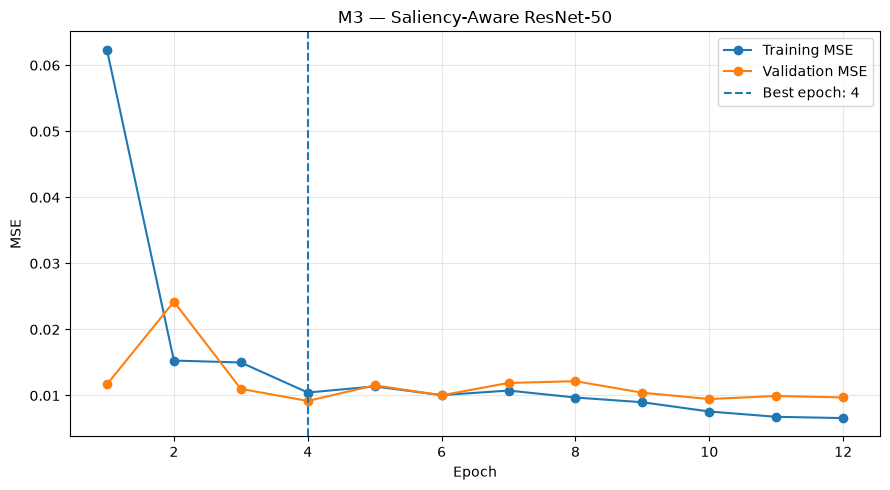

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

m3_history = pd.read_csv(
    RESULTS_DIR / "m3_rep01_history.csv"
)

best_epoch = int(
    m3_history.loc[m3_history["val_mse"].idxmin(), "epoch"]
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    m3_history["epoch"],
    m3_history["train_mse"],
    marker="o",
    label="Training MSE"
)

ax.plot(
    m3_history["epoch"],
    m3_history["val_mse"],
    marker="o",
    label="Validation MSE"
)

ax.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

ax.set_title("M3 — Saliency-Aware ResNet-50")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

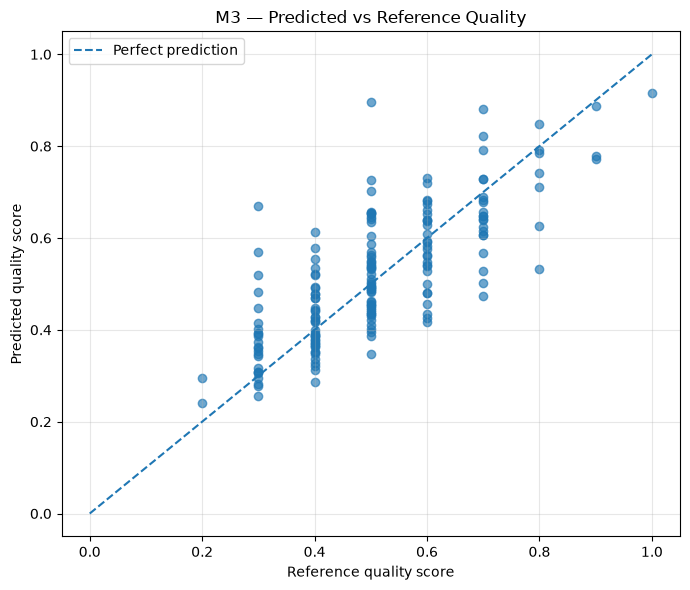

In [49]:
import numpy as np

m3_predictions = pd.read_csv(
    RESULTS_DIR / "m3_rep01_test_predictions.csv"
)

y_true = m3_predictions["reference_score"]
y_pred = m3_predictions["predicted_score"]

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y_true, y_pred, alpha=0.65)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect prediction"
)

ax.set_title("M3 — Predicted vs Reference Quality")
ax.set_xlabel("Reference quality score")
ax.set_ylabel("Predicted quality score")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

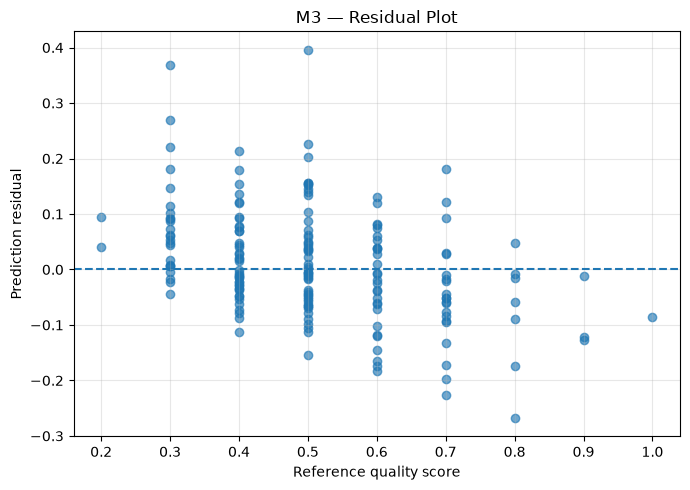

In [50]:
residuals = y_pred - y_true

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(y_true, residuals, alpha=0.65)
ax.axhline(0, linestyle="--")

ax.set_title("M3 — Residual Plot")
ax.set_xlabel("Reference quality score")
ax.set_ylabel("Prediction residual")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights


class M4DegradationAwareResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Pretrained global image feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # ImageNet normalization values
        self.register_buffer(
            "rgb_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "rgb_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

        # Laplacian kernel for a simple sharpness indicator
        laplacian_kernel = torch.tensor([
            [0., 1., 0.],
            [1., -4., 1.],
            [0., 1., 0.]
        ]).view(1, 1, 3, 3)

        self.register_buffer("laplacian_kernel", laplacian_kernel)

        # 2048 CNN features + 5 degradation indicators
        self.regressor = nn.Sequential(
            nn.Linear(2053, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def extract_degradation_features(self, rgb):
        # Convert RGB to luminance
        r = rgb[:, 0:1]
        g = rgb[:, 1:2]
        b = rgb[:, 2:3]

        luminance = (
            0.299 * r + 0.587 * g + 0.114 * b
        )

        # 1. Color cast proxy: differences between mean channels
        channel_means = rgb.mean(dim=(2, 3))
        color_cast = (
            channel_means.max(dim=1).values
            - channel_means.min(dim=1).values
        )

        # 2. Haze/visibility proxy: low average saturation
        saturation = (
            rgb.max(dim=1).values - rgb.min(dim=1).values
        )
        haze_proxy = 1.0 - saturation.mean(dim=(1, 2))

        # 3. Blur proxy: inverse of Laplacian variance
        laplacian = F.conv2d(
            luminance,
            self.laplacian_kernel,
            padding=1
        )
        lap_var = laplacian.var(
            dim=(1, 2, 3), unbiased=False
        )
        blur_proxy = 1.0 / (lap_var + 1e-4)

        # 4. Contrast proxy: inverse luminance standard deviation
        luminance_std = luminance.std(
            dim=(1, 2, 3), unbiased=False
        )
        contrast_proxy = 1.0 / (luminance_std + 1e-3)

        # 5. Noise proxy: high-frequency residual energy
        local_mean = F.avg_pool2d(
            luminance, kernel_size=3, stride=1, padding=1
        )
        high_frequency = luminance - local_mean
        noise_proxy = high_frequency.abs().mean(
            dim=(1, 2, 3)
        )

        features = torch.stack([
            color_cast,
            haze_proxy,
            blur_proxy,
            contrast_proxy,
            noise_proxy
        ], dim=1)

        # Keep numerical values bounded and stable
        features = torch.log1p(features.clamp(min=0))

        return features

    def forward(self, images):
        # Restore approximate RGB values in [0, 1]
        rgb = (
            images * self.rgb_std + self.rgb_mean
        ).clamp(0, 1)

        # Global ResNet features
        global_features = self.feature_extractor(
            images
        ).flatten(1)

        # Handcrafted degradation indicators
        degradation_features = self.extract_degradation_features(
            rgb
        )

        # Combine global and degradation information
        combined_features = torch.cat(
            [global_features, degradation_features],
            dim=1
        )

        predictions = self.regressor(
            combined_features
        ).squeeze(-1)

        return predictions

In [52]:
m4_model = M4DegradationAwareResNet().to(DEVICE)
m4_model.eval()

with torch.no_grad():
    sample_images, sample_scores, sample_names = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)

    sample_rgb = (
        sample_images * m4_model.rgb_std
        + m4_model.rgb_mean
    ).clamp(0, 1)

    sample_degradation_features = (
        m4_model.extract_degradation_features(sample_rgb)
    )

    sample_predictions = m4_model(sample_images)

print("Input shape:", sample_images.shape)
print("Degradation features shape:",
      sample_degradation_features.shape)
print("Degradation features:\n",
      sample_degradation_features[:3].cpu())
print("Output shape:", sample_predictions.shape)
print("Predictions:", sample_predictions[:5].cpu())
print("All predictions finite:",
      torch.isfinite(sample_predictions).all().item())

print(
    "Total parameters:",
    sum(p.numel() for p in m4_model.parameters())
)

Input shape: torch.Size([8, 3, 224, 224])
Degradation features shape: torch.Size([8, 5])
Degradation features:
 tensor([[0.1920, 0.5550, 4.1206, 1.9968, 0.0205],
        [0.2603, 0.5172, 4.4242, 1.7130, 0.0141],
        [0.2340, 0.4734, 3.5597, 2.0205, 0.0265]])
Output shape: torch.Size([8])
Predictions: tensor([ 0.0869,  0.1470, -0.0628,  0.0366,  0.2249])
All predictions finite: True
Total parameters: 24560193


In [53]:
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

SEED = 2027
MAX_EPOCHS = 50
PATIENCE = 8

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reinitialize the model after setting the seed
m4_model = M4DegradationAwareResNet().to(DEVICE)

criterion = nn.MSELoss()

backbone_params = list(
    m4_model.feature_extractor.parameters()
)

head_params = (
    list(m4_model.regressor.parameters())
)

optimizer = Adam(
    [
        {"params": backbone_params, "lr": 1e-4},
        {"params": head_params, "lr": 3e-4},
    ],
    weight_decay=1e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

best_val_mse = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_state = None
history = []

for epoch in range(1, MAX_EPOCHS + 1):

    # Training
    m4_model.train()
    train_squared_error = 0.0
    train_count = 0

    for images, scores, _ in train_loader:
        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float().view(-1)

        optimizer.zero_grad()

        predictions = m4_model(images)
        loss = criterion(predictions, scores)

        loss.backward()
        optimizer.step()

        train_squared_error += loss.item() * images.size(0)
        train_count += images.size(0)

    train_mse = train_squared_error / train_count

    # Validation
    m4_model.eval()
    val_squared_error = 0.0
    val_count = 0

    with torch.no_grad():
        for images, scores, _ in val_loader:
            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float().view(-1)

            predictions = m4_model(images)
            loss = criterion(predictions, scores)

            val_squared_error += loss.item() * images.size(0)
            val_count += images.size(0)

    val_mse = val_squared_error / val_count
    scheduler.step(val_mse)

    improved = val_mse < best_val_mse

    if improved:
        best_val_mse = val_mse
        best_epoch = epoch
        best_state = copy.deepcopy(m4_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "head_lr": optimizer.param_groups[1]["lr"],
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Best epoch: {best_epoch}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

# Restore the best validation checkpoint
m4_model.load_state_dict(best_state)
m4_model.eval()

history_df = pd.DataFrame(history)

history_path = RESULTS_DIR / "m4_rep01_history.csv"
history_df.to_csv(history_path, index=False)

checkpoint_path = (
    PROJECT_DIR / "checkpoints" / "m4_rep01_best.pt"
)

torch.save({
    "model_state_dict": best_state,
    "best_epoch": best_epoch,
    "best_val_mse": best_val_mse,
    "seed": SEED,
}, checkpoint_path)

print("\nM4 training complete.")
print("Best epoch:", best_epoch)
print("Best validation MSE:", round(best_val_mse, 6))
print("History saved to:", history_path)
print("Checkpoint saved to:", checkpoint_path)

Epoch 01 | Train MSE: 0.047930 | Val MSE: 0.021422 | Best epoch: 1
Epoch 02 | Train MSE: 0.017948 | Val MSE: 0.014486 | Best epoch: 2
Epoch 03 | Train MSE: 0.013105 | Val MSE: 0.011347 | Best epoch: 3
Epoch 04 | Train MSE: 0.012586 | Val MSE: 0.010096 | Best epoch: 4
Epoch 05 | Train MSE: 0.014173 | Val MSE: 0.010355 | Best epoch: 4
Epoch 06 | Train MSE: 0.011495 | Val MSE: 0.008948 | Best epoch: 6
Epoch 07 | Train MSE: 0.011009 | Val MSE: 0.006909 | Best epoch: 7
Epoch 08 | Train MSE: 0.011066 | Val MSE: 0.008751 | Best epoch: 7
Epoch 09 | Train MSE: 0.010107 | Val MSE: 0.007310 | Best epoch: 7
Epoch 10 | Train MSE: 0.010553 | Val MSE: 0.010736 | Best epoch: 7
Epoch 11 | Train MSE: 0.009077 | Val MSE: 0.011135 | Best epoch: 7
Epoch 12 | Train MSE: 0.008079 | Val MSE: 0.006184 | Best epoch: 12
Epoch 13 | Train MSE: 0.007038 | Val MSE: 0.008023 | Best epoch: 12
Epoch 14 | Train MSE: 0.006260 | Val MSE: 0.006601 | Best epoch: 12
Epoch 15 | Train MSE: 0.006688 | Val MSE: 0.007281 | Best e

In [54]:
import numpy as np
import pandas as pd
import torch
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error, mean_absolute_error

m4_model.load_state_dict(
    torch.load(
        PROJECT_DIR / "checkpoints" / "m4_rep01_best.pt",
        map_location=DEVICE,
        weights_only=False
    )["model_state_dict"]
)

m4_model.eval()

y_true = []
y_pred = []
image_names = []

with torch.no_grad():
    for images, scores, names in test_loader:
        images = images.to(DEVICE)

        predictions = m4_model(images)

        y_true.extend(scores.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        image_names.extend(names)

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic
krcc = kendalltau(y_true, y_pred).statistic
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)

m4_metrics = pd.DataFrame([{
    "model": "M4",
    "repetition": 1,
    "test_samples": len(y_true),
    "best_epoch": 32,
    "best_val_mse": 0.006337,
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MAE": mae,
    "MSE": mse,
}])

print(m4_metrics.T)

predictions_df = pd.DataFrame({
    "image": image_names,
    "reference_score": y_true,
    "predicted_score": y_pred,
    "residual": y_pred - y_true,
})

predictions_path = (
    RESULTS_DIR / "m4_rep01_test_predictions.csv"
)
metrics_path = (
    RESULTS_DIR / "m4_rep01_test_metrics.csv"
)

predictions_df.to_csv(predictions_path, index=False)
m4_metrics.to_csv(metrics_path, index=False)

print("\nPredictions saved to:", predictions_path)
print("Metrics saved to:", metrics_path)

                     0
model               M4
repetition           1
test_samples       178
best_epoch          32
best_val_mse  0.006337
PLCC          0.820411
SRCC          0.797497
KRCC          0.652274
RMSE          0.087453
MAE           0.068919
MSE           0.007648

Predictions saved to: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep01_test_predictions.csv
Metrics saved to: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep01_test_metrics.csv


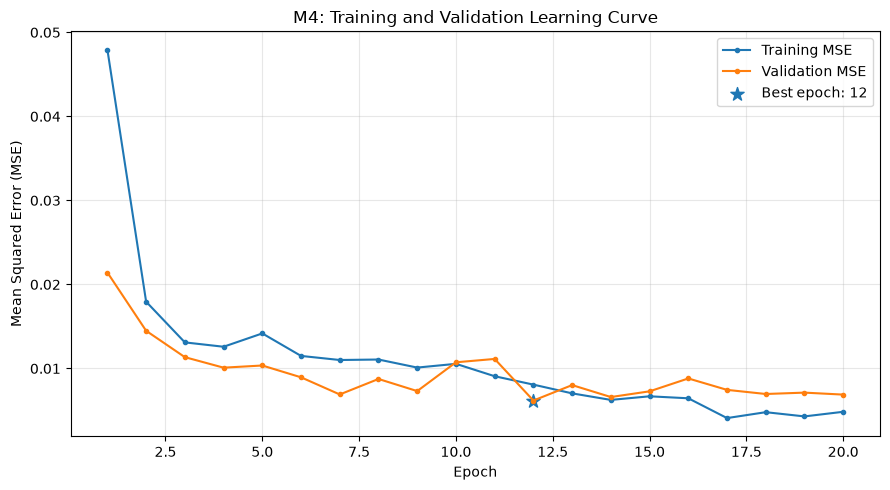

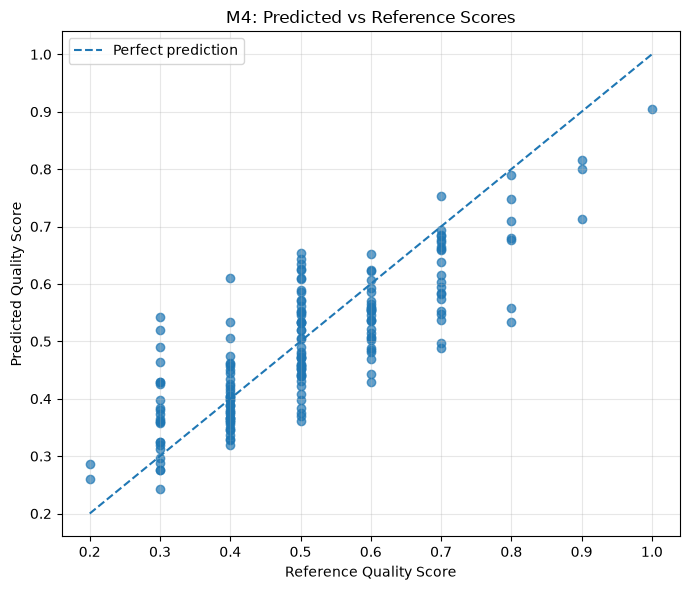

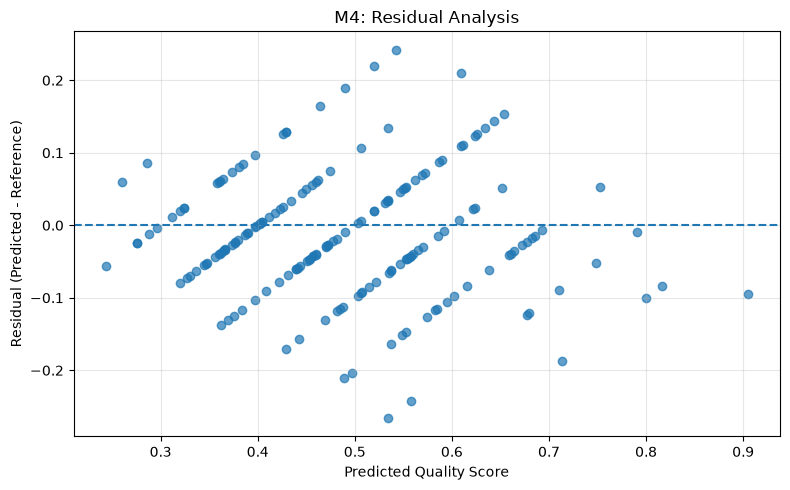

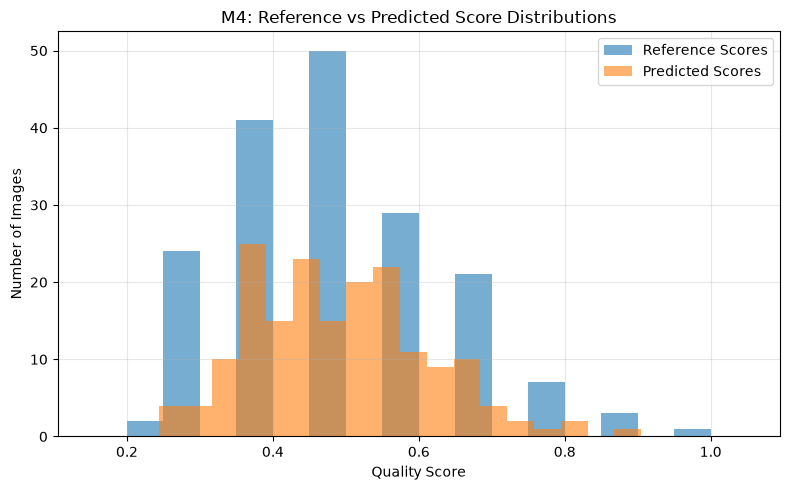

All four M4 plots generated and saved in:
/home/karthikbaskar2/UWIQA_Research_Experiments/results/plots


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# File paths
history_path = RESULTS_DIR / "m4_rep01_history.csv"
predictions_path = RESULTS_DIR / "m4_rep01_test_predictions.csv"

plots_dir = RESULTS_DIR / "plots"
plots_dir.mkdir(parents=True, exist_ok=True)

# Load saved results
history = pd.read_csv(history_path)
predictions = pd.read_csv(predictions_path)

y_true = predictions["reference_score"].to_numpy()
y_pred = predictions["predicted_score"].to_numpy()
residuals = y_pred - y_true

# --------------------------------------------------
# PLOT 1: Training and Validation Learning Curve
# --------------------------------------------------
plt.figure(figsize=(9, 5))

plt.plot(
    history["epoch"], history["train_mse"],
    marker="o", markersize=3, label="Training MSE"
)
plt.plot(
    history["epoch"], history["val_mse"],
    marker="o", markersize=3, label="Validation MSE"
)

best_epoch = history.loc[history["val_mse"].idxmin(), "epoch"]
best_val = history["val_mse"].min()

plt.scatter(
    best_epoch, best_val,
    s=100, marker="*", label=f"Best epoch: {int(best_epoch)}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("M4: Training and Validation Learning Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "m4_rep01_learning_curve.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# PLOT 2: Predicted vs Reference Quality Scores
# --------------------------------------------------
plt.figure(figsize=(7, 6))

plt.scatter(y_true, y_pred, alpha=0.7)

limits = [
    min(y_true.min(), y_pred.min()),
    max(y_true.max(), y_pred.max())
]

plt.plot(
    limits, limits,
    linestyle="--", label="Perfect prediction"
)

plt.xlabel("Reference Quality Score")
plt.ylabel("Predicted Quality Score")
plt.title("M4: Predicted vs Reference Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "m4_rep01_prediction_scatter.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# PLOT 3: Residual Plot
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Quality Score")
plt.ylabel("Residual (Predicted - Reference)")
plt.title("M4: Residual Analysis")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "m4_rep01_residual_plot.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# PLOT 4: Reference vs Predicted Score Distributions
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.hist(
    y_true, bins=np.arange(0.15, 1.06, 0.05),
    alpha=0.6, label="Reference Scores"
)
plt.hist(
    y_pred, bins=18,
    alpha=0.6, label="Predicted Scores"
)

plt.xlabel("Quality Score")
plt.ylabel("Number of Images")
plt.title("M4: Reference vs Predicted Score Distributions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    plots_dir / "m4_rep01_score_distributions.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


print("All four M4 plots generated and saved in:")
print(plots_dir)

In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights


class M5DegradationSaliencyPatchNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Pretrained ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # ImageNet normalization values, for recovering RGB
        self.register_buffer(
            "rgb_mean",
            torch.tensor([0.485, 0.456, 0.406])
            .view(1, 3, 1, 1)
        )

        self.register_buffer(
            "rgb_std",
            torch.tensor([0.229, 0.224, 0.225])
            .view(1, 3, 1, 1)
        )

        # Five degradation-related indicators
        laplacian = torch.tensor([
            [0., 1., 0.],
            [1., -4., 1.],
            [0., 1., 0.]
        ]).view(1, 1, 3, 3)

        self.register_buffer("laplacian_kernel", laplacian)

        # Patch-quality prediction head
        self.quality_head = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

        # Learned patch-importance head
        self.importance_head = nn.Sequential(
            nn.Linear(2053, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )

        # Image-level quality regression head
        self.fusion_head = nn.Sequential(
            nn.Linear(2053, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def extract_degradation_features(self, rgb):
        # rgb: [batch, 3, height, width]
        r = rgb[:, 0:1]
        g = rgb[:, 1:2]
        b = rgb[:, 2:3]

        luminance = 0.299*r + 0.587*g + 0.114*b

        # 1. Color-cast proxy
        channel_means = rgb.mean(dim=(2, 3))
        color_cast = (
            channel_means.max(dim=1).values
            - channel_means.min(dim=1).values
        )

        # 2. Low-saturation proxy (not a true haze measurement)
        saturation = (
            rgb.max(dim=1).values
            - rgb.min(dim=1).values
        )
        haze_proxy = 1.0 - saturation.mean(dim=(1, 2))

        # 3. Blur proxy
        lap = F.conv2d(
            luminance,
            self.laplacian_kernel,
            padding=1
        )
        lap_var = lap.var(
            dim=(1, 2, 3),
            unbiased=False
        )
        blur_proxy = 1.0 / (lap_var + 1e-4)

        # 4. Low-contrast proxy
        luminance_std = luminance.std(
            dim=(1, 2, 3),
            unbiased=False
        )
        contrast_proxy = 1.0 / (luminance_std + 1e-3)

        # 5. High-frequency residual proxy
        local_mean = F.avg_pool2d(
            luminance,
            kernel_size=3,
            stride=1,
            padding=1
        )
        high_frequency = luminance - local_mean
        noise_proxy = high_frequency.abs().mean(
            dim=(1, 2, 3)
        )

        features = torch.stack([
            color_cast,
            haze_proxy,
            blur_proxy,
            contrast_proxy,
            noise_proxy
        ], dim=1)

        return torch.log1p(features.clamp(min=0))

    def forward(self, images, return_details=False):
        batch_size = images.size(0)

        # Recover RGB values from ImageNet-normalized images
        rgb = (
            images * self.rgb_std + self.rgb_mean
        ).clamp(0, 1)

        # Four non-overlapping patches
        patches = torch.cat([
            images[:, :, :112, :112],
            images[:, :, :112, 112:],
            images[:, :, 112:, :112],
            images[:, :, 112:, 112:]
        ], dim=0)

        # Shared ResNet-50 weights for every patch
        features = self.feature_extractor(
            patches
        ).flatten(1)

        # [batch, 4, 2048]
        features = features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Calculate five indicators for each patch
        patch_rgb = torch.cat([
            rgb[:, :, :112, :112],
            rgb[:, :, :112, 112:],
            rgb[:, :, 112:, :112],
            rgb[:, :, 112:, 112:]
        ], dim=0)

        degradation = self.extract_degradation_features(
            patch_rgb
        ).reshape(4, batch_size, 5).permute(1, 0, 2)

        # Patch-level quality predictions
        patch_quality = self.quality_head(
            features
        ).squeeze(-1)  # [batch, 4]

        # Combine patch features and degradation indicators
        combined = torch.cat(
            [features, degradation], dim=-1
        )  # [batch, 4, 2053]

        # Learned importance scores
        importance_logits = self.importance_head(
            combined
        ).squeeze(-1)

        importance_weights = torch.softmax(
            importance_logits, dim=1
        )  # [batch, 4]

        # Weighted patch features
        weighted_features = (
            combined * importance_weights.unsqueeze(-1)
        ).sum(dim=1)  # [batch, 2053]

        # Aggregate patch quality predictions
        aggregated_quality = (
            importance_weights * patch_quality
        ).sum(dim=1)  # [batch]

        # Final image-level prediction
        image_quality = self.fusion_head(
            weighted_features
        ).squeeze(-1)

        # Combine both image-level estimates
        final_quality = (
            0.5 * image_quality
            + 0.5 * aggregated_quality
        )

        if return_details:
            return {
                "prediction": final_quality,
                "patch_quality": patch_quality,
                "importance_weights": importance_weights,
                "degradation_features": degradation,
                "image_quality": image_quality,
                "aggregated_quality": aggregated_quality
            }

        return final_quality

In [57]:
m5_model = M5DegradationSaliencyPatchNet().to(DEVICE)
m5_model.eval()

with torch.no_grad():
    sample_images, sample_scores, sample_names = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)

    outputs = m5_model(
        sample_images,
        return_details=True
    )

print("Input shape:", sample_images.shape)
print("Final prediction shape:", outputs["prediction"].shape)
print("Patch quality shape:", outputs["patch_quality"].shape)
print("Importance weights shape:", outputs["importance_weights"].shape)
print("Degradation features shape:", outputs["degradation_features"].shape)

print("\nImportance weights for first image:")
print(outputs["importance_weights"][0].cpu())

print("\nImportance weights sum:")
print(outputs["importance_weights"].sum(dim=1).cpu())

print("\nFirst five predictions:")
print(outputs["prediction"][:5].cpu())

print(
    "\nAll predictions finite:",
    torch.isfinite(outputs["prediction"]).all().item()
)

print(
    "Total parameters:",
    sum(p.numel() for p in m5_model.parameters())
)

Input shape: torch.Size([8, 3, 224, 224])
Final prediction shape: torch.Size([8])
Patch quality shape: torch.Size([8, 4])
Importance weights shape: torch.Size([8, 4])
Degradation features shape: torch.Size([8, 4, 5])

Importance weights for first image:
tensor([0.2115, 0.2221, 0.2668, 0.2996])

Importance weights sum:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])

First five predictions:
tensor([0.1624, 0.1395, 0.0897, 0.1052, 0.1705])

All predictions finite: True
Total parameters: 25611075


In [58]:
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Reproducibility
SEED = 2027
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MAX_EPOCHS = 50
PATIENCE = 8

# Fresh model initialization
m5_model = M5DegradationSaliencyPatchNet().to(DEVICE)

criterion = nn.MSELoss()

# Separate learning rates for backbone and model heads
backbone_params = list(
    m5_model.feature_extractor.parameters()
)

head_params = (
    list(m5_model.quality_head.parameters())
    + list(m5_model.importance_head.parameters())
    + list(m5_model.fusion_head.parameters())
)

optimizer = Adam(
    [
        {"params": backbone_params, "lr": 1e-4},
        {"params": head_params, "lr": 3e-4},
    ],
    weight_decay=1e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

best_val_mse = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_state = None
history = []

for epoch in range(1, MAX_EPOCHS + 1):

    # -------------------------
    # Training
    # -------------------------
    m5_model.train()
    train_squared_error = 0.0
    train_count = 0

    for images, scores, _ in train_loader:
        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float().view(-1)

        optimizer.zero_grad()

        predictions = m5_model(images)
        loss = criterion(predictions, scores)

        loss.backward()
        optimizer.step()

        train_squared_error += loss.item() * images.size(0)
        train_count += images.size(0)

    train_mse = train_squared_error / train_count

    # -------------------------
    # Validation
    # -------------------------
    m5_model.eval()
    val_squared_error = 0.0
    val_count = 0

    with torch.no_grad():
        for images, scores, _ in val_loader:
            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float().view(-1)

            predictions = m5_model(images)
            loss = criterion(predictions, scores)

            val_squared_error += loss.item() * images.size(0)
            val_count += images.size(0)

    val_mse = val_squared_error / val_count
    scheduler.step(val_mse)

    # Keep the checkpoint with the lowest validation MSE
    improved = val_mse < best_val_mse

    if improved:
        best_val_mse = val_mse
        best_epoch = epoch
        best_state = copy.deepcopy(m5_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "head_lr": optimizer.param_groups[1]["lr"],
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Best epoch: {best_epoch}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

# Restore the best checkpoint
m5_model.load_state_dict(best_state)
m5_model.eval()

# Save training history
history_df = pd.DataFrame(history)
history_path = RESULTS_DIR / "m5_rep01_history.csv"
history_df.to_csv(history_path, index=False)

# Save model checkpoint
checkpoint_path = (
    PROJECT_DIR / "checkpoints" / "m5_rep01_best.pt"
)

torch.save({
    "model_state_dict": best_state,
    "best_epoch": best_epoch,
    "best_val_mse": best_val_mse,
    "seed": SEED,
}, checkpoint_path)

print("\nM5 training complete.")
print("Best epoch:", best_epoch)
print("Best validation MSE:", round(best_val_mse, 6))
print("History saved to:", history_path)
print("Checkpoint saved to:", checkpoint_path)

Epoch 01 | Train MSE: 0.037500 | Val MSE: 0.014977 | Best epoch: 1
Epoch 02 | Train MSE: 0.016818 | Val MSE: 0.011464 | Best epoch: 2
Epoch 03 | Train MSE: 0.009987 | Val MSE: 0.012386 | Best epoch: 2
Epoch 04 | Train MSE: 0.007236 | Val MSE: 0.011848 | Best epoch: 2
Epoch 05 | Train MSE: 0.008509 | Val MSE: 0.012606 | Best epoch: 2
Epoch 06 | Train MSE: 0.007386 | Val MSE: 0.009805 | Best epoch: 6
Epoch 07 | Train MSE: 0.006592 | Val MSE: 0.011175 | Best epoch: 6
Epoch 08 | Train MSE: 0.007288 | Val MSE: 0.017760 | Best epoch: 6
Epoch 09 | Train MSE: 0.005629 | Val MSE: 0.019955 | Best epoch: 6
Epoch 10 | Train MSE: 0.005722 | Val MSE: 0.011595 | Best epoch: 6
Epoch 11 | Train MSE: 0.006000 | Val MSE: 0.009635 | Best epoch: 11
Epoch 12 | Train MSE: 0.004449 | Val MSE: 0.014573 | Best epoch: 11
Epoch 13 | Train MSE: 0.003592 | Val MSE: 0.009506 | Best epoch: 13
Epoch 14 | Train MSE: 0.003488 | Val MSE: 0.010544 | Best epoch: 13
Epoch 15 | Train MSE: 0.003301 | Val MSE: 0.011358 | Best 

In [59]:
import numpy as np
import pandas as pd
import torch
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load the best M5 checkpoint
checkpoint = torch.load(
    PROJECT_DIR / "checkpoints" / "m5_rep01_best.pt",
    map_location=DEVICE,
    weights_only=False
)

m5_model.load_state_dict(checkpoint["model_state_dict"])
m5_model.eval()

y_true = []
y_pred = []
image_names = []

with torch.no_grad():
    for images, scores, names in test_loader:
        images = images.to(DEVICE)
        predictions = m5_model(images)

        y_true.extend(scores.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        image_names.extend(names)

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

metrics = {
    "model": "M5",
    "repetition": 1,
    "test_samples": len(y_true),
    "best_epoch": checkpoint["best_epoch"],
    "best_val_mse": checkpoint["best_val_mse"],
    "PLCC": pearsonr(y_true, y_pred).statistic,
    "SRCC": spearmanr(y_true, y_pred).statistic,
    "KRCC": kendalltau(y_true, y_pred).statistic,
    "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    "MAE": mean_absolute_error(y_true, y_pred),
    "MSE": mean_squared_error(y_true, y_pred),
}

metrics_df = pd.DataFrame([metrics])

predictions_df = pd.DataFrame({
    "image": image_names,
    "reference_score": y_true,
    "predicted_score": y_pred,
    "residual": y_pred - y_true,
})

metrics_path = RESULTS_DIR / "m5_rep01_test_metrics.csv"
predictions_path = RESULTS_DIR / "m5_rep01_test_predictions.csv"

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

print(metrics_df.T)
print("\nMetrics saved to:", metrics_path)
print("Predictions saved to:", predictions_path)

                     0
model               M5
repetition           1
test_samples       178
best_epoch          16
best_val_mse  0.009199
PLCC          0.754577
SRCC          0.742722
KRCC          0.600284
RMSE          0.099049
MAE           0.073805
MSE           0.009811

Metrics saved to: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep01_test_metrics.csv
Predictions saved to: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep01_test_predictions.csv


History columns: ['epoch', 'train_mse', 'val_mse', 'backbone_lr', 'head_lr']
Prediction columns: ['image', 'reference_score', 'predicted_score', 'residual']


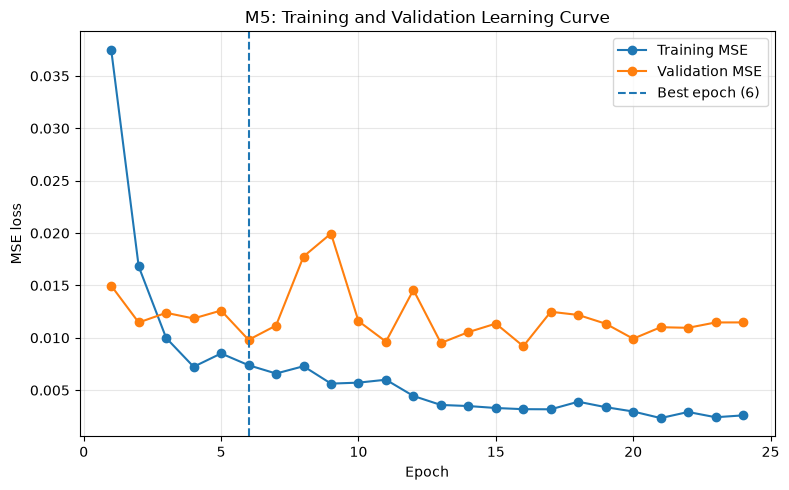

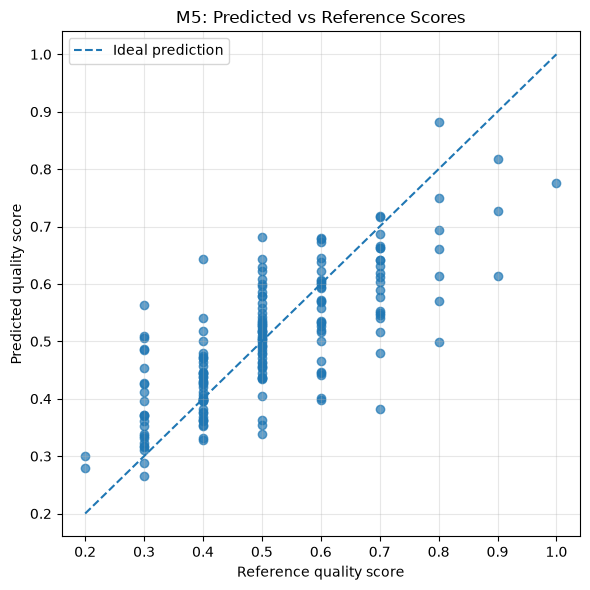

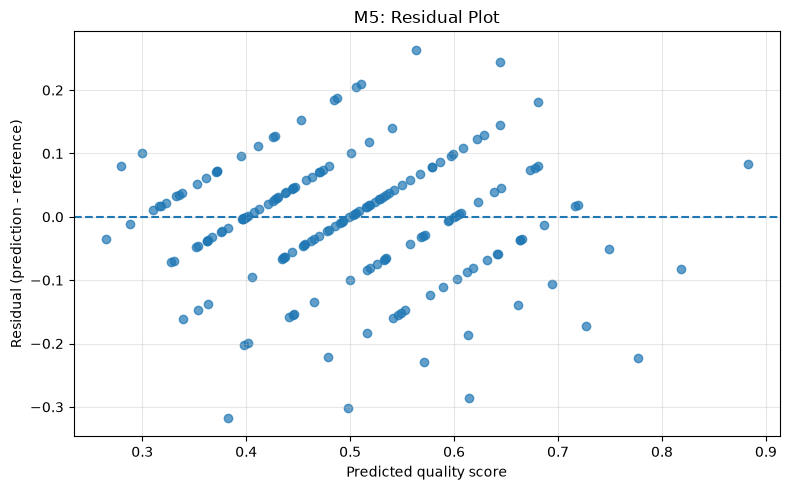

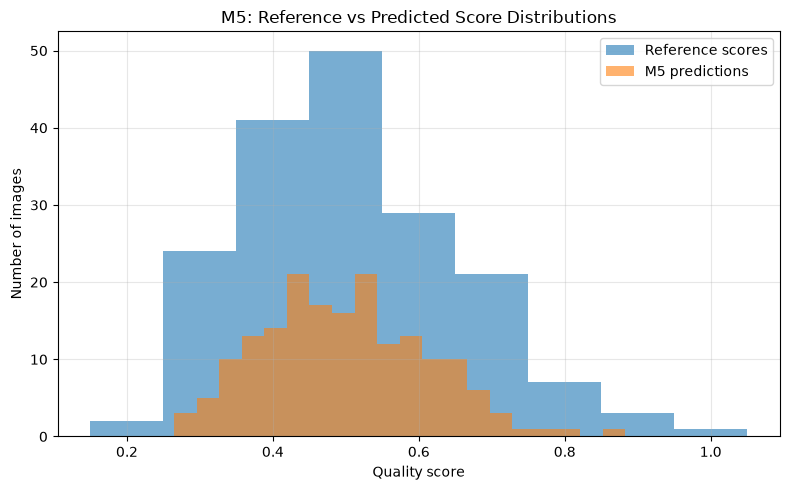


Plots saved in: /home/karthikbaskar2/UWIQA_Research_Experiments/results/plots
m5_rep01_learning_curve.png
m5_rep01_prediction_scatter.png
m5_rep01_residual_plot.png
m5_rep01_score_distributions.png


In [60]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

history_path = RESULTS_DIR / "m5_rep01_history.csv"
predictions_path = RESULTS_DIR / "m5_rep01_test_predictions.csv"

history_df = pd.read_csv(history_path)
pred_df = pd.read_csv(predictions_path)

print("History columns:", history_df.columns.tolist())
print("Prediction columns:", pred_df.columns.tolist())


# --------------------------------------------------
# 2. Plot 1: Training and validation learning curve
# --------------------------------------------------
# Detect common column names in the saved history.
train_col = next(
    (c for c in history_df.columns
     if c.lower() in ["train_loss", "train_mse", "training_loss",
                      "train_mse_loss"]),
    None
)
val_col = next(
    (c for c in history_df.columns
     if c.lower() in ["val_loss", "val_mse", "validation_loss",
                      "validation_mse"]),
    None
)
epoch_col = next(
    (c for c in history_df.columns if c.lower() == "epoch"),
    None
)

if train_col is None or val_col is None:
    print("Could not automatically identify loss columns.")
    print("Use the column names printed above to set train_col and val_col.")
else:
    epochs = (
        history_df[epoch_col]
        if epoch_col is not None
        else np.arange(1, len(history_df) + 1)
    )

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history_df[train_col], marker="o",
             label="Training MSE")
    plt.plot(epochs, history_df[val_col], marker="o",
             label="Validation MSE")
    plt.axvline(6, linestyle="--", label="Best epoch (6)")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")
    plt.title("M5: Training and Validation Learning Curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "m5_rep01_learning_curve.png", dpi=300)
    plt.show()


# --------------------------------------------------
# 3. Plot 2: Predicted vs reference scores
# --------------------------------------------------
y_true = pred_df["reference_score"].to_numpy()
y_pred = pred_df["predicted_score"].to_numpy()

low = min(y_true.min(), y_pred.min())
high = max(y_true.max(), y_pred.max())

plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.7)
plt.plot([low, high], [low, high], linestyle="--",
         label="Ideal prediction")
plt.xlabel("Reference quality score")
plt.ylabel("Predicted quality score")
plt.title("M5: Predicted vs Reference Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "m5_rep01_prediction_scatter.png", dpi=300)
plt.show()


# --------------------------------------------------
# 4. Plot 3: Residual analysis
# --------------------------------------------------
residuals = y_pred - y_true

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted quality score")
plt.ylabel("Residual (prediction - reference)")
plt.title("M5: Residual Plot")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "m5_rep01_residual_plot.png", dpi=300)
plt.show()


# --------------------------------------------------
# 5. Plot 4: Reference and prediction distributions
# --------------------------------------------------
plt.figure(figsize=(8, 5))
plt.hist(y_true, bins=np.arange(0.15, 1.06, 0.1),
         alpha=0.6, label="Reference scores")
plt.hist(y_pred, bins=20, alpha=0.6,
         label="M5 predictions")
plt.xlabel("Quality score")
plt.ylabel("Number of images")
plt.title("M5: Reference vs Predicted Score Distributions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "m5_rep01_score_distributions.png", dpi=300)
plt.show()


# --------------------------------------------------
# 6. Confirm saved plots
# --------------------------------------------------
print("\nPlots saved in:", PLOTS_DIR)
for path in sorted(PLOTS_DIR.glob("m5_rep01_*.png")):
    print(path.name)


In [61]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
RESULTS_DIR = PROJECT_DIR / "results"

# Load the saved test metrics for repetition 1
model_names = ["m0", "m1", "m2", "m3", "m4", "m5"]

metric_frames = []

for model_name in model_names:
    file_path = RESULTS_DIR / f"{model_name}_rep01_test_metrics.csv"

    if not file_path.exists():
        print(f"Missing file: {file_path}")
        continue

    df = pd.read_csv(file_path)
    metric_frames.append(df)

if not metric_frames:
    raise FileNotFoundError("No model metric files were found.")

comparison_df = pd.concat(metric_frames, ignore_index=True)

# Keep the table organized
metric_columns = [
    "model", "repetition", "test_samples", "best_epoch",
    "PLCC", "SRCC", "KRCC", "RMSE", "MAE", "MSE"
]

comparison_df = comparison_df[
    [col for col in metric_columns if col in comparison_df.columns]
]

# Sort in model order
comparison_df["model"] = pd.Categorical(
    comparison_df["model"],
    categories=["M0", "M1", "M2", "M3", "M4", "M5"],
    ordered=True
)
comparison_df = comparison_df.sort_values("model").reset_index(drop=True)

# Display a rounded table
display(comparison_df.round(5))

# Save the comparison
comparison_path = RESULTS_DIR / "comparison_rep01_M0_M5.csv"
comparison_df.to_csv(comparison_path, index=False)

print("Comparison saved to:", comparison_path)


/tmp/ipykernel_331391/3438465378.py:38: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  comparison_df["model"] = pd.Categorical(


,model,repetition,test_samples,best_epoch,PLCC,SRCC,KRCC,RMSE,MAE,MSE
0,M1,1,NaN,NaN,0.77546,0.74874,0.60141,0.09999,0.07601,0.01000
1,M2,1,NaN,4.0,0.74651,0.73632,0.58803,0.10053,0.07583,0.01011
2,M3,1,NaN,4.0,0.76583,0.75481,0.61170,0.10111,0.07650,0.01022
3,M4,1,178.0,32.0,0.82041,0.79750,0.65227,0.08745,0.06892,0.00765
4,M5,1,178.0,16.0,0.75458,0.74272,0.60028,0.09905,0.07381,0.00981
5,NaN,1,NaN,NaN,0.82612,0.80956,0.66580,0.08557,0.06665,0.00732


Comparison saved to: /home/karthikbaskar2/UWIQA_Research_Experiments/results/comparison_rep01_M0_M5.csv


In [62]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
RESULTS_DIR = PROJECT_DIR / "results"

model_names = ["M0", "M1", "M2", "M3", "M4", "M5"]
all_metrics = []

for model in model_names:
    file_path = RESULTS_DIR / f"{model.lower()}_rep01_test_metrics.csv"

    if not file_path.exists():
        print(f"Missing file: {file_path}")
        continue

    df = pd.read_csv(file_path)

    # Ensure the model name is correct
    df["model"] = model
    all_metrics.append(df)

comparison_df = pd.concat(all_metrics, ignore_index=True)

# Select columns in the correct order
columns = [
    "model", "repetition", "test_samples", "best_epoch",
    "PLCC", "SRCC", "KRCC", "RMSE", "MAE", "MSE"
]

comparison_df = comparison_df[columns]

# Display
display(comparison_df.round(5))

# Save corrected table
output_path = RESULTS_DIR / "comparison_rep01_M0_M5_corrected.csv"
comparison_df.to_csv(output_path, index=False)

print("Corrected comparison saved to:", output_path)


,model,repetition,test_samples,best_epoch,PLCC,SRCC,KRCC,RMSE,MAE,MSE
0,M0,1,NaN,NaN,0.82612,0.80956,0.66580,0.08557,0.06665,0.00732
1,M1,1,NaN,NaN,0.77546,0.74874,0.60141,0.09999,0.07601,0.01000
2,M2,1,NaN,4.0,0.74651,0.73632,0.58803,0.10053,0.07583,0.01011
3,M3,1,NaN,4.0,0.76583,0.75481,0.61170,0.10111,0.07650,0.01022
4,M4,1,178.0,32.0,0.82041,0.79750,0.65227,0.08745,0.06892,0.00765
5,M5,1,178.0,16.0,0.75458,0.74272,0.60028,0.09905,0.07381,0.00981


Corrected comparison saved to: /home/karthikbaskar2/UWIQA_Research_Experiments/results/comparison_rep01_M0_M5_corrected.csv


In [63]:
model_names = ["M0", "M1", "M2", "M3", "M4", "M5"]

for model in model_names:
    file_path = RESULTS_DIR / f"{model.lower()}_rep01_test_metrics.csv"

    print(f"\n{'='*40}")
    print(model)
    print(f"{'='*40}")

    df = pd.read_csv(file_path)
    print("Columns:", df.columns.tolist())
    print(df.to_string(index=False))


M0
Columns: ['dataset', 'model', 'repetition', 'checkpoint_epoch', 'test_images', 'PLCC', 'SRCC', 'KRCC', 'RMSE', 'MAE', 'MSE']
dataset              model  repetition  checkpoint_epoch  test_images     PLCC     SRCC   KRCC     RMSE      MAE      MSE
  UWIQA M0_Global_ResNet50           1                23          178 0.826119 0.809558 0.6658 0.085567 0.066652 0.007322

M1
Columns: ['model', 'repetition', 'test_images', 'PLCC', 'SRCC', 'KRCC', 'RMSE', 'MAE', 'MSE']
model  repetition  test_images     PLCC     SRCC     KRCC     RMSE      MAE      MSE
   M1           1          178 0.775457 0.748743 0.601411 0.099985 0.076008 0.009997

M2
Columns: ['model', 'repetition', 'best_epoch', 'PLCC', 'SRCC', 'KRCC', 'RMSE', 'MAE', 'MSE', 'n_test']
model  repetition  best_epoch     PLCC     SRCC     KRCC     RMSE      MAE      MSE  n_test
   M2           1           4 0.746514 0.736324 0.588026 0.100534 0.075833 0.010107     178

M3
Columns: ['model', 'repetition', 'best_epoch', 'PLCC', 'SRCC', '

In [64]:
print("Current working directory:", Path.cwd())
print("Project directory:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())

Current working directory: /home/karthikbaskar2
Project directory: /home/karthikbaskar2/UWIQA_Research_Experiments
Project directory exists: True


In [66]:
for folder in PROJECT_DIR.rglob("*"):
    if folder.is_dir():
        print(f"\n {folder.relative_to(PROJECT_DIR)}")
    else:
        print(f"    {folder.relative_to(PROJECT_DIR)}")


 logs

 results

 checkpoints

 splits
    results/m5_rep01_test_predictions.csv
    results/comparison_rep01_M0_M5.csv
    results/m2_rep01_test_predictions.csv
    results/comparison_rep01_M0_M5_corrected.csv
    results/m0_rep01_history.csv
    results/m3_rep01_history.csv
    results/m1_rep01_test_predictions.csv
    results/m2_rep01_history.csv
    results/m4_rep01_test_predictions.csv
    results/m3_rep01_test_predictions.csv
    results/m1_rep01_history.csv
    results/m5_rep01_test_metrics.csv
    results/m4_rep01_test_metrics.csv
    results/m0_rep01_test_predictions.csv

 results/plots
    results/m1_rep01_test_metrics.csv
    results/m4_rep01_history.csv
    results/m5_rep01_history.csv
    results/m2_rep01_test_metrics.csv
    results/m0_rep01_test_metrics.csv
    results/m3_rep01_test_metrics.csv
    checkpoints/m1_rep01_best.pt
    checkpoints/m3_rep01_best.pt
    checkpoints/m0_rep01_best.pt
    checkpoints/m5_rep01_best.pt
    checkpoints/m4_rep01_best.pt
    checkpoin

In [65]:
print("CHECKPOINT_DIR:", CHECKPOINT_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("SPLIT_DIR:", SPLIT_DIR)
print("LOG_DIR:", LOG_DIR)

CHECKPOINT_DIR: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints
RESULTS_DIR: /home/karthikbaskar2/UWIQA_Research_Experiments/results
SPLIT_DIR: /home/karthikbaskar2/UWIQA_Research_Experiments/splits
LOG_DIR: /home/karthikbaskar2/UWIQA_Research_Experiments/logs


In [68]:
# repetition 2
import random
import numpy as np
import torch

SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed set to:", SEED)

Random seed set to: 2028


In [69]:
import pandas as pd

split_file = SPLIT_DIR / "uwiqa_split_02.csv"

split_df = pd.read_csv(split_file)

print("Split file:", split_file)
print("\nSplit distribution:")
print(split_df["split"].value_counts())

Split file: /home/karthikbaskar2/UWIQA_Research_Experiments/splits/uwiqa_split_02.csv

Split distribution:
split
train         640
test          178
validation     72
Name: count, dtype: int64


In [75]:
train_df = split_df[split_df["split"] == "train"].copy()
val_df = split_df[split_df["split"] == "validation"].copy()
test_df = split_df[split_df["split"] == "test"].copy()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 640
Validation samples: 72
Testing samples: 178


In [76]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [77]:
print("UWIQADataset:", UWIQADataset)
print("DATASET_DIR:", DATASET_DIR)
print("Transform:", transform)

UWIQADataset: <class '__main__.UWIQADataset'>
DATASET_DIR: /home/karthikbaskar2/UWIQA Dataset/UWIQA
Transform: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [78]:
from torch.utils.data import DataLoader

train_dataset = UWIQADataset(train_df, DATASET_DIR, transform)
val_dataset = UWIQADataset(val_df, DATASET_DIR, transform)
test_dataset = UWIQADataset(test_df, DATASET_DIR, transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 40
Validation batches: 5
Test batches: 12


In [79]:
print("Batch size:", train_loader.batch_size)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))
print("Repetition:", 2)
print("Seed:", SEED)

Batch size: 16
Training samples: 640
Validation samples: 72
Testing samples: 178
Repetition: 2
Seed: 2028


In [80]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import resnet50, ResNet50_Weights
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# -----------------------------------------
# Repetition 2 reproducibility
# -----------------------------------------
SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# -----------------------------------------
# Training configuration
# -----------------------------------------
MAX_EPOCHS = 50
PATIENCE = 8
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

# -----------------------------------------
# Create a fresh M0 model
# -----------------------------------------
backbone = resnet50(
    weights=ResNet50_Weights.IMAGENET1K_V1
)

backbone.fc = nn.Sequential(
    nn.Linear(2048, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(512, 1)
)

model = backbone.to(DEVICE)

print("M0 model initialized.")
print("Device:", DEVICE)
print("Pretrained weights: IMAGENET1K_V1")

# -----------------------------------------
# Loss, optimizer and scheduler
# -----------------------------------------
criterion = nn.MSELoss()

optimizer = Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# -----------------------------------------
# Repetition 2 output paths
# -----------------------------------------
PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

checkpoint_path = CHECKPOINT_DIR / "m0_rep02_best.pt"
history_path = RESULTS_DIR / "m0_rep02_history.csv"

# Protect existing experiment files
assert not checkpoint_path.exists(), "Rep02 checkpoint already exists!"
assert not history_path.exists(), "Rep02 history already exists!"

# -----------------------------------------
# Training
# -----------------------------------------
best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    # Training phase
    model.train()

    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:

        images = images.to(DEVICE)
        scores = scores.to(DEVICE).view(-1, 1)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(images)
        loss = criterion(predictions, scores)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_loss = train_loss_sum / train_count

    # Validation phase
    model.eval()

    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():

        for images, scores, _ in val_loader:

            images = images.to(DEVICE)
            scores = scores.to(DEVICE).view(-1, 1)

            predictions = model(images)
            loss = criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_loss = val_loss_sum / val_count

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # Save the best validation checkpoint
    improved = val_loss < best_val_loss

    if improved:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "best_val_loss": best_val_loss,
            "seed": SEED,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "model_name": "M0_Global_ResNet50",
            "weights": "IMAGENET1K_V1"
        }, checkpoint_path)

    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_mse": train_loss,
        "val_mse": val_loss,
        "learning_rate": current_lr,
        "best_checkpoint_updated": improved
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_loss:.5f} | "
        f"Val MSE: {val_loss:.5f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if epochs_without_improvement >= PATIENCE:

        print(f"\nEarly stopping at epoch {epoch}.")
        break

# -----------------------------------------
# Save training history
# -----------------------------------------
history_df = pd.DataFrame(history)
history_df.to_csv(history_path, index=False)

print("\nM0 Repetition 2 training finished.")
print("Best validation MSE:", round(best_val_loss, 6))
print("Checkpoint saved:", checkpoint_path)
print("History saved:", history_path)
print("Epochs completed:", len(history_df))

M0 model initialized.
Device: cuda
Pretrained weights: IMAGENET1K_V1
Epoch 01/50 | Train MSE: 0.06407 | Val MSE: 0.03063 | LR: 1.00e-04 | 31.9s | BEST
Epoch 02/50 | Train MSE: 0.01235 | Val MSE: 0.01682 | LR: 1.00e-04 | 31.4s | BEST
Epoch 03/50 | Train MSE: 0.01119 | Val MSE: 0.01168 | LR: 1.00e-04 | 33.3s | BEST
Epoch 04/50 | Train MSE: 0.00949 | Val MSE: 0.00995 | LR: 1.00e-04 | 31.5s | BEST
Epoch 05/50 | Train MSE: 0.00766 | Val MSE: 0.01359 | LR: 1.00e-04 | 32.0s
Epoch 06/50 | Train MSE: 0.00854 | Val MSE: 0.01102 | LR: 1.00e-04 | 31.9s
Epoch 07/50 | Train MSE: 0.00638 | Val MSE: 0.01038 | LR: 1.00e-04 | 31.0s
Epoch 08/50 | Train MSE: 0.00736 | Val MSE: 0.01419 | LR: 5.00e-05 | 30.8s
Epoch 09/50 | Train MSE: 0.00653 | Val MSE: 0.01065 | LR: 5.00e-05 | 31.4s
Epoch 10/50 | Train MSE: 0.00403 | Val MSE: 0.00939 | LR: 5.00e-05 | 31.7s | BEST
Epoch 11/50 | Train MSE: 0.00505 | Val MSE: 0.01028 | LR: 5.00e-05 | 31.4s
Epoch 12/50 | Train MSE: 0.00432 | Val MSE: 0.00985 | LR: 5.00e-05 | 30

In [83]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [85]:

import torch

checkpoint_path = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "checkpoints/m0_rep02_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Load the actual trained model weights
model.load_state_dict(checkpoint["model_state_dict"])

model.to(device)
model.eval()

print("M0 Repetition 2 checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation MSE:", checkpoint["best_val_loss"])
print("Seed:", checkpoint["seed"])


M0 Repetition 2 checkpoint loaded successfully!
Best epoch: 10
Best validation MSE: 0.009394596641262373
Seed: 2028


In [87]:
batch = next(iter(test_loader))

print("Number of returned items:", len(batch))

for i, item in enumerate(batch):
    print(
        f"Item {i}:",
        type(item),
        item.shape if torch.is_tensor(item) else str(item)[:150]
    )

Number of returned items: 3
Item 0: <class 'torch.Tensor'> torch.Size([16, 3, 224, 224])
Item 1: <class 'torch.Tensor'> torch.Size([16])
Item 2: <class 'tuple'> ('0002.png', '0006.png', '0013.png', '0036.png', '0038.png', '0050.png', '0052.png', '0056.png', '0070.png', '0072.png', '0075.png', '0079.png', '0081


In [88]:

import os
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

# ------------------------------------------
# 1. Collect predictions and actual scores
# ------------------------------------------

all_predictions = []
all_targets = []
all_filenames = []

model.eval()

with torch.no_grad():

    for images, targets, filenames in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.squeeze(-1).cpu().numpy()
        actual_scores = targets.cpu().numpy()

        all_predictions.extend(predictions)
        all_targets.extend(actual_scores)
        all_filenames.extend(filenames)

y_pred = np.array(all_predictions)
y_true = np.array(all_targets)

# ------------------------------------------
# 2. Calculate evaluation metrics
# ------------------------------------------

plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic
krcc = kendalltau(y_true, y_pred).statistic

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

# ------------------------------------------
# 3. Display results
# ------------------------------------------

print("\n========== M0 | REPETITION 2 ==========")

print(f"PLCC : {plcc:.4f}")
print(f"SRCC : {srcc:.4f}")
print(f"KRCC : {krcc:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MSE  : {mse:.6f}")

print("=======================================")

print("Total test images:", len(y_true))

# ------------------------------------------
# 4. Save evaluation metrics
# ------------------------------------------

results_dir = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "results"
)

os.makedirs(results_dir, exist_ok=True)

metrics_df = pd.DataFrame([{
    "Repetition": 2,
    "Model": "M0",
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MSE": mse
}])

metrics_path = os.path.join(
    results_dir,
    "m0_rep02_metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

# ------------------------------------------
# 5. Save predictions with filenames
# ------------------------------------------

predictions_df = pd.DataFrame({
    "Image": all_filenames,
    "Actual_Score": y_true,
    "Predicted_Score": y_pred
})

predictions_path = os.path.join(
    results_dir,
    "m0_rep02_predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

print("\nMetrics saved:", metrics_path)
print("Predictions saved:", predictions_path)

print("\nM0 Repetition 2 evaluation completed!")



========== M0 | REPETITION 2 ==========
PLCC : 0.8099
SRCC : 0.8213
KRCC : 0.6779
RMSE : 0.0891
MSE  : 0.007931
Total test images: 178

Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep02_metrics.csv
Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep02_predictions.csv

M0 Repetition 2 evaluation completed!


In [89]:

import pandas as pd
import os

history_path = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "results/m0_rep02_history.csv"
)

history_df = pd.read_csv(history_path)

print("Training history columns:")
print(history_df.columns.tolist())

print("\nFirst five rows:")
display(history_df.head())

print("\nTotal epochs recorded:", len(history_df))


Training history columns:
['epoch', 'train_mse', 'val_mse', 'learning_rate', 'best_checkpoint_updated']

First five rows:


,epoch,train_mse,val_mse,learning_rate,best_checkpoint_updated
0,1,0.064069,0.030634,0.0001,True
1,2,0.012354,0.016816,0.0001,True
2,3,0.011194,0.011678,0.0001,True
3,4,0.009487,0.009954,0.0001,True
4,5,0.007660,0.013592,0.0001,False



Total epochs recorded: 18


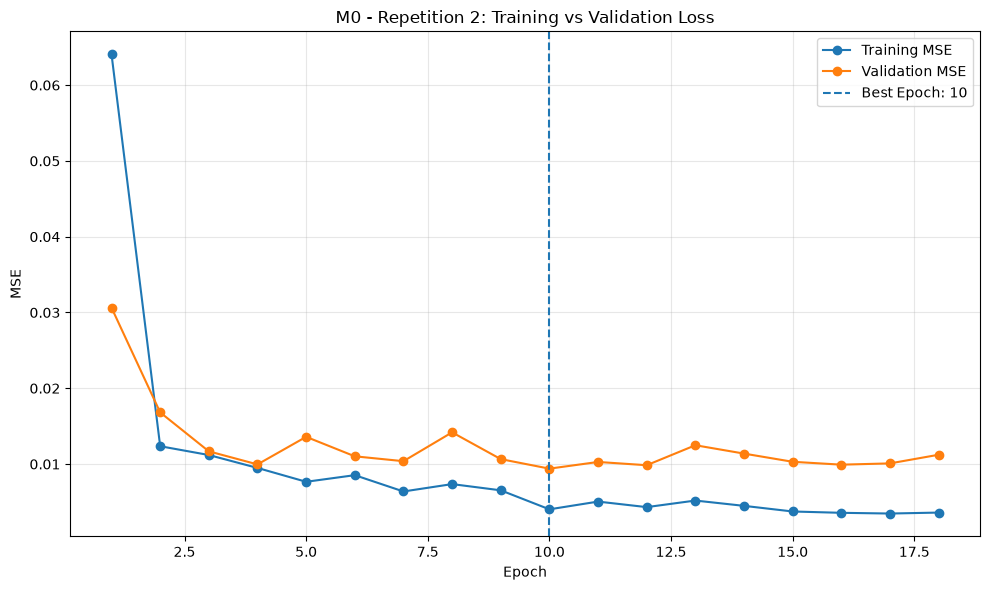

Loss curve saved successfully.
Best epoch: 10
Best validation MSE: 0.0093945966412623


In [90]:

import os
import matplotlib.pyplot as plt
import pandas as pd

results_dir = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "results"
)

history_path = os.path.join(
    results_dir, "m0_rep02_history.csv"
)

history_df = pd.read_csv(history_path)

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_mse"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    history_df["epoch"],
    history_df["val_mse"],
    marker="o",
    label="Validation MSE"
)

best_epoch = history_df.loc[
    history_df["val_mse"].idxmin(), "epoch"
]

best_val = history_df["val_mse"].min()

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("M0 - Repetition 2: Training vs Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "m0_rep02_loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss curve saved successfully.")
print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val)


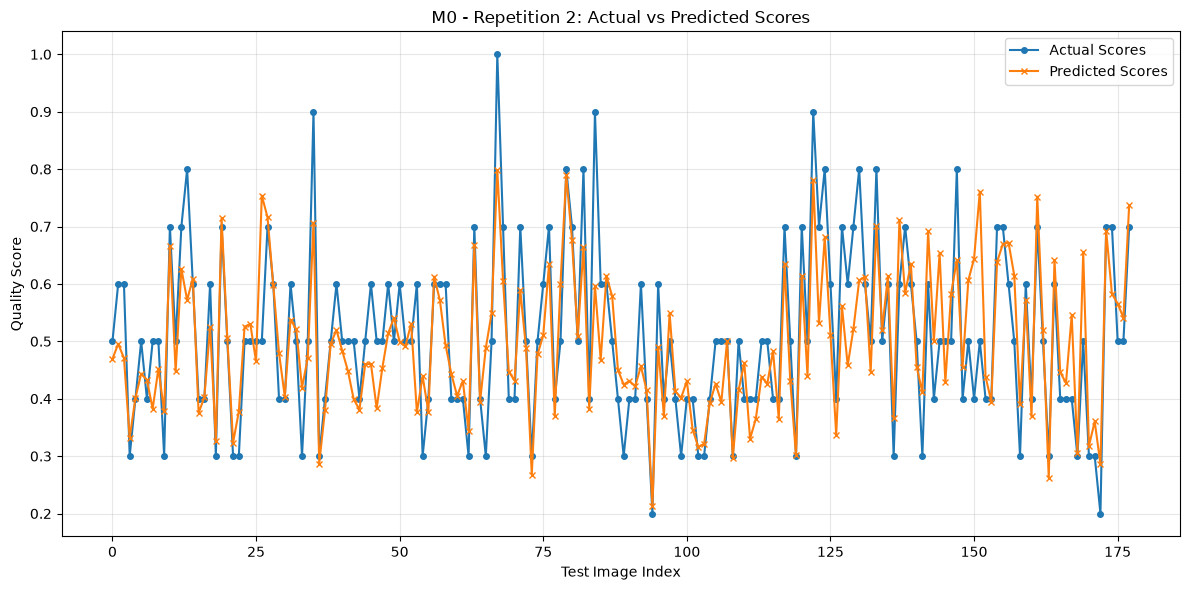

Actual vs Predicted plot saved successfully.


In [91]:

predictions_path = os.path.join(
    results_dir, "m0_rep02_predictions.csv"
)

predictions_df = pd.read_csv(predictions_path)

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(predictions_df)),
    predictions_df["Actual_Score"],
    label="Actual Scores",
    marker="o",
    markersize=4,
    linewidth=1.5
)

plt.plot(
    range(len(predictions_df)),
    predictions_df["Predicted_Score"],
    label="Predicted Scores",
    marker="x",
    markersize=4,
    linewidth=1.5
)

plt.xlabel("Test Image Index")
plt.ylabel("Quality Score")
plt.title("M0 - Repetition 2: Actual vs Predicted Scores")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "m0_rep02_actual_vs_predicted.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Actual vs Predicted plot saved successfully.")


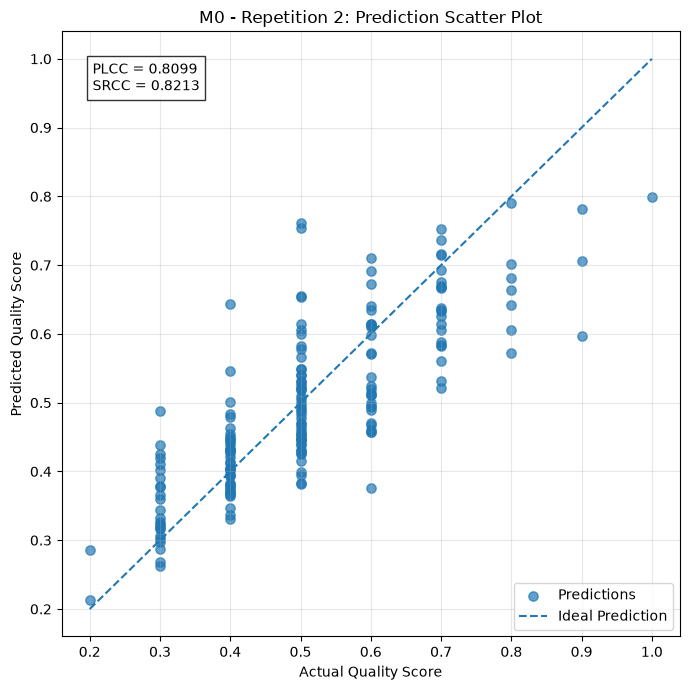

Scatter plot saved successfully.


In [92]:

import numpy as np
from scipy.stats import pearsonr, spearmanr

y_true = predictions_df["Actual_Score"].values
y_pred = predictions_df["Predicted_Score"].values

plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic

plt.figure(figsize=(7, 7))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.7,
    s=45,
    label="Predictions"
)

min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Quality Score")
plt.ylabel("Predicted Quality Score")

plt.title("M0 - Repetition 2: Prediction Scatter Plot")

plt.text(
    0.05, 0.95,
    f"PLCC = {plcc:.4f}\nSRCC = {srcc:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "m0_rep02_scatter_plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Scatter plot saved successfully.")


In [93]:

import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision.models import resnet50, ResNet50_Weights

# ==========================================
# 1. REPRODUCIBILITY
# ==========================================

SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 2. EXPERIMENT CONFIGURATION
# ==========================================

BASE_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments"

CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_EPOCHS = 50
PATIENCE = 8

BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

# ==========================================
# 3. M1 MODEL DEFINITION
# ==========================================

class M1PatchQualityNet(nn.Module):

    def __init__(self):

        super().__init__()

        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.backbone = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, x):

        B, C, H, W = x.shape

        # Divide image into four 112x112 patches

        p1 = x[:, :, :112, :112]
        p2 = x[:, :, :112, 112:]
        p3 = x[:, :, 112:, :112]
        p4 = x[:, :, 112:, 112:]

        # Combine patches along batch dimension

        patches = torch.cat(
            [p1, p2, p3, p4],
            dim=0
        )

        # Extract 2048-dimensional features

        features = self.backbone(patches)

        features = features.view(B, 4, 2048)

        # Average the four patch features

        image_features = features.mean(dim=1)

        # Predict image quality

        output = self.regressor(image_features)

        return output.squeeze(1)


# ==========================================
# 4. INITIALIZE MODEL
# ==========================================

m1_model = M1PatchQualityNet().to(device)

print("M1 model initialized.")
print("Device:", device)
print("Pretrained weights: IMAGENET1K_V1")
print("Patch count: 4")
print("Patch size: 112 x 112")


# ==========================================
# 5. LOSS AND OPTIMIZER
# ==========================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    [
        {
            "params": m1_model.backbone.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": m1_model.regressor.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ==========================================
# 6. TRAINING
# ==========================================

best_val_loss = float("inf")
early_stop_counter = 0

history = []

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "m1_rep02_best.pt"
)

history_path = os.path.join(
    RESULTS_DIR,
    "m1_rep02_history.csv"
)

for epoch in range(MAX_EPOCHS):

    start_time = time.time()

    # -------------------------
    # Training phase
    # -------------------------

    m1_model.train()

    train_losses = []

    for images, targets, filenames in train_loader:

        images = images.to(device)
        targets = targets.to(device).float()

        optimizer.zero_grad()

        outputs = m1_model(images)

        loss = criterion(outputs, targets)

        loss.backward()

        optimizer.step()

        train_losses.append(loss.item())

    train_loss = np.mean(train_losses)

    # -------------------------
    # Validation phase
    # -------------------------

    m1_model.eval()

    val_losses = []

    with torch.no_grad():

        for images, targets, filenames in val_loader:

            images = images.to(device)
            targets = targets.to(device).float()

            outputs = m1_model(images)

            loss = criterion(outputs, targets)

            val_losses.append(loss.item())

    val_loss = np.mean(val_losses)

    # -------------------------
    # Scheduler
    # -------------------------

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # -------------------------
    # Checkpoint saving
    # -------------------------

    is_best = val_loss < best_val_loss

    if is_best:

        best_val_loss = val_loss
        early_stop_counter = 0

        torch.save(
            {
                "model_state_dict": m1_model.state_dict(),
                "epoch": epoch + 1,
                "best_val_loss": best_val_loss,
                "seed": SEED,
                "learning_rate": BACKBONE_LR,
                "weight_decay": WEIGHT_DECAY,
                "model_name": "M1",
                "weights": "IMAGENET1K_V1"
            },
            checkpoint_path
        )

    else:

        early_stop_counter += 1

    # -------------------------
    # Record history
    # -------------------------

    history.append({
        "epoch": epoch + 1,
        "train_mse": train_loss,
        "val_mse": val_loss,
        "learning_rate": current_lr,
        "best_checkpoint_updated": is_best
    })

    elapsed = time.time() - start_time

    status = " | BEST" if is_best else ""

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_loss:.5f} | "
        f"Val MSE: {val_loss:.5f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s{status}"
    )

    # -------------------------
    # Early stopping
    # -------------------------

    if early_stop_counter >= PATIENCE:

        print(f"\nEarly stopping at epoch {epoch+1}.")
        break


# ==========================================
# 7. SAVE TRAINING HISTORY
# ==========================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    history_path,
    index=False
)

print("\nM1 Repetition 2 training finished.")
print(f"Best validation MSE: {best_val_loss:.6f}")
print("Checkpoint saved:", checkpoint_path)
print("History saved:", history_path)
print("Epochs completed:", len(history_df))


M1 model initialized.
Device: cuda
Pretrained weights: IMAGENET1K_V1
Patch count: 4
Patch size: 112 x 112
Epoch 01/50 | Train MSE: 0.07259 | Val MSE: 0.04068 | LR: 1.00e-04 | 29.6s | BEST
Epoch 02/50 | Train MSE: 0.02899 | Val MSE: 0.02470 | LR: 1.00e-04 | 30.3s | BEST
Epoch 03/50 | Train MSE: 0.03050 | Val MSE: 0.02749 | LR: 1.00e-04 | 30.4s
Epoch 04/50 | Train MSE: 0.02849 | Val MSE: 0.02626 | LR: 1.00e-04 | 30.6s
Epoch 05/50 | Train MSE: 0.02983 | Val MSE: 0.02968 | LR: 1.00e-04 | 31.2s
Epoch 06/50 | Train MSE: 0.02713 | Val MSE: 0.02266 | LR: 1.00e-04 | 30.8s | BEST
Epoch 07/50 | Train MSE: 0.03023 | Val MSE: 0.02481 | LR: 1.00e-04 | 30.8s
Epoch 08/50 | Train MSE: 0.02765 | Val MSE: 0.02870 | LR: 1.00e-04 | 30.9s
Epoch 09/50 | Train MSE: 0.02927 | Val MSE: 0.02580 | LR: 1.00e-04 | 29.8s
Epoch 10/50 | Train MSE: 0.02811 | Val MSE: 0.02430 | LR: 5.00e-05 | 30.8s
Epoch 11/50 | Train MSE: 0.02797 | Val MSE: 0.02424 | LR: 5.00e-05 | 31.1s
Epoch 12/50 | Train MSE: 0.02687 | Val MSE: 0.02

In [95]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

m1_model.load_state_dict(checkpoint["model_state_dict"])
m1_model.eval()

print("M1 checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

M1 checkpoint loaded successfully!
Best epoch: 6
Best validation loss: 0.022663528099656105


In [96]:

import os
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

# ==========================================
# 1. LOAD BEST CHECKPOINT
# ==========================================

checkpoint_path = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "checkpoints/m1_rep02_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

m1_model.load_state_dict(checkpoint["model_state_dict"])
m1_model.eval()

print("M1 checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])


# ==========================================
# 2. TESTING
# ==========================================

all_predictions = []
all_targets = []
all_filenames = []

with torch.no_grad():

    for images, targets, filenames in test_loader:

        images = images.to(device)

        outputs = m1_model(images)

        predictions = outputs.cpu().numpy()
        actual_scores = targets.cpu().numpy()

        all_predictions.extend(predictions)
        all_targets.extend(actual_scores)
        all_filenames.extend(filenames)


y_pred = np.array(all_predictions)
y_true = np.array(all_targets)


# ==========================================
# 3. EVALUATION METRICS
# ==========================================

plcc = pearsonr(y_true, y_pred).statistic

srcc = spearmanr(y_true, y_pred).statistic

krcc = kendalltau(y_true, y_pred).statistic

mse = mean_squared_error(y_true, y_pred)

rmse = np.sqrt(mse)


# ==========================================
# 4. DISPLAY RESULTS
# ==========================================

print("\n========== M1 | REPETITION 2 ==========")

print(f"PLCC : {plcc:.4f}")
print(f"SRCC : {srcc:.4f}")
print(f"KRCC : {krcc:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MSE  : {mse:.6f}")

print("=======================================")

print("Total test images:", len(y_true))


# ==========================================
# 5. SAVE METRICS
# ==========================================

results_dir = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "results"
)

os.makedirs(results_dir, exist_ok=True)

metrics_df = pd.DataFrame([{
    "Repetition": 2,
    "Model": "M1",
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MSE": mse
}])

metrics_path = os.path.join(
    results_dir,
    "m1_rep02_metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)


# ==========================================
# 6. SAVE PREDICTIONS
# ==========================================

predictions_df = pd.DataFrame({
    "Image": all_filenames,
    "Actual_Score": y_true,
    "Predicted_Score": y_pred
})

predictions_path = os.path.join(
    results_dir,
    "m1_rep02_predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)

print("\nMetrics saved:", metrics_path)
print("Predictions saved:", predictions_path)
print("\nM1 Repetition 2 evaluation completed!")


M1 checkpoint loaded successfully!
Best epoch: 6
Best validation loss: 0.022663528099656105

========== M1 | REPETITION 2 ==========
PLCC : 0.0862
SRCC : 0.0717
KRCC : 0.0526
RMSE : 0.1543
MSE  : 0.023806
Total test images: 178

Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep02_metrics.csv
Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep02_predictions.csv

M1 Repetition 2 evaluation completed!


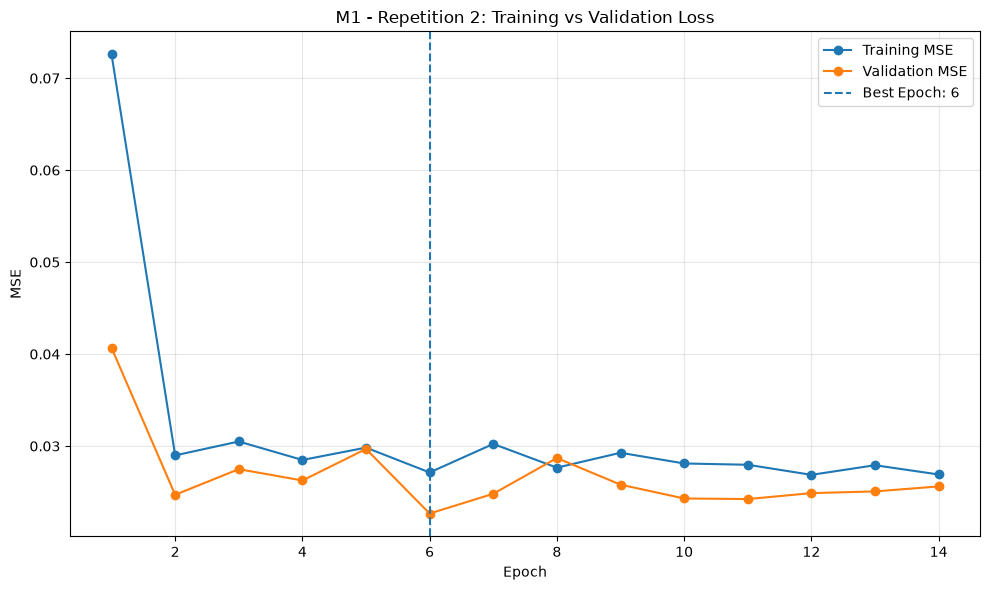

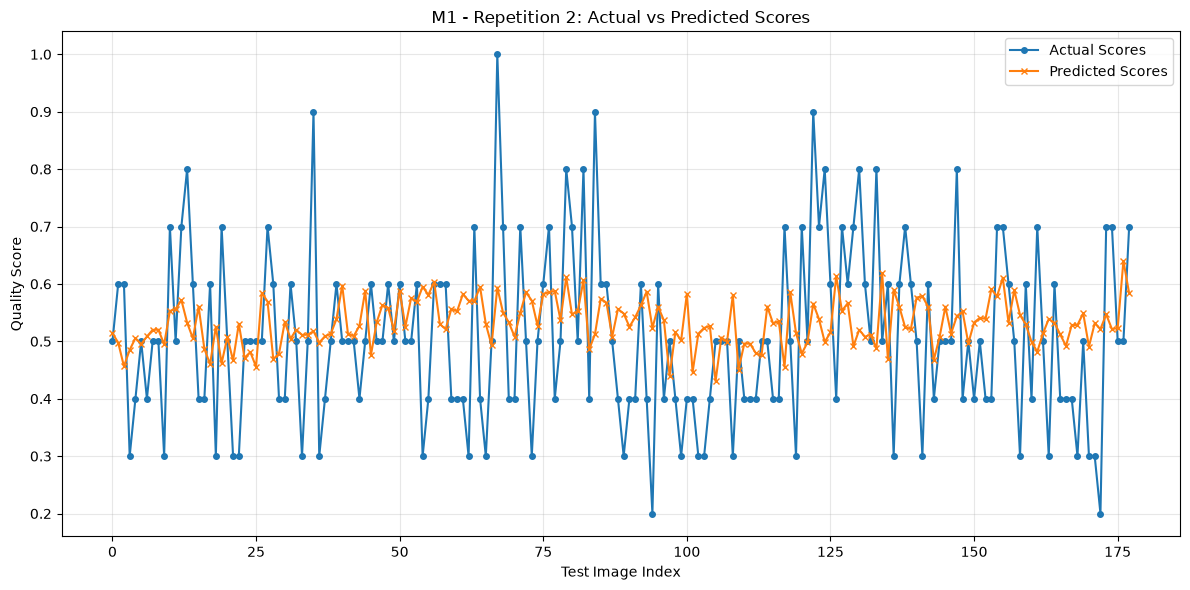

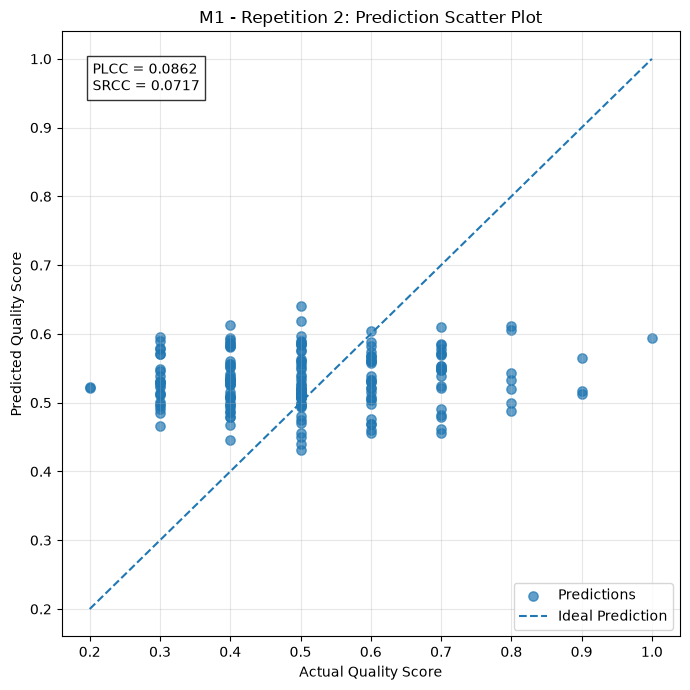


All three M1 Repetition 2 plots saved!
1. m1_rep02_loss_curve.png
2. m1_rep02_actual_vs_predicted.png
3. m1_rep02_scatter_plot.png


In [97]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD SAVED FILES
# ==========================================

results_dir = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "results"
)

history_df = pd.read_csv(
    os.path.join(results_dir, "m1_rep02_history.csv")
)

predictions_df = pd.read_csv(
    os.path.join(results_dir, "m1_rep02_predictions.csv")
)

y_true = predictions_df["Actual_Score"].values
y_pred = predictions_df["Predicted_Score"].values

# ==========================================
# 2. PLOT 1: TRAINING VS VALIDATION MSE
# ==========================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_mse"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    history_df["epoch"],
    history_df["val_mse"],
    marker="o",
    label="Validation MSE"
)

best_epoch = history_df.loc[
    history_df["val_mse"].idxmin(),
    "epoch"
]

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "M1 - Repetition 2: Training vs Validation Loss"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "m1_rep02_loss_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 3. PLOT 2: ACTUAL VS PREDICTED SCORES
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(y_true)),
    y_true,
    marker="o",
    markersize=4,
    label="Actual Scores"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="x",
    markersize=4,
    label="Predicted Scores"
)

plt.xlabel("Test Image Index")
plt.ylabel("Quality Score")

plt.title(
    "M1 - Repetition 2: Actual vs Predicted Scores"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "m1_rep02_actual_vs_predicted.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 4. PLOT 3: PREDICTION SCATTER PLOT
# ==========================================

from scipy.stats import pearsonr, spearmanr

plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic

plt.figure(figsize=(7, 7))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.7,
    s=45,
    label="Predictions"
)

min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Quality Score")
plt.ylabel("Predicted Quality Score")

plt.title(
    "M1 - Repetition 2: Prediction Scatter Plot"
)

plt.text(
    0.05,
    0.95,
    f"PLCC = {plcc:.4f}\nSRCC = {srcc:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "m1_rep02_scatter_plot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 5. COMPLETION
# ==========================================

print("\nAll three M1 Repetition 2 plots saved!")

print("1. m1_rep02_loss_curve.png")
print("2. m1_rep02_actual_vs_predicted.png")
print("3. m1_rep02_scatter_plot.png")


In [98]:
import pandas as pd
import numpy as np

pred_df = pd.read_csv(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep02_predictions.csv"
)

print("ACTUAL SCORE STATISTICS")
print(pred_df["Actual_Score"].describe())

print("\nPREDICTED SCORE STATISTICS")
print(pred_df["Predicted_Score"].describe())

print("\nSTANDARD DEVIATIONS")
print("Actual:", pred_df["Actual_Score"].std())
print("Predicted:", pred_df["Predicted_Score"].std())

print("\nFIRST 10 PREDICTIONS")
print(pred_df.head(10))

ACTUAL SCORE STATISTICS
count    178.000000
mean       0.507865
std        0.150873
min        0.200000
25%        0.400000
50%        0.500000
75%        0.600000
max        1.000000
Name: Actual_Score, dtype: float64

PREDICTED SCORE STATISTICS
count    178.000000
mean       0.531912
std        0.040677
min        0.430603
25%        0.506709
50%        0.529038
75%        0.560617
max        0.640023
Name: Predicted_Score, dtype: float64

STANDARD DEVIATIONS
Actual: 0.15087295444987708
Predicted: 0.04067738056266002

FIRST 10 PREDICTIONS
      Image  Actual_Score  Predicted_Score
0  0002.png           0.5         0.514182
1  0006.png           0.6         0.497718
2  0013.png           0.6         0.456525
3  0036.png           0.3         0.484986
4  0038.png           0.4         0.505665
5  0050.png           0.5         0.495131
6  0052.png           0.4         0.508436
7  0056.png           0.5         0.519958
8  0070.png           0.5         0.520278
9  0072.png           0

In [99]:
import pandas as pd

history_path = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "results/m1_rep02_history.csv"
)

history_df = pd.read_csv(history_path)

print("========== M1 REPETITION 2 TRAINING HISTORY ==========")

print("\nFirst 10 epochs:")
print(history_df.head(10).to_string(index=False))

print("\nLast 5 epochs:")
print(history_df.tail(5).to_string(index=False))

print("\nBest training loss:")
print(history_df["train_mse"].min())

print("\nBest validation loss:")
print(history_df["val_mse"].min())

print("\nEpoch with best validation loss:")
print(history_df.loc[history_df["val_mse"].idxmin()])

========== M1 REPETITION 2 TRAINING HISTORY ==========

First 10 epochs:
 epoch  train_mse  val_mse  learning_rate  best_checkpoint_updated
     1   0.072595 0.040678        0.00010                     True
     2   0.028986 0.024701        0.00010                     True
     3   0.030496 0.027490        0.00010                    False
     4   0.028488 0.026256        0.00010                    False
     5   0.029830 0.029684        0.00010                    False
     6   0.027129 0.022664        0.00010                     True
     7   0.030231 0.024813        0.00010                    False
     8   0.027651 0.028698        0.00010                    False
     9   0.029271 0.025803        0.00010                    False
    10   0.028107 0.024302        0.00005                    False

Last 5 epochs:
 epoch  train_mse  val_mse  learning_rate  best_checkpoint_updated
    10   0.028107 0.024302       0.000050                    False
    11   0.027966 0.024237       0.00005

In [100]:
import torch

checkpoint_path = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "checkpoints/m1_rep02_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:")
print(checkpoint.keys())

print("\nModel name:", checkpoint["model_name"])
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

print("\nModel parameter statistics:")

for name, param in checkpoint["model_state_dict"].items():
    if "regressor" in name:
        print(
            name,
            "| Mean:", param.float().mean().item(),
            "| Std:", param.float().std().item()
        )

Checkpoint keys:
dict_keys(['model_state_dict', 'epoch', 'best_val_loss', 'seed', 'learning_rate', 'weight_decay', 'model_name', 'weights'])

Model name: M1
Best epoch: 6
Best validation loss: 0.022663528099656105

Model parameter statistics:
regressor.0.weight | Mean: -0.0009848092449828982 | Std: 0.01158595085144043
regressor.0.bias | Mean: -0.0008805961697362363 | Std: 0.011386765167117119
regressor.3.weight | Mean: -0.002085332991555333 | Std: 0.0228391382843256
regressor.3.bias | Mean: 0.010067300871014595 | Std: nan


/tmp/ipykernel_331391/93130835.py:28: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1913.)
  "| Std:", param.float().std().item()


In [101]:
import torch
import numpy as np

m1_model.eval()

with torch.no_grad():
    images, targets, filenames = next(iter(test_loader))
    images = images.to(device)

    predictions = m1_model(images)

print("Checkpoint verification")
print("Prediction shape:", predictions.shape)
print("Prediction minimum:", predictions.min().item())
print("Prediction maximum:", predictions.max().item())
print("Prediction mean:", predictions.mean().item())
print("Prediction standard deviation:", predictions.std().item())

Checkpoint verification
Prediction shape: torch.Size([16])
Prediction minimum: 0.45652535557746887
Prediction maximum: 0.5718567371368408
Prediction mean: 0.5172944664955139
Prediction standard deviation: 0.030943075194954872


In [102]:
import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision.models import resnet50, ResNet50_Weights
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau


# ==========================================
# 1. REPRODUCIBILITY
# ==========================================

SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


# ==========================================
# 2. TRAINING CONFIGURATION
# ==========================================

MAX_EPOCHS = 50
PATIENCE = 8

BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ==========================================
# 3. CORRECTED M1 ARCHITECTURE
# ==========================================

class M1PatchAverageResNet(nn.Module):

    def __init__(self):
        super().__init__()

        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, images):

        batch_size = images.size(0)

        # Divide image into four patches
        top_left = images[:, :, :112, :112]
        top_right = images[:, :, :112, 112:]
        bottom_left = images[:, :, 112:, :112]
        bottom_right = images[:, :, 112:, 112:]

        # Concatenate patches along batch dimension
        patches = torch.cat(
            [top_left, top_right, bottom_left, bottom_right],
            dim=0
        )

        # Extract patch features
        patch_features = self.feature_extractor(patches)
        patch_features = patch_features.flatten(1)

        # IMPORTANT: Correct patch-to-image grouping
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Average four patches belonging to each image
        image_features = patch_features.mean(dim=1)

        # Predict quality score
        predictions = self.regressor(image_features)

        return predictions.squeeze(1)


# ==========================================
# 4. INITIALIZE FRESH MODEL
# ==========================================

m1_model = M1PatchAverageResNet().to(DEVICE)

criterion = nn.MSELoss()

optimizer = Adam(
    [
        {
            "params": m1_model.feature_extractor.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": m1_model.regressor.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ==========================================
# 5. SEPARATE OUTPUT PATHS
# ==========================================

PROJECT_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments"

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

M1_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "m1_rep02_corrected_best.pt"
)

M1_HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "m1_rep02_corrected_history.csv"
)

print("Corrected M1 model initialized!")
print("Device:", DEVICE)
print("Seed:", SEED)
print("Checkpoint:", M1_CHECKPOINT_PATH)
print("History:", M1_HISTORY_PATH)


# ==========================================
# 6. VERIFY MODEL OUTPUT
# ==========================================

m1_model.eval()

with torch.no_grad():

    sample_images, sample_scores, sample_names = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)

    sample_predictions = m1_model(sample_images)

print("Input shape:", sample_images.shape)
print("Prediction shape:", sample_predictions.shape)
print("Predictions finite:",
      torch.isfinite(sample_predictions).all().item())

assert sample_predictions.shape == sample_scores.shape


# ==========================================
# 7. TRAINING
# ==========================================

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

history = []

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    # -------------------------
    # Training
    # -------------------------

    m1_model.train()

    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:

        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float()

        optimizer.zero_grad(set_to_none=True)

        predictions = m1_model(images)

        loss = criterion(predictions, scores)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_loss = train_loss_sum / train_count


    # -------------------------
    # Validation
    # -------------------------

    m1_model.eval()

    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():

        for images, scores, _ in val_loader:

            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float()

            predictions = m1_model(images)

            loss = criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_loss = val_loss_sum / val_count

    scheduler.step(val_loss)

    current_lr_backbone = optimizer.param_groups[0]["lr"]
    current_lr_head = optimizer.param_groups[1]["lr"]

    improved = val_loss < best_val_loss

    if improved:

        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": m1_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "seed": SEED,
                "model_name": "M1_corrected",
                "weights": "IMAGENET1K_V1"
            },
            M1_CHECKPOINT_PATH
        )

    else:

        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_mse": train_loss,
        "val_mse": val_loss,
        "lr_backbone": current_lr_backbone,
        "lr_head": current_lr_head,
        "best_so_far": improved
    })

    pd.DataFrame(history).to_csv(
        M1_HISTORY_PATH,
        index=False
    )

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_loss:.6f} | "
        f"Val MSE: {val_loss:.6f} | "
        f"Backbone LR: {current_lr_backbone:.2e} | "
        f"Head LR: {current_lr_head:.2e} | "
        f"{'BEST' if improved else ''} | "
        f"{elapsed:.1f}s"
    )

    if epochs_without_improvement >= PATIENCE:

        print(f"\nEarly stopping at epoch {epoch}.")
        break


# ==========================================
# 8. TRAINING SUMMARY
# ==========================================

print("\nCorrected M1 training finished!")

print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val_loss)

print("Checkpoint saved:", M1_CHECKPOINT_PATH)
print("History saved:", M1_HISTORY_PATH)

Corrected M1 model initialized!
Device: cuda
Seed: 2028
Checkpoint: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints/m1_rep02_corrected_best.pt
History: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep02_corrected_history.csv
Input shape: torch.Size([16, 3, 224, 224])
Prediction shape: torch.Size([16])
Predictions finite: True
Epoch 01/50 | Train MSE: 0.068238 | Val MSE: 0.012873 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 30.2s
Epoch 02/50 | Train MSE: 0.011587 | Val MSE: 0.010479 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 31.6s
Epoch 03/50 | Train MSE: 0.009250 | Val MSE: 0.012472 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 30.5s
Epoch 04/50 | Train MSE: 0.008942 | Val MSE: 0.013583 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 30.4s
Epoch 05/50 | Train MSE: 0.011890 | Val MSE: 0.012192 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 30.1s
Epoch 06/50 | Train MSE: 0.010005 | Val MSE: 0.011469 | Backbone LR: 5.00e-05 | Head LR: 1.50

In [103]:

import os
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

experiment_dir = "/home/karthikbaskar2/UWIQA_Research_Experiments"

checkpoint_path = os.path.join(
    experiment_dir, "checkpoints", "m1_rep02_corrected_best.pt"
)

metrics_path = os.path.join(
    experiment_dir, "results", "m1_rep02_corrected_metrics.csv"
)

predictions_path = os.path.join(
    experiment_dir, "results", "m1_rep02_corrected_predictions.csv"
)

# --------------------------------------------------
# 2. Load the best corrected M1 checkpoint
# --------------------------------------------------

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

m1_corrected_model = M1PatchAverageResNet().to(device)

m1_corrected_model.load_state_dict(
    checkpoint["model_state_dict"]
)

m1_corrected_model.eval()

print("Corrected M1 checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation MSE:", checkpoint["best_val_loss"])

# --------------------------------------------------
# 3. Generate predictions on the test set
# --------------------------------------------------

actual_scores = []
predicted_scores = []
image_names = []

with torch.no_grad():

    for images, scores, filenames in test_loader:

        images = images.to(device)

        predictions = m1_corrected_model(images)

        actual_scores.extend(scores.cpu().numpy())
        predicted_scores.extend(predictions.cpu().numpy())
        image_names.extend(filenames)

actual_scores = np.array(actual_scores).flatten()
predicted_scores = np.array(predicted_scores).flatten()

# --------------------------------------------------
# 4. Calculate evaluation metrics
# --------------------------------------------------

plcc = pearsonr(actual_scores, predicted_scores)[0]
srcc = spearmanr(actual_scores, predicted_scores)[0]
krcc = kendalltau(actual_scores, predicted_scores)[0]

mse = mean_squared_error(actual_scores, predicted_scores)
rmse = np.sqrt(mse)

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("\n========== CORRECTED M1 - REPETITION 2 ==========")

print(f"Number of test images : {len(actual_scores)}")
print(f"PLCC                  : {plcc:.4f}")
print(f"SRCC                  : {srcc:.4f}")
print(f"KRCC                  : {krcc:.4f}")
print(f"RMSE                  : {rmse:.4f}")
print(f"MSE                   : {mse:.6f}")

# --------------------------------------------------
# 6. Save metrics
# --------------------------------------------------

metrics_df = pd.DataFrame([{
    "model": "M1_corrected",
    "repetition": 2,
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MSE": mse,
    "test_images": len(actual_scores)
}])

metrics_df.to_csv(metrics_path, index=False)

# --------------------------------------------------
# 7. Save individual predictions
# --------------------------------------------------

predictions_df = pd.DataFrame({
    "image": image_names,
    "actual_score": actual_scores,
    "predicted_score": predicted_scores
})

predictions_df.to_csv(predictions_path, index=False)

print("\nEvaluation completed successfully!")
print("Metrics saved:", metrics_path)
print("Predictions saved:", predictions_path)

display(metrics_df.head())
display(predictions_df.head())


Corrected M1 checkpoint loaded!
Best epoch: 7
Best validation MSE: 0.010364746778375573

========== CORRECTED M1 - REPETITION 2 ==========
Number of test images : 178
PLCC                  : 0.8252
SRCC                  : 0.8411
KRCC                  : 0.7041
RMSE                  : 0.0857
MSE                   : 0.007339

Evaluation completed successfully!
Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep02_corrected_metrics.csv
Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep02_corrected_predictions.csv


,model,repetition,PLCC,SRCC,KRCC,RMSE,MSE,test_images
0,M1_corrected,2,0.825232,0.841133,0.704124,0.085669,0.007339,178


,image,actual_score,predicted_score
0,0002.png,0.5,0.514288
1,0006.png,0.6,0.515856
2,0013.png,0.6,0.419818
3,0036.png,0.3,0.326951
4,0038.png,0.4,0.382160


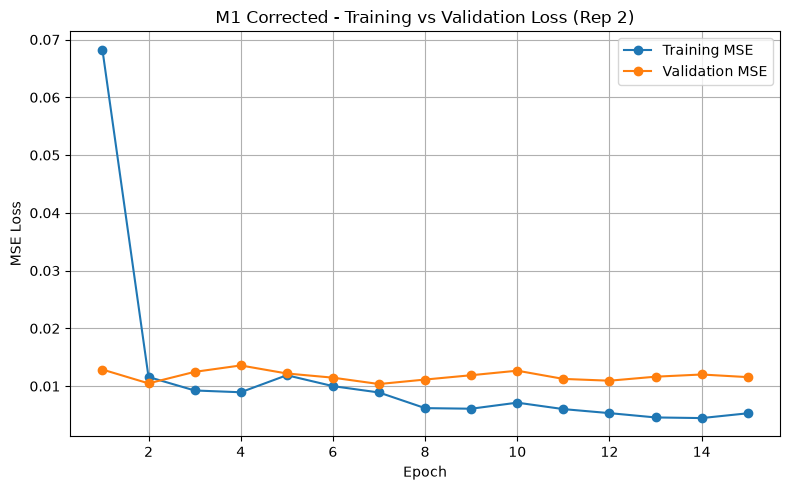

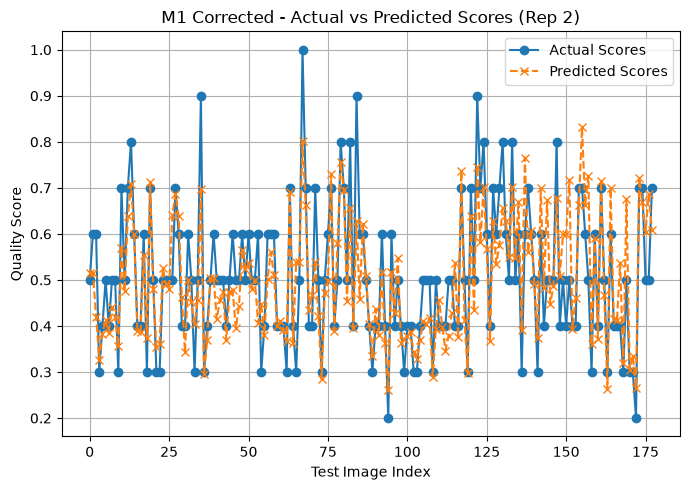

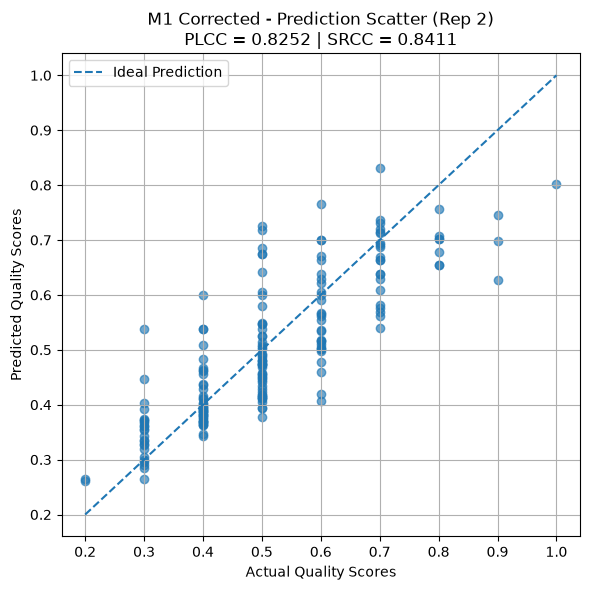


All three corrected M1 plots saved successfully!
1. m1_rep02_corrected_loss_curve.png
2. m1_rep02_corrected_actual_vs_predicted.png
3. m1_rep02_corrected_scatter_plot.png


In [104]:

import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load corrected training history
# --------------------------------------------------

history_path = os.path.join(
    experiment_dir, "results", "m1_rep02_corrected_history.csv"
)

history_df = pd.read_csv(history_path)

# Plot output directory
results_dir = os.path.join(experiment_dir, "results")

# --------------------------------------------------
# PLOT 1: Training vs Validation Loss
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_mse"],
    label="Training MSE",
    marker="o"
)

plt.plot(
    history_df["epoch"],
    history_df["val_mse"],
    label="Validation MSE",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("M1 Corrected - Training vs Validation Loss (Rep 2)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "m1_rep02_corrected_loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------
# PLOT 2: Actual vs Predicted Scores
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    range(len(actual_scores)),
    actual_scores,
    label="Actual Scores",
    marker="o",
    linestyle="-"
)

plt.plot(
    range(len(predicted_scores)),
    predicted_scores,
    label="Predicted Scores",
    marker="x",
    linestyle="--"
)

plt.xlabel("Test Image Index")
plt.ylabel("Quality Score")
plt.title("M1 Corrected - Actual vs Predicted Scores (Rep 2)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "m1_rep02_corrected_actual_vs_predicted.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------
# PLOT 3: Prediction Scatter Plot
# --------------------------------------------------

plt.figure(figsize=(6, 6))

plt.scatter(
    actual_scores,
    predicted_scores,
    alpha=0.65
)

min_value = min(actual_scores.min(), predicted_scores.min())
max_value = max(actual_scores.max(), predicted_scores.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Quality Scores")
plt.ylabel("Predicted Quality Scores")

plt.title(
    f"M1 Corrected - Prediction Scatter (Rep 2)\n"
    f"PLCC = {plcc:.4f} | SRCC = {srcc:.4f}"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "m1_rep02_corrected_scatter_plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nAll three corrected M1 plots saved successfully!")

print("1. m1_rep02_corrected_loss_curve.png")
print("2. m1_rep02_corrected_actual_vs_predicted.png")
print("3. m1_rep02_corrected_scatter_plot.png")


In [105]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from torchvision.models import resnet50, ResNet50_Weights

# --------------------------------------------------
# 1. Repetition 2 reproducibility
# --------------------------------------------------

SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --------------------------------------------------
# 2. Confirm the active split is Repetition 2
# --------------------------------------------------

assert len(train_loader.dataset) == 640, "Unexpected training split size!"
assert len(val_loader.dataset) == 72, "Unexpected validation split size!"
assert len(test_loader.dataset) == 178, "Unexpected test split size!"

print("Repetition 2 split verified.")
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))

# --------------------------------------------------
# 3. Define M2: Patch Attention ResNet
# --------------------------------------------------

class M2PatchAttentionResNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Pretrained ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # Learn attention scores for the four patches
        self.attention = nn.Sequential(
            nn.Linear(2048, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )

        # Final quality regression head
        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, images):

        batch_size = images.size(0)

        # Divide each image into four 112 x 112 patches
        top_left = images[:, :, :112, :112]
        top_right = images[:, :, :112, 112:]
        bottom_left = images[:, :, 112:, :112]
        bottom_right = images[:, :, 112:, 112:]

        # Combine patches along the batch dimension
        patches = torch.cat(
            [top_left, top_right, bottom_left, bottom_right],
            dim=0
        )

        # Extract features from each patch
        patch_features = self.feature_extractor(
            patches
        ).flatten(1)

        # Restore batch and patch dimensions
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Calculate attention scores
        attention_scores = self.attention(
            patch_features
        ).squeeze(-1)

        # Convert scores into attention weights
        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # Weighted combination of patch features
        image_features = torch.sum(
            patch_features * attention_weights.unsqueeze(-1),
            dim=1
        )

        # Predict one quality score per image
        predictions = self.regressor(
            image_features
        ).squeeze(-1)

        return predictions


# --------------------------------------------------
# 4. Initialize the model AFTER setting the seed
# --------------------------------------------------

m2_model = M2PatchAttentionResNet().to(DEVICE)

print("\nM2 model initialized successfully!")
print("Device:", DEVICE)
print("Seed:", SEED)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in m2_model.parameters()
        if p.requires_grad
    )
)

# --------------------------------------------------
# 5. Test the output shape
# --------------------------------------------------

m2_model.eval()

with torch.no_grad():

    sample_images, sample_scores, sample_names = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)

    sample_predictions = m2_model(sample_images)

print("\nInput shape:", sample_images.shape)
print("Target shape:", sample_scores.shape)
print("Prediction shape:", sample_predictions.shape)

print(
    "Predictions finite:",
    torch.isfinite(sample_predictions).all().item()
)

assert sample_predictions.shape == sample_scores.shape
assert torch.isfinite(sample_predictions).all()

print("\nM2 initialization checks: PASS")


Repetition 2 split verified.
Train: 640
Validation: 72
Test: 178

M2 model initialized successfully!
Device: cuda
Seed: 2028
Trainable parameters: 25082434

Input shape: torch.Size([16, 3, 224, 224])
Target shape: torch.Size([16])
Prediction shape: torch.Size([16])
Predictions finite: True

M2 initialization checks: PASS


In [106]:

import time
import pandas as pd
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# --------------------------------------------------
# 1. Training configuration
# --------------------------------------------------

MAX_EPOCHS = 50
PATIENCE = 8

BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

# --------------------------------------------------
# 2. Experiment directories
# --------------------------------------------------

PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

M2_CHECKPOINT_PATH = (
    CHECKPOINT_DIR / "m2_rep02_best.pt"
)

M2_HISTORY_PATH = (
    RESULTS_DIR / "m2_rep02_history.csv"
)

# Protect any existing experiment results
if M2_CHECKPOINT_PATH.exists() or M2_HISTORY_PATH.exists():
    raise FileExistsError(
        "An M2 Rep 2 checkpoint or history already exists. "
        "Do not overwrite it. Check the existing files first."
    )

# --------------------------------------------------
# 3. Optimizer
# --------------------------------------------------

m2_optimizer = Adam(
    [
        {
            "params": m2_model.feature_extractor.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": (
                list(m2_model.attention.parameters())
                + list(m2_model.regressor.parameters())
            ),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

m2_criterion = nn.MSELoss()

m2_scheduler = ReduceLROnPlateau(
    m2_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("M2 training configuration ready.")
print("Device:", DEVICE)
print("Seed:", SEED)
print("Maximum epochs:", MAX_EPOCHS)
print("Backbone LR:", BACKBONE_LR)
print("Attention/head LR:", HEAD_LR)
print("Checkpoint:", M2_CHECKPOINT_PATH)
print("History:", M2_HISTORY_PATH)

# --------------------------------------------------
# 4. Training loop
# --------------------------------------------------

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

m2_history = []

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    # -------------------------
    # Training phase
    # -------------------------

    m2_model.train()

    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:

        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float()

        m2_optimizer.zero_grad(set_to_none=True)

        predictions = m2_model(images)

        loss = m2_criterion(predictions, scores)

        loss.backward()

        m2_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_mse = train_loss_sum / train_count

    # -------------------------
    # Validation phase
    # -------------------------

    m2_model.eval()

    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():

        for images, scores, _ in val_loader:

            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float()

            predictions = m2_model(images)

            loss = m2_criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_mse = val_loss_sum / val_count

    # -------------------------
    # Learning rate scheduler
    # -------------------------

    m2_scheduler.step(val_mse)

    current_backbone_lr = m2_optimizer.param_groups[0]["lr"]
    current_head_lr = m2_optimizer.param_groups[1]["lr"]

    # -------------------------
    # Save best checkpoint
    # -------------------------

    improved = val_mse < best_val_loss

    if improved:

        best_val_loss = val_mse
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": m2_model.state_dict(),
                "optimizer_state_dict": m2_optimizer.state_dict(),
                "best_val_mse": best_val_loss,
                "seed": SEED,
                "model_name": "M2PatchAttentionResNet",
                "backbone_lr": BACKBONE_LR,
                "head_lr": HEAD_LR,
                "weight_decay": WEIGHT_DECAY
            },
            M2_CHECKPOINT_PATH
        )

    else:
        epochs_without_improvement += 1

    # -------------------------
    # Record training history
    # -------------------------

    m2_history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "lr_backbone": current_backbone_lr,
        "lr_head": current_head_lr,
        "best_so_far": best_val_loss,
        "best_checkpoint_updated": improved
    })

    # Save history after every epoch
    pd.DataFrame(m2_history).to_csv(
        M2_HISTORY_PATH,
        index=False
    )

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Backbone LR: {current_backbone_lr:.2e} | "
        f"Head LR: {current_head_lr:.2e} | "
        f"{'BEST' if improved else ''} | "
        f"{elapsed:.1f}s"
    )

    # -------------------------
    # Early stopping
    # -------------------------

    if epochs_without_improvement >= PATIENCE:

        print(f"\nEarly stopping at epoch {epoch}.")
        break

# --------------------------------------------------
# 5. Load the best checkpoint
# --------------------------------------------------

checkpoint = torch.load(
    M2_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m2_model.load_state_dict(
    checkpoint["model_state_dict"]
)

m2_model.eval()

print("\nM2 training completed successfully!")
print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation MSE:",
    checkpoint["best_val_mse"]
)
print("Checkpoint saved:", M2_CHECKPOINT_PATH)
print("History saved:", M2_HISTORY_PATH)


M2 training configuration ready.
Device: cuda
Seed: 2028
Maximum epochs: 50
Backbone LR: 0.0001
Attention/head LR: 0.0003
Checkpoint: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints/m2_rep02_best.pt
History: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep02_history.csv
Epoch 01/50 | Train MSE: 0.095509 | Val MSE: 0.014450 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 31.4s
Epoch 02/50 | Train MSE: 0.011302 | Val MSE: 0.013095 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 31.3s
Epoch 03/50 | Train MSE: 0.009411 | Val MSE: 0.012430 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 30.6s
Epoch 04/50 | Train MSE: 0.008476 | Val MSE: 0.012453 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 30.0s
Epoch 05/50 | Train MSE: 0.007791 | Val MSE: 0.014307 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 |  | 29.9s
Epoch 06/50 | Train MSE: 0.009466 | Val MSE: 0.011812 | Backbone LR: 1.00e-04 | Head LR: 3.00e-04 | BEST | 30.6s
Epoch 07/50 | Train MSE: 0.007595

In [107]:

import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

# --------------------------------------------------
# 1. Load best checkpoint
# --------------------------------------------------

checkpoint = torch.load(
    M2_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m2_model.load_state_dict(
    checkpoint["model_state_dict"]
)

m2_model.eval()

print("Best M2 checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation MSE:", checkpoint["best_val_mse"])

# --------------------------------------------------
# 2. Predict on test set
# --------------------------------------------------

y_true = []
y_pred = []
filenames = []

with torch.no_grad():

    for images, scores, names in test_loader:

        images = images.to(DEVICE)

        predictions = m2_model(images)

        y_true.extend(scores.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        filenames.extend(names)

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

# --------------------------------------------------
# 3. Validate predictions
# --------------------------------------------------

assert len(y_true) == 178
assert len(y_pred) == 178
assert len(filenames) == 178

assert np.isfinite(y_true).all()
assert np.isfinite(y_pred).all()

# --------------------------------------------------
# 4. Calculate metrics
# --------------------------------------------------

plcc = pearsonr(y_true, y_pred).statistic
srcc = spearmanr(y_true, y_pred).statistic
krcc = kendalltau(
    y_true,
    y_pred,
    variant="b"
).statistic

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("\n========== M2 - REPETITION 2 ==========")

print("Test images:", len(y_true))
print(f"PLCC : {plcc:.4f}")
print(f"SRCC : {srcc:.4f}")
print(f"KRCC : {krcc:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MSE  : {mse:.6f}")

# --------------------------------------------------
# 6. Save metrics
# --------------------------------------------------

m2_metrics = pd.DataFrame([{
    "model": "M2",
    "repetition": 2,
    "best_epoch": checkpoint["epoch"],
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MSE": mse,
    "test_images": len(y_true)
}])

metrics_path = (
    RESULTS_DIR / "m2_rep02_metrics.csv"
)

m2_metrics.to_csv(
    metrics_path,
    index=False
)

# --------------------------------------------------
# 7. Save individual predictions
# --------------------------------------------------

m2_predictions = pd.DataFrame({
    "image": filenames,
    "actual_score": y_true,
    "predicted_score": y_pred
})

predictions_path = (
    RESULTS_DIR / "m2_rep02_predictions.csv"
)

m2_predictions.to_csv(
    predictions_path,
    index=False
)

print("\nEvaluation completed successfully!")
print("Metrics saved:", metrics_path)
print("Predictions saved:", predictions_path)

display(m2_metrics.round(6))
display(m2_predictions.head())


Best M2 checkpoint loaded!
Best epoch: 6
Best validation MSE: 0.011812491601126062

========== M2 - REPETITION 2 ==========
Test images: 178
PLCC : 0.7494
SRCC : 0.7349
KRCC : 0.5901
RMSE : 0.1007
MSE  : 0.010138

Evaluation completed successfully!
Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep02_metrics.csv
Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep02_predictions.csv


,model,repetition,best_epoch,PLCC,SRCC,KRCC,RMSE,MSE,test_images
0,M2,2,6,0.749433,0.734944,0.590139,0.100686,0.010138,178


,image,actual_score,predicted_score
0,0002.png,0.5,0.434476
1,0006.png,0.6,0.605741
2,0013.png,0.6,0.490821
3,0036.png,0.3,0.370055
4,0038.png,0.4,0.496574


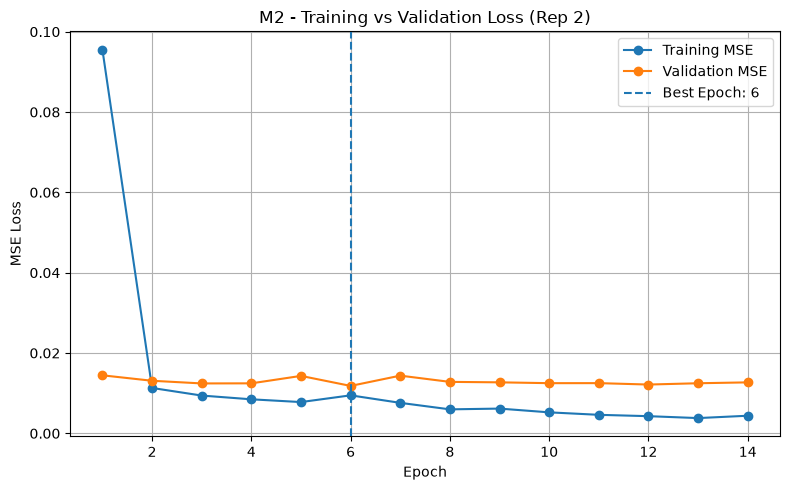

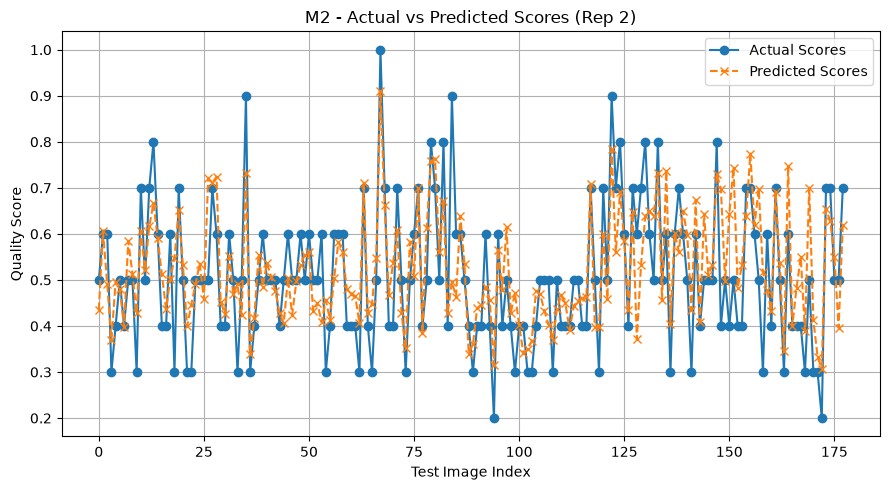

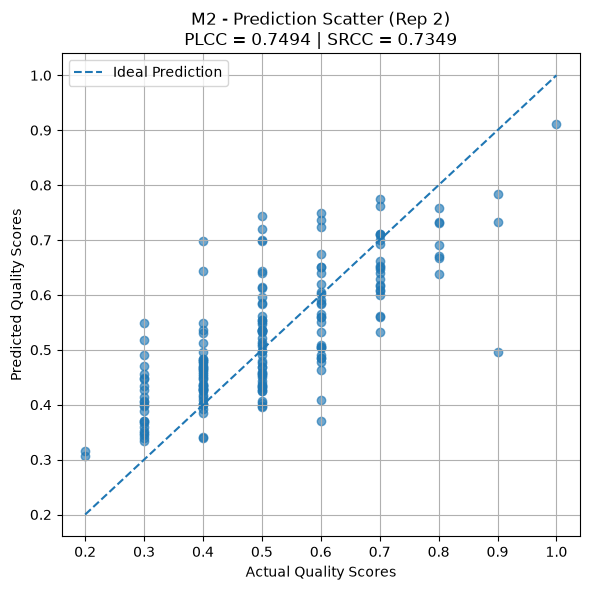


All three M2 plots saved successfully!
1. m2_rep02_loss_curve.png
2. m2_rep02_actual_vs_predicted.png
3. m2_rep02_scatter_plot.png


In [108]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --------------------------------------------------
# Load training history
# --------------------------------------------------

m2_history_df = pd.read_csv(
    M2_HISTORY_PATH
)

# --------------------------------------------------
# Plot 1: Training vs Validation Loss
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    m2_history_df["epoch"],
    m2_history_df["train_mse"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    m2_history_df["epoch"],
    m2_history_df["val_mse"],
    marker="o",
    label="Validation MSE"
)

best_epoch = int(checkpoint["epoch"])

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "M2 - Training vs Validation Loss (Rep 2)"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "m2_rep02_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------
# Plot 2: Actual vs Predicted Scores
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(len(y_true)),
    y_true,
    label="Actual Scores",
    marker="o",
    linestyle="-"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    label="Predicted Scores",
    marker="x",
    linestyle="--"
)

plt.xlabel("Test Image Index")
plt.ylabel("Quality Score")

plt.title(
    "M2 - Actual vs Predicted Scores (Rep 2)"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "m2_rep02_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------
# Plot 3: Prediction Scatter Plot
# --------------------------------------------------

plt.figure(figsize=(6, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.65
)

min_value = min(y_true.min(), y_pred.min())
max_value = max(y_true.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Quality Scores")
plt.ylabel("Predicted Quality Scores")

plt.title(
    f"M2 - Prediction Scatter (Rep 2)\n"
    f"PLCC = {plcc:.4f} | SRCC = {srcc:.4f}"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "m2_rep02_scatter_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nAll three M2 plots saved successfully!")

print("1. m2_rep02_loss_curve.png")
print("2. m2_rep02_actual_vs_predicted.png")
print("3. m2_rep02_scatter_plot.png")


In [109]:
import random
import numpy as np
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights
from pathlib import Path

# --------------------------------------------------
# 1. Reproducibility — set seed BEFORE model creation
# --------------------------------------------------
SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --------------------------------------------------
# 2. M3 Architecture — same as Repetition 1
# --------------------------------------------------
class M3SaliencyAwareResNet(nn.Module):
    def __init__(self):
        super().__init__()

        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

        self.register_buffer(
            "rgb_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "rgb_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, images):

        batch_size = images.size(0)

        # Recover approximate RGB values
        rgb = images * self.rgb_std + self.rgb_mean
        rgb = rgb.clamp(0, 1)

        # Calculate global colour mean
        global_color_mean = rgb.mean(
            dim=(2, 3), keepdim=True
        )

        # Generate saliency map
        saliency_map = torch.sqrt(
            ((rgb - global_color_mean) ** 2).mean(
                dim=1, keepdim=True
            ) + 1e-8
        )

        # Divide image into four quadrants
        image_patches = [
            images[:, :, :112, :112],
            images[:, :, :112, 112:],
            images[:, :, 112:, :112],
            images[:, :, 112:, 112:]
        ]

        # Divide saliency map into the same quadrants
        saliency_patches = [
            saliency_map[:, :, :112, :112],
            saliency_map[:, :, :112, 112:],
            saliency_map[:, :, 112:, :112],
            saliency_map[:, :, 112:, 112:]
        ]

        # Calculate saliency score for each quadrant
        saliency_scores = torch.stack(
            [p.mean(dim=(1, 2, 3)) for p in saliency_patches],
            dim=1
        )

        # Calculate patch importance weights
        saliency_weights = torch.softmax(
            saliency_scores, dim=1
        )

        # Extract ResNet features from all patches
        patches = torch.cat(image_patches, dim=0)

        patch_features = self.feature_extractor(
            patches
        ).flatten(1)

        # Group features by original image
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Saliency-weighted feature aggregation
        image_features = torch.sum(
            patch_features * saliency_weights.unsqueeze(-1),
            dim=1
        )

        # Predict quality score
        predictions = self.regressor(
            image_features
        ).squeeze(-1)

        return predictions


# --------------------------------------------------
# 3. Initialize model
# --------------------------------------------------
m3_model = M3SaliencyAwareResNet().to(DEVICE)

# --------------------------------------------------
# 4. Verify existing Repetition 2 loaders
# --------------------------------------------------
assert len(train_loader.dataset) == 640
assert len(val_loader.dataset) == 72
assert len(test_loader.dataset) == 178

m3_model.eval()

with torch.no_grad():
    sample_images, sample_scores, sample_names = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)
    sample_predictions = m3_model(sample_images)

print("Device:", DEVICE)
print("Input shape:", sample_images.shape)
print("Output shape:", sample_predictions.shape)
print("Sample predictions:", sample_predictions[:5].cpu())
print("Predictions finite:",
      torch.isfinite(sample_predictions).all().item())

print("Total parameters:",
      sum(p.numel() for p in m3_model.parameters()))

Device: cuda
Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16])
Sample predictions: tensor([-0.3691, -0.2988, -0.2373, -0.3461, -0.2697])
Predictions finite: True
Total parameters: 24557633


In [110]:
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

MAX_EPOCHS = 50
PATIENCE = 8

BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

m3_optimizer = Adam(
    [
        {
            "params": m3_model.feature_extractor.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": m3_model.regressor.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

m3_criterion = nn.MSELoss()

m3_scheduler = ReduceLROnPlateau(
    m3_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# Repetition 2 paths
PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

M3_CHECKPOINT_PATH = (
    CHECKPOINT_DIR / "m3_rep02_best.pt"
)

M3_HISTORY_PATH = (
    RESULTS_DIR / "m3_rep02_history.csv"
)

# Protect existing experiment files
if M3_CHECKPOINT_PATH.exists():
    raise FileExistsError(
        f"Checkpoint already exists: {M3_CHECKPOINT_PATH}"
    )

if M3_HISTORY_PATH.exists():
    raise FileExistsError(
        f"History already exists: {M3_HISTORY_PATH}"
    )

print("M3 training configuration ready.")
print("Seed:", SEED)
print("Maximum epochs:", MAX_EPOCHS)
print("Backbone LR:", BACKBONE_LR)
print("Head LR:", HEAD_LR)
print("Checkpoint:", M3_CHECKPOINT_PATH)
print("History:", M3_HISTORY_PATH)

M3 training configuration ready.
Seed: 2028
Maximum epochs: 50
Backbone LR: 0.0001
Head LR: 0.0003
Checkpoint: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints/m3_rep02_best.pt
History: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep02_history.csv


In [111]:
import time
import pandas as pd

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

m3_history = []

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    # -------------------------------
    # Training
    # -------------------------------
    m3_model.train()

    train_loss_sum = 0.0
    train_count = 0

    for images, scores, _ in train_loader:

        images = images.to(DEVICE)
        scores = scores.to(DEVICE).float()

        m3_optimizer.zero_grad()

        predictions = m3_model(images)
        loss = m3_criterion(predictions, scores)

        loss.backward()
        m3_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_mse = train_loss_sum / train_count

    # -------------------------------
    # Validation
    # -------------------------------
    m3_model.eval()

    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():

        for images, scores, _ in val_loader:

            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float()

            predictions = m3_model(images)
            loss = m3_criterion(predictions, scores)

            val_loss_sum += loss.item() * images.size(0)
            val_count += images.size(0)

    val_mse = val_loss_sum / val_count

    m3_scheduler.step(val_mse)

    # -------------------------------
    # Save best checkpoint
    # -------------------------------
    if val_mse < best_val_loss:

        best_val_loss = val_mse
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": m3_model.state_dict(),
                "optimizer_state_dict": m3_optimizer.state_dict(),
                "best_val_mse": best_val_loss,
                "seed": SEED,
                "model_name": "M3",
                "repetition": 2
            },
            M3_CHECKPOINT_PATH
        )

    else:
        epochs_without_improvement += 1

    # -------------------------------
    # Record history
    # -------------------------------
    m3_history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "lr_backbone": m3_optimizer.param_groups[0]["lr"],
        "lr_head": m3_optimizer.param_groups[1]["lr"],
        "best_so_far": best_val_loss
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Best Val: {best_val_loss:.6f} "
        f"(Epoch {best_epoch}) | "
        f"Time: {elapsed:.1f}s"
    )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print(f"\nEarly stopping at epoch {epoch}.")
        break


# Save training history
pd.DataFrame(m3_history).to_csv(
    M3_HISTORY_PATH,
    index=False
)

# Restore best checkpoint
checkpoint = torch.load(
    M3_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m3_model.load_state_dict(
    checkpoint["model_state_dict"]
)

m3_model.eval()

print("\nM3 training complete.")
print("Best epoch:", checkpoint["epoch"])
print(
    f"Best validation MSE: "
    f"{checkpoint['best_val_mse']:.6f}"
)
print("Checkpoint saved:", M3_CHECKPOINT_PATH)
print("History saved:", M3_HISTORY_PATH)

Epoch 01/50 | Train MSE: 0.068470 | Val MSE: 0.012265 | Best Val: 0.012265 (Epoch 1) | Time: 29.7s
Epoch 02/50 | Train MSE: 0.011754 | Val MSE: 0.011150 | Best Val: 0.011150 (Epoch 2) | Time: 31.2s
Epoch 03/50 | Train MSE: 0.010073 | Val MSE: 0.013470 | Best Val: 0.011150 (Epoch 2) | Time: 31.4s
Epoch 04/50 | Train MSE: 0.009175 | Val MSE: 0.016696 | Best Val: 0.011150 (Epoch 2) | Time: 30.8s
Epoch 05/50 | Train MSE: 0.011903 | Val MSE: 0.014141 | Best Val: 0.011150 (Epoch 2) | Time: 30.1s
Epoch 06/50 | Train MSE: 0.009651 | Val MSE: 0.012369 | Best Val: 0.011150 (Epoch 2) | Time: 29.6s
Epoch 07/50 | Train MSE: 0.007803 | Val MSE: 0.011291 | Best Val: 0.011150 (Epoch 2) | Time: 29.8s
Epoch 08/50 | Train MSE: 0.006167 | Val MSE: 0.012261 | Best Val: 0.011150 (Epoch 2) | Time: 29.8s
Epoch 09/50 | Train MSE: 0.005880 | Val MSE: 0.012028 | Best Val: 0.011150 (Epoch 2) | Time: 30.3s
Epoch 10/50 | Train MSE: 0.006774 | Val MSE: 0.012294 | Best Val: 0.011150 (Epoch 2) | Time: 30.9s

Early sto

In [112]:
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

# Load best M3 checkpoint
checkpoint = torch.load(
    M3_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

m3_model.load_state_dict(checkpoint["model_state_dict"])
m3_model.eval()

actual_scores = []
predicted_scores = []
image_names = []

# Test evaluation
with torch.no_grad():

    for images, scores, filenames in test_loader:

        images = images.to(DEVICE)

        predictions = m3_model(images)

        actual_scores.extend(scores.cpu().numpy())
        predicted_scores.extend(predictions.cpu().numpy())
        image_names.extend(filenames)

actual_scores = np.array(actual_scores).flatten()
predicted_scores = np.array(predicted_scores).flatten()

# Integrity checks
assert len(actual_scores) == 178
assert len(predicted_scores) == 178
assert len(image_names) == 178

assert np.isfinite(actual_scores).all()
assert np.isfinite(predicted_scores).all()

# Calculate metrics
plcc = pearsonr(actual_scores, predicted_scores)[0]
srcc = spearmanr(actual_scores, predicted_scores)[0]
krcc = kendalltau(
    actual_scores,
    predicted_scores,
    variant="b"
)[0]

mse = mean_squared_error(actual_scores, predicted_scores)
rmse = np.sqrt(mse)

# Display results
print("M3 — Repetition 2 Test Results")
print("--------------------------------")
print(f"Test Images : {len(actual_scores)}")
print(f"PLCC        : {plcc:.6f}")
print(f"SRCC        : {srcc:.6f}")
print(f"KRCC        : {krcc:.6f}")
print(f"RMSE        : {rmse:.6f}")
print(f"MSE         : {mse:.6f}")

# Save metrics
metrics_df = pd.DataFrame([{
    "Model": "M3",
    "Repetition": 2,
    "Best_Epoch": checkpoint["epoch"],
    "Best_Val_MSE": checkpoint["best_val_mse"],
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MSE": mse,
    "Test_Images": len(actual_scores)
}])

metrics_path = RESULTS_DIR / "m3_rep02_metrics.csv"

if metrics_path.exists():
    raise FileExistsError(metrics_path)

metrics_df.to_csv(metrics_path, index=False)

# Save predictions
predictions_df = pd.DataFrame({
    "image": image_names,
    "actual_score": actual_scores,
    "predicted_score": predicted_scores
})

predictions_path = RESULTS_DIR / "m3_rep02_predictions.csv"

if predictions_path.exists():
    raise FileExistsError(predictions_path)

predictions_df.to_csv(predictions_path, index=False)

print("\nMetrics saved:", metrics_path)
print("Predictions saved:", predictions_path)

M3 — Repetition 2 Test Results
--------------------------------
Test Images : 178
PLCC        : 0.774158
SRCC        : 0.784201
KRCC        : 0.639453
RMSE        : 0.095400
MSE         : 0.009101

Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep02_metrics.csv
Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep02_predictions.csv


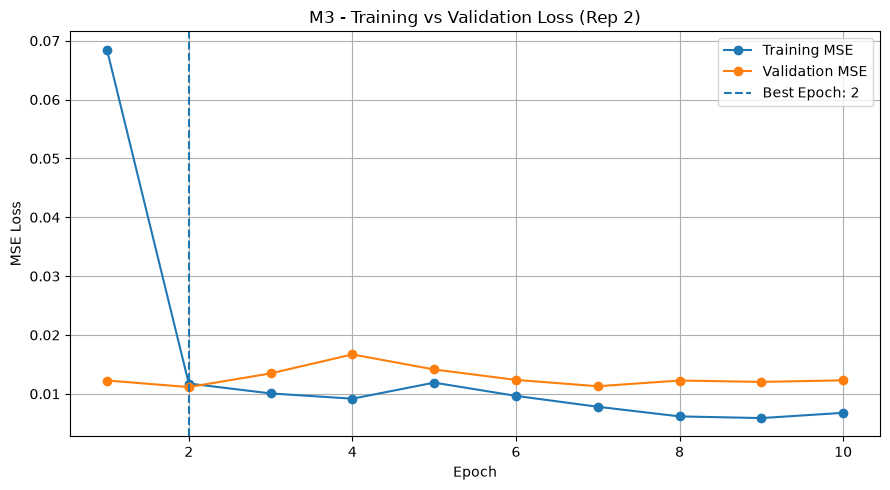

Loss curve saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep02_loss_curve.png


In [113]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments/results"

history_path = os.path.join(RESULTS_DIR, "m3_rep02_history.csv")
history = pd.read_csv(history_path)

plt.figure(figsize=(9, 5))

plt.plot(history["epoch"], history["train_mse"],
         label="Training MSE", marker="o")

plt.plot(history["epoch"], history["val_mse"],
         label="Validation MSE", marker="o")

best_epoch = history.loc[history["val_mse"].idxmin(), "epoch"]
best_val = history["val_mse"].min()

plt.axvline(best_epoch, linestyle="--",
            label=f"Best Epoch: {best_epoch}")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("M3 - Training vs Validation Loss (Rep 2)")
plt.legend()
plt.grid(True)
plt.tight_layout()

save_path = os.path.join(RESULTS_DIR, "m3_rep02_loss_curve.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Loss curve saved:", save_path)

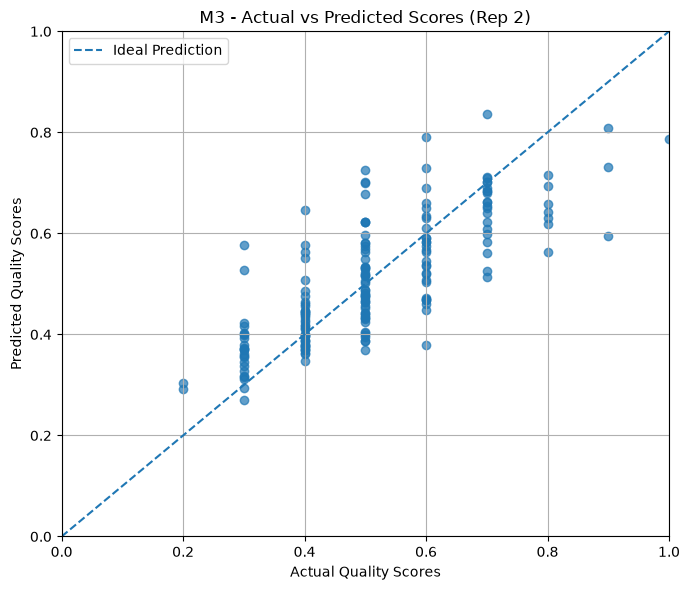

Actual vs Predicted plot saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep02_actual_vs_predicted.png


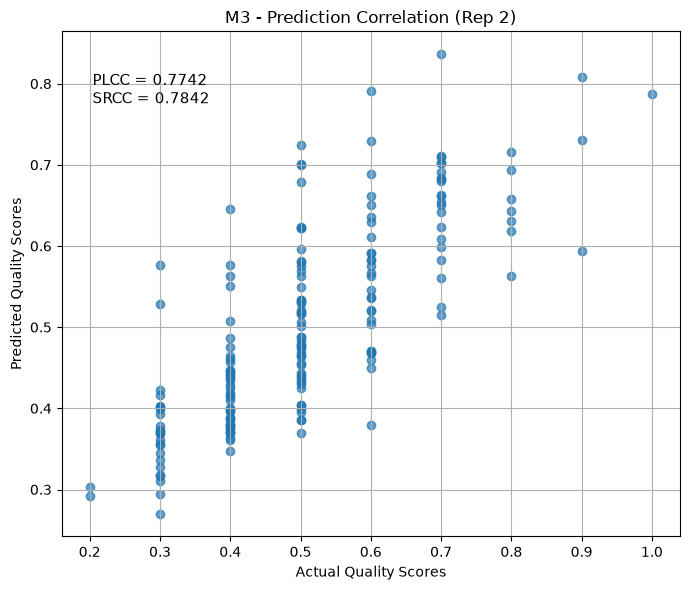

Scatter plot saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep02_scatter_plot.png


In [114]:
pred_path = os.path.join(RESULTS_DIR, "m3_rep02_predictions.csv")
predictions = pd.read_csv(pred_path)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Ideal Prediction"
)

plt.scatter(
    predictions["actual_score"],
    predictions["predicted_score"],
    alpha=0.7
)

plt.xlabel("Actual Quality Scores")
plt.ylabel("Predicted Quality Scores")
plt.title("M3 - Actual vs Predicted Scores (Rep 2)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "m3_rep02_actual_vs_predicted.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Actual vs Predicted plot saved:", save_path)

from scipy.stats import pearsonr, spearmanr

actual = predictions["actual_score"]
predicted = predictions["predicted_score"]

plcc = pearsonr(actual, predicted)[0]
srcc = spearmanr(actual, predicted)[0]

plt.figure(figsize=(7, 6))

plt.scatter(actual, predicted, alpha=0.7)

plt.xlabel("Actual Quality Scores")
plt.ylabel("Predicted Quality Scores")
plt.title("M3 - Prediction Correlation (Rep 2)")

plt.text(
    0.05, 0.92,
    f"PLCC = {plcc:.4f}\nSRCC = {srcc:.4f}",
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top"
)

plt.grid(True)
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "m3_rep02_scatter_plot.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Scatter plot saved:", save_path)

In [115]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

# --------------------------------------------------
# 1. Reproducibility
# --------------------------------------------------

SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --------------------------------------------------
# 2. M4 Channel + Spatial Attention
# --------------------------------------------------

class ChannelSpatialAttention(nn.Module):
    def __init__(self, channels=2048, reduction=16):
        super().__init__()

        self.channel_attention = nn.Sequential(
            nn.Linear(channels, channels // reduction),
            nn.ReLU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )

        self.spatial_attention = nn.Conv2d(
            channels, 1, kernel_size=1
        )

    def forward(self, feature_map):

        # Channel attention
        channel_descriptor = F.adaptive_avg_pool2d(
            feature_map, 1
        ).flatten(1)

        channel_weights = self.channel_attention(
            channel_descriptor
        ).unsqueeze(-1).unsqueeze(-1)

        feature_map = feature_map * channel_weights

        # Spatial attention
        spatial_weights = torch.sigmoid(
            self.spatial_attention(feature_map)
        )

        feature_map = feature_map * spatial_weights

        return feature_map


# --------------------------------------------------
# 3. M4 Regression Head
# --------------------------------------------------

class M4RegressionHead(nn.Module):
    def __init__(self, input_dim=2048):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.layers(x).squeeze(1)


# --------------------------------------------------
# 4. Complete M4 Architecture
# --------------------------------------------------

class M4AttentionSaliencyResNet(nn.Module):

    def __init__(self, pretrained=True):
        super().__init__()

        weights = (
            models.ResNet50_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        backbone = models.resnet50(weights=weights)

        self.feature_extractor = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1,
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        self.attention = ChannelSpatialAttention(2048)

        self.regressor = M4RegressionHead(2048)

    def forward(self, images):

        batch_size = images.size(0)

        height, width = images.shape[-2:]

        half_h = height // 2
        half_w = width // 2

        # Divide each image into four patches
        patches = [
            images[:, :, :half_h, :half_w],
            images[:, :, :half_h, half_w:],
            images[:, :, half_h:, :half_w],
            images[:, :, half_h:, half_w:]
        ]

        patch_features = []

        for patch in patches:

            # ResNet-50 feature extraction
            feature_maps = self.feature_extractor(patch)

            # Channel + spatial attention
            feature_maps = self.attention(feature_maps)

            # Feature-map magnitude-based saliency
            saliency = feature_maps.abs().mean(
                dim=1, keepdim=True
            )

            # Normalize saliency across spatial locations
            saliency = saliency / (
                saliency.sum(dim=(2, 3), keepdim=True) + 1e-8
            )

            # Saliency-weighted feature pooling
            pooled = (
                feature_maps * saliency
            ).sum(dim=(2, 3))

            patch_features.append(pooled)

        # Shape: [batch_size, 4, 2048]
        patch_features = torch.stack(
            patch_features, dim=1
        )

        # Average the four patch representations
        features = patch_features.mean(dim=1)

        # Predict quality score
        return self.regressor(features)


# --------------------------------------------------
# 5. Initialize M4
# --------------------------------------------------

assert torch.cuda.is_available(), "GPU is not available."

model_m4 = M4AttentionSaliencyResNet(
    pretrained=True
).to(DEVICE)

# Verify existing Repetition 2 loaders
assert len(train_loader.dataset) == 640
assert len(val_loader.dataset) == 72
assert len(test_loader.dataset) == 178

# Verify output shape
sample_images, sample_scores, *_ = next(iter(train_loader))
sample_images = sample_images[:2].to(DEVICE)

model_m4.eval()

with torch.no_grad():
    sample_output = model_m4(sample_images)

print("M4 initialization successful!")
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Output shape:", tuple(sample_output.shape))
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Testing images:", len(test_loader.dataset))

del sample_images, sample_output
torch.cuda.empty_cache()

M4 initialization successful!
Device: cuda
GPU: NVIDIA A40
Output shape: (2,)
Training images: 640
Validation images: 72
Testing images: 178


In [116]:
import copy
import pandas as pd
import torch.nn as nn

# Separate learning rates
optimizer_m4 = torch.optim.Adam(
    [
        {
            "params": model_m4.feature_extractor.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_m4.attention.parameters(),
            "lr": 3e-4
        },
        {
            "params": model_m4.regressor.parameters(),
            "lr": 3e-4
        }
    ],
    weight_decay=1e-4
)

criterion_m4 = nn.MSELoss()

scheduler_m4 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_m4,
    mode="min",
    factor=0.5,
    patience=3
)

MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 8

EXPERIMENT_DIR = (
    "/home/karthikbaskar2/UWIQA_Research_Experiments"
)

CHECKPOINT_DIR = os.path.join(EXPERIMENT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(EXPERIMENT_DIR, "results")

checkpoint_path = os.path.join(
    CHECKPOINT_DIR, "m4_rep02_best.pt"
)

history_path = os.path.join(
    RESULTS_DIR, "m4_rep02_history.csv"
)

# Protect existing experiment files
assert not os.path.exists(checkpoint_path), (
    "M4 checkpoint already exists. Do not overwrite it."
)

assert not os.path.exists(history_path), (
    "M4 history already exists. Do not overwrite it."
)

print("M4 training configuration ready.")
print("Checkpoint:", checkpoint_path)
print("History:", history_path)

M4 training configuration ready.
Checkpoint: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints/m4_rep02_best.pt
History: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep02_history.csv


In [117]:
import time

best_val_mse = float("inf")
best_epoch = 0
best_model_state = None

patience_counter = 0
history_m4 = []

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    # ---------------------------
    # Training
    # ---------------------------

    model_m4.train()

    train_loss = 0.0
    train_samples = 0

    for batch in train_loader:

        images, scores = batch[0], batch[1]

        images = images.to(DEVICE, non_blocking=True)
        scores = scores.to(DEVICE, non_blocking=True)

        optimizer_m4.zero_grad(set_to_none=True)

        predictions = model_m4(images)

        loss = criterion_m4(predictions, scores)

        loss.backward()
        optimizer_m4.step()

        train_loss += loss.item() * images.size(0)
        train_samples += images.size(0)

    train_mse = train_loss / train_samples

    # ---------------------------
    # Validation
    # ---------------------------

    model_m4.eval()

    val_loss = 0.0
    val_samples = 0

    with torch.no_grad():

        for batch in val_loader:

            images, scores = batch[0], batch[1]

            images = images.to(DEVICE, non_blocking=True)
            scores = scores.to(DEVICE, non_blocking=True)

            predictions = model_m4(images)

            loss = criterion_m4(predictions, scores)

            val_loss += loss.item() * images.size(0)
            val_samples += images.size(0)

    val_mse = val_loss / val_samples

    scheduler_m4.step(val_mse)

    current_lr = optimizer_m4.param_groups[0]["lr"]

    # ---------------------------
    # Save history
    # ---------------------------

    history_m4.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "backbone_lr": current_lr,
        "head_lr": optimizer_m4.param_groups[1]["lr"]
    })

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch:02d}/{MAX_EPOCHS}] "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"LR: {current_lr:.7f} | "
        f"Time: {elapsed:.1f}s"
    )

    # ---------------------------
    # Best checkpoint
    # ---------------------------

    if val_mse < best_val_mse:

        best_val_mse = val_mse
        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model_m4.state_dict()
        )

        patience_counter = 0

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer_m4.state_dict(),
            "best_val_mse": best_val_mse,
            "seed": SEED,
            "model_name": "M4",
            "backbone_lr": 1e-4,
            "head_lr": 3e-4,
            "weight_decay": 1e-4
        }, checkpoint_path)

        print("  Best checkpoint saved.")

    else:
        patience_counter += 1

    if patience_counter >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Save training history
history_df = pd.DataFrame(history_m4)
history_df.to_csv(history_path, index=False)

print("\nM4 TRAINING COMPLETED")
print("=" * 45)
print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val_mse)
print("Checkpoint saved:", checkpoint_path)
print("History saved:", history_path)

Epoch [01/50] Train MSE: 0.026765 | Val MSE: 0.021443 | LR: 0.0001000 | Time: 33.4s
  Best checkpoint saved.
Epoch [02/50] Train MSE: 0.010607 | Val MSE: 0.012689 | LR: 0.0001000 | Time: 31.5s
  Best checkpoint saved.
Epoch [03/50] Train MSE: 0.009740 | Val MSE: 0.010818 | LR: 0.0001000 | Time: 31.9s
  Best checkpoint saved.
Epoch [04/50] Train MSE: 0.008045 | Val MSE: 0.010618 | LR: 0.0001000 | Time: 32.6s
  Best checkpoint saved.
Epoch [05/50] Train MSE: 0.007833 | Val MSE: 0.011244 | LR: 0.0001000 | Time: 31.9s
Epoch [06/50] Train MSE: 0.007092 | Val MSE: 0.011947 | LR: 0.0001000 | Time: 33.2s
Epoch [07/50] Train MSE: 0.007660 | Val MSE: 0.012971 | LR: 0.0001000 | Time: 31.9s
Epoch [08/50] Train MSE: 0.007377 | Val MSE: 0.010493 | LR: 0.0001000 | Time: 31.8s
  Best checkpoint saved.
Epoch [09/50] Train MSE: 0.006915 | Val MSE: 0.010742 | LR: 0.0001000 | Time: 31.5s
Epoch [10/50] Train MSE: 0.006196 | Val MSE: 0.009809 | LR: 0.0001000 | Time: 31.3s
  Best checkpoint saved.
Epoch [11/

In [118]:
import os
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

# --------------------------------------------------
# 1. Load the best M4 checkpoint
# --------------------------------------------------

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model_m4.load_state_dict(checkpoint["model_state_dict"])
model_m4.to(DEVICE)
model_m4.eval()

print("Loaded M4 best checkpoint")
print("Best epoch:", checkpoint["epoch"])
print("Best validation MSE:", checkpoint["best_val_mse"])

# --------------------------------------------------
# 2. Generate test predictions
# --------------------------------------------------

actual_scores = []
predicted_scores = []
filenames = []

with torch.inference_mode():

    for batch in test_loader:

        images, scores, batch_filenames = batch

        images = images.to(DEVICE, non_blocking=True)

        predictions = model_m4(images)

        actual_scores.extend(scores.cpu().numpy().tolist())
        predicted_scores.extend(predictions.cpu().numpy().tolist())
        filenames.extend(list(batch_filenames))

actual_scores = np.asarray(actual_scores, dtype=float)
predicted_scores = np.asarray(predicted_scores, dtype=float)

# --------------------------------------------------
# 3. Validate predictions
# --------------------------------------------------

assert len(actual_scores) == 178, (
    f"Expected 178 test images, got {len(actual_scores)}"
)

assert len(predicted_scores) == len(actual_scores)
assert len(filenames) == len(actual_scores)

assert np.isfinite(actual_scores).all()
assert np.isfinite(predicted_scores).all()

assert np.std(actual_scores) > 0
assert np.std(predicted_scores) > 0

# --------------------------------------------------
# 4. Calculate evaluation metrics
# --------------------------------------------------

plcc = pearsonr(actual_scores, predicted_scores).statistic
srcc = spearmanr(actual_scores, predicted_scores).statistic
krcc = kendalltau(
    actual_scores,
    predicted_scores,
    variant="b"
).statistic

mse = mean_squared_error(actual_scores, predicted_scores)
rmse = np.sqrt(mse)

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("\nM4 — Repetition 2 Test Results")
print("----------------------------------------")
print("Test Images :", len(actual_scores))
print(f"PLCC        : {plcc:.6f}")
print(f"SRCC        : {srcc:.6f}")
print(f"KRCC        : {krcc:.6f}")
print(f"RMSE        : {rmse:.6f}")
print(f"MSE         : {mse:.6f}")

# --------------------------------------------------
# 6. Save metrics
# --------------------------------------------------

metrics_path = os.path.join(
    RESULTS_DIR, "m4_rep02_metrics.csv"
)

predictions_path = os.path.join(
    RESULTS_DIR, "m4_rep02_predictions.csv"
)

assert not os.path.exists(metrics_path), "Metrics file already exists."
assert not os.path.exists(predictions_path), "Predictions file already exists."

metrics_df = pd.DataFrame([{
    "model": "M4",
    "repetition": 2,
    "test_images": len(actual_scores),
    "best_epoch": checkpoint["epoch"],
    "best_val_mse": checkpoint["best_val_mse"],
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MSE": mse
}])

predictions_df = pd.DataFrame({
    "filename": filenames,
    "actual_score": actual_scores,
    "predicted_score": predicted_scores
})

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

print("\nMetrics saved:", metrics_path)
print("Predictions saved:", predictions_path)

print("\nFirst 5 predictions:")
print(predictions_df.head())

Loaded M4 best checkpoint
Best epoch: 13
Best validation MSE: 0.009424752038386133

M4 — Repetition 2 Test Results
----------------------------------------
Test Images : 178
PLCC        : 0.837492
SRCC        : 0.843572
KRCC        : 0.705673
RMSE        : 0.082752
MSE         : 0.006848

Metrics saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep02_metrics.csv
Predictions saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep02_predictions.csv

First 5 predictions:
   filename  actual_score  predicted_score
0  0002.png           0.5         0.589964
1  0006.png           0.6         0.480785
2  0013.png           0.6         0.463405
3  0036.png           0.3         0.323574
4  0038.png           0.4         0.360397


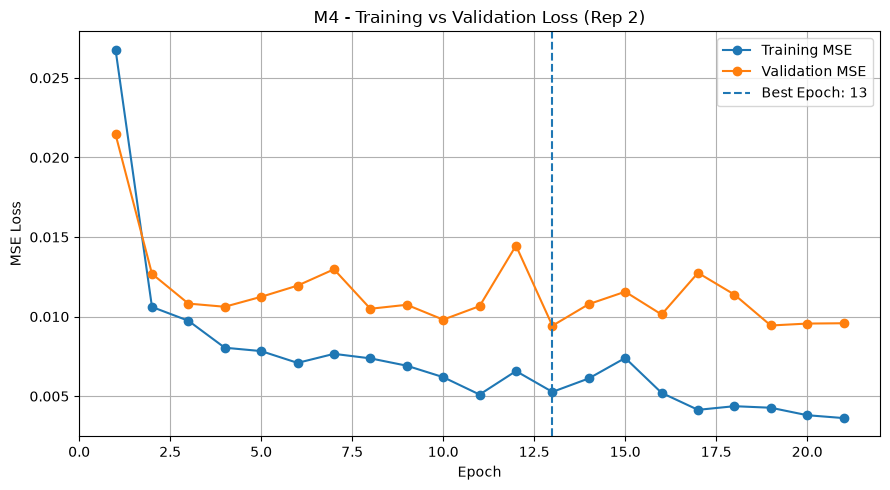

Best epoch: 13
Best validation MSE: 0.0094247520383861
Loss curve saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep02_loss_curve.png


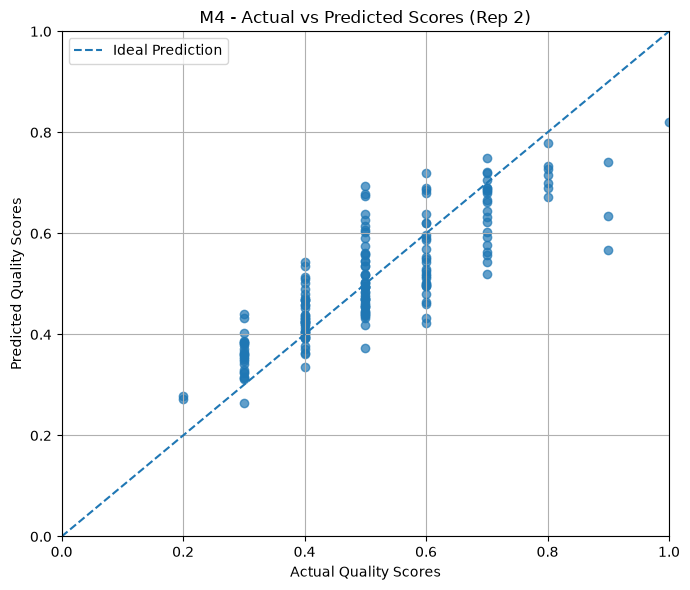

Actual vs Predicted plot saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep02_actual_vs_predicted.png


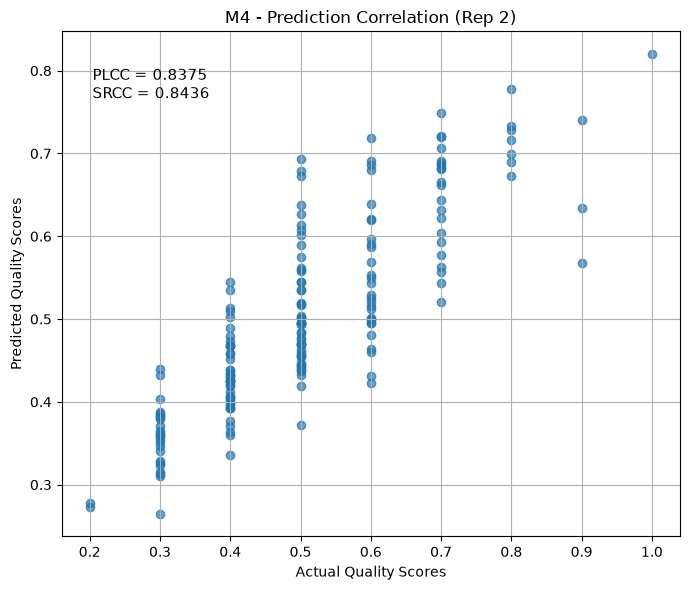

PLCC: 0.837492
SRCC: 0.843572
Scatter plot saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep02_scatter_plot.png


In [119]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments/results"

history = pd.read_csv(
    os.path.join(RESULTS_DIR, "m4_rep02_history.csv")
)

best_epoch = history.loc[
    history["val_mse"].idxmin(), "epoch"
]

best_val = history["val_mse"].min()

plt.figure(figsize=(9, 5))

plt.plot(
    history["epoch"],
    history["train_mse"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    history["epoch"],
    history["val_mse"],
    marker="o",
    label="Validation MSE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("M4 - Training vs Validation Loss (Rep 2)")
plt.legend()
plt.grid(True)
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "m4_rep02_loss_curve.png"
)

assert not os.path.exists(save_path), "Plot already exists; refusing to overwrite."

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val)
print("Loss curve saved:", save_path)

predictions = pd.read_csv(
    os.path.join(RESULTS_DIR, "m4_rep02_predictions.csv")
)

plt.figure(figsize=(7, 6))

plt.scatter(
    predictions["actual_score"],
    predictions["predicted_score"],
    alpha=0.7
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Quality Scores")
plt.ylabel("Predicted Quality Scores")
plt.title("M4 - Actual vs Predicted Scores (Rep 2)")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(True)
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "m4_rep02_actual_vs_predicted.png"
)

assert not os.path.exists(save_path), "Plot already exists; refusing to overwrite."

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Actual vs Predicted plot saved:", save_path)

from scipy.stats import pearsonr, spearmanr

actual = predictions["actual_score"].to_numpy()
predicted = predictions["predicted_score"].to_numpy()

plcc = pearsonr(actual, predicted).statistic
srcc = spearmanr(actual, predicted).statistic

plt.figure(figsize=(7, 6))

plt.scatter(
    actual,
    predicted,
    alpha=0.7
)

plt.xlabel("Actual Quality Scores")
plt.ylabel("Predicted Quality Scores")
plt.title("M4 - Prediction Correlation (Rep 2)")

plt.text(
    0.05,
    0.93,
    f"PLCC = {plcc:.4f}\nSRCC = {srcc:.4f}",
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top"
)

plt.grid(True)
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "m4_rep02_scatter_plot.png"
)

assert not os.path.exists(save_path), "Plot already exists; refusing to overwrite."

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"PLCC: {plcc:.6f}")
print(f"SRCC: {srcc:.6f}")
print("Scatter plot saved:", save_path)

In [123]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet50_Weights


# ============================================================
# M5: Degradation- and Saliency-Aware Patch Quality Network
# ============================================================

class M5DegradationSaliencyQualityNet(nn.Module):

    def __init__(self):
        super().__init__()

        # ----------------------------------------------------
        # 1. ResNet50 Feature Extractor
        # ----------------------------------------------------

        resnet = models.resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        self.backbone = nn.Sequential(
            *list(resnet.children())[:-2]
        )

        # Output feature dimension = 2048

        # ----------------------------------------------------
        # 2. Quality Branch
        # Learns local patch quality representations
        # ----------------------------------------------------

        self.quality_branch = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 1)
        )

        # ----------------------------------------------------
        # 3. Degradation Branch
        # Learns degradation-related patch representations
        # ----------------------------------------------------

        self.degradation_branch = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 1)
        )

        # ----------------------------------------------------
        # 4. Fusion Branch
        # Combines quality, saliency and degradation signals
        # ----------------------------------------------------

        self.fusion = nn.Sequential(
            nn.Linear(3, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

        # ----------------------------------------------------
        # 5. Final Quality Regression Head
        # ----------------------------------------------------

        self.regressor = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )


    def forward(self, images):

        batch_size = images.size(0)

        # ----------------------------------------------------
        # STEP 1: Divide each image into four patches
        # ----------------------------------------------------

        patches = [
            images[:, :, :112, :112],       # Top-left
            images[:, :, :112, 112:],       # Top-right
            images[:, :, 112:, :112],       # Bottom-left
            images[:, :, 112:, 112:]        # Bottom-right
        ]

        # Combine patches along batch dimension
        patches = torch.cat(patches, dim=0)

        # ----------------------------------------------------
        # STEP 2: Extract ResNet50 feature maps
        # ----------------------------------------------------

        feature_maps = self.backbone(patches)

        # ----------------------------------------------------
        # STEP 3: Global Average Pooling
        # Avoid hardcoding spatial dimensions such as 7x7
        # ----------------------------------------------------

        patch_features = feature_maps.mean(
            dim=(2, 3)
        )

        # Shape: [4 * batch_size, 2048]

        # Group four patches belonging to each image
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Shape: [batch_size, 4, 2048]

        # ----------------------------------------------------
        # STEP 4: Quality Branch
        # ----------------------------------------------------

        quality_scores = self.quality_branch(
            patch_features
        ).squeeze(-1)

        # Shape: [batch_size, 4]

        # ----------------------------------------------------
        # STEP 5: Degradation Branch
        # ----------------------------------------------------

        degradation_scores = self.degradation_branch(
            patch_features
        ).squeeze(-1)

        # Shape: [batch_size, 4]

        # ----------------------------------------------------
        # STEP 6: Saliency Branch
        # Estimate saliency using colour contrast
        # ----------------------------------------------------

        global_color_mean = images.mean(
            dim=(2, 3),
            keepdim=True
        )

        saliency_map = torch.sqrt(
            (
                (images - global_color_mean) ** 2
            ).mean(dim=1, keepdim=True) + 1e-8
        )

        # Divide saliency map into four patches
        saliency_patches = [
            saliency_map[:, :, :112, :112],
            saliency_map[:, :, :112, 112:],
            saliency_map[:, :, 112:, :112],
            saliency_map[:, :, 112:, 112:]
        ]

        # Calculate average saliency for each patch
        saliency_scores = torch.stack(
            [
                patch.mean(dim=(1, 2, 3))
                for patch in saliency_patches
            ],
            dim=1
        )

        # Normalize saliency values between 0 and 1
        saliency_min = saliency_scores.min(
            dim=1, keepdim=True
        )[0]

        saliency_max = saliency_scores.max(
            dim=1, keepdim=True
        )[0]

        saliency_scores = (
            saliency_scores - saliency_min
        ) / (
            saliency_max - saliency_min + 1e-8
        )

        # Shape: [batch_size, 4]

        # ----------------------------------------------------
        # STEP 7: Combine Three Branch Outputs
        # ----------------------------------------------------

        branch_outputs = torch.stack(
            [
                quality_scores,
                saliency_scores,
                degradation_scores
            ],
            dim=-1
        )

        # Shape: [batch_size, 4, 3]

        # ----------------------------------------------------
        # STEP 8: Calculate Patch Importance Weights
        # ----------------------------------------------------

        importance_logits = self.fusion(
            branch_outputs
        ).squeeze(-1)

        patch_weights = torch.softmax(
            importance_logits,
            dim=1
        )

        # Shape: [batch_size, 4]

        # ----------------------------------------------------
        # STEP 9: Weighted Patch Feature Aggregation
        # ----------------------------------------------------

        aggregated_features = (
            patch_features *
            patch_weights.unsqueeze(-1)
        ).sum(dim=1)

        # Shape: [batch_size, 2048]

        # ----------------------------------------------------
        # STEP 10: Final Image Quality Prediction
        # ----------------------------------------------------

        output = self.regressor(
            aggregated_features
        )

        return output.squeeze(1)


# ============================================================
# CREATE M5 MODEL
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

m5_model = M5DegradationSaliencyQualityNet().to(device)


# ============================================================
# TEST MODEL OUTPUT
# ============================================================

sample_batch = next(iter(train_loader))

sample_images = sample_batch[0].to(device)

m5_model.eval()

with torch.no_grad():
    sample_output = m5_model(sample_images)


print("M5 Model Test Successful!")
print("-----------------------------------")
print("Input shape:", sample_images.shape)
print("Output shape:", sample_output.shape)
print("Sample predictions:", sample_output[:5])
print("Device:", device)
print("-----------------------------------")

M5 Model Test Successful!
-----------------------------------
Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16])
Sample predictions: tensor([0.1088, 0.1842, 0.1358, 0.1844, 0.1289], device='cuda:0')
Device: cuda
-----------------------------------


In [124]:
# ============================================================
# M5 TRAINING - REPETITION 2
# Degradation- and Saliency-Aware Patch Quality Network
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn


# ------------------------------------------------------------
# STEP 1: SET RANDOM SEED
# ------------------------------------------------------------

SEED = 2028

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Random Seed:", SEED)


# ------------------------------------------------------------
# STEP 2: INITIALIZE M5 MODEL
# ------------------------------------------------------------

m5_model = M5DegradationSaliencyQualityNet().to(device)

print("\nM5 Model Initialized Successfully!")


# ------------------------------------------------------------
# STEP 3: DEFINE OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.Adam(
    [
        {
            "params": m5_model.backbone.parameters(),
            "lr": 1e-4
        },
        {
            "params": list(m5_model.quality_branch.parameters())
                    + list(m5_model.degradation_branch.parameters())
                    + list(m5_model.fusion.parameters())
                    + list(m5_model.regressor.parameters()),
            "lr": 3e-4
        }
    ],
    weight_decay=1e-4
)


# ------------------------------------------------------------
# STEP 4: DEFINE LOSS FUNCTION AND SCHEDULER
# ------------------------------------------------------------

criterion = nn.MSELoss()

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ------------------------------------------------------------
# STEP 5: TRAINING CONFIGURATION
# ------------------------------------------------------------

num_epochs = 50
early_stopping_patience = 8

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

history = []


# ------------------------------------------------------------
# STEP 6: DEFINE SAVE PATHS
# ------------------------------------------------------------

BASE_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments"

CHECKPOINT_DIR = os.path.join(
    BASE_DIR, "checkpoints"
)

RESULTS_DIR = os.path.join(
    BASE_DIR, "results"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "m5_rep02_best.pt"
)

history_path = os.path.join(
    RESULTS_DIR,
    "m5_rep02_history.csv"
)

# Prevent accidental overwriting
assert not os.path.exists(checkpoint_path), (
    "M5 checkpoint already exists. Use a new filename."
)

assert not os.path.exists(history_path), (
    "M5 history already exists. Use a new filename."
)


# ------------------------------------------------------------
# STEP 7: TRAINING LOOP
# ------------------------------------------------------------

print("\nStarting M5 Training...")
print("=" * 65)

for epoch in range(num_epochs):

    # ========================================================
    # TRAINING PHASE
    # ========================================================

    m5_model.train()

    train_loss = 0.0
    train_samples = 0

    for batch in train_loader:

        images = batch[0].to(device)
        scores = batch[1].to(device).float().reshape(-1)

        optimizer.zero_grad()

        predictions = m5_model(images)

        loss = criterion(predictions, scores)

        loss.backward()

        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_samples += images.size(0)

    train_loss = train_loss / train_samples


    # ========================================================
    # VALIDATION PHASE
    # ========================================================

    m5_model.eval()

    val_loss = 0.0
    val_samples = 0

    with torch.no_grad():

        for batch in val_loader:

            images = batch[0].to(device)
            scores = batch[1].to(device).float().reshape(-1)

            predictions = m5_model(images)

            loss = criterion(predictions, scores)

            val_loss += loss.item() * images.size(0)
            val_samples += images.size(0)

    val_loss = val_loss / val_samples


    # ========================================================
    # LEARNING RATE SCHEDULER
    # ========================================================

    scheduler.step(val_loss)

    backbone_lr = optimizer.param_groups[0]["lr"]
    head_lr = optimizer.param_groups[1]["lr"]


    # ========================================================
    # SAVE EPOCH HISTORY
    # ========================================================

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "backbone_lr": backbone_lr,
        "head_lr": head_lr
    })


    # ========================================================
    # CHECK BEST VALIDATION LOSS
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": m5_model.state_dict(),
                "epoch": best_epoch,
                "best_val_loss": best_val_loss,
                "seed": SEED
            },
            checkpoint_path
        )

        status = "Best Model Saved"

    else:

        epochs_without_improvement += 1

        status = (
            f"No improvement: "
            f"{epochs_without_improvement}/{early_stopping_patience}"
        )


    # ========================================================
    # PRINT EPOCH RESULTS
    # ========================================================

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Backbone LR: {backbone_lr:.7f} | "
        f"Head LR: {head_lr:.7f} | "
        f"{status}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= early_stopping_patience:

        print("\nEarly Stopping Triggered!")

        break


# ------------------------------------------------------------
# STEP 8: SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    history_path,
    index=False
)


# ------------------------------------------------------------
# STEP 9: TRAINING SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("M5 TRAINING COMPLETED")
print("=" * 65)

print("Best Epoch:", best_epoch)
print("Best Validation MSE:", best_val_loss)

print("\nCheckpoint Saved:")
print(checkpoint_path)

print("\nTraining History Saved:")
print(history_path)

print("\nTotal Epochs Completed:", len(history_df))
print("=" * 65)

Device: cuda
Random Seed: 2028

M5 Model Initialized Successfully!

Starting M5 Training...
Epoch [01/50] Train Loss: 0.033581 | Val Loss: 0.025836 | Backbone LR: 0.0001000 | Head LR: 0.0003000 | Best Model Saved
Epoch [02/50] Train Loss: 0.012135 | Val Loss: 0.018548 | Backbone LR: 0.0001000 | Head LR: 0.0003000 | Best Model Saved
Epoch [03/50] Train Loss: 0.008550 | Val Loss: 0.014306 | Backbone LR: 0.0001000 | Head LR: 0.0003000 | Best Model Saved
Epoch [04/50] Train Loss: 0.006965 | Val Loss: 0.012793 | Backbone LR: 0.0001000 | Head LR: 0.0003000 | Best Model Saved
Epoch [05/50] Train Loss: 0.005608 | Val Loss: 0.014571 | Backbone LR: 0.0001000 | Head LR: 0.0003000 | No improvement: 1/8
Epoch [06/50] Train Loss: 0.006048 | Val Loss: 0.012348 | Backbone LR: 0.0001000 | Head LR: 0.0003000 | Best Model Saved
Epoch [07/50] Train Loss: 0.006652 | Val Loss: 0.014014 | Backbone LR: 0.0001000 | Head LR: 0.0003000 | No improvement: 1/8
Epoch [08/50] Train Loss: 0.005622 | Val Loss: 0.014078

In [126]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nAvailable checkpoint keys:")
    print(checkpoint.keys())

    for key, value in checkpoint.items():
        if key != "model_state_dict":
            print(f"{key}: {value}")
else:
    print("Checkpoint is not a dictionary.")

Checkpoint type: <class 'dict'>

Available checkpoint keys:
dict_keys(['model_state_dict', 'epoch', 'best_val_loss', 'seed'])
epoch: 12
best_val_loss: 0.01170598870764176
seed: 2028


In [128]:
import os
import numpy as np
import pandas as pd
import torch

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

# ==========================================================
# 1. PATHS
# ==========================================================

BASE_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments"

checkpoint_path = os.path.join(
    BASE_DIR, "checkpoints", "m5_rep02_best.pt"
)

metrics_path = os.path.join(
    BASE_DIR, "results", "m5_rep02_metrics.csv"
)

predictions_path = os.path.join(
    BASE_DIR, "results", "m5_rep02_predictions.csv"
)

assert os.path.exists(checkpoint_path), "Checkpoint not found!"

# Prevent accidental overwriting
assert not os.path.exists(metrics_path), "Metrics file already exists!"
assert not os.path.exists(predictions_path), "Predictions file already exists!"


# ==========================================================
# 2. LOAD BEST CHECKPOINT
# ==========================================================

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

m5_model.load_state_dict(checkpoint["model_state_dict"])
m5_model.to(device)
m5_model.eval()

print("M5 Best Checkpoint Loaded Successfully!")
print("Best Epoch:", checkpoint["epoch"])
print("Best Validation MSE:", checkpoint["best_val_loss"])
print("Random Seed:", checkpoint["seed"])


# ==========================================================
# 3. TEST EVALUATION
# ==========================================================

actual_scores = []
predicted_scores = []
image_names = []

with torch.no_grad():

    for batch in test_loader:

        images = batch[0].to(device)
        scores = batch[1].float().reshape(-1).to(device)

        predictions = m5_model(images).reshape(-1)

        actual_scores.extend(scores.cpu().numpy())
        predicted_scores.extend(predictions.cpu().numpy())

        if len(batch) > 2:
            image_names.extend(list(batch[2]))


actual_scores = np.array(actual_scores)
predicted_scores = np.array(predicted_scores)

print("\nTest Evaluation Completed!")
print("Number of Test Images:", len(actual_scores))

assert len(actual_scores) == 178, (
    f"Expected 178 test images, got {len(actual_scores)}"
)


# ==========================================================
# 4. CALCULATE PERFORMANCE METRICS
# ==========================================================

plcc = pearsonr(actual_scores, predicted_scores)[0]

srcc = spearmanr(
    actual_scores,
    predicted_scores
)[0]

# Kendall tau-b handles tied quality scores
krcc = kendalltau(
    actual_scores,
    predicted_scores,
    variant="b"
)[0]

mse = mean_squared_error(
    actual_scores,
    predicted_scores
)

rmse = np.sqrt(mse)


# ==========================================================
# 5. DISPLAY RESULTS
# ==========================================================

print("\n========== M5 REP 02 TEST RESULTS ==========")

print(f"PLCC : {plcc:.6f}")
print(f"SRCC : {srcc:.6f}")
print(f"KRCC : {krcc:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"MSE  : {mse:.6f}")


# ==========================================================
# 6. SAVE METRICS CSV
# ==========================================================

metrics_df = pd.DataFrame([{
    "Model": "M5",
    "Repetition": 2,
    "Best_Epoch": checkpoint["epoch"],
    "Best_Val_MSE": checkpoint["best_val_loss"],
    "Test_Images": len(actual_scores),
    "PLCC": plcc,
    "SRCC": srcc,
    "KRCC": krcc,
    "RMSE": rmse,
    "MSE": mse
}])

metrics_df.to_csv(metrics_path, index=False)


# ==========================================================
# 7. SAVE PREDICTIONS CSV
# ==========================================================

if len(image_names) == len(actual_scores):

    prediction_df = pd.DataFrame({
        "Image": image_names,
        "Actual_Score": actual_scores,
        "Predicted_Score": predicted_scores
    })

else:

    prediction_df = pd.DataFrame({
        "Actual_Score": actual_scores,
        "Predicted_Score": predicted_scores
    })

prediction_df.to_csv(predictions_path, index=False)


# ==========================================================
# 8. FINAL CONFIRMATION
# ==========================================================

print("\nM5 EVALUATION COMPLETED SUCCESSFULLY!")

print("\nMetrics Saved:")
print(metrics_path)

print("\nPredictions Saved:")
print(predictions_path)

print("\nFirst 5 Predictions:")
display(prediction_df.head())

print("\nSaved Metrics:")
display(metrics_df)

M5 Best Checkpoint Loaded Successfully!
Best Epoch: 12
Best Validation MSE: 0.01170598870764176
Random Seed: 2028

Test Evaluation Completed!
Number of Test Images: 178

========== M5 REP 02 TEST RESULTS ==========
PLCC : 0.517259
SRCC : 0.800389
KRCC : 0.666223
RMSE : 0.149031
MSE  : 0.022210

M5 EVALUATION COMPLETED SUCCESSFULLY!

Metrics Saved:
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_metrics.csv

Predictions Saved:
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_predictions.csv

First 5 Predictions:


,Image,Actual_Score,Predicted_Score
0,0002.png,0.5,0.538093
1,0006.png,0.6,0.503505
2,0013.png,0.6,0.503151
3,0036.png,0.3,1.918705
4,0038.png,0.4,0.388140



Saved Metrics:


,Model,Repetition,Best_Epoch,Best_Val_MSE,Test_Images,PLCC,SRCC,KRCC,RMSE,MSE
0,M5,2,12,0.011706,178,0.517259,0.800389,0.666223,0.149031,0.02221


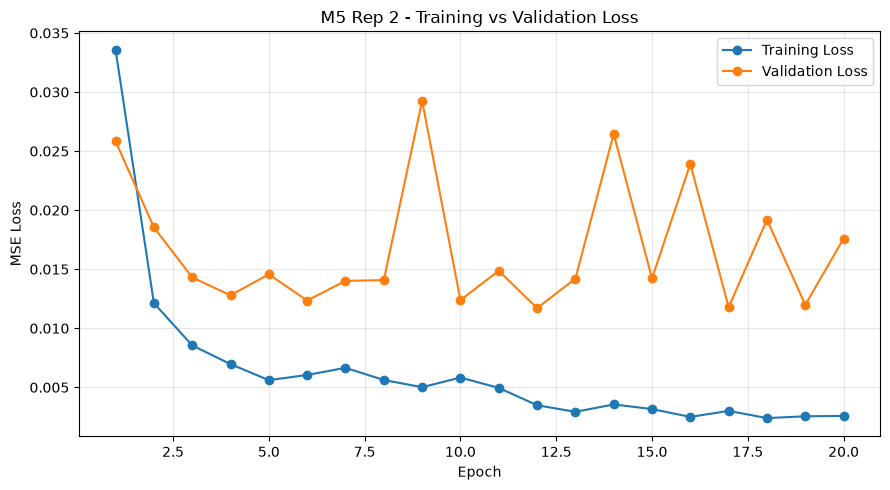

Loss curve saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_loss_curve.png


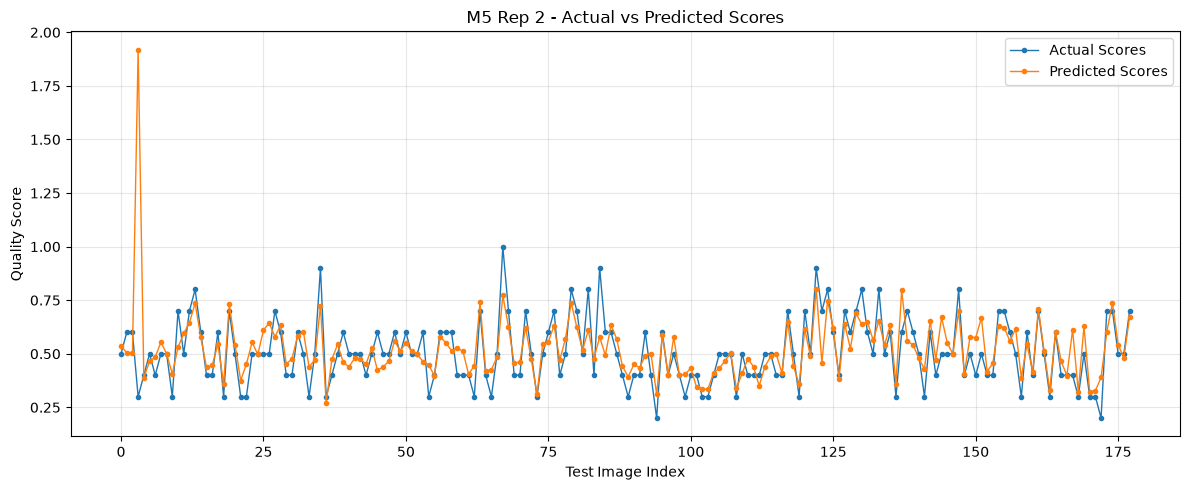

Actual vs Predicted plot saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_actual_vs_predicted.png


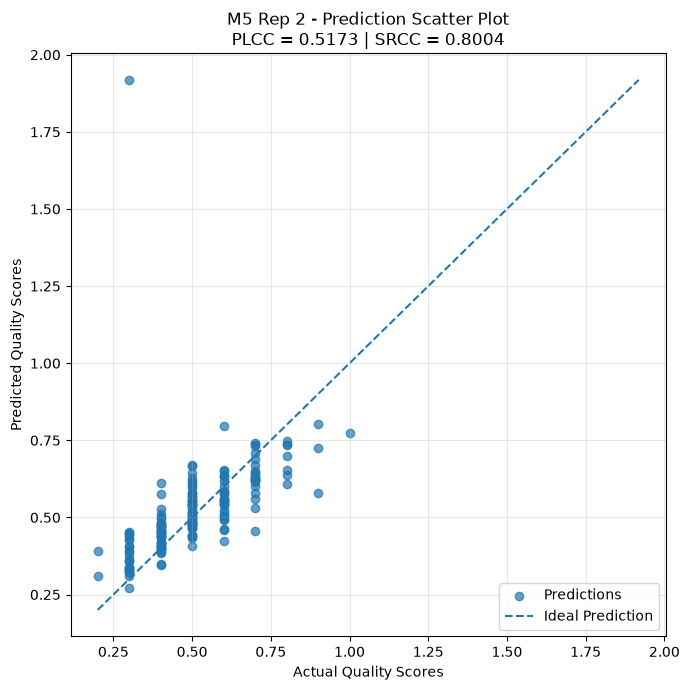

Scatter plot saved: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_scatter_plot.png

========== M5 REP 02 PLOTS COMPLETED ==========
1. /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_loss_curve.png
2. /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_actual_vs_predicted.png
3. /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_scatter_plot.png

All three plots generated and saved successfully!


In [129]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Load saved data
# --------------------------------------------------

BASE_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments"

history_path = os.path.join(
    BASE_DIR, "results", "m5_rep02_history.csv"
)

predictions_path = os.path.join(
    BASE_DIR, "results", "m5_rep02_predictions.csv"
)

history = pd.read_csv(history_path)
predictions = pd.read_csv(predictions_path)

# Output paths
loss_plot_path = os.path.join(
    BASE_DIR, "results", "m5_rep02_loss_curve.png"
)

actual_pred_plot_path = os.path.join(
    BASE_DIR, "results", "m5_rep02_actual_vs_predicted.png"
)

scatter_plot_path = os.path.join(
    BASE_DIR, "results", "m5_rep02_scatter_plot.png"
)

# Prevent overwriting existing plots
for path in [loss_plot_path, actual_pred_plot_path, scatter_plot_path]:
    assert not os.path.exists(path), f"File already exists: {path}"


# --------------------------------------------------
# 2. Plot 1: Training vs Validation Loss
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("M5 Rep 2 - Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(loss_plot_path, dpi=300)
plt.show()

print("Loss curve saved:", loss_plot_path)


# --------------------------------------------------
# 3. Plot 2: Actual vs Predicted Scores
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    predictions["Actual_Score"].values,
    label="Actual Scores",
    marker=".",
    linewidth=1
)

plt.plot(
    predictions["Predicted_Score"].values,
    label="Predicted Scores",
    marker=".",
    linewidth=1
)

plt.xlabel("Test Image Index")
plt.ylabel("Quality Score")
plt.title("M5 Rep 2 - Actual vs Predicted Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(actual_pred_plot_path, dpi=300)
plt.show()

print("Actual vs Predicted plot saved:", actual_pred_plot_path)


# --------------------------------------------------
# 4. Plot 3: Scatter Plot with PLCC and SRCC
# --------------------------------------------------

actual = predictions["Actual_Score"].values
predicted = predictions["Predicted_Score"].values

plt.figure(figsize=(7, 7))

plt.scatter(
    actual,
    predicted,
    alpha=0.7,
    label="Predictions"
)

# Ideal prediction line
minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Quality Scores")
plt.ylabel("Predicted Quality Scores")

plt.title(
    f"M5 Rep 2 - Prediction Scatter Plot\n"
    f"PLCC = {plcc:.4f} | SRCC = {srcc:.4f}"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(scatter_plot_path, dpi=300)
plt.show()

print("Scatter plot saved:", scatter_plot_path)


# --------------------------------------------------
# 5. Final Confirmation
# --------------------------------------------------

print("\n========== M5 REP 02 PLOTS COMPLETED ==========")

print("1.", loss_plot_path)
print("2.", actual_pred_plot_path)
print("3.", scatter_plot_path)

print("\nAll three plots generated and saved successfully!")

In [130]:
import os
import pandas as pd

# --------------------------------------------------
# 1. Experiment directory
# --------------------------------------------------

BASE_DIR = "/home/karthikbaskar2/UWIQA_Research_Experiments"

RESULTS_DIR = os.path.join(BASE_DIR, "results")

# --------------------------------------------------
# 2. Model results
# --------------------------------------------------

comparison_data = [
    {
        "Model": "M0 - ResNet50 Baseline",
        "PLCC": 0.8099,
        "SRCC": 0.8213,
        "KRCC": 0.6779,
        "RMSE": 0.0891,
        "MSE": 0.007931
    },
    {
        "Model": "M1 - Corrected Patch Average",
        "PLCC": 0.825232,
        "SRCC": 0.841133,
        "KRCC": 0.704124,
        "RMSE": 0.085669,
        "MSE": 0.007339
    },
    {
        "Model": "M2 - Patch Attention",
        "PLCC": 0.749433,
        "SRCC": 0.734944,
        "KRCC": 0.590139,
        "RMSE": 0.100686,
        "MSE": 0.010138
    },
    {
        "Model": "M3 - Saliency Aware",
        "PLCC": 0.774158,
        "SRCC": 0.784201,
        "KRCC": 0.639453,
        "RMSE": 0.095400,
        "MSE": 0.009101
    },
    {
        "Model": "M4 - Channel-Spatial Attention + Saliency",
        "PLCC": 0.837492,
        "SRCC": 0.843572,
        "KRCC": 0.705673,
        "RMSE": 0.082752,
        "MSE": 0.006848
    },
    {
        "Model": "M5 - Degradation + Saliency + Quality",
        "PLCC": 0.517259,
        "SRCC": 0.800389,
        "KRCC": 0.666223,
        "RMSE": 0.149031,
        "MSE": 0.022210
    }
]

# --------------------------------------------------
# 3. Create DataFrame
# --------------------------------------------------

comparison_df = pd.DataFrame(comparison_data)

comparison_df.insert(1, "Repetition", 2)

# --------------------------------------------------
# 4. Display complete table
# --------------------------------------------------

print("========== UWIQA - REPETITION 2 COMPARISON ==========")

display(
    comparison_df.style
    .format({
        "PLCC": "{:.6f}",
        "SRCC": "{:.6f}",
        "KRCC": "{:.6f}",
        "RMSE": "{:.6f}",
        "MSE": "{:.6f}"
    })
    .highlight_max(
        subset=["PLCC", "SRCC", "KRCC"],
        color="lightgreen"
    )
    .highlight_min(
        subset=["RMSE", "MSE"],
        color="lightgreen"
    )
)

# --------------------------------------------------
# 5. Save comparison CSV
# --------------------------------------------------

comparison_path = os.path.join(
    RESULTS_DIR,
    "uwiqa_rep02_model_comparison.csv"
)

assert not os.path.exists(comparison_path), (
    "Comparison file already exists. Avoid overwriting it."
)

comparison_df.to_csv(comparison_path, index=False)

print("\nComparison table saved successfully!")
print(comparison_path)

========== UWIQA - REPETITION 2 COMPARISON ==========


,Model,Repetition,PLCC,SRCC,KRCC,RMSE,MSE
0,M0 - ResNet50 Baseline,2,0.809900,0.821300,0.677900,0.089100,0.007931
1,M1 - Corrected Patch Average,2,0.825232,0.841133,0.704124,0.085669,0.007339
2,M2 - Patch Attention,2,0.749433,0.734944,0.590139,0.100686,0.010138
3,M3 - Saliency Aware,2,0.774158,0.784201,0.639453,0.095400,0.009101
4,M4 - Channel-Spatial Attention + Saliency,2,0.837492,0.843572,0.705673,0.082752,0.006848
5,M5 - Degradation + Saliency + Quality,2,0.517259,0.800389,0.666223,0.149031,0.022210



Comparison table saved successfully!
/home/karthikbaskar2/UWIQA_Research_Experiments/results/uwiqa_rep02_model_comparison.csv


In [133]:
# ============================================================
# SETUP — UWIQA DATA, EXISTING M0-M3, AND NEW M4-M5
# ============================================================

import os, random, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert torch.cuda.is_available(), "Select the Python (GPU) kernel before running."
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))

HOME = Path.home()
DATASET_DIR = HOME / "UWIQA Dataset" / "UWIQA"
PROJECT_DIR = HOME / "UWIQA_Research_Experiments"
SPLIT_DIR = PROJECT_DIR / "splits"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

for _folder in (SPLIT_DIR, CHECKPOINT_DIR, RESULTS_DIR):
    assert _folder.exists(), f"Required experiment folder does not exist: {_folder}"
assert DATASET_DIR.exists(), f"UWIQA image folder not found: {DATASET_DIR}"

preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class UWIQADataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
    def __len__(self):
        return len(self.dataframe)
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        with Image.open(self.image_dir / row["filename"]) as image:
            image = image.convert("RGB")
        if self.transform:
            image = self.transform(image)
        score = torch.tensor(float(row["score"]), dtype=torch.float32)
        return image, score, row["filename"]

# Existing model architectures — deliberately unchanged.
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights


class M1PatchAverageResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Shared ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        # Remove the original classification layer
        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # Predict one quality score from averaged patch features
        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, images):
        # images shape: (batch, 3, 224, 224)
        batch_size = images.size(0)

        # Divide each image into four 112 × 112 patches
        top_left = images[:, :, :112, :112]
        top_right = images[:, :, :112, 112:]
        bottom_left = images[:, :, 112:, :112]
        bottom_right = images[:, :, 112:, 112:]

        # Combine patches along the batch dimension
        patches = torch.cat(
            [top_left, top_right, bottom_left, bottom_right],
            dim=0
        )

        # Extract 2048-dimensional features for each patch
        patch_features = self.feature_extractor(patches)
        patch_features = patch_features.flatten(1)

        # Restore the original batch and patch dimensions
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Average the four patch feature vectors
        image_features = patch_features.mean(dim=1)

        # Predict one score per original image
        predictions = self.regressor(image_features)

        return predictions.squeeze(1)


import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights


class M2PatchAttentionResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # 1. Pretrained ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # 2. Learn an attention score for each patch
        self.attention = nn.Sequential(
            nn.Linear(2048, 256),
            nn.Tanh(),
            nn.Linear(256, 1)
        )

        # 3. Predict overall image quality
        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def forward(self, images):
        batch_size = images.size(0)

        # Divide each 224x224 image into four 112x112 patches
        top_left = images[:, :, :112, :112]
        top_right = images[:, :, :112, 112:]
        bottom_left = images[:, :, 112:, :112]
        bottom_right = images[:, :, 112:, 112:]

        # Combine patches into one batch
        patches = torch.cat(
            [top_left, top_right, bottom_left, bottom_right],
            dim=0
        )

        # Extract a 2048-dimensional feature vector per patch
        patch_features = self.feature_extractor(
            patches
        ).flatten(1)

        # Shape: (batch_size, 4, 2048)
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Calculate attention scores for the four patches
        attention_scores = self.attention(
            patch_features
        ).squeeze(-1)

        # Convert scores into weights that sum to 1
        attention_weights = torch.softmax(
            attention_scores, dim=1
        )

        # Weighted combination of patch features
        image_features = torch.sum(
            patch_features * attention_weights.unsqueeze(-1),
            dim=1
        )

        # Predict one quality score per image
        predictions = self.regressor(
            image_features
        ).squeeze(-1)

        return predictions

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights


class M3SaliencyAwareResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Pretrained ResNet-50 feature extractor
        backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        self.feature_extractor = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        # Quality regression head
        self.regressor = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

        # ImageNet normalization values
        self.register_buffer(
            "rgb_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "rgb_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, images):
        batch_size = images.size(0)

        # Recover approximate RGB values from normalized inputs
        rgb = images * self.rgb_std + self.rgb_mean
        rgb = rgb.clamp(0, 1)

        # Estimate pixel-level color contrast against
        # the mean color of the entire image
        global_color_mean = rgb.mean(
            dim=(2, 3), keepdim=True
        )

        saliency_map = torch.sqrt(
            ((rgb - global_color_mean) ** 2).mean(
                dim=1, keepdim=True
            ) + 1e-8
        )

        # Split image and saliency map into four quadrants
        image_patches = [
            images[:, :, :112, :112],
            images[:, :, :112, 112:],
            images[:, :, 112:, :112],
            images[:, :, 112:, 112:]
        ]

        saliency_patches = [
            saliency_map[:, :, :112, :112],
            saliency_map[:, :, :112, 112:],
            saliency_map[:, :, 112:, :112],
            saliency_map[:, :, 112:, 112:]
        ]

        # One saliency score for each patch
        saliency_scores = torch.stack(
            [p.mean(dim=(1, 2, 3)) for p in saliency_patches],
            dim=1
        )

        # Normalize patch importance weights
        saliency_weights = torch.softmax(
            saliency_scores, dim=1
        )

        # Extract features from each patch
        patches = torch.cat(image_patches, dim=0)

        patch_features = self.feature_extractor(
            patches
        ).flatten(1)

        # Shape: (batch_size, 4, 2048)
        patch_features = patch_features.reshape(
            4, batch_size, 2048
        ).permute(1, 0, 2)

        # Saliency-weighted feature aggregation
        image_features = torch.sum(
            patch_features * saliency_weights.unsqueeze(-1),
            dim=1
        )

        # Predict overall image quality
        predictions = self.regressor(
            image_features
        ).squeeze(-1)

        return predictions

# New M4 and M5 definitions.
class SolutionIIPatchNetwork(nn.Module):
    """Three-branch patch model following Solution II equations (34)-(46)."""
    def __init__(self, pretrained=True, patches_per_side=2):
        super().__init__()
        weights = ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        net = resnet50(weights=weights)
        self.backbone = nn.Sequential(*list(net.children())[:-2])
        self.patches_per_side = patches_per_side
        self.feature_dim = 2048

        # q_i = sigmoid(W_q f_i + b_q)
        self.quality_branch = nn.Sequential(
            nn.Linear(self.feature_dim, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.2), nn.Linear(256, 1), nn.Sigmoid()
        )
        # s_i = sigmoid(W_s F_s(P_i) + b_s); F_s is learned from patch features.
        self.saliency_branch = nn.Sequential(
            nn.Linear(self.feature_dim, 256), nn.ReLU(inplace=True),
            nn.Linear(256, 1), nn.Sigmoid()
        )
        # r_i contains five learned degradation attribute estimates.
        self.degradation_branch = nn.Sequential(
            nn.Linear(self.feature_dim, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.2), nn.Linear(256, 5), nn.Sigmoid()
        )
        # Learnable beta coefficients, normalized to sum to one.
        self.beta_logits = nn.Parameter(torch.zeros(5))
        # e_i = MLP([f_i; s_i; r_i])
        self.importance_fusion = nn.Sequential(
            nn.Linear(self.feature_dim + 1 + 5 + 1, 256),
            nn.ReLU(inplace=True), nn.Dropout(0.2),
            nn.Linear(256, 1)
        )

    @staticmethod
    def _grid_patches(images, side):
        _, _, height, width = images.shape
        assert height % side == 0 and width % side == 0
        ph, pw = height // side, width // side
        patches = []
        for row in range(side):
            for col in range(side):
                patches.append(images[:, :, row*ph:(row+1)*ph,
                                      col*pw:(col+1)*pw])
        return patches

    def _encode_patches(self, patch_list, batch_size):
        # One shared ResNet processes all patches; restore B x N x 2048 order.
        packed = torch.cat(patch_list, dim=0)
        maps = self.backbone(packed)
        features = F.adaptive_avg_pool2d(maps, 1).flatten(1)
        n_patches = len(patch_list)
        return features.reshape(n_patches, batch_size, self.feature_dim).permute(1, 0, 2)

    def _predict_from_patch_features(self, patch_features):
        q = self.quality_branch(patch_features).squeeze(-1)       # B x N
        s = self.saliency_branch(patch_features).squeeze(-1)      # B x N
        r = self.degradation_branch(patch_features)               # B x N x 5
        beta = torch.softmax(self.beta_logits, dim=0)
        d = (r * beta.view(1, 1, -1)).sum(dim=-1)                 # B x N

        # Include the five degradation estimates and their learned
        # beta-weighted aggregate in the importance representation.
        fusion_input = torch.cat(
            [patch_features, s.unsqueeze(-1), r, d.unsqueeze(-1)], dim=-1
        )
        importance_logits = self.importance_fusion(fusion_input).squeeze(-1)
        alpha = torch.softmax(importance_logits, dim=1)
        # Equation (46): image score is the weighted sum of local q_i.
        prediction = (alpha * q).sum(dim=1)
        return prediction

    def forward(self, images):
        batch_size = images.size(0)
        patches = self._grid_patches(images, self.patches_per_side)
        patch_features = self._encode_patches(patches, batch_size)
        return self._predict_from_patch_features(patch_features)


class M4SolutionII(SolutionIIPatchNetwork):
    """M4: four 2x2 quadrant patches + Solution II three-branch fusion."""
    def __init__(self, pretrained=True):
        super().__init__(pretrained=pretrained, patches_per_side=2)


class M5MultiScaleSolutionII(SolutionIIPatchNetwork):
    """M5: explicit multi-scale extension: 2x2 (112px) + 4x4 (56px) patches."""
    def __init__(self, pretrained=True):
        super().__init__(pretrained=pretrained, patches_per_side=2)

    def forward(self, images):
        batch_size = images.size(0)
        # Two spatial scales: four 112x112 patches and sixteen 56x56 patches.
        patches_2x2 = self._grid_patches(images, 2)
        patches_4x4 = self._grid_patches(images, 4)
        # Different patch resolutions cannot be concatenated as raw tensors.
        # Encode each scale separately with the same shared backbone, then
        # concatenate their 2048-D descriptors along the patch dimension.
        features_2x2 = self._encode_patches(patches_2x2, batch_size)
        features_4x4 = self._encode_patches(patches_4x4, batch_size)
        patch_features = torch.cat([features_2x2, features_4x4], dim=1)
        return self._predict_from_patch_features(patch_features)



# Training configuration: same established settings used for Rep 2.
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 8
BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 8
NUM_WORKERS = 0

# Architecture smoke tests (no training).
for _name, _cls in [("M4", M4SolutionII), ("M5", M5MultiScaleSolutionII)]:
    _model = _cls(pretrained=False).to(DEVICE).eval()
    _sample = torch.randn(1, 3, 224, 224, device=DEVICE)
    with torch.inference_mode():
        _output = _model(_sample)
    assert _output.shape == (1,) and torch.isfinite(_output).all()
    print(f"{_name} forward-pass check: PASS")
    del _model, _sample, _output
    torch.cuda.empty_cache()
print("Setup complete. No training has started.")


Device: cuda
GPU: NVIDIA A40
M4 forward-pass check: PASS
M5 forward-pass check: PASS
Setup complete. No training has started.


In [134]:
# ============================================================
# CELL B — TRAIN M0-M5 FOR REPETITIONS 03 THROUGH 10
# ============================================================

# Safety: do not recreate or modify the saved split files.
REPETITIONS_TO_RUN = range(3, 11)
MODEL_ORDER = ["M0", "M1", "M2", "M3", "M4", "M5"]


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_model(model_name):
    if model_name == "M0":
        net = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
        net.fc = nn.Sequential(
            nn.Linear(2048, 512), nn.ReLU(inplace=True),
            nn.Dropout(0.3), nn.Linear(512, 1)
        )
        return net
    if model_name == "M1":
        return M1PatchAverageResNet()
    if model_name == "M2":
        return M2PatchAttentionResNet()
    if model_name == "M3":
        return M3SaliencyAwareResNet()
    if model_name == "M4":
        return M4SolutionII(pretrained=True)
    if model_name == "M5":
        return M5MultiScaleSolutionII(pretrained=True)
    raise ValueError(f"Unknown model: {model_name}")


def make_optimizer(model_name, model):
    if model_name == "M0":
        return torch.optim.Adam(
            model.parameters(), lr=BACKBONE_LR, weight_decay=WEIGHT_DECAY
        )
    backbone = getattr(model, "feature_extractor", None)
    if backbone is None:
        backbone = getattr(model, "backbone", None)
    assert backbone is not None, f"Cannot identify backbone for {model_name}"
    backbone_ids = {id(p) for p in backbone.parameters()}
    head_params = [p for p in model.parameters() if id(p) not in backbone_ids]
    return torch.optim.Adam(
        [
            {"params": backbone.parameters(), "lr": BACKBONE_LR},
            {"params": head_params, "lr": HEAD_LR}
        ],
        weight_decay=WEIGHT_DECAY
    )


def epoch_pass(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_count = 0.0, 0
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for images, scores, _filenames in loader:
            images = images.to(DEVICE, non_blocking=True)
            scores = scores.to(DEVICE, non_blocking=True).float().reshape(-1)
            if training:
                optimizer.zero_grad(set_to_none=True)
            predictions = model(images).reshape(-1)
            loss = criterion(predictions, scores)
            if training:
                loss.backward()
                optimizer.step()
            count = images.size(0)
            total_loss += float(loss.detach().item()) * count
            total_count += count
    return total_loss / total_count


def predict_with_names(model, loader):
    model.eval()
    actual, predicted, names = [], [], []
    with torch.inference_mode():
        for images, scores, filenames in loader:
            images = images.to(DEVICE, non_blocking=True)
            pred = model(images).reshape(-1).cpu().numpy()
            actual.extend(scores.numpy().reshape(-1).tolist())
            predicted.extend(pred.tolist())
            names.extend(list(filenames))
    return np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float), names


def compute_iqa_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    if len(actual) < 2 or not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Metrics cannot be computed: too few or non-finite values.")
    plcc = pearsonr(actual, predicted).statistic
    srcc = spearmanr(actual, predicted).statistic
    krcc = kendalltau(actual, predicted, variant="b").statistic
    mse = mean_squared_error(actual, predicted)
    return {"PLCC": float(plcc), "SRCC": float(srcc), "KRCC": float(krcc),
            "RMSE": float(np.sqrt(mse)), "MSE": float(mse)}


def save_three_plots(model_name, repetition, history_df, pred_df, metrics):
    stem = f"{model_name.lower()}_rep{repetition:02d}"
    loss_path = RESULTS_DIR / f"{stem}_loss_curve.png"
    sequence_path = RESULTS_DIR / f"{stem}_actual_vs_predicted.png"
    scatter_path = RESULTS_DIR / f"{stem}_scatter_plot.png"
    for path in (loss_path, sequence_path, scatter_path):
        if path.exists():
            raise FileExistsError(f"Refusing to overwrite existing plot: {path}")

    plt.figure(figsize=(9, 5))
    plt.plot(history_df["epoch"], history_df["train_loss"], label="Training MSE")
    plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation MSE")
    plt.xlabel("Epoch"); plt.ylabel("MSE loss")
    plt.title(f"{model_name} Rep {repetition:02d} — Loss")
    plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(loss_path, dpi=250); plt.close()

    plt.figure(figsize=(11, 5))
    plt.plot(pred_df["Actual_Score"].to_numpy(), label="Actual", marker=".", linewidth=1)
    plt.plot(pred_df["Predicted_Score"].to_numpy(), label="Predicted", marker=".", linewidth=1)
    plt.xlabel("Test image index"); plt.ylabel("Quality score")
    plt.title(f"{model_name} Rep {repetition:02d} — Actual vs Predicted")
    plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(sequence_path, dpi=250); plt.close()

    actual = pred_df["Actual_Score"].to_numpy()
    predicted = pred_df["Predicted_Score"].to_numpy()
    plt.figure(figsize=(7, 7))
    plt.scatter(actual, predicted, alpha=0.7)
    lo = float(min(actual.min(), predicted.min()))
    hi = float(max(actual.max(), predicted.max()))
    plt.plot([lo, hi], [lo, hi], "--", label="Ideal prediction")
    plt.xlabel("Actual quality score"); plt.ylabel("Predicted quality score")
    plt.title(f"{model_name} Rep {repetition:02d}\nPLCC={metrics['PLCC']:.4f} | SRCC={metrics['SRCC']:.4f}")
    plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(scatter_path, dpi=250); plt.close()


all_run_rows = []

for repetition in REPETITIONS_TO_RUN:
    split_path = SPLIT_DIR / f"uwiqa_split_{repetition:02d}.csv"
    assert split_path.is_file(), f"Missing saved split file: {split_path}"
    split_df = pd.read_csv(split_path)
    required_cols = {"filename", "score", "split"}
    assert required_cols.issubset(split_df.columns), (
        f"{split_path.name} must contain columns {required_cols}; "
        f"found {list(split_df.columns)}"
    )

    train_df = split_df[split_df["split"] == "train"].copy()
    val_df = split_df[split_df["split"].isin(["validation", "val"])].copy()
    test_df = split_df[split_df["split"] == "test"].copy()
    assert (len(train_df), len(val_df), len(test_df)) == (640, 72, 178), (
        f"Rep {repetition:02d} split counts are "
        f"{(len(train_df), len(val_df), len(test_df))}, expected (640,72,178)."
    )

    split_seed = int(split_df["seed"].iloc[0]) if "seed" in split_df.columns else 2026 + repetition
    print("\n" + "=" * 88)
    print(f"REPETITION {repetition:02d} | split seed={split_seed} | train/val/test=640/72/178")
    print("=" * 88)

    train_dataset = UWIQADataset(train_df, DATASET_DIR, preprocess)
    val_dataset = UWIQADataset(val_df, DATASET_DIR, preprocess)
    test_dataset = UWIQADataset(test_df, DATASET_DIR, preprocess)

    # Separate deterministic generator for shuffled training batches.
    loader_generator = torch.Generator()
    loader_generator.manual_seed(split_seed)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, generator=loader_generator
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
    )
    test_loader = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
    )

    for model_name in MODEL_ORDER:
        set_all_seeds(split_seed)
        # Give every model the same deterministic training-batch order
        # within this repetition for a fairer controlled comparison.
        loader_generator.manual_seed(split_seed)
        stem = f"{model_name.lower()}_rep{repetition:02d}"
        checkpoint_path = CHECKPOINT_DIR / f"{stem}_best.pt"
        history_path = RESULTS_DIR / f"{stem}_history.csv"
        metrics_path = RESULTS_DIR / f"{stem}_metrics.csv"
        predictions_path = RESULTS_DIR / f"{stem}_predictions.csv"

        # Never overwrite existing experiment outputs.
        for path in (checkpoint_path, history_path, metrics_path, predictions_path):
            if path.exists():
                raise FileExistsError(
                    f"Output already exists: {path}. Stop and inspect it; "
                    "this loop will not overwrite previous results."
                )

        print(f"\n--- {model_name} | repetition {repetition:02d} ---")
        model = make_model(model_name).to(DEVICE)
        optimizer = make_optimizer(model_name, model)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=3
        )
        criterion = nn.MSELoss()
        best_val_loss = float("inf")
        best_epoch = 0
        no_improve = 0
        history_rows = []
        start_time = time.time()

        for epoch in range(1, MAX_EPOCHS + 1):
            train_loss = epoch_pass(model, train_loader, criterion, optimizer)
            val_loss = epoch_pass(model, val_loader, criterion, optimizer=None)
            scheduler.step(val_loss)
            improved = val_loss < best_val_loss
            if improved:
                best_val_loss = val_loss
                best_epoch = epoch
                no_improve = 0
                torch.save({
                    "model_state_dict": model.state_dict(),
                    "model_name": model_name,
                    "repetition": repetition,
                    "seed": split_seed,
                    "epoch": best_epoch,
                    "best_val_loss": best_val_loss,
                    "architecture_version": (
                        "M4_SolutionII_3branch_v1" if model_name == "M4" else
                        "M5_Multiscale_SolutionII_extension_v1" if model_name == "M5" else
                        "existing_notebook_architecture"
                    ),
                    "max_epochs": MAX_EPOCHS,
                    "backbone_lr": BACKBONE_LR,
                    "head_lr": HEAD_LR,
                    "weight_decay": WEIGHT_DECAY
                }, checkpoint_path)
            else:
                no_improve += 1

            current_lrs = [group["lr"] for group in optimizer.param_groups]
            history_rows.append({
                "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                "backbone_lr": current_lrs[0],
                "head_lr": current_lrs[-1],
                "best_checkpoint_updated": bool(improved)
            })
            print(
                f"{model_name} | epoch {epoch:02d}/{MAX_EPOCHS} "
                f"| train={train_loss:.6f} | val={val_loss:.6f} "
                f"| lr={current_lrs} " + ("| BEST" if improved else "")
            )
            if no_improve >= EARLY_STOPPING_PATIENCE:
                print(f"Early stopping at epoch {epoch}.")
                break

        assert checkpoint_path.is_file(), f"No best checkpoint created for {stem}"
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        actual, predicted, image_names = predict_with_names(model, test_loader)
        assert len(actual) == 178, f"{stem}: expected 178 test predictions, got {len(actual)}"
        metrics = compute_iqa_metrics(actual, predicted)
        elapsed = time.time() - start_time

        history_df = pd.DataFrame(history_rows)
        history_df.to_csv(history_path, index=False)
        pred_df = pd.DataFrame({
            "Image": image_names,
            "Actual_Score": actual,
            "Predicted_Score": predicted
        })
        pred_df.to_csv(predictions_path, index=False)
        metrics_df = pd.DataFrame([{
            "Model": model_name,
            "Repetition": repetition,
            "Seed": split_seed,
            "Architecture_Version": (
                "M4_SolutionII_3branch_v1" if model_name == "M4" else
                "M5_Multiscale_SolutionII_extension_v1" if model_name == "M5" else
                "existing_notebook_architecture"
            ),
            "Best_Epoch": best_epoch,
            "Best_Val_MSE": best_val_loss,
            "Test_Images": len(actual),
            **metrics,
            "Training_Seconds": elapsed
        }])
        metrics_df.to_csv(metrics_path, index=False)
        save_three_plots(model_name, repetition, history_df, pred_df, metrics)

        all_run_rows.append(metrics_df.iloc[0].to_dict())
        print(
            f"COMPLETED {stem} | PLCC={metrics['PLCC']:.4f} "
            f"SRCC={metrics['SRCC']:.4f} KRCC={metrics['KRCC']:.4f} "
            f"RMSE={metrics['RMSE']:.4f} MSE={metrics['MSE']:.6f}"
        )
        print(f"Saved checkpoint: {checkpoint_path}")
        print(f"Saved history: {history_path}")
        print(f"Saved metrics: {metrics_path}")
        print(f"Saved predictions: {predictions_path}")

        del model, optimizer, scheduler, criterion, history_df, pred_df, metrics_df
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del train_loader, val_loader, test_loader
    del train_dataset, val_dataset, test_dataset
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Consolidated results for the newly executed repetitions.
new_results = pd.DataFrame(all_run_rows)
summary_path = RESULTS_DIR / "uwiqa_repetitions_03_to_10_all_models.csv"
if summary_path.exists():
    raise FileExistsError(f"Refusing to overwrite {summary_path}")
new_results.to_csv(summary_path, index=False)

print("\n" + "=" * 88)
print("ALL REQUESTED RUNS COMPLETED")
print("Model runs:", len(new_results), "(expected 48)")
print("Summary:", summary_path)
display(new_results.sort_values(["Repetition", "Model"]).round(6))


REPETITION 03 | split seed=2029 | train/val/test=640/72/178

--- M0 | repetition 03 ---
M0 | epoch 01/50 | train=0.031611 | val=0.024906 | lr=[0.0001] | BEST
M0 | epoch 02/50 | train=0.019092 | val=0.014147 | lr=[0.0001] | BEST
M0 | epoch 03/50 | train=0.011425 | val=0.017316 | lr=[0.0001] 
M0 | epoch 04/50 | train=0.010711 | val=0.011045 | lr=[0.0001] | BEST
M0 | epoch 05/50 | train=0.009877 | val=0.010043 | lr=[0.0001] | BEST
M0 | epoch 06/50 | train=0.011355 | val=0.010275 | lr=[0.0001] 
M0 | epoch 07/50 | train=0.011576 | val=0.013438 | lr=[0.0001] 
M0 | epoch 08/50 | train=0.007964 | val=0.011455 | lr=[0.0001] 
M0 | epoch 09/50 | train=0.007955 | val=0.011194 | lr=[5e-05] 
M0 | epoch 10/50 | train=0.006412 | val=0.013804 | lr=[5e-05] 
M0 | epoch 11/50 | train=0.005173 | val=0.009656 | lr=[5e-05] | BEST
M0 | epoch 12/50 | train=0.004787 | val=0.010232 | lr=[5e-05] 
M0 | epoch 13/50 | train=0.004882 | val=0.009511 | lr=[5e-05] | BEST
M0 | epoch 14/50 | train=0.004580 | val=0.009433

,Model,Repetition,Seed,Architecture_Version,Best_Epoch,Best_Val_MSE,Test_Images,PLCC,SRCC,KRCC,RMSE,MSE,Training_Seconds
0,M0,3,2029,existing_notebook_architecture,18,0.009017,178,0.788030,0.779265,0.632126,0.092776,0.008607,825.005813
1,M1,3,2029,existing_notebook_architecture,6,0.009950,178,0.742311,0.745125,0.597325,0.108759,0.011829,437.275475
2,M2,3,2029,existing_notebook_architecture,31,0.010059,178,0.790671,0.778223,0.631985,0.093566,0.008755,1233.565770
3,M3,3,2029,existing_notebook_architecture,13,0.009334,178,0.807957,0.808372,0.660869,0.088968,0.007915,676.502204
4,M4,3,2029,M4_SolutionII_3branch_v1,4,0.010244,178,0.761813,0.754883,0.611415,0.099385,0.009877,390.924920
5,M5,3,2029,M5_Multiscale_SolutionII_extension_v1,3,0.008660,178,0.741642,0.764561,0.618037,0.101433,0.010289,376.423459
6,M0,4,2030,existing_notebook_architecture,6,0.007148,178,0.807103,0.801230,0.656219,0.089193,0.007955,455.536368
7,M1,4,2030,existing_notebook_architecture,4,0.007267,178,0.764369,0.760324,0.611133,0.098264,0.009656,393.493729
8,M2,4,2030,existing_notebook_architecture,12,0.009591,178,0.771024,0.784901,0.636917,0.095888,0.009195,646.104631
9,M3,4,2030,existing_notebook_architecture,12,0.007402,178,0.803773,0.794139,0.649738,0.089839,0.008071,653.250585


In [135]:
import shutil

shutil.make_archive(
    "/home/karthikbaskar2/UWIQA_results",
    "zip",
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [ ]:
from pathlib import Path

NEW_RESULTS_DIR = PROJECT_DIR / "results_M4_M5_new_rep01_02"
NEW_CHECKPOINT_DIR = PROJECT_DIR / "checkpoints_M4_M5_new_rep01_02"

NEW_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
NEW_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Redirect all new outputs to separate folders.
RESULTS_DIR = NEW_RESULTS_DIR
CHECKPOINT_DIR = NEW_CHECKPOINT_DIR

print("New results folder:", RESULTS_DIR)
print("New checkpoints folder:", CHECKPOINT_DIR)


# ============================================================
# TRAIN NEW M4 AND M5 ARCHITECTURES — REPETITIONS 01 AND 02
# ============================================================

# Run the SETUP cell first.
# This cell trains only M4 and M5 using the new architectures.

import os
import gc
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

REPETITIONS_TO_RUN = [1, 2]
MODEL_ORDER = ["M4", "M5"]

# Separate folders: do not overwrite the old M4/M5 results.
NEW_RESULTS_DIR = PROJECT_DIR / "results_M4_M5_new_rep01_02"
NEW_CHECKPOINT_DIR = PROJECT_DIR / "checkpoints_M4_M5_new_rep01_02"

NEW_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
NEW_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Results folder:", NEW_RESULTS_DIR)
print("Checkpoint folder:", NEW_CHECKPOINT_DIR)

assert torch.cuda.is_available(), "GPU is not available."
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# 3. MODEL CREATION
# ------------------------------------------------------------

def make_new_model(model_name):

    if model_name == "M4":
        return M4SolutionII(pretrained=True)

    elif model_name == "M5":
        return M5MultiScaleSolutionII(pretrained=True)

    else:
        raise ValueError(f"Unknown model: {model_name}")


# ------------------------------------------------------------
# 4. OPTIMIZER
# ------------------------------------------------------------

def make_new_optimizer(model):

    backbone = model.backbone

    backbone_parameter_ids = {
        id(parameter) for parameter in backbone.parameters()
    }

    head_parameters = [
        parameter
        for parameter in model.parameters()
        if id(parameter) not in backbone_parameter_ids
    ]

    optimizer = torch.optim.Adam(
        [
            {
                "params": backbone.parameters(),
                "lr": BACKBONE_LR
            },
            {
                "params": head_parameters,
                "lr": HEAD_LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    return optimizer


# ------------------------------------------------------------
# 5. TRAINING / VALIDATION EPOCH
# ------------------------------------------------------------

def epoch_pass(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_count = 0

    context = (
        torch.enable_grad()
        if training
        else torch.inference_mode()
    )

    with context:

        for images, scores, _filenames in loader:

            images = images.to(DEVICE, non_blocking=True)
            scores = scores.to(DEVICE, non_blocking=True)
            scores = scores.float().reshape(-1)

            if training:
                optimizer.zero_grad(set_to_none=True)

            predictions = model(images).reshape(-1)

            loss = criterion(predictions, scores)

            if training:
                loss.backward()
                optimizer.step()

            count = images.size(0)

            total_loss += loss.detach().item() * count
            total_count += count

    return total_loss / total_count


# ------------------------------------------------------------
# 6. TEST PREDICTIONS
# ------------------------------------------------------------

def predict_with_names(model, loader):

    model.eval()

    actual = []
    predicted = []
    names = []

    with torch.inference_mode():

        for images, scores, filenames in loader:

            images = images.to(DEVICE, non_blocking=True)

            predictions = model(images).reshape(-1)

            predicted.extend(
                predictions.cpu().numpy().tolist()
            )

            actual.extend(
                scores.numpy().reshape(-1).tolist()
            )

            names.extend(list(filenames))

    return (
        np.asarray(actual, dtype=float),
        np.asarray(predicted, dtype=float),
        names
    )


# ------------------------------------------------------------
# 7. EVALUATION METRICS
# ------------------------------------------------------------

def compute_iqa_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)

    if (
        len(actual) < 2
        or not np.isfinite(actual).all()
        or not np.isfinite(predicted).all()
    ):
        raise ValueError("Invalid predictions or actual scores.")

    plcc = pearsonr(actual, predicted).statistic
    srcc = spearmanr(actual, predicted).statistic
    krcc = kendalltau(
        actual, predicted, variant="b"
    ).statistic

    mse = mean_squared_error(actual, predicted)

    return {
        "PLCC": float(plcc),
        "SRCC": float(srcc),
        "KRCC": float(krcc),
        "RMSE": float(np.sqrt(mse)),
        "MSE": float(mse)
    }


# ------------------------------------------------------------
# 8. SAVE THREE PLOTS
# ------------------------------------------------------------

def save_three_plots(
    model_name,
    repetition,
    history_df,
    pred_df,
    metrics
):

    stem = f"{model_name.lower()}_rep{repetition:02d}"

    loss_path = NEW_RESULTS_DIR / f"{stem}_loss_curve.png"
    sequence_path = NEW_RESULTS_DIR / f"{stem}_actual_vs_predicted.png"
    scatter_path = NEW_RESULTS_DIR / f"{stem}_scatter_plot.png"

    for path in (loss_path, sequence_path, scatter_path):
        if path.exists():
            raise FileExistsError(
                f"Refusing to overwrite existing plot: {path}"
            )

    # Training and validation loss
    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training MSE"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label="Validation MSE"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title(f"{model_name} Rep {repetition:02d} — Loss")

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(loss_path, dpi=250)
    plt.close()

    # Actual versus predicted sequence
    plt.figure(figsize=(11, 5))

    plt.plot(
        pred_df["Actual_Score"].to_numpy(),
        label="Actual",
        marker=".",
        linewidth=1
    )

    plt.plot(
        pred_df["Predicted_Score"].to_numpy(),
        label="Predicted",
        marker=".",
        linewidth=1
    )

    plt.xlabel("Test Image Index")
    plt.ylabel("Quality Score")
    plt.title(
        f"{model_name} Rep {repetition:02d} — Actual vs Predicted"
    )

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(sequence_path, dpi=250)
    plt.close()

    # Scatter plot
    actual = pred_df["Actual_Score"].to_numpy()
    predicted = pred_df["Predicted_Score"].to_numpy()

    plt.figure(figsize=(7, 7))

    plt.scatter(actual, predicted, alpha=0.7)

    lo = float(min(actual.min(), predicted.min()))
    hi = float(max(actual.max(), predicted.max()))

    plt.plot(
        [lo, hi],
        [lo, hi],
        "--",
        label="Ideal Prediction"
    )

    plt.xlabel("Actual Quality Score")
    plt.ylabel("Predicted Quality Score")

    plt.title(
        f"{model_name} Rep {repetition:02d}\n"
        f"PLCC={metrics['PLCC']:.4f} | "
        f"SRCC={metrics['SRCC']:.4f}"
    )

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(scatter_path, dpi=250)
    plt.close()


# ------------------------------------------------------------
# 9. MAIN TRAINING LOOP
# ------------------------------------------------------------

all_run_rows = []

for repetition in REPETITIONS_TO_RUN:

    print("\n" + "=" * 85)
    print(f"STARTING REPETITION {repetition:02d}")
    print("=" * 85)

    # Load the original saved split.
    split_path = SPLIT_DIR / f"uwiqa_split_{repetition:02d}.csv"

    assert split_path.is_file(), (
        f"Missing split file: {split_path}"
    )

    split_df = pd.read_csv(split_path)

    required_cols = {"filename", "score", "split"}

    assert required_cols.issubset(split_df.columns), (
        f"Unexpected split columns: {list(split_df.columns)}"
    )

    train_df = split_df[
        split_df["split"] == "train"
    ].copy()

    val_df = split_df[
        split_df["split"].isin(["validation", "val"])
    ].copy()

    test_df = split_df[
        split_df["split"] == "test"
    ].copy()

    # Confirm the original split counts.
    assert (
        len(train_df),
        len(val_df),
        len(test_df)
    ) == (640, 72, 178), (
        f"Incorrect split counts for Rep {repetition:02d}"
    )

    split_seed = (
        int(split_df["seed"].iloc[0])
        if "seed" in split_df.columns
        else 2026 + repetition
    )

    print(
        f"Split seed: {split_seed} | "
        f"Train: {len(train_df)} | "
        f"Validation: {len(val_df)} | "
        f"Test: {len(test_df)}"
    )

    # Datasets
    train_dataset = UWIQADataset(
        train_df, DATASET_DIR, preprocess
    )

    val_dataset = UWIQADataset(
        val_df, DATASET_DIR, preprocess
    )

    test_dataset = UWIQADataset(
        test_df, DATASET_DIR, preprocess
    )

    # Data loaders
    loader_generator = torch.Generator()
    loader_generator.manual_seed(split_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        generator=loader_generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )

    # Train M4 and M5
    for model_name in MODEL_ORDER:

        set_all_seeds(split_seed)

        # Reset the generator so each model receives the same
        # deterministic training-batch order within this repetition.
        loader_generator.manual_seed(split_seed)

        stem = f"{model_name.lower()}_rep{repetition:02d}"

        checkpoint_path = (
            NEW_CHECKPOINT_DIR / f"{stem}_best.pt"
        )

        history_path = (
            NEW_RESULTS_DIR / f"{stem}_history.csv"
        )

        metrics_path = (
            NEW_RESULTS_DIR / f"{stem}_metrics.csv"
        )

        predictions_path = (
            NEW_RESULTS_DIR / f"{stem}_predictions.csv"
        )

        # Safety: never overwrite an existing result.
        for path in (
            checkpoint_path,
            history_path,
            metrics_path,
            predictions_path
        ):
            if path.exists():
                raise FileExistsError(
                    f"Output already exists: {path}. "
                    "Inspect the folder before rerunning."
                )

        print("\n" + "-" * 75)
        print(
            f"TRAINING {model_name} | REPETITION {repetition:02d}"
        )
        print("-" * 75)

        model = make_new_model(model_name).to(DEVICE)

        optimizer = make_new_optimizer(model)

        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=3
        )

        criterion = nn.MSELoss()

        best_val_loss = float("inf")
        best_epoch = 0
        no_improve = 0

        history_rows = []
        start_time = time.time()

        # ---------------- TRAINING ----------------

        for epoch in range(1, MAX_EPOCHS + 1):

            train_loss = epoch_pass(
                model,
                train_loader,
                criterion,
                optimizer
            )

            val_loss = epoch_pass(
                model,
                val_loader,
                criterion,
                optimizer=None
            )

            scheduler.step(val_loss)

            improved = val_loss < best_val_loss

            if improved:

                best_val_loss = val_loss
                best_epoch = epoch
                no_improve = 0

                torch.save(
                    {
                        "model_state_dict": model.state_dict(),
                        "model_name": model_name,
                        "repetition": repetition,
                        "seed": split_seed,
                        "epoch": best_epoch,
                        "best_val_loss": best_val_loss,
                        "architecture_version": (
                            "M4_SolutionII_3branch_v1"
                            if model_name == "M4"
                            else "M5_Multiscale_SolutionII_extension_v1"
                        ),
                        "max_epochs": MAX_EPOCHS,
                        "backbone_lr": BACKBONE_LR,
                        "head_lr": HEAD_LR,
                        "weight_decay": WEIGHT_DECAY
                    },
                    checkpoint_path
                )

            else:
                no_improve += 1

            current_lrs = [
                group["lr"] for group in optimizer.param_groups
            ]

            history_rows.append(
                {
                    "epoch": epoch,
                    "train_loss": train_loss,
                    "val_loss": val_loss,
                    "backbone_lr": current_lrs[0],
                    "head_lr": current_lrs[-1],
                    "best_checkpoint_updated": bool(improved)
                }
            )

            print(
                f"{model_name} | "
                f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
                f"Train={train_loss:.6f} | "
                f"Val={val_loss:.6f} | "
                f"LR={current_lrs} "
                + ("| BEST" if improved else "")
            )

            if no_improve >= EARLY_STOPPING_PATIENCE:

                print(
                    f"Early stopping at epoch {epoch}."
                )

                break

        # ---------------- TESTING ----------------

        assert checkpoint_path.is_file(), (
            f"No best checkpoint was created for {stem}"
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False
        )

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        model.eval()

        actual, predicted, image_names = predict_with_names(
            model,
            test_loader
        )

        assert len(actual) == 178, (
            f"Expected 178 test predictions, got {len(actual)}"
        )

        metrics = compute_iqa_metrics(
            actual,
            predicted
        )

        elapsed = time.time() - start_time

        # ---------------- SAVE RESULTS ----------------

        history_df = pd.DataFrame(history_rows)
        history_df.to_csv(history_path, index=False)

        pred_df = pd.DataFrame(
            {
                "Image": image_names,
                "Actual_Score": actual,
                "Predicted_Score": predicted
            }
        )

        pred_df.to_csv(
            predictions_path,
            index=False
        )

        metrics_df = pd.DataFrame(
            [
                {
                    "Model": model_name,
                    "Repetition": repetition,
                    "Seed": split_seed,
                    "Architecture_Version": (
                        "M4_SolutionII_3branch_v1"
                        if model_name == "M4"
                        else "M5_Multiscale_SolutionII_extension_v1"
                    ),
                    "Best_Epoch": best_epoch,
                    "Best_Val_MSE": best_val_loss,
                    "Test_Images": len(actual),
                    **metrics,
                    "Training_Seconds": elapsed
                }
            ]
        )

        metrics_df.to_csv(
            metrics_path,
            index=False
        )

        save_three_plots(
            model_name,
            repetition,
            history_df,
            pred_df,
            metrics
        )

        all_run_rows.append(
            metrics_df.iloc[0].to_dict()
        )

        print("\nCOMPLETED:", stem)

        print(
            f"PLCC={metrics['PLCC']:.4f} | "
            f"SRCC={metrics['SRCC']:.4f} | "
            f"KRCC={metrics['KRCC']:.4f} | "
            f"RMSE={metrics['RMSE']:.4f} | "
            f"MSE={metrics['MSE']:.6f}"
        )

        print("Checkpoint:", checkpoint_path)
        print("History:", history_path)
        print("Metrics:", metrics_path)
        print("Predictions:", predictions_path)

        # Clear memory before the next model.
        del model
        del optimizer
        del scheduler
        del criterion
        del history_df
        del pred_df
        del metrics_df
        del checkpoint

        gc.collect()
        torch.cuda.empty_cache()

    # Clear repetition-specific data loaders.
    del train_loader, val_loader, test_loader
    del train_dataset, val_dataset, test_dataset

    gc.collect()
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 10. SAVE CONSOLIDATED SUMMARY
# ------------------------------------------------------------

new_results = pd.DataFrame(all_run_rows)

summary_path = (
    NEW_RESULTS_DIR /
    "uwiqa_M4_M5_new_architecture_rep01_02.csv"
)

if summary_path.exists():
    raise FileExistsError(
        f"Refusing to overwrite summary: {summary_path}"
    )

new_results.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 85)
print("ALL FOUR RUNS COMPLETED")
print("=" * 85)

print("Total runs:", len(new_results), "(expected 4)")
print("Summary saved at:", summary_path)

display(
    new_results.sort_values(
        ["Repetition", "Model"]
    ).round(6)
)

assert len(new_results) == 4
print("\nSUCCESS: M4 and M5 Rep 01 and Rep 02 are complete.")


In [139]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

results_dir = PROJECT_DIR / "results_M4_M5_new_rep01_02"
checkpoint_dir = PROJECT_DIR / "checkpoints_M4_M5_new_rep01_02"

expected_runs = [
    "m4_rep01",
    "m5_rep01",
    "m4_rep02",
    "m5_rep02"
]

print("NEW RESULTS:", results_dir.exists())
print("NEW CHECKPOINTS:", checkpoint_dir.exists())

for run in expected_runs:
    print(f"\n--- {run} ---")

    for suffix in [
        "_history.csv",
        "_metrics.csv",
        "_predictions.csv",
        "_loss_curve.png",
        "_actual_vs_predicted.png",
        "_scatter_plot.png"
    ]:
        file_path = results_dir / f"{run}{suffix}"
        print(file_path.name, "SAVED" if file_path.exists() else "MISSING")

    checkpoint_path = checkpoint_dir / f"{run}_best.pt"
    print(
        checkpoint_path.name,
        "SAVED" if checkpoint_path.exists() else "MISSING"
    )

summary_path = results_dir / "uwiqa_M4_M5_new_architecture_rep01_02.csv"

print("\nSUMMARY:", summary_path.exists())

if summary_path.exists():
    summary = pd.read_csv(summary_path)
    display(summary)

NEW RESULTS: True
NEW CHECKPOINTS: True

--- m4_rep01 ---
m4_rep01_history.csv SAVED
m4_rep01_metrics.csv SAVED
m4_rep01_predictions.csv SAVED
m4_rep01_loss_curve.png SAVED
m4_rep01_actual_vs_predicted.png SAVED
m4_rep01_scatter_plot.png SAVED
m4_rep01_best.pt SAVED

--- m5_rep01 ---
m5_rep01_history.csv SAVED
m5_rep01_metrics.csv SAVED
m5_rep01_predictions.csv SAVED
m5_rep01_loss_curve.png SAVED
m5_rep01_actual_vs_predicted.png SAVED
m5_rep01_scatter_plot.png SAVED
m5_rep01_best.pt SAVED

--- m4_rep02 ---
m4_rep02_history.csv SAVED
m4_rep02_metrics.csv SAVED
m4_rep02_predictions.csv SAVED
m4_rep02_loss_curve.png SAVED
m4_rep02_actual_vs_predicted.png SAVED
m4_rep02_scatter_plot.png SAVED
m4_rep02_best.pt SAVED

--- m5_rep02 ---
m5_rep02_history.csv SAVED
m5_rep02_metrics.csv SAVED
m5_rep02_predictions.csv SAVED
m5_rep02_loss_curve.png SAVED
m5_rep02_actual_vs_predicted.png SAVED
m5_rep02_scatter_plot.png SAVED
m5_rep02_best.pt SAVED

SUMMARY: True


,Model,Repetition,Seed,Architecture_Version,Best_Epoch,Best_Val_MSE,Test_Images,PLCC,SRCC,KRCC,RMSE,MSE,Training_Seconds
0,M4,1,2027,M4_SolutionII_3branch_v1,4,0.009033,178,0.801743,0.785181,0.645934,0.091700,0.008409,389.234938
1,M5,1,2027,M5_Multiscale_SolutionII_extension_v1,16,0.008023,178,0.805229,0.806480,0.658755,0.092074,0.008478,813.685151
2,M4,2,2028,M4_SolutionII_3branch_v1,10,0.010506,178,0.837833,0.843200,0.697783,0.084425,0.007128,579.798101
3,M5,2,2028,M5_Multiscale_SolutionII_extension_v1,8,0.008502,178,0.841190,0.825720,0.683976,0.081715,0.006677,539.613681


In [140]:
import zipfile
from pathlib import Path

project_dir = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

folders_to_zip = [
    project_dir / "results_M4_M5_new_rep01_02",
    project_dir / "checkpoints_M4_M5_new_rep01_02"
]

zip_path = project_dir / "UWIQA_M4_M5_Rep01_02_New.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in folders_to_zip:
        if not folder.exists():
            raise FileNotFoundError(f"Folder not found: {folder}")

        for file in folder.rglob("*"):
            if file.is_file():
                zf.write(file, file.relative_to(project_dir))

print("ZIP created successfully!")
print("Location:", zip_path)
print("Size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

with zipfile.ZipFile(zip_path, "r") as zf:
    print("Total files inside ZIP:", len(zf.namelist()))
    print("ZIP integrity:", "PASS" if zf.testzip() is None else "FAILED")

ZIP created successfully!
Location: /home/karthikbaskar2/UWIQA_Research_Experiments/UWIQA_M4_M5_Rep01_02_New.zip
Size (MB): 367.46
Total files inside ZIP: 29
ZIP integrity: PASS


In [141]:
from pathlib import Path
import pandas as pd

project_dir = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

folders = [
    project_dir / "results",
    project_dir / "results_M4_M5_new_rep01_02"
]

for folder in folders:
    print("\n" + "=" * 60)
    print("FOLDER:", folder.name)

    files = sorted(folder.glob("*_metrics.csv"))

    print("Metrics files found:", len(files))

    for file in files:
        df = pd.read_csv(file)
        print("\nFile:", file.name)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))


FOLDER: results
Metrics files found: 61

File: m0_rep01_test_metrics.csv
Rows: 1
Columns: ['dataset', 'model', 'repetition', 'checkpoint_epoch', 'test_images', 'PLCC', 'SRCC', 'KRCC', 'RMSE', 'MAE', 'MSE']
dataset              model  repetition  checkpoint_epoch  test_images     PLCC     SRCC   KRCC     RMSE      MAE      MSE
  UWIQA M0_Global_ResNet50           1                23          178 0.826119 0.809558 0.6658 0.085567 0.066652 0.007322

File: m0_rep02_metrics.csv
Rows: 1
Columns: ['Repetition', 'Model', 'PLCC', 'SRCC', 'KRCC', 'RMSE', 'MSE']
 Repetition Model     PLCC     SRCC     KRCC     RMSE      MSE
          2    M0 0.809948 0.821309 0.677917 0.089058 0.007931

File: m0_rep03_metrics.csv
Rows: 1
Columns: ['Model', 'Repetition', 'Seed', 'Architecture_Version', 'Best_Epoch', 'Best_Val_MSE', 'Test_Images', 'PLCC', 'SRCC', 'KRCC', 'RMSE', 'MSE', 'Training_Seconds']
Model  Repetition  Seed           Architecture_Version  Best_Epoch  Best_Val_MSE  Test_Images    PLCC     SRCC

In [142]:
from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. FOLDERS
# --------------------------------------------------

PROJECT_DIR = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

OLD_RESULTS = PROJECT_DIR / "results"
NEW_RESULTS = PROJECT_DIR / "results_M4_M5_new_rep01_02"

ANALYSIS_DIR = PROJECT_DIR / "analysis"
ANALYSIS_DIR.mkdir(exist_ok=True)

# --------------------------------------------------
# 2. EXPLICIT FILE SELECTION
# --------------------------------------------------

selected_files = {}

# M0
selected_files[("M0", 1)] = OLD_RESULTS / "m0_rep01_test_metrics.csv"
selected_files[("M0", 2)] = OLD_RESULTS / "m0_rep02_metrics.csv"

# M1
selected_files[("M1", 1)] = OLD_RESULTS / "m1_rep01_test_metrics.csv"
selected_files[("M1", 2)] = OLD_RESULTS / "m1_rep02_corrected_metrics.csv"

# M2
selected_files[("M2", 1)] = OLD_RESULTS / "m2_rep01_test_metrics.csv"
selected_files[("M2", 2)] = OLD_RESULTS / "m2_rep02_metrics.csv"

# M3
selected_files[("M3", 1)] = OLD_RESULTS / "m3_rep01_test_metrics.csv"
selected_files[("M3", 2)] = OLD_RESULTS / "m3_rep02_metrics.csv"

# M4 and M5: use NEW Rep 1 and 2 files
for model in ["M4", "M5"]:
    for rep in [1, 2]:
        selected_files[(model, rep)] = (
            NEW_RESULTS / f"{model.lower()}_rep{rep:02d}_metrics.csv"
        )

# Remaining repetitions: Rep 3 to 10
for model in ["M0", "M1", "M2", "M3", "M4", "M5"]:
    for rep in range(3, 11):
        selected_files[(model, rep)] = (
            OLD_RESULTS / f"{model.lower()}_rep{rep:02d}_metrics.csv"
        )

# --------------------------------------------------
# 3. READ AND STANDARDIZE METRICS
# --------------------------------------------------

all_results = []

for (model, rep), filepath in selected_files.items():

    if not filepath.exists():
        raise FileNotFoundError(f"Missing file: {filepath}")

    df = pd.read_csv(filepath)

    if len(df) != 1:
        raise ValueError(
            f"Expected exactly one row in {filepath.name}, found {len(df)}"
        )

    # Normalize column names
    df.columns = [str(c).strip().lower() for c in df.columns]

    row = df.iloc[0]

    required_metrics = ["plcc", "srcc", "krcc", "rmse"]

    for metric in required_metrics:
        if metric not in df.columns:
            raise ValueError(
                f"{metric.upper()} missing in {filepath.name}"
            )

    result = {
        "Model": model,
        "Repetition": rep,
        "PLCC": float(row["plcc"]),
        "SRCC": float(row["srcc"]),
        "KRCC": float(row["krcc"]),
        "RMSE": float(row["rmse"]),
        "Source_File": filepath.name
    }

    # Keep additional information when available
    for optional_col in ["best_epoch", "best_val_mse", "test_images",
                         "test_samples", "n_test", "training_seconds",
                         "seed"]:
        if optional_col in df.columns:
            result[optional_col] = row[optional_col]

    all_results.append(result)

# --------------------------------------------------
# 4. CREATE COMBINED TABLE
# --------------------------------------------------

combined_df = pd.DataFrame(all_results)

combined_df = combined_df.sort_values(
    ["Model", "Repetition"]
).reset_index(drop=True)

# Check that every model has exactly 10 repetitions
counts = combined_df.groupby("Model")["Repetition"].agg(
    ["count", "nunique", "min", "max"]
)

print("REPETITION CHECK")
print(counts)

assert len(combined_df) == 60
assert all(counts["count"] == 10)
assert all(counts["nunique"] == 10)
assert all(counts["min"] == 1)
assert all(counts["max"] == 10)

# Check metric values
metric_columns = ["PLCC", "SRCC", "KRCC", "RMSE"]

assert combined_df[metric_columns].notna().all().all()
assert combined_df[metric_columns].apply(
    lambda col: col.map(lambda x: pd.notna(x) and abs(x) != float("inf"))
).all().all()

# --------------------------------------------------
# 5. SAVE INDIVIDUAL RESULTS
# --------------------------------------------------

combined_path = ANALYSIS_DIR / "UWIQA_All_Models_10_Repetitions.csv"

combined_df.to_csv(combined_path, index=False)

# --------------------------------------------------
# 6. CALCULATE MEAN AND STANDARD DEVIATION
# --------------------------------------------------

summary_df = combined_df.groupby("Model")[metric_columns].agg(
    ["mean", "std"]
)

summary_df.columns = [
    f"{metric}_{stat.upper()}"
    for metric, stat in summary_df.columns
]

summary_df = summary_df.reset_index()

summary_path = ANALYSIS_DIR / "UWIQA_Model_Performance_Summary.csv"

summary_df.to_csv(summary_path, index=False)

# --------------------------------------------------
# 7. DISPLAY RESULTS
# --------------------------------------------------

print("\nCOMBINED RESULTS")
display(combined_df)

print("\nMEAN AND STANDARD DEVIATION")
display(summary_df)

print("\nFILES SAVED:")
print(combined_path)
print(summary_path)

print("\nSUCCESS: 60 model runs selected and combined!")

REPETITION CHECK
       count  nunique  min  max
Model                          
M0        10       10    1   10
M1        10       10    1   10
M2        10       10    1   10
M3        10       10    1   10
M4        10       10    1   10
M5        10       10    1   10

COMBINED RESULTS


,Model,Repetition,PLCC,SRCC,KRCC,RMSE,Source_File,test_images,best_epoch,n_test,best_val_mse,training_seconds,seed
0,M0,1,0.826119,0.809558,0.665800,0.085567,m0_rep01_test_metrics.csv,178.0,NaN,NaN,NaN,NaN,NaN
1,M0,2,0.809948,0.821309,0.677917,0.089058,m0_rep02_metrics.csv,NaN,NaN,NaN,NaN,NaN,NaN
2,M0,3,0.788030,0.779265,0.632126,0.092776,m0_rep03_metrics.csv,178.0,18.0,NaN,0.009017,825.005813,2029.0
3,M0,4,0.807103,0.801230,0.656219,0.089193,m0_rep04_metrics.csv,178.0,6.0,NaN,0.007148,455.536368,2030.0
4,M0,5,0.837730,0.825400,0.695247,0.084315,m0_rep05_metrics.csv,178.0,14.0,NaN,0.006387,716.656243,2031.0
5,M0,6,0.801950,0.796431,0.655374,0.091835,m0_rep06_metrics.csv,178.0,15.0,NaN,0.007102,740.433022,2032.0
6,M0,7,0.798943,0.759404,0.613105,0.091608,m0_rep07_metrics.csv,178.0,7.0,NaN,0.009341,495.778729,2033.0
7,M0,8,0.843758,0.837474,0.702433,0.084387,m0_rep08_metrics.csv,178.0,20.0,NaN,0.008393,900.598573,2034.0
8,M0,9,0.794635,0.800403,0.649738,0.115973,m0_rep09_metrics.csv,178.0,10.0,NaN,0.008437,576.099114,2035.0
9,M0,10,0.814476,0.814479,0.678220,0.088761,m0_rep10_metrics.csv,178.0,12.0,NaN,0.006305,642.291064,2036.0



MEAN AND STANDARD DEVIATION


,Model,PLCC_MEAN,PLCC_STD,SRCC_MEAN,SRCC_STD,KRCC_MEAN,KRCC_STD,RMSE_MEAN,RMSE_STD
0,M0,0.812269,0.018412,0.804495,0.022840,0.662618,0.027443,0.091347,0.009169
1,M1,0.803230,0.031082,0.795134,0.033093,0.653911,0.038298,0.091801,0.008113
2,M2,0.758976,0.031703,0.747899,0.037767,0.601765,0.036963,0.098756,0.006099
3,M3,0.801394,0.021180,0.793179,0.020045,0.650431,0.021479,0.091118,0.004544
4,M4,0.790264,0.023306,0.778870,0.029718,0.636454,0.030058,0.094050,0.004907
5,M5,0.794671,0.033765,0.784998,0.028631,0.644386,0.027318,0.093019,0.007292



FILES SAVED:
/home/karthikbaskar2/UWIQA_Research_Experiments/analysis/UWIQA_All_Models_10_Repetitions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/analysis/UWIQA_Model_Performance_Summary.csv

SUCCESS: 60 model runs selected and combined!


In [143]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")
ANALYSIS_DIR = PROJECT_DIR / "analysis"

df = pd.read_csv(
    ANALYSIS_DIR / "UWIQA_All_Models_10_Repetitions.csv"
)

print("Shape:", df.shape)
print(df.head())

Shape: (60, 13)
  Model  Repetition      PLCC      SRCC      KRCC      RMSE  \
0    M0           1  0.826119  0.809558  0.665800  0.085567   
1    M0           2  0.809948  0.821309  0.677917  0.089058   
2    M0           3  0.788030  0.779265  0.632126  0.092776   
3    M0           4  0.807103  0.801230  0.656219  0.089193   
4    M0           5  0.837730  0.825400  0.695247  0.084315   

                 Source_File  test_images  best_epoch  n_test  best_val_mse  \
0  m0_rep01_test_metrics.csv        178.0         NaN     NaN           NaN   
1       m0_rep02_metrics.csv          NaN         NaN     NaN           NaN   
2       m0_rep03_metrics.csv        178.0        18.0     NaN      0.009017   
3       m0_rep04_metrics.csv        178.0         6.0     NaN      0.007148   
4       m0_rep05_metrics.csv        178.0        14.0     NaN      0.006387   

   training_seconds    seed  
0               NaN     NaN  
1               NaN     NaN  
2        825.005813  2029.0  
3        4

In [144]:
metrics = ["PLCC", "SRCC", "KRCC", "RMSE"]

for metric in metrics:

    pivot = df.pivot(
        index="Repetition",
        columns="Model",
        values=metric
    )

    # For RMSE, lower is better.
    if metric == "RMSE":
        winner = pivot.idxmin(axis=1)
    else:
        winner = pivot.idxmax(axis=1)

    print(f"\n{metric} — Best model in each repetition")
    print(winner)

    print("\nNumber of wins:")
    print(winner.value_counts().sort_index())


PLCC — Best model in each repetition
Repetition
1     M0
2     M5
3     M3
4     M0
5     M0
6     M1
7     M1
8     M0
9     M5
10    M1
dtype: str

Number of wins:
M0    4
M1    3
M3    1
M5    2
Name: count, dtype: int64

SRCC — Best model in each repetition
Repetition
1     M0
2     M4
3     M3
4     M0
5     M0
6     M1
7     M3
8     M0
9     M5
10    M1
dtype: str

Number of wins:
M0    4
M1    2
M3    2
M4    1
M5    1
Name: count, dtype: int64

KRCC — Best model in each repetition
Repetition
1     M0
2     M1
3     M3
4     M0
5     M0
6     M1
7     M3
8     M0
9     M5
10    M1
dtype: str

Number of wins:
M0    4
M1    3
M3    2
M5    1
Name: count, dtype: int64

RMSE — Best model in each repetition
Repetition
1     M0
2     M5
3     M3
4     M0
5     M0
6     M1
7     M1
8     M0
9     M5
10    M1
dtype: str

Number of wins:
M0    4
M1    3
M3    1
M5    2
Name: count, dtype: int64


In [145]:
comparison = df[df["Model"].isin(["M4", "M5"])]

pivot = comparison.pivot(
    index="Repetition",
    columns="Model",
    values=["PLCC", "SRCC", "KRCC", "RMSE"]
)

for metric in metrics:

    if metric == "RMSE":
        difference = pivot[(metric, "M4")] - pivot[(metric, "M5")]
        better = (difference > 0).sum()
    else:
        difference = pivot[(metric, "M5")] - pivot[(metric, "M4")]
        better = (difference > 0).sum()

    print(f"\n{metric}")
    print("M5 better than M4:", better, "/ 10")
    print("M4 better than M5:", 10 - better, "/ 10")
    print("Mean difference:", difference.mean())


PLCC
M5 better than M4: 7 / 10
M4 better than M5: 3 / 10
Mean difference: 0.004407446969962481

SRCC
M5 better than M4: 7 / 10
M4 better than M5: 3 / 10
Mean difference: 0.0061274988190340605

KRCC
M5 better than M4: 7 / 10
M4 better than M5: 3 / 10
Mean difference: 0.007932308704941049

RMSE
M5 better than M4: 5 / 10
M4 better than M5: 5 / 10
Mean difference: 0.0010310100812485525


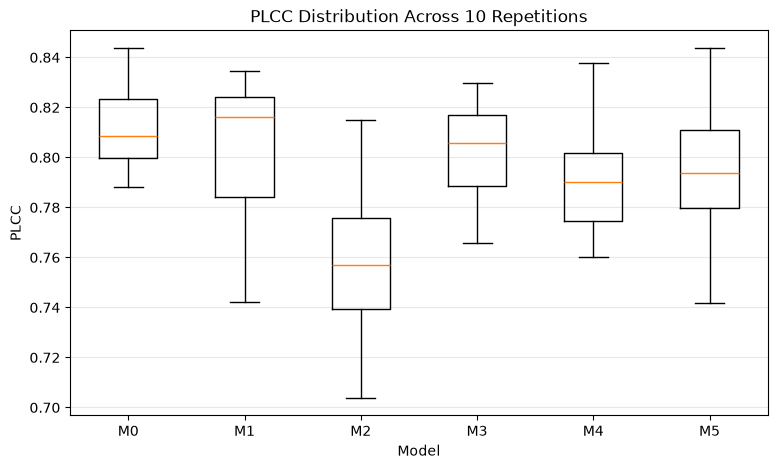

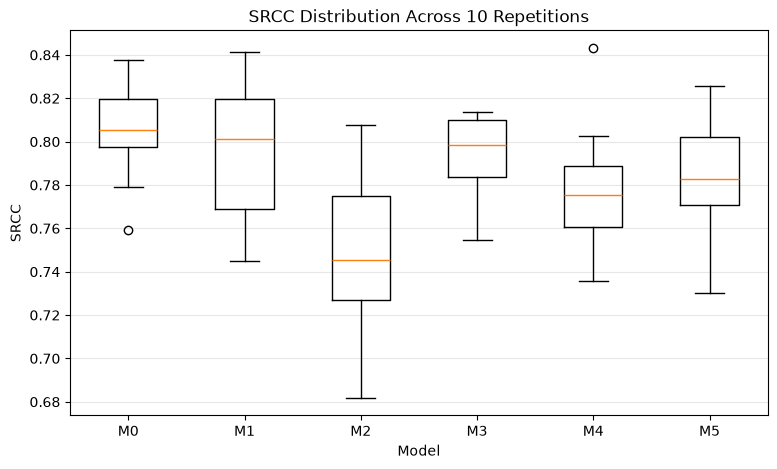

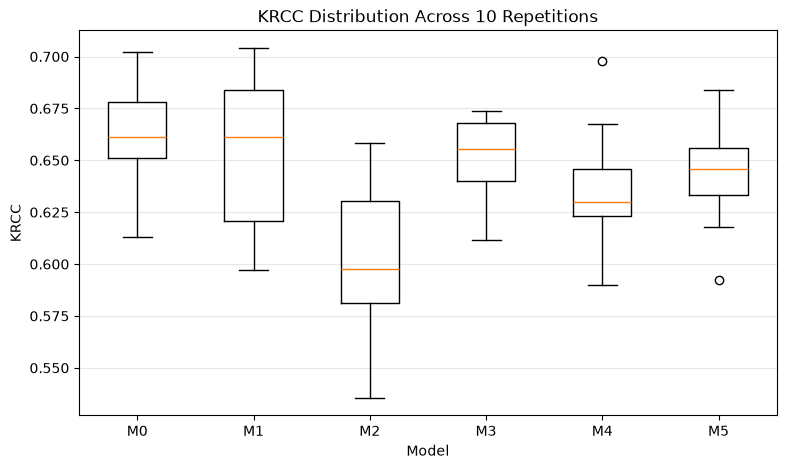

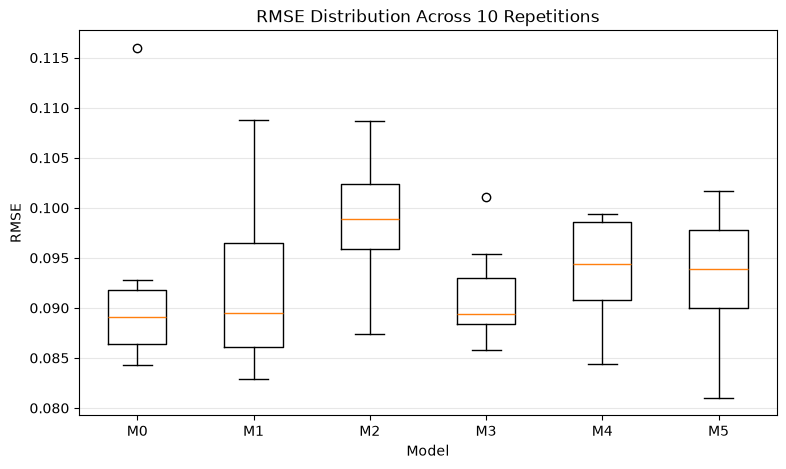

In [146]:
import matplotlib.pyplot as plt

for metric in metrics:

    plt.figure(figsize=(9, 5))

    data = [
        df[df["Model"] == model][metric].values
        for model in ["M0", "M1", "M2", "M3", "M4", "M5"]
    ]

    plt.boxplot(
        data,
        tick_labels=["M0", "M1", "M2", "M3", "M4", "M5"]
    )

    plt.title(f"{metric} Distribution Across 10 Repetitions")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

In [147]:
metrics = ["PLCC", "SRCC", "KRCC", "RMSE"]

for metric in metrics:

    pivot = df.pivot(
        index="Repetition",
        columns="Model",
        values=metric
    )

    # Higher correlation is better; lower RMSE is better.
    ascending = (metric == "RMSE")

    ranks = pivot.rank(
        axis=1,
        ascending=ascending,
        method="average"
    )

    print(f"\n{metric} — Average model ranking")
    print(ranks.mean().sort_values())


PLCC — Average model ranking
Model
M0    2.4
M1    2.8
M3    3.0
M5    3.6
M4    4.2
M2    5.0
dtype: float64

SRCC — Average model ranking
Model
M0    2.3
M3    2.9
M1    3.1
M5    3.5
M4    4.2
M2    5.0
dtype: float64

KRCC — Average model ranking
Model
M0    2.3
M3    2.9
M1    3.0
M5    3.5
M4    4.3
M2    5.0
dtype: float64

RMSE — Average model ranking
Model
M0    2.3
M1    3.0
M3    3.1
M5    3.8
M4    3.9
M2    4.9
dtype: float64


In [148]:
comparison = df[df["Model"].isin(["M4", "M5"])]

for metric in metrics:

    pivot = comparison.pivot(
        index="Repetition",
        columns="Model",
        values=metric
    )

    if metric == "RMSE":
        difference = pivot["M4"] - pivot["M5"]
    else:
        difference = pivot["M5"] - pivot["M4"]

    print(f"\n{'='*40}")
    print(metric)
    print(f"{'='*40}")

    print("Differences by repetition:")
    print(difference.round(6))

    print("Mean difference:", difference.mean())
    print("Median difference:", difference.median())
    print("Standard deviation:", difference.std())
    print("M5 wins:", (difference > 0).sum())
    print("M4 wins:", (difference < 0).sum())
    print("Ties:", (difference == 0).sum())


PLCC
Differences by repetition:
Repetition
1     0.003486
2     0.003357
3    -0.020171
4    -0.039227
5     0.018536
6     0.016842
7     0.005110
8     0.031672
9     0.042070
10   -0.017600
dtype: float64
Mean difference: 0.004407446969962481
Median difference: 0.004297715199650498
Standard deviation: 0.024744957616969834
M5 wins: 7
M4 wins: 3
Ties: 0

SRCC
Differences by repetition:
Repetition
1     0.021299
2    -0.017480
3     0.009678
4    -0.051194
5     0.022789
6     0.034259
7     0.016517
8     0.020526
9     0.033453
10   -0.028573
dtype: float64
Mean difference: 0.0061274988190340605
Median difference: 0.01852158691210759
Standard deviation: 0.028714995769249997
M5 wins: 7
M4 wins: 3
Ties: 0

KRCC
Differences by repetition:
Repetition
1     0.012821
2    -0.013808
3     0.006622
4    -0.040860
5     0.021839
6     0.041000
7     0.023811
8     0.020430
9     0.035646
10   -0.028180
dtype: float64
Mean difference: 0.007932308704941049
Median difference: 0.0166256302243510

In [149]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

folders = [
    PROJECT_DIR / "results",
    PROJECT_DIR / "results_M4_M5_new_rep01_02"
]

for folder in folders:

    print("\nFOLDER:", folder)

    for model in ["m0", "m1", "m2", "m3", "m4", "m5"]:

        files = sorted(folder.glob(f"{model}_rep*_history.csv"))

        if files:
            sample = pd.read_csv(files[0])

            print(f"\n{model.upper()} — {files[0].name}")
            print("Columns:", sample.columns.tolist())
            print(sample.head(3))


FOLDER: /home/karthikbaskar2/UWIQA_Research_Experiments/results

M0 — m0_rep01_history.csv
Columns: ['epoch', 'train_mse', 'val_mse', 'learning_rate', 'best_checkpoint_updated']
   epoch  train_mse   val_mse  learning_rate  best_checkpoint_updated
0      1   0.032957  0.013897         0.0001                     True
1      2   0.014795  0.011439         0.0001                     True
2      3   0.014886  0.010611         0.0001                     True

M1 — m1_rep01_history.csv
Columns: ['epoch', 'train_mse', 'val_mse', 'lr_backbone', 'lr_head', 'best_so_far']
   epoch  train_mse   val_mse  lr_backbone  lr_head  best_so_far
0      1   0.050432  0.011633       0.0001   0.0003         True
1      2   0.015846  0.008943       0.0001   0.0003         True
2      3   0.015393  0.014995       0.0001   0.0003        False

M2 — m2_rep01_history.csv
Columns: ['epoch', 'train_mse', 'val_mse', 'lr_backbone', 'lr_head', 'best_so_far']
   epoch  train_mse   val_mse  lr_backbone  lr_head  best_s

In [150]:
from pathlib import Path

PROJECT_DIR = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

folders = [
    PROJECT_DIR / "checkpoints",
    PROJECT_DIR / "checkpoints_M4_M5_new_rep01_02"
]

for folder in folders:

    print("\nFOLDER:", folder)

    if not folder.exists():
        print("Folder not found!")
        continue

    for file in sorted(folder.glob("*.pt")):
        print(file.name)


FOLDER: /home/karthikbaskar2/UWIQA_Research_Experiments/checkpoints
m0_rep01_best.pt
m0_rep02_best.pt
m0_rep03_best.pt
m0_rep04_best.pt
m0_rep05_best.pt
m0_rep06_best.pt
m0_rep07_best.pt
m0_rep08_best.pt
m0_rep09_best.pt
m0_rep10_best.pt
m1_rep01_best.pt
m1_rep02_best.pt
m1_rep02_corrected_best.pt
m1_rep03_best.pt
m1_rep04_best.pt
m1_rep05_best.pt
m1_rep06_best.pt
m1_rep07_best.pt
m1_rep08_best.pt
m1_rep09_best.pt
m1_rep10_best.pt
m2_rep01_best.pt
m2_rep02_best.pt
m2_rep03_best.pt
m2_rep04_best.pt
m2_rep05_best.pt
m2_rep06_best.pt
m2_rep07_best.pt
m2_rep08_best.pt
m2_rep09_best.pt
m2_rep10_best.pt
m3_rep01_best.pt
m3_rep02_best.pt
m3_rep03_best.pt
m3_rep04_best.pt
m3_rep05_best.pt
m3_rep06_best.pt
m3_rep07_best.pt
m3_rep08_best.pt
m3_rep09_best.pt
m3_rep10_best.pt
m4_rep01_best.pt
m4_rep02_best.pt
m4_rep03_best.pt
m4_rep04_best.pt
m4_rep05_best.pt
m4_rep06_best.pt
m4_rep07_best.pt
m4_rep08_best.pt
m4_rep09_best.pt
m4_rep10_best.pt
m5_rep01_best.pt
m5_rep02_best.pt
m5_rep03_best.pt
m5_

In [151]:
import torch
from pathlib import Path

PROJECT_DIR = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

checkpoint_files = {
    "M0": PROJECT_DIR / "checkpoints/m0_rep01_best.pt",
    "M1_corrected": PROJECT_DIR / "checkpoints/m1_rep02_corrected_best.pt",
    "M2": PROJECT_DIR / "checkpoints/m2_rep01_best.pt",
    "M3": PROJECT_DIR / "checkpoints/m3_rep01_best.pt",
    "M4_new": PROJECT_DIR / "checkpoints_M4_M5_new_rep01_02/m4_rep01_best.pt",
    "M5_new": PROJECT_DIR / "checkpoints_M4_M5_new_rep01_02/m5_rep01_best.pt"
}

for model_name, path in checkpoint_files.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("File:", path.name)

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print("Object type:", type(checkpoint))

    if isinstance(checkpoint, dict):

        print("Top-level keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():

            if isinstance(value, dict):
                print(f"\n{key}: dictionary")
                print("Number of entries:", len(value))
                print("First keys:", list(value.keys())[:8])

            elif isinstance(value, torch.Tensor):
                print(f"{key}: Tensor, shape={tuple(value.shape)}")

            else:
                print(f"{key}: {type(value).__name__}", str(value)[:150])


M0
File: m0_rep01_best.pt
Object type: <class 'dict'>
Top-level keys: ['model_state_dict', 'epoch', 'best_val_loss', 'seed', 'learning_rate', 'weight_decay', 'model_name', 'weights']

model_state_dict: dictionary
Number of entries: 322
First keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight']
epoch: int 23
best_val_loss: float 0.006691144637039138
seed: int 2027
learning_rate: float 0.0001
weight_decay: float 0.0001
model_name: str M0_Global_ResNet50
weights: str IMAGENET1K_V1

M1_corrected
File: m1_rep02_corrected_best.pt
Object type: <class 'dict'>
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'seed', 'model_name', 'weights']
epoch: int 7

model_state_dict: dictionary
Number of entries: 322
First keys: ['feature_extractor.0.weight', 'feature_extractor.1.weight', 'feature_extractor.1.bias', 'feature_extractor.1.running_mean', 'feature

In [152]:
from pathlib import Path

PROJECT_DIR = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")
HOME_DIR = Path("/home/karthikbaskar2")

print("=== PYTHON FILES ===")

for path in HOME_DIR.rglob("*.py"):
    if any(x in str(path) for x in [
        "UWIQA_Research_Experiments",
        "UWIQA"
    ]):
        print(path)

print("\n=== NOTEBOOK FILES ===")

for path in HOME_DIR.rglob("*.ipynb"):
    if any(x in str(path) for x in [
        "UWIQA_Research_Experiments",
        "UWIQA"
    ]):
        print(path)

print("\n=== SPLIT FILES ===")

for path in sorted((PROJECT_DIR / "splits").glob("*.csv")):
    print(path.name)

=== PYTHON FILES ===

=== NOTEBOOK FILES ===
/home/karthikbaskar2/6th_Oct_UWIQA_HybridModel_v3.ipynb
/home/karthikbaskar2/UWIQA_Dataset_Inspection.ipynb
/home/karthikbaskar2/.ipynb_checkpoints/6th_Oct_UWIQA_HybridModel_v3-checkpoint.ipynb
/home/karthikbaskar2/.ipynb_checkpoints/UWIQA_Dataset_Inspection-checkpoint.ipynb

=== SPLIT FILES ===
uwiqa_all_splits.csv
uwiqa_split_01.csv
uwiqa_split_02.csv
uwiqa_split_03.csv
uwiqa_split_04.csv
uwiqa_split_05.csv
uwiqa_split_06.csv
uwiqa_split_07.csv
uwiqa_split_08.csv
uwiqa_split_09.csv
uwiqa_split_10.csv


In [158]:

# ============================================================
# VALIDATION BASELINE — M0 TO M5, 10 REPETITIONS
# Validation only. No training. No test-set access.
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision.models import resnet50
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error


# ------------------------------------------------------------
# 1. PATHS AND DEVICE
# ------------------------------------------------------------

PROJECT_DIR = Path.home() / "UWIQA_Research_Experiments"

DATASET_DIR = PROJECT_DIR.parent / "UWIQA Dataset" / "UWIQA"
SPLIT_DIR = PROJECT_DIR / "splits"

OLD_CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
NEW_CHECKPOINT_DIR = PROJECT_DIR / "checkpoints_M4_M5_new_rep01_02"

OUTPUT_DIR = PROJECT_DIR / "analysis" / "validation_baseline_before_tuning"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert torch.cuda.is_available(), "Please select the Python (GPU) kernel."
assert DATASET_DIR.exists(), f"Dataset folder missing: {DATASET_DIR}"
assert SPLIT_DIR.exists(), f"Split folder missing: {SPLIT_DIR}"

# Do not overwrite previous validation results.
assert not OUTPUT_DIR.exists(), (
    f"Output folder already exists: {OUTPUT_DIR}\n"
    "Do not overwrite it. Choose a new output folder name."
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. CHECK REQUIRED MODEL DEFINITIONS
# ------------------------------------------------------------

required_classes = [
    "M1PatchAverageResNet",
    "M2PatchAttentionResNet",
    "M3SaliencyAwareResNet",
    "M4SolutionII",
    "M5MultiScaleSolutionII"
]

for class_name in required_classes:
    assert class_name in globals(), (
        f"{class_name} is not defined. Run Cell 114 first."
    )

assert "UWIQADataset" in globals(), "Run Cell 114 first."
assert "preprocess" in globals(), "Run Cell 114 first."


# ------------------------------------------------------------
# 3. M0 MODEL DEFINITION
# Same architecture as original M0.
# ------------------------------------------------------------

def create_m0():
    model = resnet50(weights=None)

    model.fc = nn.Sequential(
        nn.Linear(2048, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(0.3),
        nn.Linear(512, 1)
    )

    return model


# ------------------------------------------------------------
# 4. CHECKPOINT PATH SELECTION
# ------------------------------------------------------------

def get_checkpoint_path(model_name, repetition):

    # New M4/M5 Rep 1 and Rep 2 checkpoints
    if model_name in ["M4", "M5"] and repetition in [1, 2]:

        return (
            NEW_CHECKPOINT_DIR /
            f"{model_name.lower()}_rep{repetition:02d}_best.pt"
        )

    # Corrected M1 Rep 2 checkpoint
    if model_name == "M1" and repetition == 2:

        return OLD_CHECKPOINT_DIR / "m1_rep02_corrected_best.pt"

    # Other checkpoints
    return (
        OLD_CHECKPOINT_DIR /
        f"{model_name.lower()}_rep{repetition:02d}_best.pt"
    )


# ------------------------------------------------------------
# 5. MODEL CREATION
# ------------------------------------------------------------

def create_model(model_name):

    if model_name == "M0":
        return create_m0()

    elif model_name == "M1":
        return M1PatchAverageResNet()

    elif model_name == "M2":
        return M2PatchAttentionResNet()

    elif model_name == "M3":
        return M3SaliencyAwareResNet()

    elif model_name == "M4":
        return M4SolutionII(pretrained=False)

    elif model_name == "M5":
        return M5MultiScaleSolutionII(pretrained=False)

    raise ValueError(f"Unknown model: {model_name}")


# ------------------------------------------------------------
# 6. CHECK ALL 60 CHECKPOINT PATHS BEFORE EVALUATION
# ------------------------------------------------------------

models = ["M0", "M1", "M2", "M3", "M4", "M5"]

checkpoint_map = {}

for model_name in models:
    for repetition in range(1, 11):

        path = get_checkpoint_path(model_name, repetition)

        checkpoint_map[(model_name, repetition)] = path

missing = [
    str(path)
    for path in checkpoint_map.values()
    if not path.is_file()
]

if missing:
    print("Missing checkpoint files:")
    for path in missing:
        print(path)

    raise FileNotFoundError(
        "Evaluation stopped. No predictions have been generated."
    )

print("\nCheckpoint preflight: PASS")
print("Total checkpoint paths verified:", len(checkpoint_map))


# ------------------------------------------------------------
# 7. METRIC CALCULATION
# ------------------------------------------------------------

def calculate_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)

    assert len(actual) == 72
    assert len(predicted) == 72

    assert np.isfinite(actual).all()
    assert np.isfinite(predicted).all()

    return {
        "PLCC": pearsonr(actual, predicted).statistic,
        "SRCC": spearmanr(actual, predicted).statistic,
        "KRCC": kendalltau(
            actual, predicted, variant="b"
        ).statistic,
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }


# ------------------------------------------------------------
# 8. VALIDATION EVALUATION
# ------------------------------------------------------------

metric_rows = []
prediction_rows = []

for model_name in models:

    for repetition in range(1, 11):

        print(
            f"\nEvaluating {model_name} | "
            f"Repetition {repetition:02d}"
        )

        # Load original saved split
        split_path = (
            SPLIT_DIR /
            f"uwiqa_split_{repetition:02d}.csv"
        )

        split_df = pd.read_csv(split_path)

        val_df = split_df[
            split_df["split"] == "validation"
        ].copy()

        assert len(val_df) == 72, (
            f"Unexpected validation count in Rep {repetition}"
        )

        # Validation-only dataset and loader
        val_dataset = UWIQADataset(
            val_df,
            DATASET_DIR,
            preprocess
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=8,
            shuffle=False,
            num_workers=0
        )

        # Create corresponding architecture
        model = create_model(model_name).to(DEVICE)

        checkpoint_path = checkpoint_map[
            (model_name, repetition)
        ]

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )

        # Verify M4/M5 architecture identity
        if model_name in ["M4", "M5"]:

            expected_architecture = (
                "M4_SolutionII_3branch_v1"
                if model_name == "M4"
                else "M5_Multiscale_SolutionII_extension_v1"
            )

            actual_architecture = checkpoint.get(
                "architecture_version"
            )

            assert actual_architecture == expected_architecture, (
                f"Architecture mismatch: {checkpoint_path}\n"
                f"Expected: {expected_architecture}\n"
                f"Found: {actual_architecture}"
            )

        # Load weights
        model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True
        )

        model.eval()

        actual_scores = []
        predicted_scores = []
        image_names = []

        # Validation inference only
        with torch.inference_mode():

            for images, scores, filenames in val_loader:

                images = images.to(
                    DEVICE,
                    non_blocking=True
                )

                predictions = model(images).reshape(-1)

                actual_scores.extend(
                    scores.cpu().numpy().tolist()
                )

                predicted_scores.extend(
                    predictions.cpu().numpy().tolist()
                )

                image_names.extend(list(filenames))

        actual_scores = np.asarray(actual_scores)
        predicted_scores = np.asarray(predicted_scores)

        assert len(image_names) == 72
        assert len(set(image_names)) == 72

        metrics = calculate_metrics(
            actual_scores,
            predicted_scores
        )

        # Save metric row in memory
        metric_rows.append({
            "Model": model_name,
            "Repetition": repetition,
            "Checkpoint": checkpoint_path.name,
            "Best_Epoch": checkpoint.get("epoch"),
            "Best_Val_MSE": checkpoint.get(
                "best_val_loss",
                checkpoint.get("best_val_mse")
            ),
            **metrics
        })

        # Save validation predictions in memory
        for i in range(len(image_names)):

            prediction_rows.append({
                "Model": model_name,
                "Repetition": repetition,
                "Image": image_names[i],
                "Actual_Score": actual_scores[i],
                "Predicted_Score": predicted_scores[i]
            })

        print(
            f"PLCC={metrics['PLCC']:.4f} | "
            f"SRCC={metrics['SRCC']:.4f} | "
            f"KRCC={metrics['KRCC']:.4f} | "
            f"RMSE={metrics['RMSE']:.4f}"
        )

        del model, checkpoint, val_dataset, val_loader

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ------------------------------------------------------------
# 9. SAVE RESULTS TO A NEW FOLDER
# ------------------------------------------------------------

validation_metrics_df = pd.DataFrame(metric_rows)

validation_predictions_df = pd.DataFrame(
    prediction_rows
)

assert len(validation_metrics_df) == 60
assert len(validation_predictions_df) == 60 * 72

assert (
    validation_metrics_df.groupby("Model")["Repetition"].nunique()
    == 10
).all()

metrics_path = OUTPUT_DIR / "validation_metrics_all_models.csv"

predictions_path = (
    OUTPUT_DIR / "validation_predictions_all_models.csv"
)

validation_metrics_df.to_csv(
    metrics_path,
    index=False
)

validation_predictions_df.to_csv(
    predictions_path,
    index=False
)


# ------------------------------------------------------------
# 10. CALCULATE MEAN AND STANDARD DEVIATION
# ------------------------------------------------------------

metric_columns = ["PLCC", "SRCC", "KRCC", "RMSE"]

validation_summary = (
    validation_metrics_df
    .groupby("Model")[metric_columns]
    .agg(["mean", "std"])
)

validation_summary.columns = [
    f"{metric}_{stat.upper()}"
    for metric, stat in validation_summary.columns
]

validation_summary = validation_summary.reset_index()

summary_path = (
    OUTPUT_DIR / "validation_performance_summary.csv"
)

validation_summary.to_csv(
    summary_path,
    index=False
)


# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VALIDATION EVALUATION COMPLETED")
print("=" * 75)

print("\nINDIVIDUAL REPETITION RESULTS")
display(validation_metrics_df.round(5))

print("\nVALIDATION MEAN ± STANDARD DEVIATION")
display(validation_summary.round(5))

print("\nFILES SAVED:")
print(metrics_path)
print(predictions_path)
print(summary_path)

print("\nValidation evaluation: SUCCESS")
print("Test set accessed: NO")
print("Training performed: NO")


Device: cuda
GPU: NVIDIA A40

Checkpoint preflight: PASS
Total checkpoint paths verified: 60

Evaluating M0 | Repetition 01
PLCC=0.8531 | SRCC=0.8340 | KRCC=0.6943 | RMSE=0.0818

Evaluating M0 | Repetition 02
PLCC=0.7872 | SRCC=0.8076 | KRCC=0.6641 | RMSE=0.0969

Evaluating M0 | Repetition 03
PLCC=0.7997 | SRCC=0.8257 | KRCC=0.6839 | RMSE=0.0950

Evaluating M0 | Repetition 04
PLCC=0.8422 | SRCC=0.8099 | KRCC=0.6813 | RMSE=0.0845

Evaluating M0 | Repetition 05
PLCC=0.8618 | SRCC=0.8584 | KRCC=0.7132 | RMSE=0.0799

Evaluating M0 | Repetition 06
PLCC=0.8653 | SRCC=0.8608 | KRCC=0.7244 | RMSE=0.0843

Evaluating M0 | Repetition 07
PLCC=0.7876 | SRCC=0.7664 | KRCC=0.6296 | RMSE=0.0966

Evaluating M0 | Repetition 08
PLCC=0.8214 | SRCC=0.8125 | KRCC=0.6736 | RMSE=0.0916

Evaluating M0 | Repetition 09
PLCC=0.8191 | SRCC=0.7628 | KRCC=0.6279 | RMSE=0.0919

Evaluating M0 | Repetition 10
PLCC=0.8631 | SRCC=0.8723 | KRCC=0.7417 | RMSE=0.0794

Evaluating M1 | Repetition 01
PLCC=0.8683 | SRCC=0.8476 

,Model,Repetition,Checkpoint,Best_Epoch,Best_Val_MSE,PLCC,SRCC,KRCC,RMSE
0,M0,1,m0_rep01_best.pt,23,0.00669,0.85310,0.83403,0.69426,0.08180
1,M0,2,m0_rep02_best.pt,10,0.00939,0.78722,0.80763,0.66408,0.09692
2,M0,3,m0_rep03_best.pt,18,0.00902,0.79969,0.82567,0.68391,0.09496
3,M0,4,m0_rep04_best.pt,6,0.00715,0.84221,0.80987,0.68132,0.08454
4,M0,5,m0_rep05_best.pt,14,0.00639,0.86183,0.85837,0.71323,0.07992
5,M0,6,m0_rep06_best.pt,15,0.00710,0.86532,0.86082,0.72445,0.08427
6,M0,7,m0_rep07_best.pt,7,0.00934,0.78759,0.76642,0.62958,0.09665
7,M0,8,m0_rep08_best.pt,20,0.00839,0.82140,0.81253,0.67356,0.09161
8,M0,9,m0_rep09_best.pt,10,0.00844,0.81906,0.76279,0.62785,0.09185
9,M0,10,m0_rep10_best.pt,12,0.00631,0.86305,0.87235,0.74169,0.07941



VALIDATION MEAN ± STANDARD DEVIATION


,Model,PLCC_MEAN,PLCC_STD,SRCC_MEAN,SRCC_STD,KRCC_MEAN,KRCC_STD,RMSE_MEAN,RMSE_STD
0,M0,0.83005,0.03123,0.82105,0.03735,0.68339,0.03734,0.08819,0.00694
1,M1,0.81986,0.04625,0.80923,0.04479,0.67261,0.04801,0.09030,0.00946
2,M2,0.77967,0.03709,0.77150,0.03617,0.62578,0.03557,0.09919,0.00732
3,M3,0.81147,0.03642,0.80723,0.03602,0.66761,0.03458,0.09251,0.00818
4,M4,0.80096,0.02632,0.79274,0.03145,0.65390,0.03234,0.09592,0.00531
5,M5,0.82779,0.02286,0.82643,0.02766,0.68702,0.02823,0.08927,0.00535



FILES SAVED:
/home/karthikbaskar2/UWIQA_Research_Experiments/analysis/validation_baseline_before_tuning/validation_metrics_all_models.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/analysis/validation_baseline_before_tuning/validation_predictions_all_models.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/analysis/validation_baseline_before_tuning/validation_performance_summary.csv

Validation evaluation: SUCCESS
Test set accessed: NO
Training performed: NO


In [159]:
print("Device:", DEVICE)
print("Dataset directory:", DATASET_DIR)
print("M0:", "resnet50" in globals())
print("M1:", "M1PatchAverageResNet" in globals())
print("M2:", "M2PatchAttentionResNet" in globals())
print("M3:", "M3SaliencyAwareResNet" in globals())
print("M4:", "M4SolutionII" in globals())
print("M5:", "M5MultiScaleSolutionII" in globals())

Device: cuda
Dataset directory: /home/karthikbaskar2/UWIQA Dataset/UWIQA
M0: True
M1: True
M2: True
M3: True
M4: True
M5: True


In [ ]:
# ============================================================
# UWIQA — CONTROLLED HYPERPARAMETER SCREENING
# Models: M0, M1, M2, M3, M4, M5
# Repetitions: 01, 02, 03
# Selection: Mean validation MSE
# Test set: NOT USED
# ============================================================

import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error


# ------------------------------------------------------------
# 1. SAFETY CHECKS
# ------------------------------------------------------------

assert torch.cuda.is_available(), "CUDA GPU is not available."

assert all(name in globals() for name in [
    "M1PatchAverageResNet",
    "M2PatchAttentionResNet",
    "M3SaliencyAwareResNet",
    "M4SolutionII",
    "M5MultiScaleSolutionII",
    "UWIQADataset",
    "preprocess",
    "DEVICE",
    "DATASET_DIR",
    "PROJECT_DIR",
    "SPLIT_DIR"
]), "One or more required notebook definitions are missing."

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATASET_DIR)


# ------------------------------------------------------------
# 2. OUTPUT DIRECTORIES
# ------------------------------------------------------------

OUTPUT_DIR = PROJECT_DIR / "tuning_screening_v1"

# Never overwrite an earlier screening experiment.
if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"{OUTPUT_DIR} already exists. "
        "Inspect the existing results before creating another run."
    )

CHECKPOINT_DIR_TUNE = OUTPUT_DIR / "checkpoints"
HISTORY_DIR_TUNE = OUTPUT_DIR / "histories"
PREDICTION_DIR_TUNE = OUTPUT_DIR / "validation_predictions"

for folder in [
    CHECKPOINT_DIR_TUNE,
    HISTORY_DIR_TUNE,
    PREDICTION_DIR_TUNE
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Screening output:", OUTPUT_DIR)


# ------------------------------------------------------------
# 3. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

MODEL_ORDER = ["M0", "M1", "M2", "M3", "M4", "M5"]

REPETITIONS = [1, 2, 3]

LEARNING_RATES = [5e-5, 1e-4, 2e-4]

# For M1-M5, the head learning rate remains fixed.
HEAD_LR = 3e-4

WEIGHT_DECAY = 1e-4
BATCH_SIZE = 8
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 8
SCHEDULER_PATIENCE = 3
NUM_WORKERS = 0

criterion = nn.MSELoss()

print("\nModels:", MODEL_ORDER)
print("Repetitions:", REPETITIONS)
print("Learning rates:", LEARNING_RATES)
print("Head learning rate:", HEAD_LR)
print("Expected training runs:", len(MODEL_ORDER)
      * len(REPETITIONS) * len(LEARNING_RATES))


# ------------------------------------------------------------
# 4. REPRODUCIBILITY
# ------------------------------------------------------------

def set_tuning_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# 5. MODEL CREATION
# ------------------------------------------------------------

def create_tuning_model(model_name):

    if model_name == "M0":

        model = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        model.fc = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

        return model

    elif model_name == "M1":
        return M1PatchAverageResNet()

    elif model_name == "M2":
        return M2PatchAttentionResNet()

    elif model_name == "M3":
        return M3SaliencyAwareResNet()

    elif model_name == "M4":
        return M4SolutionII(pretrained=True)

    elif model_name == "M5":
        return M5MultiScaleSolutionII(pretrained=True)

    else:
        raise ValueError(f"Unknown model: {model_name}")


# ------------------------------------------------------------
# 6. OPTIMIZER CREATION
# ------------------------------------------------------------

def create_tuning_optimizer(model_name, model, backbone_lr):

    # M0 uses one learning rate for all parameters.
    if model_name == "M0":

        return torch.optim.Adam(
            model.parameters(),
            lr=backbone_lr,
            weight_decay=WEIGHT_DECAY
        )

    # M1-M3 use feature_extractor as backbone.
    # M4-M5 use backbone as backbone.
    if model_name in ["M1", "M2", "M3"]:
        backbone = model.feature_extractor
    else:
        backbone = model.backbone

    backbone_parameter_ids = {
        id(parameter)
        for parameter in backbone.parameters()
    }

    head_parameters = [
        parameter
        for parameter in model.parameters()
        if id(parameter) not in backbone_parameter_ids
    ]

    return torch.optim.Adam(
        [
            {
                "params": backbone.parameters(),
                "lr": backbone_lr
            },
            {
                "params": head_parameters,
                "lr": HEAD_LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )


# ------------------------------------------------------------
# 7. TRAINING / VALIDATION EPOCH
# ------------------------------------------------------------

def run_tuning_epoch(model, loader, optimizer=None):

    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_count = 0

    context = (
        torch.enable_grad()
        if training
        else torch.inference_mode()
    )

    with context:

        for images, scores, _filenames in loader:

            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float().reshape(-1)

            if training:
                optimizer.zero_grad(set_to_none=True)

            predictions = model(images).reshape(-1)

            loss = criterion(predictions, scores)

            if training:
                loss.backward()
                optimizer.step()

            count = images.size(0)

            total_loss += loss.detach().item() * count
            total_count += count

    return total_loss / total_count


# ------------------------------------------------------------
# 8. VALIDATION PREDICTIONS AND METRICS
# ------------------------------------------------------------

@torch.inference_mode()
def get_validation_predictions(model, loader):

    model.eval()

    predictions = []
    actual_scores = []
    filenames = []

    for images, scores, image_names in loader:

        images = images.to(DEVICE)

        outputs = model(images).reshape(-1)

        predictions.extend(
            outputs.detach().cpu().numpy().tolist()
        )

        actual_scores.extend(
            scores.reshape(-1).cpu().numpy().tolist()
        )

        filenames.extend(list(image_names))

    return (
        np.asarray(predictions),
        np.asarray(actual_scores),
        filenames
    )


def calculate_validation_metrics(predictions, actual):

    predictions = np.asarray(predictions).reshape(-1)
    actual = np.asarray(actual).reshape(-1)

    return {
        "MSE": float(mean_squared_error(actual, predictions)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, predictions))),
        "PLCC": float(pearsonr(actual, predictions)[0]),
        "SRCC": float(spearmanr(actual, predictions)[0]),
        "KRCC": float(kendalltau(actual, predictions)[0])
    }


# ------------------------------------------------------------
# 9. SCREENING EXPERIMENT
# ------------------------------------------------------------

all_run_results = []

for repetition in REPETITIONS:

    print("\n" + "=" * 75)
    print(f"SCREENING REPETITION {repetition:02d}")
    print("=" * 75)

    # Load the original split file.
    split_path = (
        SPLIT_DIR / f"uwiqa_split_{repetition:02d}.csv"
    )

    assert split_path.is_file(), (
        f"Missing split file: {split_path}"
    )

    split_df = pd.read_csv(split_path)

    required_columns = {"filename", "score", "split"}

    assert required_columns.issubset(split_df.columns)

    train_df = split_df[
        split_df["split"] == "train"
    ].copy()

    val_df = split_df[
        split_df["split"].isin(["validation", "val"])
    ].copy()

    # We deliberately do not create a test dataset or test loader.
    assert len(train_df) == 640
    assert len(val_df) == 72

    assert set(train_df["filename"]).isdisjoint(
        set(val_df["filename"])
    )

    split_seed = (
        int(split_df["seed"].iloc[0])
        if "seed" in split_df.columns
        else 2026 + repetition
    )

    print(
        f"Seed: {split_seed} | "
        f"Train: {len(train_df)} | "
        f"Validation: {len(val_df)}"
    )

    train_dataset = UWIQADataset(
        train_df, DATASET_DIR, preprocess
    )

    val_dataset = UWIQADataset(
        val_df, DATASET_DIR, preprocess
    )

    for model_name in MODEL_ORDER:

        for candidate_lr in LEARNING_RATES:

            print("\n" + "-" * 70)
            print(
                f"MODEL: {model_name} | "
                f"REP: {repetition:02d} | "
                f"BACKBONE / MODEL LR: {candidate_lr}"
            )
            print("-" * 70)

            run_name = (
                f"{model_name.lower()}_rep{repetition:02d}"
                f"_lr{candidate_lr:.0e}"
            )

            checkpoint_path = (
                CHECKPOINT_DIR_TUNE / f"{run_name}_best.pt"
            )

            history_path = (
                HISTORY_DIR_TUNE / f"{run_name}_history.csv"
            )

            prediction_path = (
                PREDICTION_DIR_TUNE / f"{run_name}_val_predictions.csv"
            )

            for output_path in [
                checkpoint_path,
                history_path,
                prediction_path
            ]:
                if output_path.exists():
                    raise FileExistsError(output_path)

            # Same seed for each LR candidate within this
            # model/repetition combination.
            set_tuning_seed(split_seed)

            generator = torch.Generator()
            generator.manual_seed(split_seed)

            train_loader = DataLoader(
                train_dataset,
                batch_size=BATCH_SIZE,
                shuffle=True,
                num_workers=NUM_WORKERS,
                generator=generator
            )

            val_loader = DataLoader(
                val_dataset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS
            )

            model = create_tuning_model(model_name).to(DEVICE)

            optimizer = create_tuning_optimizer(
                model_name,
                model,
                candidate_lr
            )

            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer,
                mode="min",
                factor=0.5,
                patience=SCHEDULER_PATIENCE
            )

            best_val_loss = float("inf")
            best_epoch = 0
            no_improvement = 0

            history_rows = []

            start_time = time.time()

            # ---------------- TRAINING ----------------

            for epoch in range(1, MAX_EPOCHS + 1):

                train_loss = run_tuning_epoch(
                    model,
                    train_loader,
                    optimizer
                )

                val_loss = run_tuning_epoch(
                    model,
                    val_loader,
                    optimizer=None
                )

                scheduler.step(val_loss)

                history_rows.append({
                    "epoch": epoch,
                    "train_loss": train_loss,
                    "val_loss": val_loss
                })

                print(
                    f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
                    f"Train MSE: {train_loss:.6f} | "
                    f"Val MSE: {val_loss:.6f}"
                )

                # Save the best checkpoint using validation MSE.
                if val_loss < best_val_loss:

                    best_val_loss = val_loss
                    best_epoch = epoch
                    no_improvement = 0

                    torch.save(
                        {
                            "model_state_dict": model.state_dict(),
                            "model_name": model_name,
                            "repetition": repetition,
                            "seed": split_seed,
                            "learning_rate": candidate_lr,
                            "head_lr": (
                                None if model_name == "M0"
                                else HEAD_LR
                            ),
                            "weight_decay": WEIGHT_DECAY,
                            "best_epoch": best_epoch,
                            "best_val_loss": best_val_loss
                        },
                        checkpoint_path
                    )

                else:
                    no_improvement += 1

                if no_improvement >= EARLY_STOPPING_PATIENCE:

                    print(
                        "Early stopping triggered at epoch",
                        epoch
                    )

                    break

            # ---------------- EVALUATION ----------------

            # Restore the best validation checkpoint.
            checkpoint = torch.load(
                checkpoint_path,
                map_location=DEVICE,
                weights_only=True
            )

            model.load_state_dict(
                checkpoint["model_state_dict"]
            )

            predictions, actual, filenames = (
                get_validation_predictions(model, val_loader)
            )

            metrics = calculate_validation_metrics(
                predictions, actual
            )

            prediction_df = pd.DataFrame({
                "filename": filenames,
                "actual_score": actual,
                "predicted_score": predictions
            })

            prediction_df.to_csv(
                prediction_path,
                index=False
            )

            pd.DataFrame(history_rows).to_csv(
                history_path,
                index=False
            )

            elapsed = time.time() - start_time

            result = {
                "model": model_name,
                "repetition": repetition,
                "learning_rate": candidate_lr,
                "head_lr": (
                    np.nan if model_name == "M0"
                    else HEAD_LR
                ),
                "best_epoch": best_epoch,
                "best_val_loss": best_val_loss,
                **metrics,
                "elapsed_seconds": elapsed
            }

            all_run_results.append(result)

            print("\nBest validation result:")
            print(json.dumps(result, indent=2))

            del model
            del optimizer
            del scheduler
            del train_loader
            del val_loader

            gc.collect()
            torch.cuda.empty_cache()


# ------------------------------------------------------------
# 10. SAVE SCREENING RESULTS
# ------------------------------------------------------------

screening_df = pd.DataFrame(all_run_results)

screening_path = OUTPUT_DIR / "screening_all_runs.csv"

screening_df.to_csv(
    screening_path,
    index=False
)


# ------------------------------------------------------------
# 11. LEARNING-RATE COMPARISON
# ------------------------------------------------------------

comparison_df = (
    screening_df
    .groupby(["model", "learning_rate"])
    .agg(
        repetitions=("repetition", "nunique"),

        mean_val_mse=("MSE", "mean"),
        std_val_mse=("MSE", "std"),

        mean_val_rmse=("RMSE", "mean"),
        std_val_rmse=("RMSE", "std"),

        mean_plcc=("PLCC", "mean"),
        std_plcc=("PLCC", "std"),

        mean_srcc=("SRCC", "mean"),
        std_srcc=("SRCC", "std"),

        mean_krcc=("KRCC", "mean"),
        std_krcc=("KRCC", "std")
    )
    .reset_index()
    .sort_values(
        ["model", "mean_val_mse"],
        ascending=[True, True]
    )
)

comparison_path = (
    OUTPUT_DIR / "learning_rate_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ------------------------------------------------------------
# 12. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("HYPERPARAMETER SCREENING COMPLETED")
print("=" * 75)

print("\nAll screening runs:")
display(screening_df)

print("\nLearning-rate comparison:")
display(comparison_df)

print("\nSaved files:")
print(screening_path)
print(comparison_path)

print("\nScreening output directory:")
print(OUTPUT_DIR)

Device: cuda
GPU: NVIDIA A40
Dataset: /home/karthikbaskar2/UWIQA Dataset/UWIQA
Screening output: /home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1

Models: ['M0', 'M1', 'M2', 'M3', 'M4', 'M5']
Repetitions: [1, 2, 3]
Learning rates: [5e-05, 0.0001, 0.0002]
Head learning rate: 0.0003
Expected training runs: 54

SCREENING REPETITION 01
Seed: 2027 | Train: 640 | Validation: 72

----------------------------------------------------------------------
MODEL: M0 | REP: 01 | BACKBONE / MODEL LR: 5e-05
----------------------------------------------------------------------
Epoch 01/50 | Train MSE: 0.029907 | Val MSE: 0.012105
Epoch 02/50 | Train MSE: 0.013218 | Val MSE: 0.009391
Epoch 03/50 | Train MSE: 0.012353 | Val MSE: 0.009616
Epoch 04/50 | Train MSE: 0.010785 | Val MSE: 0.014456
Epoch 05/50 | Train MSE: 0.008996 | Val MSE: 0.010987
Epoch 06/50 | Train MSE: 0.008746 | Val MSE: 0.007708
Epoch 07/50 | Train MSE: 0.009569 | Val MSE: 0.009949
Epoch 08/50 | Train MSE: 0.006277 | 

In [161]:
# ============================================================
# UWIQA — LEARNING-RATE CONFIRMATION EXPERIMENT
# Models: M0, M1, M2, M3, M4, M5
# Repetitions: 04–10
# One selected learning rate per model
# Test set: NOT USED
# ============================================================

import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.metrics import mean_squared_error


# ------------------------------------------------------------
# 1. SAFETY CHECKS
# ------------------------------------------------------------

assert torch.cuda.is_available(), "CUDA GPU is not available."

assert all(name in globals() for name in [
    "M1PatchAverageResNet",
    "M2PatchAttentionResNet",
    "M3SaliencyAwareResNet",
    "M4SolutionII",
    "M5MultiScaleSolutionII",
    "UWIQADataset",
    "preprocess",
    "DEVICE",
    "DATASET_DIR",
    "PROJECT_DIR",
    "SPLIT_DIR"
]), "Required notebook definitions are missing."

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATASET_DIR)


# ------------------------------------------------------------
# 2. CONFIRMATION OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR_CONFIRM = PROJECT_DIR / "tuning_confirmation_v1"

# Never overwrite previous confirmation results.
if OUTPUT_DIR_CONFIRM.exists():
    raise FileExistsError(
        f"{OUTPUT_DIR_CONFIRM} already exists.\n"
        "Inspect its contents before proceeding. "
        "Do not delete or overwrite existing results."
    )

CHECKPOINT_DIR_CONFIRM = OUTPUT_DIR_CONFIRM / "checkpoints"
HISTORY_DIR_CONFIRM = OUTPUT_DIR_CONFIRM / "histories"
PREDICTION_DIR_CONFIRM = OUTPUT_DIR_CONFIRM / "validation_predictions"

for folder in [
    CHECKPOINT_DIR_CONFIRM,
    HISTORY_DIR_CONFIRM,
    PREDICTION_DIR_CONFIRM
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Confirmation output:", OUTPUT_DIR_CONFIRM)


# ------------------------------------------------------------
# 3. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

MODEL_ORDER = ["M0", "M1", "M2", "M3", "M4", "M5"]

REPETITIONS_CONFIRM = list(range(4, 11))

# Selected from screening Repetitions 1–3 using mean validation MSE.
SELECTED_LR = {
    "M0": 2e-4,
    "M1": 5e-5,
    "M2": 1e-4,
    "M3": 1e-4,
    "M4": 5e-5,
    "M5": 1e-4
}

HEAD_LR_CONFIRM = 3e-4

WEIGHT_DECAY_CONFIRM = 1e-4
BATCH_SIZE_CONFIRM = 8
MAX_EPOCHS_CONFIRM = 50
EARLY_STOPPING_PATIENCE_CONFIRM = 8
SCHEDULER_PATIENCE_CONFIRM = 3
NUM_WORKERS_CONFIRM = 0

criterion_confirm = nn.MSELoss()

print("Models:", MODEL_ORDER)
print("Repetitions:", REPETITIONS_CONFIRM)
print("Selected learning rates:", SELECTED_LR)
print("Head LR:", HEAD_LR_CONFIRM)
print("Expected runs:", len(MODEL_ORDER) * len(REPETITIONS_CONFIRM))


# ------------------------------------------------------------
# 4. REPRODUCIBILITY
# ------------------------------------------------------------

def set_confirmation_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# 5. MODEL CREATION
# ------------------------------------------------------------

def create_confirmation_model(model_name):

    if model_name == "M0":

        model = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V1
        )

        model.fc = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

        return model

    elif model_name == "M1":
        return M1PatchAverageResNet()

    elif model_name == "M2":
        return M2PatchAttentionResNet()

    elif model_name == "M3":
        return M3SaliencyAwareResNet()

    elif model_name == "M4":
        return M4SolutionII(pretrained=True)

    elif model_name == "M5":
        return M5MultiScaleSolutionII(pretrained=True)

    else:
        raise ValueError(f"Unknown model: {model_name}")


# ------------------------------------------------------------
# 6. OPTIMIZER CREATION
# ------------------------------------------------------------

def create_confirmation_optimizer(model_name, model, backbone_lr):

    # M0 uses one learning rate for all parameters.
    if model_name == "M0":

        return torch.optim.Adam(
            model.parameters(),
            lr=backbone_lr,
            weight_decay=WEIGHT_DECAY_CONFIRM
        )

    # M1–M3 use feature_extractor as backbone.
    # M4–M5 use backbone as backbone.
    if model_name in ["M1", "M2", "M3"]:
        backbone = model.feature_extractor
    else:
        backbone = model.backbone

    backbone_parameter_ids = {
        id(parameter)
        for parameter in backbone.parameters()
    }

    head_parameters = [
        parameter
        for parameter in model.parameters()
        if id(parameter) not in backbone_parameter_ids
    ]

    return torch.optim.Adam(
        [
            {
                "params": backbone.parameters(),
                "lr": backbone_lr
            },
            {
                "params": head_parameters,
                "lr": HEAD_LR_CONFIRM
            }
        ],
        weight_decay=WEIGHT_DECAY_CONFIRM
    )


# ------------------------------------------------------------
# 7. TRAINING / VALIDATION EPOCH
# ------------------------------------------------------------

def run_confirmation_epoch(model, loader, optimizer=None):

    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_count = 0

    context = (
        torch.enable_grad()
        if training
        else torch.inference_mode()
    )

    with context:

        for images, scores, _filenames in loader:

            images = images.to(DEVICE)
            scores = scores.to(DEVICE).float().reshape(-1)

            if training:
                optimizer.zero_grad(set_to_none=True)

            predictions = model(images).reshape(-1)

            loss = criterion_confirm(predictions, scores)

            if training:
                loss.backward()
                optimizer.step()

            count = images.size(0)

            total_loss += loss.detach().item() * count
            total_count += count

    return total_loss / total_count


# ------------------------------------------------------------
# 8. VALIDATION PREDICTIONS AND METRICS
# ------------------------------------------------------------

@torch.inference_mode()
def get_confirmation_predictions(model, loader):

    model.eval()

    predictions = []
    actual_scores = []
    filenames = []

    for images, scores, image_names in loader:

        images = images.to(DEVICE)

        outputs = model(images).reshape(-1)

        predictions.extend(
            outputs.detach().cpu().numpy().tolist()
        )

        actual_scores.extend(
            scores.reshape(-1).cpu().numpy().tolist()
        )

        filenames.extend(list(image_names))

    return (
        np.asarray(predictions),
        np.asarray(actual_scores),
        filenames
    )


def calculate_confirmation_metrics(predictions, actual):

    predictions = np.asarray(predictions).reshape(-1)
    actual = np.asarray(actual).reshape(-1)

    mse = mean_squared_error(actual, predictions)

    return {
        "MSE": float(mse),
        "RMSE": float(np.sqrt(mse)),
        "PLCC": float(pearsonr(actual, predictions)[0]),
        "SRCC": float(spearmanr(actual, predictions)[0]),
        "KRCC": float(kendalltau(actual, predictions)[0])
    }


# ------------------------------------------------------------
# 9. CONFIRMATION EXPERIMENT
# ------------------------------------------------------------

all_confirmation_results = []

for repetition in REPETITIONS_CONFIRM:

    print("\n" + "=" * 75)
    print(f"CONFIRMATION REPETITION {repetition:02d}")
    print("=" * 75)

    split_path = (
        SPLIT_DIR / f"uwiqa_split_{repetition:02d}.csv"
    )

    assert split_path.is_file(), (
        f"Missing split file: {split_path}"
    )

    split_df = pd.read_csv(split_path)

    required_columns = {"filename", "score", "split"}

    assert required_columns.issubset(split_df.columns), (
        f"Missing columns in {split_path}"
    )

    train_df = split_df[
        split_df["split"] == "train"
    ].copy()

    val_df = split_df[
        split_df["split"].isin(["validation", "val"])
    ].copy()

    # Test rows are not used to create datasets or loaders.
    assert len(train_df) == 640
    assert len(val_df) == 72

    assert set(train_df["filename"]).isdisjoint(
        set(val_df["filename"])
    )

    split_seed = (
        int(split_df["seed"].iloc[0])
        if "seed" in split_df.columns
        else 2026 + repetition
    )

    print(
        f"Seed: {split_seed} | "
        f"Train: {len(train_df)} | "
        f"Validation: {len(val_df)}"
    )

    train_dataset = UWIQADataset(
        train_df, DATASET_DIR, preprocess
    )

    val_dataset = UWIQADataset(
        val_df, DATASET_DIR, preprocess
    )

    for model_name in MODEL_ORDER:

        candidate_lr = SELECTED_LR[model_name]

        print("\n" + "-" * 70)
        print(
            f"MODEL: {model_name} | "
            f"REP: {repetition:02d} | "
            f"SELECTED LR: {candidate_lr}"
        )
        print("-" * 70)

        run_name = (
            f"{model_name.lower()}_rep{repetition:02d}"
            f"_lr{candidate_lr:.0e}"
        )

        checkpoint_path = (
            CHECKPOINT_DIR_CONFIRM / f"{run_name}_best.pt"
        )

        history_path = (
            HISTORY_DIR_CONFIRM / f"{run_name}_history.csv"
        )

        prediction_path = (
            PREDICTION_DIR_CONFIRM
            / f"{run_name}_val_predictions.csv"
        )

        # Safety: do not overwrite any run.
        for output_path in [
            checkpoint_path,
            history_path,
            prediction_path
        ]:
            if output_path.exists():
                raise FileExistsError(output_path)

        set_confirmation_seed(split_seed)

        generator = torch.Generator()
        generator.manual_seed(split_seed)

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE_CONFIRM,
            shuffle=True,
            num_workers=NUM_WORKERS_CONFIRM,
            generator=generator
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=BATCH_SIZE_CONFIRM,
            shuffle=False,
            num_workers=NUM_WORKERS_CONFIRM
        )

        model = create_confirmation_model(model_name).to(DEVICE)

        optimizer = create_confirmation_optimizer(
            model_name,
            model,
            candidate_lr
        )

        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=SCHEDULER_PATIENCE_CONFIRM
        )

        best_val_loss = float("inf")
        best_epoch = 0
        no_improvement = 0

        history_rows = []

        start_time = time.time()

        # ---------------- TRAINING ----------------

        for epoch in range(1, MAX_EPOCHS_CONFIRM + 1):

            train_loss = run_confirmation_epoch(
                model,
                train_loader,
                optimizer
            )

            val_loss = run_confirmation_epoch(
                model,
                val_loader,
                optimizer=None
            )

            scheduler.step(val_loss)

            history_rows.append({
                "epoch": epoch,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            print(
                f"Epoch {epoch:02d}/{MAX_EPOCHS_CONFIRM} | "
                f"Train MSE: {train_loss:.6f} | "
                f"Val MSE: {val_loss:.6f}"
            )

            if val_loss < best_val_loss:

                best_val_loss = val_loss
                best_epoch = epoch
                no_improvement = 0

                torch.save(
                    {
                        "model_state_dict": model.state_dict(),
                        "model_name": model_name,
                        "repetition": repetition,
                        "seed": split_seed,
                        "learning_rate": candidate_lr,
                        "head_lr": (
                            None if model_name == "M0"
                            else HEAD_LR_CONFIRM
                        ),
                        "weight_decay": WEIGHT_DECAY_CONFIRM,
                        "best_epoch": best_epoch,
                        "best_val_loss": best_val_loss
                    },
                    checkpoint_path
                )

            else:
                no_improvement += 1

            if no_improvement >= EARLY_STOPPING_PATIENCE_CONFIRM:

                print(
                    "Early stopping triggered at epoch",
                    epoch
                )

                break

        # ---------------- EVALUATION ----------------

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        predictions, actual, filenames = (
            get_confirmation_predictions(model, val_loader)
        )

        metrics = calculate_confirmation_metrics(
            predictions, actual
        )

        prediction_df = pd.DataFrame({
            "filename": filenames,
            "actual_score": actual,
            "predicted_score": predictions
        })

        prediction_df.to_csv(
            prediction_path,
            index=False
        )

        pd.DataFrame(history_rows).to_csv(
            history_path,
            index=False
        )

        elapsed = time.time() - start_time

        result = {
            "model": model_name,
            "repetition": repetition,
            "learning_rate": candidate_lr,
            "head_lr": (
                np.nan if model_name == "M0"
                else HEAD_LR_CONFIRM
            ),
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            **metrics,
            "elapsed_seconds": elapsed
        }

        all_confirmation_results.append(result)

        # Save progress after EVERY completed run.
        # If the notebook disconnects later, completed results remain.
        progress_path = (
            OUTPUT_DIR_CONFIRM
            / "confirmation_progress.csv"
        )

        pd.DataFrame(
            all_confirmation_results
        ).to_csv(
            progress_path,
            index=False
        )

        print("\nBest validation result:")
        print(json.dumps(result, indent=2))

        print("Progress saved:", progress_path)

        del model
        del optimizer
        del scheduler
        del train_loader
        del val_loader

        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 10. SAVE FINAL CONFIRMATION RESULTS
# ------------------------------------------------------------

confirmation_df = pd.DataFrame(
    all_confirmation_results
)

confirmation_path = (
    OUTPUT_DIR_CONFIRM / "confirmation_all_runs.csv"
)

confirmation_df.to_csv(
    confirmation_path,
    index=False
)

print("\n" + "=" * 75)
print("LEARNING-RATE CONFIRMATION COMPLETED")
print("=" * 75)

print("\nConfirmation results:")
display(confirmation_df)

print("\nSaved file:")
print(confirmation_path)

print("\nOutput directory:")
print(OUTPUT_DIR_CONFIRM)

Device: cuda
GPU: NVIDIA A40
Dataset: /home/karthikbaskar2/UWIQA Dataset/UWIQA
Confirmation output: /home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1
Models: ['M0', 'M1', 'M2', 'M3', 'M4', 'M5']
Repetitions: [4, 5, 6, 7, 8, 9, 10]
Selected learning rates: {'M0': 0.0002, 'M1': 5e-05, 'M2': 0.0001, 'M3': 0.0001, 'M4': 5e-05, 'M5': 0.0001}
Head LR: 0.0003
Expected runs: 42

CONFIRMATION REPETITION 04
Seed: 2030 | Train: 640 | Validation: 72

----------------------------------------------------------------------
MODEL: M0 | REP: 04 | SELECTED LR: 0.0002
----------------------------------------------------------------------
Epoch 01/50 | Train MSE: 0.030765 | Val MSE: 0.016561
Epoch 02/50 | Train MSE: 0.019119 | Val MSE: 0.011651
Epoch 03/50 | Train MSE: 0.015392 | Val MSE: 0.013178
Epoch 04/50 | Train MSE: 0.012441 | Val MSE: 0.018173
Epoch 05/50 | Train MSE: 0.012498 | Val MSE: 0.007726
Epoch 06/50 | Train MSE: 0.011973 | Val MSE: 0.007522
Epoch 07/50 | Train MSE: 0.0

,model,repetition,learning_rate,head_lr,best_epoch,best_val_loss,MSE,RMSE,PLCC,SRCC,KRCC,elapsed_seconds
0,M0,4,0.00020,NaN,9,0.007113,0.007113,0.084336,0.850246,0.850346,0.718409,600.322337
1,M1,4,0.00005,0.0003,18,0.007423,0.007423,0.086156,0.839346,0.801190,0.669250,1147.703223
2,M2,4,0.00010,0.0003,12,0.009591,0.009591,0.097935,0.785840,0.769568,0.620091,940.084138
3,M3,4,0.00010,0.0003,12,0.007402,0.007402,0.086033,0.836918,0.834437,0.695986,1031.194545
4,M4,4,0.00005,0.0003,6,0.008907,0.008907,0.094379,0.806262,0.801452,0.668388,769.145400
5,M5,4,0.00010,0.0003,6,0.008530,0.008530,0.092357,0.810879,0.793194,0.660626,648.804999
6,M0,5,0.00020,NaN,8,0.007165,0.007165,0.084647,0.850741,0.834781,0.691673,623.902678
7,M1,5,0.00005,0.0003,4,0.008719,0.008719,0.093375,0.803623,0.779649,0.651139,446.774791
8,M2,5,0.00010,0.0003,5,0.012496,0.012496,0.111786,0.723079,0.736765,0.591631,507.565762
9,M3,5,0.00010,0.0003,16,0.007863,0.007863,0.088672,0.828473,0.825505,0.680462,826.130537



Saved file:
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1/confirmation_all_runs.csv

Output directory:
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1


In [163]:
from pathlib import Path

RESULTS_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

print("Does the results folder exist?", RESULTS_DIR.exists())

if RESULTS_DIR.exists():
    print("\nFiles in the results folder:")
    for file in RESULTS_DIR.rglob("*"):
        if file.is_file():
            print(file)

Does the results folder exist? True

Files in the results folder:
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep06_scatter_plot.png
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep05_scatter_plot.png
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep04_scatter_plot.png
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep06_predictions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep01_test_predictions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep03_loss_curve.png
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m4_rep03_loss_curve.png
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep02_scatter_plot.png
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep05_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep10_scatter_plot.png
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep08_actual_vs_predicted.png
/home/karthikbaskar2/UWIQA_Rese

In [164]:
from pathlib import Path

EXPERIMENT_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments"
)

result_files = [
    file for file in EXPERIMENT_DIR.rglob("*")
    if file.is_file()
    and file.suffix.lower() in [".csv", ".xlsx", ".xls"]
]

print("Available result files:\n")

for i, file in enumerate(result_files):
    print(f"{i}: {file}")

Available result files:

0: /home/karthikbaskar2/UWIQA_Research_Experiments/analysis/UWIQA_Model_Performance_Summary.csv
1: /home/karthikbaskar2/UWIQA_Research_Experiments/analysis/UWIQA_All_Models_10_Repetitions.csv
2: /home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1/confirmation_all_runs.csv
3: /home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1/confirmation_progress.csv
4: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep06_predictions.csv
5: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep01_test_predictions.csv
6: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep05_history.csv
7: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep05_metrics.csv
8: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep09_history.csv
9: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep10_predictions.csv
10: /home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_metrics.csv
11: /

In [165]:
import pandas as pd
from pathlib import Path

RESULTS_FILE = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "tuning_confirmation_v1/confirmation_all_runs.csv"
)

df = pd.read_csv(RESULTS_FILE)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

print("\nAll rows:")
display(df)

Shape: (42, 12)

Columns:
['model', 'repetition', 'learning_rate', 'head_lr', 'best_epoch', 'best_val_loss', 'MSE', 'RMSE', 'PLCC', 'SRCC', 'KRCC', 'elapsed_seconds']

First 10 rows:


,model,repetition,learning_rate,head_lr,best_epoch,best_val_loss,MSE,RMSE,PLCC,SRCC,KRCC,elapsed_seconds
0,M0,4,0.00020,NaN,9,0.007113,0.007113,0.084336,0.850246,0.850346,0.718409,600.322337
1,M1,4,0.00005,0.0003,18,0.007423,0.007423,0.086156,0.839346,0.801190,0.669250,1147.703223
2,M2,4,0.00010,0.0003,12,0.009591,0.009591,0.097935,0.785840,0.769568,0.620091,940.084138
3,M3,4,0.00010,0.0003,12,0.007402,0.007402,0.086033,0.836918,0.834437,0.695986,1031.194545
4,M4,4,0.00005,0.0003,6,0.008907,0.008907,0.094379,0.806262,0.801452,0.668388,769.145400
5,M5,4,0.00010,0.0003,6,0.008530,0.008530,0.092357,0.810879,0.793194,0.660626,648.804999
6,M0,5,0.00020,NaN,8,0.007165,0.007165,0.084647,0.850741,0.834781,0.691673,623.902678
7,M1,5,0.00005,0.0003,4,0.008719,0.008719,0.093375,0.803623,0.779649,0.651139,446.774791
8,M2,5,0.00010,0.0003,5,0.012496,0.012496,0.111786,0.723079,0.736765,0.591631,507.565762
9,M3,5,0.00010,0.0003,16,0.007863,0.007863,0.088672,0.828473,0.825505,0.680462,826.130537



All rows:


,model,repetition,learning_rate,head_lr,best_epoch,best_val_loss,MSE,RMSE,PLCC,SRCC,KRCC,elapsed_seconds
0,M0,4,0.00020,NaN,9,0.007113,0.007113,0.084336,0.850246,0.850346,0.718409,600.322337
1,M1,4,0.00005,0.0003,18,0.007423,0.007423,0.086156,0.839346,0.801190,0.669250,1147.703223
2,M2,4,0.00010,0.0003,12,0.009591,0.009591,0.097935,0.785840,0.769568,0.620091,940.084138
3,M3,4,0.00010,0.0003,12,0.007402,0.007402,0.086033,0.836918,0.834437,0.695986,1031.194545
4,M4,4,0.00005,0.0003,6,0.008907,0.008907,0.094379,0.806262,0.801452,0.668388,769.145400
5,M5,4,0.00010,0.0003,6,0.008530,0.008530,0.092357,0.810879,0.793194,0.660626,648.804999
6,M0,5,0.00020,NaN,8,0.007165,0.007165,0.084647,0.850741,0.834781,0.691673,623.902678
7,M1,5,0.00005,0.0003,4,0.008719,0.008719,0.093375,0.803623,0.779649,0.651139,446.774791
8,M2,5,0.00010,0.0003,5,0.012496,0.012496,0.111786,0.723079,0.736765,0.591631,507.565762
9,M3,5,0.00010,0.0003,16,0.007863,0.007863,0.088672,0.828473,0.825505,0.680462,826.130537


In [166]:
import pandas as pd
from pathlib import Path

RESULTS_FILE = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "tuning_confirmation_v1/confirmation_all_runs.csv"
)

df = pd.read_csv(RESULTS_FILE)

metrics = ["PLCC", "SRCC", "KRCC", "RMSE", "MSE"]

# Check which repetitions are present
print("Repetitions:", sorted(df["repetition"].unique()))
print("\nRows per model:")
print(df.groupby("model")["repetition"].count())

# Calculate mean and sample standard deviation
summary = (
    df.groupby("model")[metrics]
      .agg(["mean", "std"])
)

print("\nMean and standard deviation:")
display(summary)

Repetitions: [np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Rows per model:
model
M0    7
M1    7
M2    7
M3    7
M4    7
M5    7
Name: repetition, dtype: int64

Mean and standard deviation:


PLCC                SRCC                KRCC                RMSE  \
           mean       std      mean       std      mean       std      mean   
model                                                                         
M0     0.829902  0.024025  0.828113  0.027798  0.688963  0.029023  0.089685   
M1     0.821321  0.037880  0.807734  0.043867  0.672577  0.046719  0.089920   
M2     0.785824  0.037582  0.778207  0.033108  0.631303  0.031668  0.098266   
M3     0.826501  0.028409  0.815975  0.038587  0.677998  0.036237  0.089582   
M4     0.811226  0.029058  0.800465  0.027974  0.657915  0.030857  0.093144   
M5     0.832293  0.025601  0.829004  0.032851  0.692166  0.032138  0.088260   

                      MSE            
            std      mean       std  
model                                
M0     0.006001  0.008074  0.001098  
M1     0.008494  0.008147  0.001521  
M2     0.007839  0.009709  0.001548  
M3     0.007574  0.008074  0.001324  
M4     0.005285  0.008700  0.000999  
M5     0.006157  0.007822  0.001023

In [167]:
formatted = pd.DataFrame(index=summary.index)

for metric in metrics:
    formatted[metric] = (
        summary[(metric, "mean")].map(lambda x: f"{x:.4f}")
        + " ± "
        + summary[(metric, "std")].map(lambda x: f"{x:.4f}")
    )

print("Formatted results:")
display(formatted)

# Save the results
OUTPUT_DIR = RESULTS_FILE.parent / "aggregated_results"
OUTPUT_DIR.mkdir(exist_ok=True)

formatted.to_csv(OUTPUT_DIR / "mean_std_repetitions_4_to_10.csv")

print("Saved to:", OUTPUT_DIR / "mean_std_repetitions_4_to_10.csv")

Formatted results:


,PLCC,SRCC,KRCC,RMSE,MSE
model,,,,,
M0,0.8299 ± 0.0240,0.8281 ± 0.0278,0.6890 ± 0.0290,0.0897 ± 0.0060,0.0081 ± 0.0011
M1,0.8213 ± 0.0379,0.8077 ± 0.0439,0.6726 ± 0.0467,0.0899 ± 0.0085,0.0081 ± 0.0015
M2,0.7858 ± 0.0376,0.7782 ± 0.0331,0.6313 ± 0.0317,0.0983 ± 0.0078,0.0097 ± 0.0015
M3,0.8265 ± 0.0284,0.8160 ± 0.0386,0.6780 ± 0.0362,0.0896 ± 0.0076,0.0081 ± 0.0013
M4,0.8112 ± 0.0291,0.8005 ± 0.0280,0.6579 ± 0.0309,0.0931 ± 0.0053,0.0087 ± 0.0010
M5,0.8323 ± 0.0256,0.8290 ± 0.0329,0.6922 ± 0.0321,0.0883 ± 0.0062,0.0078 ± 0.0010


Saved to: /home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1/aggregated_results/mean_std_repetitions_4_to_10.csv


In [168]:
from pathlib import Path

ROOT = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")

for file in ROOT.rglob("*.csv"):
    print(file)

/home/karthikbaskar2/UWIQA_Research_Experiments/analysis/UWIQA_Model_Performance_Summary.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/analysis/UWIQA_All_Models_10_Repetitions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1/confirmation_all_runs.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_confirmation_v1/confirmation_progress.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep06_predictions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep01_test_predictions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m3_rep05_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep05_metrics.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep09_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m1_rep10_predictions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep02_metrics.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m2_rep04

In [171]:
from pathlib import Path

ROOT = Path("/home/karthikbaskar2/UWIQA_Research_Experiments")
SCREENING_DIR = ROOT / "tuning_screening_v1"

print("Screening folder exists:", SCREENING_DIR.exists())

for file in SCREENING_DIR.rglob("*.csv"):
    print(file)

Screening folder exists: True
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/learning_rate_comparison.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/screening_all_runs.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/histories/m0_rep02_lr2e-04_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/histories/m4_rep01_lr1e-04_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/histories/m4_rep03_lr5e-05_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/histories/m3_rep01_lr2e-04_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/histories/m5_rep01_lr2e-04_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/histories/m2_rep02_lr2e-04_history.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/tuning_screening_v1/histories/m1_rep02_lr1e-04_history.csv
/home/karthikbaskar2/UWIQA_Resear

In [172]:
import pandas as pd
from pathlib import Path

SCREENING_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/"
    "tuning_screening_v1"
)

screening_file = SCREENING_DIR / "screening_all_runs.csv"
screening_df = pd.read_csv(screening_file)

print("Shape:", screening_df.shape)
print("Columns:", screening_df.columns.tolist())

display(screening_df.head(15))

Shape: (54, 12)
Columns: ['model', 'repetition', 'learning_rate', 'head_lr', 'best_epoch', 'best_val_loss', 'MSE', 'RMSE', 'PLCC', 'SRCC', 'KRCC', 'elapsed_seconds']


,model,repetition,learning_rate,head_lr,best_epoch,best_val_loss,MSE,RMSE,PLCC,SRCC,KRCC,elapsed_seconds
0,M0,1,0.00005,NaN,12,0.006450,0.006450,0.080312,0.858545,0.833960,0.696848,964.556240
1,M0,1,0.00010,NaN,16,0.006560,0.006560,0.080993,0.860313,0.833337,0.702023,1077.551911
2,M0,1,0.00020,NaN,19,0.006151,0.006151,0.078426,0.866092,0.836899,0.702023,2023.683674
3,M1,1,0.00005,0.0003,5,0.008171,0.008171,0.090391,0.831454,0.813109,0.675287,616.427896
4,M1,1,0.00010,0.0003,21,0.006434,0.006434,0.080211,0.872154,0.829330,0.695986,2187.712128
5,M1,1,0.00020,0.0003,25,0.007950,0.007950,0.089161,0.824433,0.798037,0.658038,1923.097948
6,M2,1,0.00005,0.0003,7,0.009026,0.009026,0.095003,0.802352,0.758634,0.622679,721.069993
7,M2,1,0.00010,0.0003,12,0.009387,0.009387,0.096889,0.790012,0.766777,0.630440,953.261951
8,M2,1,0.00020,0.0003,8,0.009464,0.009464,0.097285,0.815418,0.781701,0.642515,975.933844
9,M3,1,0.00005,0.0003,6,0.008770,0.008770,0.093646,0.812907,0.765349,0.630440,902.086367


In [173]:
comparison_file = SCREENING_DIR / "learning_rate_comparison.csv"
comparison_df = pd.read_csv(comparison_file)

print("Shape:", comparison_df.shape)
print("Columns:", comparison_df.columns.tolist())

display(comparison_df)

Shape: (18, 13)
Columns: ['model', 'learning_rate', 'repetitions', 'mean_val_mse', 'std_val_mse', 'mean_val_rmse', 'std_val_rmse', 'mean_plcc', 'std_plcc', 'mean_srcc', 'std_srcc', 'mean_krcc', 'std_krcc']


,model,learning_rate,repetitions,mean_val_mse,std_val_mse,mean_val_rmse,std_val_rmse,mean_plcc,std_plcc,mean_srcc,std_srcc,mean_krcc,std_krcc
0,M0,0.00020,3,0.007534,0.001741,0.086425,0.009840,0.840627,0.029795,0.835077,0.036212,0.694261,0.037265
1,M0,0.00005,3,0.007966,0.001357,0.089027,0.007769,0.824014,0.032432,0.817679,0.016643,0.675287,0.019265
2,M0,0.00010,3,0.008521,0.001905,0.091913,0.010447,0.811740,0.048726,0.796538,0.049049,0.657176,0.058034
3,M1,0.00005,3,0.008918,0.001148,0.094309,0.005979,0.805992,0.030305,0.811566,0.019796,0.667525,0.020536
4,M1,0.00010,3,0.009006,0.002254,0.094362,0.012371,0.801369,0.062038,0.795794,0.038303,0.650564,0.044055
5,M1,0.00020,3,0.009731,0.001562,0.098425,0.008111,0.781690,0.037207,0.779879,0.018134,0.638777,0.017126
6,M2,0.00010,3,0.010305,0.001062,0.101426,0.005195,0.763635,0.029246,0.757151,0.029641,0.610604,0.035861
7,M2,0.00020,3,0.010805,0.001195,0.103839,0.005825,0.768828,0.042100,0.761912,0.023790,0.612617,0.033694
8,M2,0.00005,3,0.011191,0.001981,0.105501,0.009536,0.741660,0.055430,0.734784,0.020688,0.589044,0.029208
9,M3,0.00010,3,0.008333,0.002071,0.090770,0.011838,0.816319,0.049504,0.818292,0.039243,0.675575,0.046060


In [174]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments"
)

SCREENING_DIR = BASE_DIR / "tuning_screening_v1"
CONFIRMATION_DIR = BASE_DIR / "tuning_confirmation_v1"

SCREENING_FILE = SCREENING_DIR / "screening_all_runs.csv"
CONFIRMATION_FILE = CONFIRMATION_DIR / "confirmation_all_runs.csv"

# Selected learning rate for each model
selected_lrs = {
    "M0": 0.00020,
    "M1": 0.00005,
    "M2": 0.00010,
    "M3": 0.00010,
    "M4": 0.00005,
    "M5": 0.00010,
}

# Read results
screening_df = pd.read_csv(SCREENING_FILE)
confirmation_df = pd.read_csv(CONFIRMATION_FILE)

# Screening: retain only the selected LR for Repetitions 1–3
screening_selected = screening_df[
    screening_df.apply(
        lambda row: (
            row["model"] in selected_lrs
            and row["learning_rate"] == selected_lrs[row["model"]]
            and row["repetition"] in [1, 2, 3]
        ),
        axis=1
    )
].copy()

# Confirmation: retain Repetitions 4–10
confirmation_selected = confirmation_df[
    confirmation_df["repetition"].isin(range(4, 11))
].copy()

# Combine the two sources
combined_df = pd.concat(
    [screening_selected, confirmation_selected],
    ignore_index=True
)

# Check that every model has exactly 10 repetitions
print("Repetition counts:")
print(combined_df.groupby("model")["repetition"].nunique())

print("\nSelected LR counts:")
print(
    combined_df.groupby("model")["learning_rate"]
    .value_counts()
)

# Metrics to aggregate
metrics = ["PLCC", "SRCC", "KRCC", "RMSE", "MSE"]

# Calculate mean and standard deviation across 10 repetitions
summary = (
    combined_df
    .groupby("model")[metrics]
    .agg(["mean", "std"])
)

# Format as mean ± standard deviation
formatted_summary = pd.DataFrame(index=summary.index)

for metric in metrics:
    formatted_summary[metric] = (
        summary[(metric, "mean")].map(lambda x: f"{x:.4f}")
        + " ± "
        + summary[(metric, "std")].map(lambda x: f"{x:.4f}")
    )

print("\nFINAL RESULTS — 10 REPETITIONS")
display(formatted_summary)

# Save the combined raw data and final table
combined_df.to_csv(
    BASE_DIR / "final_selected_lr_all_10_repetitions.csv",
    index=False
)

formatted_summary.to_csv(
    BASE_DIR / "final_selected_lr_mean_std_10_repetitions.csv"
)

print("\nSaved:")
print(BASE_DIR / "final_selected_lr_all_10_repetitions.csv")
print(BASE_DIR / "final_selected_lr_mean_std_10_repetitions.csv")

Repetition counts:
model
M0    10
M1    10
M2    10
M3    10
M4    10
M5    10
Name: repetition, dtype: int64

Selected LR counts:
model  learning_rate
M0     0.00020          10
M1     0.00005          10
M2     0.00010          10
M3     0.00010          10
M4     0.00005          10
M5     0.00010          10
Name: count, dtype: int64

FINAL RESULTS — 10 REPETITIONS


,PLCC,SRCC,KRCC,RMSE,MSE
model,,,,,
M0,0.8331 ± 0.0247,0.8302 ± 0.0286,0.6906 ± 0.0296,0.0887 ± 0.0069,0.0079 ± 0.0012
M1,0.8167 ± 0.0349,0.8089 ± 0.0371,0.6711 ± 0.0394,0.0912 ± 0.0078,0.0084 ± 0.0014
M2,0.7792 ± 0.0353,0.7719 ± 0.0321,0.6251 ± 0.0325,0.0992 ± 0.0070,0.0099 ± 0.0014
M3,0.8234 ± 0.0333,0.8167 ± 0.0366,0.6773 ± 0.0367,0.0899 ± 0.0083,0.0082 ± 0.0015
M4,0.8071 ± 0.0289,0.7962 ± 0.0345,0.6540 ± 0.0358,0.0941 ± 0.0063,0.0089 ± 0.0012
M5,0.8278 ± 0.0229,0.8264 ± 0.0277,0.6870 ± 0.0282,0.0893 ± 0.0054,0.0080 ± 0.0009



Saved:
/home/karthikbaskar2/UWIQA_Research_Experiments/final_selected_lr_all_10_repetitions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/final_selected_lr_mean_std_10_repetitions.csv


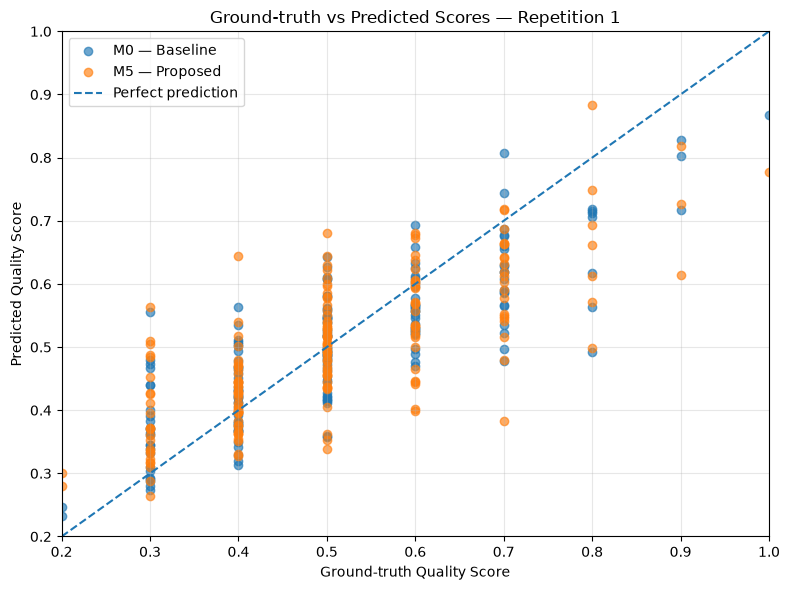

In [181]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

# Load actual test predictions
m0_df = pd.read_csv(RESULTS_DIR / "m0_rep01_test_predictions.csv")
m5_df = pd.read_csv(RESULTS_DIR / "m5_rep01_test_predictions.csv")

# Create the plot
plt.figure(figsize=(8, 6))

plt.scatter(
    m0_df["reference_score"],
    m0_df["predicted_score"],
    alpha=0.65,
    label="M0 — Baseline"
)

plt.scatter(
    m5_df["reference_score"],
    m5_df["predicted_score"],
    alpha=0.65,
    label="M5 — Proposed"
)

# Perfect-prediction line
plt.plot(
    [0.2, 1.0],
    [0.2, 1.0],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Ground-truth Quality Score")
plt.ylabel("Predicted Quality Score")
plt.title("Ground-truth vs Predicted Scores — Repetition 1")
plt.xlim(0.2, 1.0)
plt.ylim(0.2, 1.0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

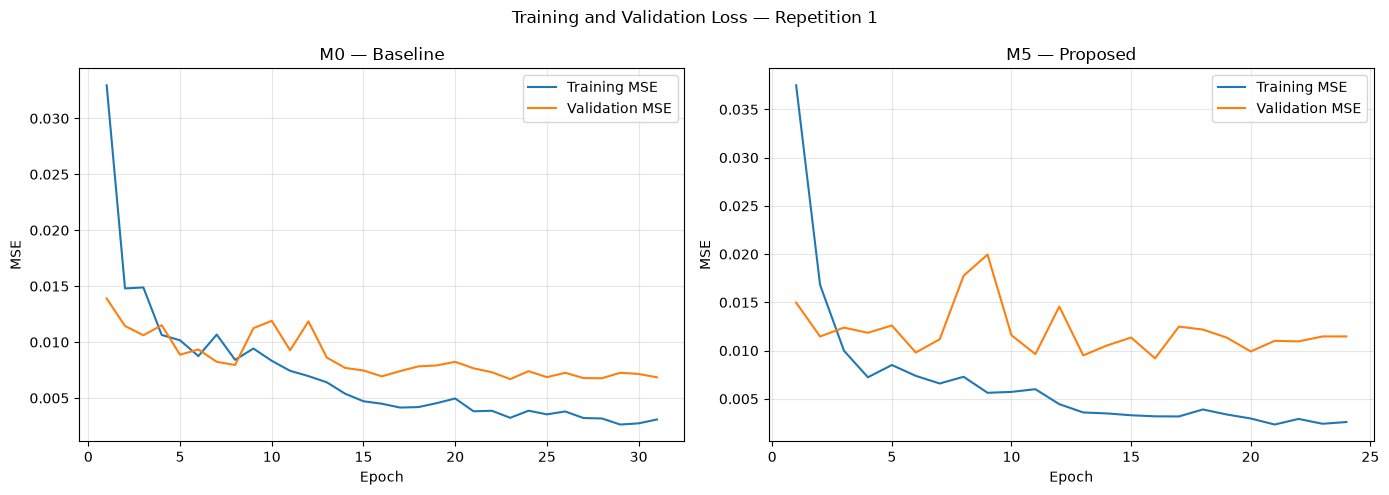

In [182]:
# Load training histories
m0_history = pd.read_csv(RESULTS_DIR / "m0_rep01_history.csv")
m5_history = pd.read_csv(RESULTS_DIR / "m5_rep01_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# M0
axes[0].plot(
    m0_history["epoch"],
    m0_history["train_mse"],
    label="Training MSE"
)

axes[0].plot(
    m0_history["epoch"],
    m0_history["val_mse"],
    label="Validation MSE"
)

axes[0].set_title("M0 — Baseline")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(alpha=0.3)

# M5
axes[1].plot(
    m5_history["epoch"],
    m5_history["train_mse"],
    label="Training MSE"
)

axes[1].plot(
    m5_history["epoch"],
    m5_history["val_mse"],
    label="Validation MSE"
)

axes[1].set_title("M5 — Proposed")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Training and Validation Loss — Repetition 1")
plt.tight_layout()
plt.show()

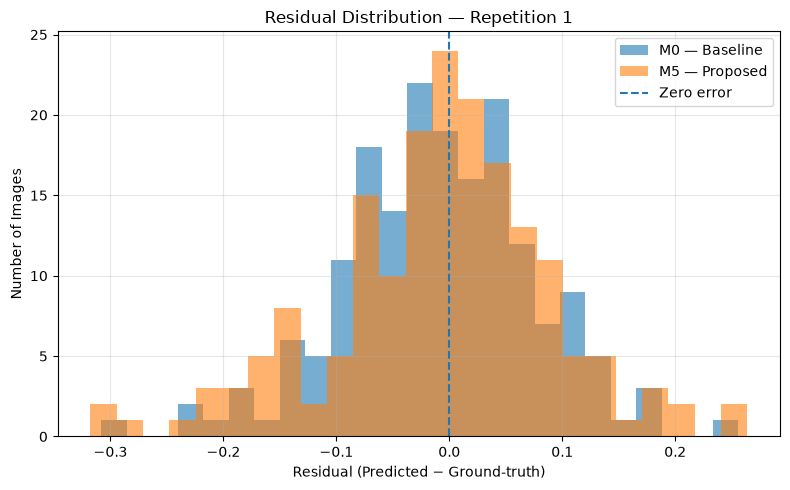

In [183]:
plt.figure(figsize=(8, 5))

plt.hist(
    m0_df["residual"],
    bins=25,
    alpha=0.6,
    label="M0 — Baseline"
)

plt.hist(
    m5_df["residual"],
    bins=25,
    alpha=0.6,
    label="M5 — Proposed"
)

plt.axvline(0, linestyle="--", label="Zero error")

plt.xlabel("Residual (Predicted − Ground-truth)")
plt.ylabel("Number of Images")
plt.title("Residual Distribution — Repetition 1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [184]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

# Load predictions from all 10 repetitions
m0_predictions = []
m5_predictions = []

for rep in range(1, 11):
    m0_path = RESULTS_DIR / f"m0_rep{rep:02d}_test_predictions.csv"
    m5_path = RESULTS_DIR / f"m5_rep{rep:02d}_test_predictions.csv"

    m0_df = pd.read_csv(m0_path)
    m5_df = pd.read_csv(m5_path)

    m0_df["repetition"] = rep
    m5_df["repetition"] = rep

    m0_predictions.append(m0_df)
    m5_predictions.append(m5_df)

m0_all = pd.concat(m0_predictions, ignore_index=True)
m5_all = pd.concat(m5_predictions, ignore_index=True)

print("M0 total test predictions:", len(m0_all))
print("M5 total test predictions:", len(m5_all))

FileNotFoundError: [Errno 2] No such file or directory: '/home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep02_test_predictions.csv'

In [185]:
from pathlib import Path

RESULTS_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

print("M0 prediction files:")
print(*sorted(
    p.name for p in RESULTS_DIR.glob("m0*test_predictions.csv")
), sep="\n")

print("\nM5 prediction files:")
print(*sorted(
    p.name for p in RESULTS_DIR.glob("m5*test_predictions.csv")
), sep="\n")

M0 prediction files:
m0_rep01_test_predictions.csv

M5 prediction files:
m5_rep01_test_predictions.csv


In [186]:
from pathlib import Path

ROOT_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments"
)

print("Searching for all M0 and M5 prediction CSVs...\n")

for path in sorted(ROOT_DIR.rglob("*test_predictions.csv")):
    if path.name.startswith(("m0_", "m5_")):
        print(path)

Searching for all M0 and M5 prediction CSVs...

/home/karthikbaskar2/UWIQA_Research_Experiments/results/m0_rep01_test_predictions.csv
/home/karthikbaskar2/UWIQA_Research_Experiments/results/m5_rep01_test_predictions.csv


In [187]:
from pathlib import Path

ROOT_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments"
)

print("M0 and M5 result files:\n")

for path in sorted(ROOT_DIR.rglob("*")):
    if path.is_file() and (
        path.name.startswith("m0_rep")
        or path.name.startswith("m5_rep")
    ):
        print(path.relative_to(ROOT_DIR))

M0 and M5 result files:

checkpoints/m0_rep01_best.pt
checkpoints/m0_rep02_best.pt
checkpoints/m0_rep03_best.pt
checkpoints/m0_rep04_best.pt
checkpoints/m0_rep05_best.pt
checkpoints/m0_rep06_best.pt
checkpoints/m0_rep07_best.pt
checkpoints/m0_rep08_best.pt
checkpoints/m0_rep09_best.pt
checkpoints/m0_rep10_best.pt
checkpoints/m5_rep01_best.pt
checkpoints/m5_rep02_best.pt
checkpoints/m5_rep03_best.pt
checkpoints/m5_rep04_best.pt
checkpoints/m5_rep05_best.pt
checkpoints/m5_rep06_best.pt
checkpoints/m5_rep07_best.pt
checkpoints/m5_rep08_best.pt
checkpoints/m5_rep09_best.pt
checkpoints/m5_rep10_best.pt
checkpoints_M4_M5_new_rep01_02/m5_rep01_best.pt
checkpoints_M4_M5_new_rep01_02/m5_rep02_best.pt
results/m0_rep01_history.csv
results/m0_rep01_test_metrics.csv
results/m0_rep01_test_predictions.csv
results/m0_rep02_actual_vs_predicted.png
results/m0_rep02_history.csv
results/m0_rep02_loss_curve.png
results/m0_rep02_metrics.csv
results/m0_rep02_predictions.csv
results/m0_rep02_scatter_plot.png


In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

def load_all_predictions(model_name):
    all_predictions = []

    for rep in range(1, 11):

        # Rep 1 has "_test_predictions.csv"
        if rep == 1:
            filename = f"{model_name}_rep01_test_predictions.csv"

        # Rep 2–10 have "_predictions.csv"
        else:
            filename = f"{model_name}_rep{rep:02d}_predictions.csv"

        filepath = RESULTS_DIR / filename

        if not filepath.exists():
            raise FileNotFoundError(
                f"Missing prediction file: {filepath}"
            )

        df = pd.read_csv(filepath)

        # Standardize image column
        if "filename" in df.columns:
            df = df.rename(columns={"filename": "image"})

        df["repetition"] = rep

        all_predictions.append(df)

    return pd.concat(all_predictions, ignore_index=True)


# Load all 10 repetitions
m0_all = load_all_predictions("m0")
m5_all = load_all_predictions("m5")

print("M0 predictions:", len(m0_all))
print("M5 predictions:", len(m5_all))

print("M0 repetitions:", sorted(m0_all["repetition"].unique()))
print("M5 repetitions:", sorted(m5_all["repetition"].unique()))

M0 predictions: 1780
M5 predictions: 1780
M0 repetitions: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
M5 repetitions: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


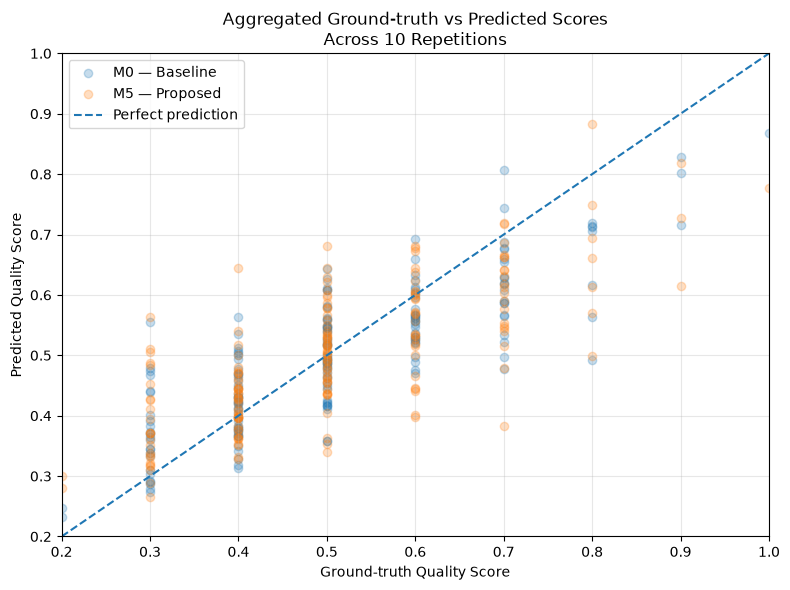

In [189]:
plt.figure(figsize=(8, 6))

plt.scatter(
    m0_all["reference_score"],
    m0_all["predicted_score"],
    alpha=0.25,
    label="M0 — Baseline"
)

plt.scatter(
    m5_all["reference_score"],
    m5_all["predicted_score"],
    alpha=0.25,
    label="M5 — Proposed"
)

# Perfect prediction line
plt.plot(
    [0.2, 1.0],
    [0.2, 1.0],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Ground-truth Quality Score")
plt.ylabel("Predicted Quality Score")

plt.title(
    "Aggregated Ground-truth vs Predicted Scores\n"
    "Across 10 Repetitions"
)

plt.xlim(0.2, 1.0)
plt.ylim(0.2, 1.0)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [190]:
def load_all_histories(model_name):
    all_histories = []

    for rep in range(1, 11):

        filename = f"{model_name}_rep{rep:02d}_history.csv"
        filepath = RESULTS_DIR / filename

        if not filepath.exists():
            raise FileNotFoundError(
                f"Missing history file: {filepath}"
            )

        df = pd.read_csv(filepath)

        df["repetition"] = rep

        all_histories.append(df)

    return pd.concat(all_histories, ignore_index=True)


m0_history_all = load_all_histories("m0")
m5_history_all = load_all_histories("m5")

In [191]:
m0_aggregate = (
    m0_history_all
    .groupby("epoch")[["train_mse", "val_mse"]]
    .agg(["mean", "std"])
)

m5_aggregate = (
    m5_history_all
    .groupby("epoch")[["train_mse", "val_mse"]]
    .agg(["mean", "std"])
)

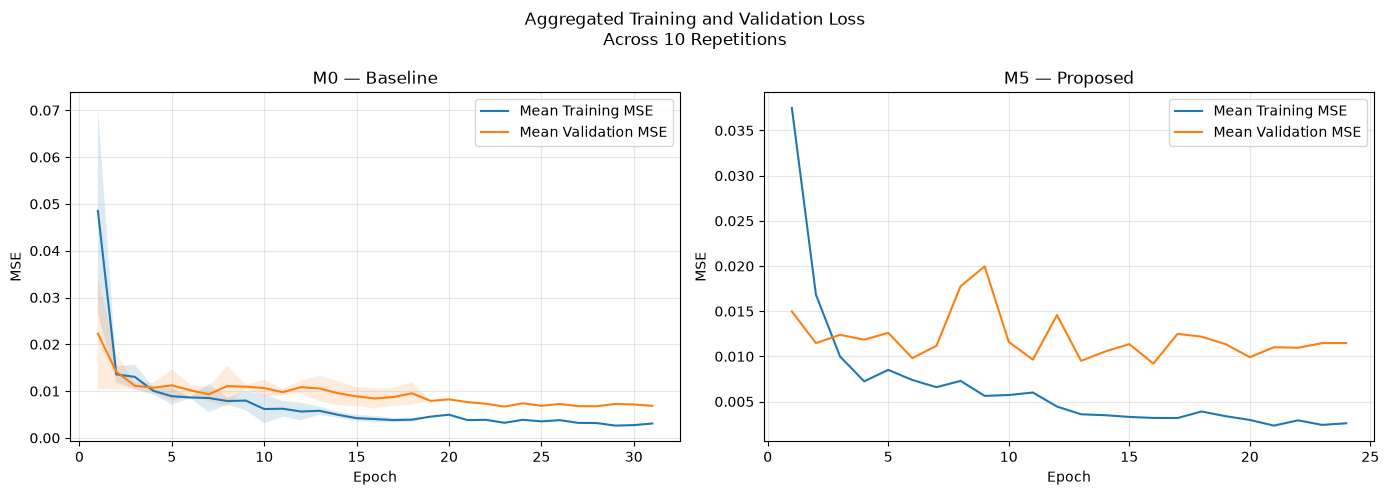

In [192]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# =========================
# M0 — Baseline
# =========================

epochs = m0_aggregate.index

train_mean = m0_aggregate[("train_mse", "mean")]
train_std = m0_aggregate[("train_mse", "std")].fillna(0)

val_mean = m0_aggregate[("val_mse", "mean")]
val_std = m0_aggregate[("val_mse", "std")].fillna(0)

axes[0].plot(
    epochs,
    train_mean,
    label="Mean Training MSE"
)

axes[0].plot(
    epochs,
    val_mean,
    label="Mean Validation MSE"
)

axes[0].fill_between(
    epochs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

axes[0].fill_between(
    epochs,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

axes[0].set_title("M0 — Baseline")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(alpha=0.3)


# =========================
# M5 — Proposed
# =========================

epochs = m5_aggregate.index

train_mean = m5_aggregate[("train_mse", "mean")]
train_std = m5_aggregate[("train_mse", "std")].fillna(0)

val_mean = m5_aggregate[("val_mse", "mean")]
val_std = m5_aggregate[("val_mse", "std")].fillna(0)

axes[1].plot(
    epochs,
    train_mean,
    label="Mean Training MSE"
)

axes[1].plot(
    epochs,
    val_mean,
    label="Mean Validation MSE"
)

axes[1].fill_between(
    epochs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

axes[1].fill_between(
    epochs,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

axes[1].set_title("M5 — Proposed")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Aggregated Training and Validation Loss\n"
    "Across 10 Repetitions"
)

plt.tight_layout()
plt.show()

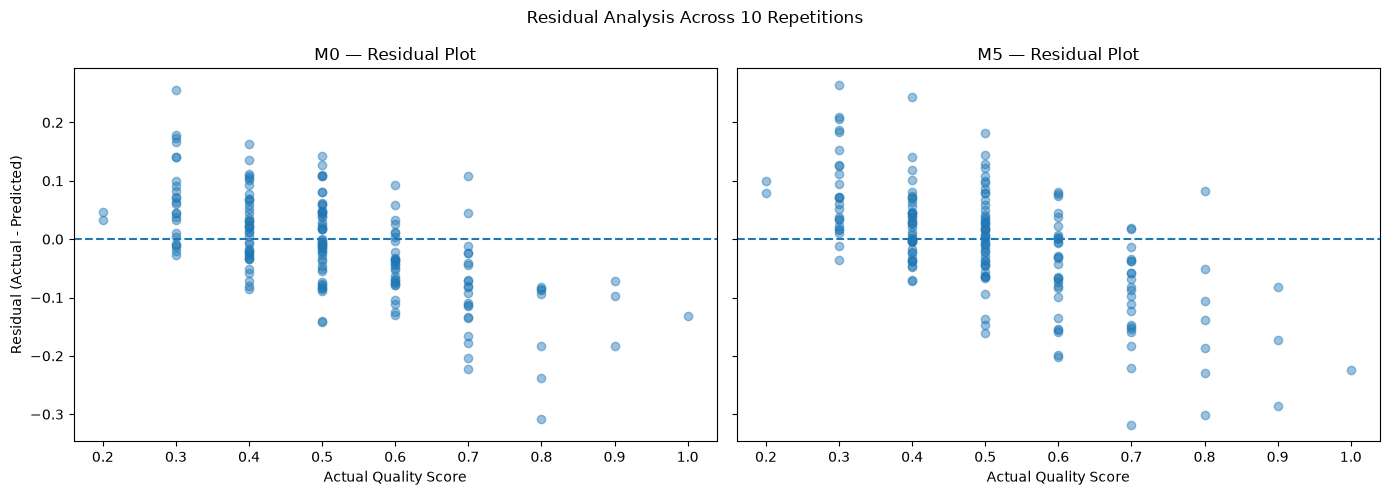

In [193]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# M0 — Baseline
axes[0].scatter(
    m0_all["reference_score"],
    m0_all["residual"],
    alpha=0.45
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("M0 — Residual Plot")
axes[0].set_xlabel("Actual Quality Score")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# M5 — Proposed Model
axes[1].scatter(
    m5_all["reference_score"],
    m5_all["residual"],
    alpha=0.45
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("M5 — Residual Plot")
axes[1].set_xlabel("Actual Quality Score")

plt.suptitle("Residual Analysis Across 10 Repetitions")
plt.tight_layout()
plt.show()

In [197]:
# --------------------------------------------------
# 2. Load prediction files from all 10 repetitions
# --------------------------------------------------

all_predictions = []

for rep in range(1, 11):

    if rep == 1:
        filename = f"m0_rep{rep:02d}_test_predictions.csv"
    else:
        filename = f"m0_rep{rep:02d}_predictions.csv"

    filepath = os.path.join(RESULTS_DIR, filename)

    if not os.path.exists(filepath):
        print(f"Missing file: {filepath}")
        continue

    df = pd.read_csv(filepath)

    # Normalize column names
    df.columns = df.columns.str.strip().str.lower()

    # Standardize columns across repetitions
    rename_map = {
        "image": "image",
        "filename": "image",
        "actual_score": "reference_score",
        "reference_score": "reference_score",
        "predicted_score": "predicted_score",
    }

    df = df.rename(columns=rename_map)

    required_columns = [
        "image",
        "reference_score",
        "predicted_score"
    ]

    missing_columns = [
        col for col in required_columns if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{filename} is missing columns: {missing_columns}. "
            f"Available columns: {df.columns.tolist()}"
        )

    # Ensure numerical values
    df["reference_score"] = pd.to_numeric(
        df["reference_score"], errors="raise"
    )

    df["predicted_score"] = pd.to_numeric(
        df["predicted_score"], errors="raise"
    )

    df["repetition"] = rep

    # Calculate residual consistently
    df["residual"] = (
        df["reference_score"] - df["predicted_score"]
    )

    df["absolute_residual"] = df["residual"].abs()

    all_predictions.append(df)

if not all_predictions:
    raise FileNotFoundError(
        "No M0 prediction files were loaded. Check RESULTS_DIR."
    )

m0_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

print("Total prediction rows:", len(m0_predictions))
print("Repetitions loaded:", sorted(m0_predictions["repetition"].unique()))

print("\nRows per repetition:")
print(m0_predictions.groupby("repetition").size())

Total prediction rows: 1780
Repetitions loaded: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Rows per repetition:
repetition
1     178
2     178
3     178
4     178
5     178
6     178
7     178
8     178
9     178
10    178
dtype: int64


In [195]:
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

filename = RESULTS_DIR / "m0_rep02_predictions.csv"

df = pd.read_csv(filename)

print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nShape:")
print(df.shape)

Columns:
['Image', 'Actual_Score', 'Predicted_Score']

First 5 rows:


,Image,Actual_Score,Predicted_Score
0,0002.png,0.5,0.469061
1,0006.png,0.6,0.495589
2,0013.png,0.6,0.471046
3,0036.png,0.3,0.331999
4,0038.png,0.4,0.401390



Shape:
(178, 3)


In [196]:
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path(
    "/home/karthikbaskar2/UWIQA_Research_Experiments/results"
)

def load_predictions(model, rep):
    # Repetition 1 uses a different filename
    if rep == 1:
        filename = RESULTS_DIR / f"{model}_rep01_test_predictions.csv"
    else:
        filename = RESULTS_DIR / f"{model}_rep{rep:02d}_predictions.csv"

    df = pd.read_csv(filename)

    # Standardize column names
    df.columns = df.columns.str.strip().str.lower()

    rename_map = {
        "image": "image",
        "filename": "image",
        "actual_score": "reference_score",
        "reference_score": "reference_score",
        "predicted_score": "predicted_score",
        "residual": "residual"
    }

    df = df.rename(columns=rename_map)

    # Check required columns
    required = ["image", "reference_score", "predicted_score"]

    missing = [col for col in required if col not in df.columns]

    if missing:
        raise ValueError(
            f"Missing columns {missing} in {filename.name}. "
            f"Available columns: {df.columns.tolist()}"
        )

    # Calculate residual consistently
    df["residual"] = (
        df["reference_score"] - df["predicted_score"]
    )

    df["repetition"] = rep
    df["model"] = model.upper()

    return df


# Load all 10 repetitions
m0_all = pd.concat(
    [load_predictions("m0", rep) for rep in range(1, 11)],
    ignore_index=True
)

m5_all = pd.concat(
    [load_predictions("m5", rep) for rep in range(1, 11)],
    ignore_index=True
)

print("M0 shape:", m0_all.shape)
print("M5 shape:", m5_all.shape)

display(m0_all.head())
display(m5_all.head())

M0 shape: (1780, 6)
M5 shape: (1780, 6)


,image,reference_score,predicted_score,residual,repetition,model
0,0003.png,0.5,0.448452,0.051548,1,M0
1,0008.png,0.5,0.497839,0.002161,1,M0
2,0014.png,0.5,0.466172,0.033828,1,M0
3,0020.png,0.5,0.410790,0.089210,1,M0
4,0021.png,0.7,0.478113,0.221887,1,M0


,image,reference_score,predicted_score,residual,repetition,model
0,0003.png,0.5,0.444505,0.055495,1,M5
1,0008.png,0.5,0.531601,-0.031601,1,M5
2,0014.png,0.5,0.567105,-0.067105,1,M5
3,0020.png,0.5,0.435507,0.064493,1,M5
4,0021.png,0.7,0.479027,0.220973,1,M5


Total predictions: 1780
Repetitions: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

========== M0: ACCURATE PREDICTIONS ==========


,image,reference_score,predicted_score,mean_absolute_residual,repetitions_evaluated
285,0320.png,0.5,0.499797,0.000203,1
183,0203.png,0.4,0.399671,0.000329,1
399,0448.png,0.4,0.399025,0.000975,1
35,0041.png,0.4,0.401056,0.001056,1
255,0286.png,0.6,0.601540,0.001540,1



========== M0: LARGEST PREDICTION ERRORS ==========


,image,reference_score,predicted_score,mean_absolute_residual,repetitions_evaluated
7,0010.png,0.8,0.444986,0.355014,1
535,0607.png,0.4,0.745136,0.345136,2
530,0601.png,0.7,0.359568,0.340432,2
405,0454.png,0.9,0.608348,0.291652,4
375,0420.png,0.8,0.510998,0.289002,4


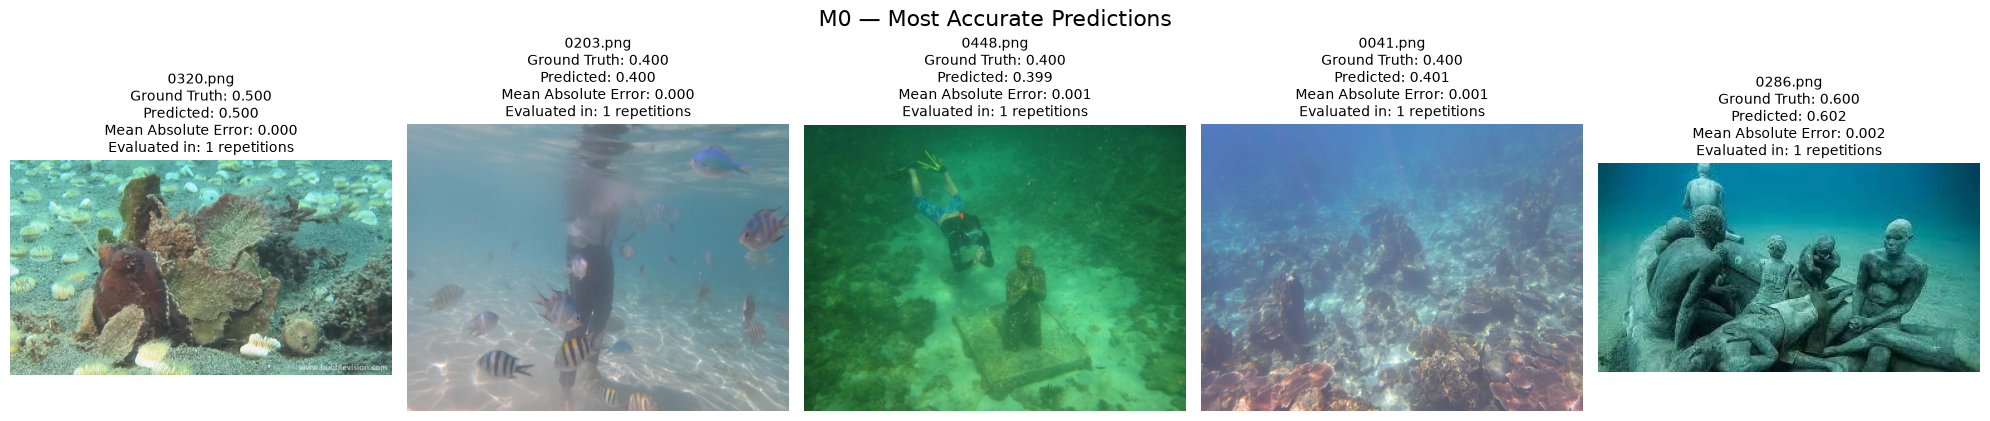

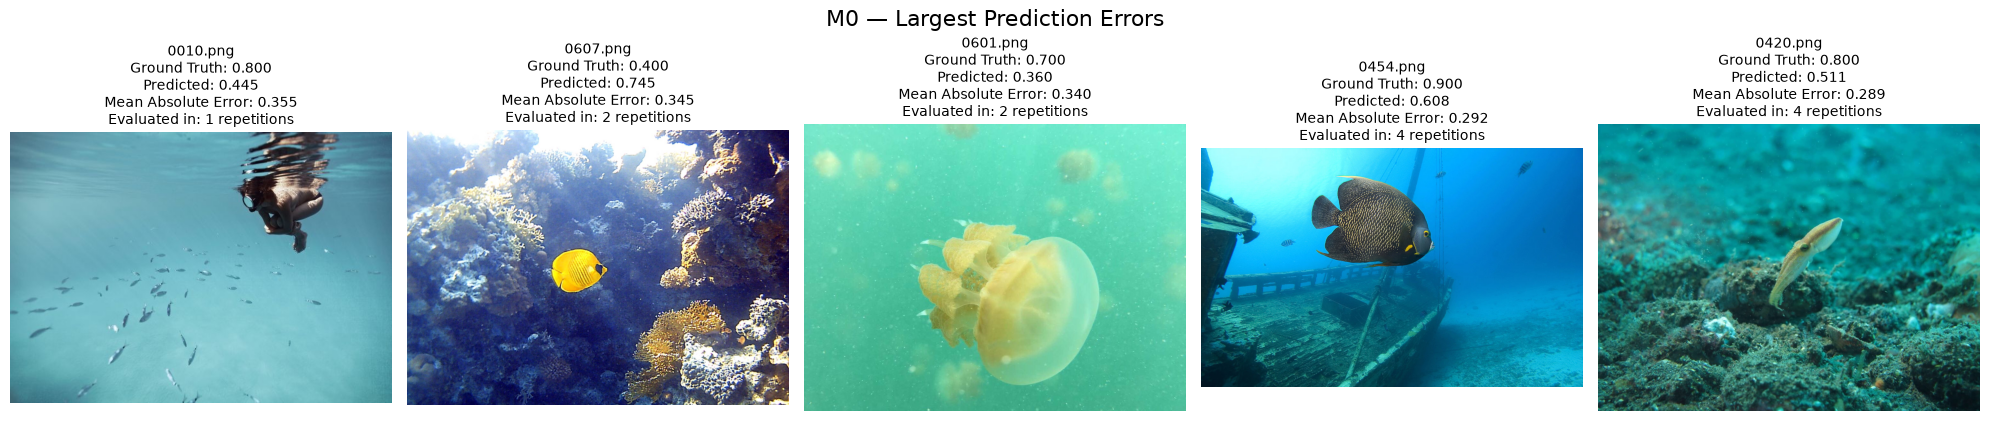


Success and failure cases saved.


In [198]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

RESULTS_DIR = (
    "/home/karthikbaskar2/"
    "UWIQA_Research_Experiments/results"
)

IMAGE_DIR = "/home/karthikbaskar2/UWIQA Dataset/UWIQA"

# --------------------------------------------------
# 2. Load M0 predictions from all 10 repetitions
# --------------------------------------------------

all_predictions = []

for rep in range(1, 11):

    if rep == 1:
        filename = f"m0_rep{rep:02d}_test_predictions.csv"
    else:
        filename = f"m0_rep{rep:02d}_predictions.csv"

    filepath = os.path.join(RESULTS_DIR, filename)

    if not os.path.exists(filepath):
        print(f"Missing file: {filename}")
        continue

    df = pd.read_csv(filepath)

    # Standardize column names
    df.columns = df.columns.str.strip().str.lower()

    rename_map = {
        "image": "image",
        "filename": "image",
        "actual_score": "reference_score",
        "reference_score": "reference_score",
        "predicted_score": "predicted_score"
    }

    df = df.rename(columns=rename_map)

    required_columns = [
        "image",
        "reference_score",
        "predicted_score"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{filename} is missing {missing_columns}. "
            f"Available columns: {df.columns.tolist()}"
        )

    # Calculate residual and absolute error
    df["residual"] = (
        df["reference_score"] - df["predicted_score"]
    )

    df["absolute_residual"] = df["residual"].abs()

    df["repetition"] = rep

    all_predictions.append(df)

# Combine all repetitions
m0_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

print("Total predictions:", len(m0_predictions))
print("Repetitions:", sorted(m0_predictions["repetition"].unique()))

# --------------------------------------------------
# 3. Aggregate predictions for each image
# --------------------------------------------------

image_summary = (
    m0_predictions
    .groupby("image", as_index=False)
    .agg(
        reference_score=("reference_score", "mean"),
        predicted_score=("predicted_score", "mean"),
        mean_absolute_residual=("absolute_residual", "mean"),
        mean_residual=("residual", "mean"),
        repetitions_evaluated=("repetition", "nunique")
    )
)

# --------------------------------------------------
# 4. Select accurate and inaccurate predictions
# --------------------------------------------------

# Smallest average absolute error
best_cases = (
    image_summary
    .sort_values("mean_absolute_residual", ascending=True)
    .head(5)
    .copy()
)

# Largest average absolute error
worst_cases = (
    image_summary
    .sort_values("mean_absolute_residual", ascending=False)
    .head(5)
    .copy()
)

print("\n========== M0: ACCURATE PREDICTIONS ==========")

display(
    best_cases[
        [
            "image",
            "reference_score",
            "predicted_score",
            "mean_absolute_residual",
            "repetitions_evaluated"
        ]
    ]
)

print("\n========== M0: LARGEST PREDICTION ERRORS ==========")

display(
    worst_cases[
        [
            "image",
            "reference_score",
            "predicted_score",
            "mean_absolute_residual",
            "repetitions_evaluated"
        ]
    ]
)

# --------------------------------------------------
# 5. Visualize the selected images
# --------------------------------------------------

def display_cases(cases, title):

    n = len(cases)

    fig, axes = plt.subplots(
        1,
        n,
        figsize=(4 * n, 5)
    )

    if n == 1:
        axes = [axes]

    fig.suptitle(title, fontsize=16)

    for ax, (_, row) in zip(axes, cases.iterrows()):

        image_name = str(row["image"])

        image_path = os.path.join(
            IMAGE_DIR,
            image_name
        )

        if not os.path.exists(image_path):

            ax.set_title(f"Image not found\n{image_name}")
            ax.axis("off")
            continue

        image = Image.open(image_path).convert("RGB")

        ax.imshow(image)
        ax.axis("off")

        ax.set_title(
            f"{image_name}\n"
            f"Ground Truth: {row['reference_score']:.3f}\n"
            f"Predicted: {row['predicted_score']:.3f}\n"
            f"Mean Absolute Error: "
            f"{row['mean_absolute_residual']:.3f}\n"
            f"Evaluated in: "
            f"{row['repetitions_evaluated']} repetitions",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 6. Display success cases
# --------------------------------------------------

display_cases(
    best_cases,
    "M0 — Most Accurate Predictions"
)

# --------------------------------------------------
# 7. Display failure cases
# --------------------------------------------------

display_cases(
    worst_cases,
    "M0 — Largest Prediction Errors"
)

# --------------------------------------------------
# 8. Save results
# --------------------------------------------------

best_cases.to_csv(
    os.path.join(RESULTS_DIR, "m0_best_prediction_cases.csv"),
    index=False
)

worst_cases.to_csv(
    os.path.join(RESULTS_DIR, "m0_largest_error_cases.csv"),
    index=False
)

print("\nSuccess and failure cases saved.")